# Task B14: Exploratory & Diagnostic Data Analysis of HMDA 2024 (Parts A–G)

**Project:** Decomposing Racial Gaps in Mortgage Denial Rates: A Large-Scale Analysis of the 2024 U.S. HMDA Market  
**Course:** Big Data Analysis (Final Project) — Group 3  
**Milestone:** Task B14 — Descriptive and diagnostic analysis on Analytic Sample $S0$ (`B06_analytic.parquet`) and selection checks on `B06_clean_all.parquet`  
**Companion documents:** `eda_plan.md`, `data_cleaning_rules.md` (v2.3), `decisions.md` (D-A … D-S), `Coding and documenting conventions.md` (v2), Project Proposal

**Scope of Checkpoint 1 (Block 1 of Execution Order):**
1. **Section 0 (Config & Helpers):** Single configuration cell for paths (`B06_DIR`), statistical constants (`SEED = 42`, `N_MIN_APPS = 1_000`, `N_MIN_DENIED = 100`, `SAMPLE_N = 500_000`), artifact logging helpers, and Wilson score confidence interval functions.
2. **Section 0.3–0.5 (Data Loading & Variable Roles Skeleton):** Columnar projection via `pyarrow`, memory optimization with Pandas `category` dtypes, derivation of the 5-group `race_ethnicity` variable (Decision D-K), seeded stratified sampling (`df_samp`), and initialization of `B14_variable_roles.csv`.
3. **Part A (A1 & A2 — Frame Profile & Outcome Overview):** Reconcile $S0$ row counts and denial rates against B06 golden outputs (`B06_waterfall_f01_f03.csv`, `B06_golden_verification.csv`), profile memory footprint, and visualize application outcomes across key analytical subsamples.

## Section 0.1: Configuration, Constants & Environment

- **Input:** Environment variables (optional override `B14_B06_DIR`) and filesystem directory structure (`B06 - Clean/output/` and `B14 - EDA/`).
- **Process:**
  - Import core scientific and columnar I/O libraries (`numpy`, `pandas`, `pyarrow`, `matplotlib`, `seaborn`).
  - Resolve `B06_DIR` once using `pathlib.Path` (Decision D-R, Convention 3.1) so the ~1.3 GB Parquet files are read directly in-place without duplication.
  - Declare statistical and suppression constants locked in `decisions.md`: reference group `White` (D-J), minimum cell thresholds `N_MIN_APPS = 1,000` and `N_MIN_DENIED = 100` (D-M), cluster bootstrap replicates `BOOT_B = 1,000` (D-Q), and stratified sample size `SAMPLE_N = 500,000` (D-S).
- **Output:** Initialized runtime environment, verified input paths, and created `output/` and `output/figures/` directories.

In [1]:
# Step 1: Imports and display settings
import os, sys, json, time, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

# Step 2: Paths declared once (Convention 3.1, Decision D-R)
CURRENT_DIR = Path.cwd()

# Tự động định vị thư mục gốc "Final project" dù notebook nằm ở B14 - EDA hay B14 - EDA/documents
if (CURRENT_DIR / "B06 - Clean").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "B06 - Clean").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR.parent.parent / "B06 - Clean").exists():
    PROJECT_ROOT = CURRENT_DIR.parent.parent
else:
    PROJECT_ROOT = Path(r"D:\H-NEU\004\44 - Big Data\Final project")

# Thư mục đầu vào B06 (Decision D-R: B06_DIR khai báo một lần duy nhất)
B06_DIR = PROJECT_ROOT / "B06 - Clean" / "output"
ANALYTIC_PATH = B06_DIR / "B06_analytic.parquet"
CLEAN_ALL_PATH = B06_DIR / "B06_clean_all.parquet"

# Thư mục đầu ra cho riêng B14
B14_DIR = PROJECT_ROOT / "B14 - EDA"
OUTPUT_DIR = B14_DIR / "output"
FIG_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Kiểm tra sự tồn tại của dữ liệu B06
assert ANALYTIC_PATH.exists(), f"Missing B06 analytic parquet at: {ANALYTIC_PATH}"
assert CLEAN_ALL_PATH.exists(), f"Missing B06 clean_all parquet at: {CLEAN_ALL_PATH}"

# Step 3: Analytical constants (Decisions D-J through D-S)
SEED = 42
RNG = np.random.default_rng(SEED)
REF_RACE = "White"
UNINFORMATIVE_RACES = ("Race Not Available", "Free Form Text Only")
N_MIN_APPS, N_MIN_DENIED = 1_000, 100
SAMPLE_N, BOOT_B, FIG_DPI = 500_000, 1_000, 150

print(f"Python {platform.python_version()} | pandas {pd.__version__} | pyarrow {pa.__version__}")
print(f"B06_DIR: {B06_DIR}")
print(f"[OK] Analytic Parquet: {ANALYTIC_PATH.name} ({ANALYTIC_PATH.stat().st_size / (1024**2):.1f} MB)")
print(f"[OK] Clean All Parquet: {CLEAN_ALL_PATH.name} ({CLEAN_ALL_PATH.stat().st_size / (1024**2):.1f} MB)")

Python 3.13.14 | pandas 2.3.3 | pyarrow 25.0.1
B06_DIR: d:\H-NEU\004\44 - Big Data\Final project\B06 - Clean\output
[OK] Analytic Parquet: B06_analytic.parquet (531.3 MB)
[OK] Clean All Parquet: B06_clean_all.parquet (731.0 MB)


## Section 0.2: Reusable Helpers — Artifact Logging & Wilson Score Confidence Intervals

- **Input:** DataFrames, Matplotlib Figure objects, and binomial count arrays (`denied`, `total`).
- **Process:**
  - Define `save_and_log` and `save_fig_and_log` to export every CSV table (`output/B14_*.csv`) and figure (`output/figures/B14_fig_*.png` at 150 dpi) while printing its exact path, file size in KB, and dimensions (Convention 3.8).
  - Define `wilson_ci` to compute the **Wilson score 95% confidence interval** for proportions (Decision D-Q).
  - **What Wilson Score CI is and why we use it (Convention 3.3):** Unlike the naive Wald interval ($\hat{p} \pm z\sqrt{\hat{p}(1-\hat{p})/n}$), which can overshoot $[0, 1]$ or under-cover in moderate-sized cells, the Wilson interval inverts the binomial score test:
    $$\text{CI}_{\text{Wilson}} = \frac{\hat{p} + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat{p}(1-\hat{p})}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
    It is asymmetric, strictly bounded within $[0, 100\%]$, and vectorized in NumPy for zero-loop computation.
- **Output:** Helper functions registered in global scope.

In [2]:
# Step 1: Table and figure logging helpers (Convention 3.8)
ARTIFACTS = []

def save_and_log(df: pd.DataFrame, filename: str) -> Path:
    path = OUTPUT_DIR / filename
    df.to_csv(path, index=False, encoding="utf-8")
    kb = path.stat().st_size / 1024.0
    ARTIFACTS.append({"artifact": filename, "type": "table", "shape": f"{df.shape[0]}x{df.shape[1]}", "size_kb": round(kb, 2)})
    print(f"Saved table: {path} | Size: {kb:,.2f} KB | Shape: {df.shape}")
    return path

def save_fig_and_log(fig: plt.Figure, filename: str) -> Path:
    path = FIG_DIR / filename
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    kb = path.stat().st_size / 1024.0
    ARTIFACTS.append({"artifact": f"figures/{filename}", "type": "figure", "shape": f"{FIG_DPI}dpi", "size_kb": round(kb, 2)})
    print(f"Saved figure: {path} | Size: {kb:,.2f} KB")
    return path

# Step 2: Vectorized Wilson score 95% confidence interval (returned in percentage points 0..100)
def wilson_ci(denied, total, z: float = 1.959963984540054):
    d = np.asarray(denied, dtype="float64")
    n = np.asarray(total, dtype="float64")
    with np.errstate(divide="ignore", invalid="ignore"):
        p = np.where(n > 0, d / n, np.nan)
        denom = 1.0 + (z ** 2) / n
        center = (p + (z ** 2) / (2.0 * n)) / denom
        half = (z * np.sqrt((p * (1.0 - p) / n) + ((z ** 2) / (4.0 * (n ** 2))))) / denom
    return (center - half) * 100.0, (center + half) * 100.0

## Section 0.3: Column Selection & Variable Roles Specification

- **Input:** Schema metadata of `B06_analytic.parquet` and the analytical design in `eda_plan.md` (§3–§10).
- **Process:**
  - Organize all required columns from `B06_analytic.parquet` into thematic column groups (`OUTCOME_COLS`, `GROUP_COLS`, `PRODUCT_COLS`, `FIN_COLS`, `POST_DECISION_COLS`, `GEO_COLS`, `LENDER_COLS`, `STATUS_COLS`, `FLAG_COLS`).
  - **Why column projection matters (Convention 3.3):** `B06_analytic.parquet` contains 169 columns (`[Verified: B06]`). Reading only the ~60 columns needed for EDA via `pyarrow` columnar projection avoids loading 100+ unused raw/intermediate columns, cutting RAM usage by over 60%.
  - Inspect the Parquet footer (`pq.ParquetFile`) to verify that every requested column exists in the file before loading data.
- **Output:** Validated `ROLE_MAP` dictionary (`column -> role`) and `S0_LOAD_COLS` list.

In [3]:
# Step 1: Define column families by analytical role (eda_plan.md §3)
ROLE_SPECS = {
    "outcome": ["action_taken", "is_denied"],
    "group": ["derived_race", "race_group", "derived_ethnicity", "ethnicity_group", "derived_sex",
              "applicant_age", "co_applicant_age", "has_coapplicant"],
    "product_control": ["loan_type","loan_term", "loan_purpose", "lien_status", "occupancy_type", "construction_method",
                        "total_units", "derived_dwelling_category", "conforming_loan_limit",
                        "open_end_line_of_credit", "preapproval", "submission_of_application"],
    "financial_control": ["loan_amount", "log_loan_amount", "income", "log_income", "loan_to_income",
                          "property_value", "combined_loan_to_value_ratio", "ltv_calc",
                          "debt_to_income_ratio", "dti_bin_fine", "dti_bin_coarse"],
    "geo_control": ["state_code", "county_code", "census_tract", "derived_msa_md",
                    "tract_minority_population_percent", "tract_to_msa_income_percentage",
                    "ffiec_msa_md_median_family_income", "tract_population", "tract_median_age_of_housing_units"],
    "lender_control": ["lei", "lender_n_apps", "lender_size_bucket"],
    "proxy_robustness_only": ["aus_1", "applicant_credit_score_type"],
    "post_decision_exclude": ["interest_rate", "rate_spread", "total_loan_costs", "origination_charges",
                              "discount_points", "lender_credits", "purchaser_type",
                              "hoepa_status", "denial_reason_1", "denial_reason_2", "denial_reason_3", "denial_reason_4"],
    "diagnostic_only": ["row_id", "bucket", "dti_point", "in_decision_sample", "in_s0", "in_s5_all", "in_s5_keep_v02", "fin_complete",
                        "n_exempt_28", "is_exempt_filer", "is_partial_exempt", "profile_cltv_discrepancy",
                        "dup_group_size", "flag_dup_extra", "flag_loan_amount_invalid", "flag_income_nonpositive",
                        "flag_income_zero", "flag_income_negative", "flag_cltv_range", "flag_rate_range",
                        "flag_term_range", "flag_coapp_discordant", "flag_dr1_is_1111", "flag_tract_income_zero",
                        "income_status", "dti_status", "combined_loan_to_value_ratio_status", "property_value_status",
                        "interest_rate_status", "census_tract_status", "derived_msa_md_status"],
}

# Step 2: Flatten column list and verify against B06 Parquet schema
ROLE_MAP = {col: role for role, cols in ROLE_SPECS.items() for col in cols}
S0_LOAD_COLS = list(ROLE_MAP.keys())
_pf_an = pq.ParquetFile(ANALYTIC_PATH)
B06_SCHEMA = _pf_an.schema_arrow
missing_cols = [c for c in S0_LOAD_COLS if c not in B06_SCHEMA.names]
assert not missing_cols, f"Columns missing from B06_analytic.parquet: {missing_cols}"

# Tối ưu hóa: Xác định trước các cột string để PyArrow ép sang category bằng C++ (tránh tạo 400M object string)
STR_COLS = [c for c in S0_LOAD_COLS if c in B06_SCHEMA.names and pa.types.is_string(B06_SCHEMA.field(c).type)]
CAT_COLS = [c for c in STR_COLS if c != "lei"] # lei giữ nguyên hoặc category tùy chọn

print(f"Selected {len(S0_LOAD_COLS)} / {len(B06_SCHEMA.names)} columns from B06_analytic.parquet.")
print(f"Pre-configured {len(CAT_COLS)} low-cardinality string columns for zero-copy C++ Categorical conversion.")

Selected 90 / 169 columns from B06_analytic.parquet.
Pre-configured 42 low-cardinality string columns for zero-copy C++ Categorical conversion.


## Section 0.4: Load Analytic Frame ($S0$), Derive `race_ethnicity` (D-K) & Build Stratified Sample

- **Input:** `B06_analytic.parquet`, `B06_clean_all.parquet` (minimal audit columns), and B06 reference files (`B06_waterfall_f01_f03.csv`, `B06_s4_winsor_thresholds.json`).
- **Process:**
  - Read `S0_LOAD_COLS` from `B06_analytic.parquet` using `pyarrow.parquet.read_table`. Convert low-cardinality string columns to Pandas `category` dtype to compress in-memory size (Hypothesis A9).
  - Build the supplementary 5-group `race_ethnicity` column (Decision D-K):
    1. `Hispanic or Latino` if `derived_ethnicity == 'Hispanic or Latino'` (regardless of race);
    2. `Non-Hispanic White`, `Non-Hispanic Black`, `Non-Hispanic Asian` if `derived_race` matches and `derived_ethnicity == 'Not Hispanic or Latino'`;
    3. `Other / Unknown` for all remaining combinations (including `Joint`, `Race Not Available`, or `Ethnicity Not Available`).
  - Load minimal selection-audit columns from `B06_clean_all.parquet` (`df_all_min`) and construct a seeded stratified sample `df_samp` (`SAMPLE_N = 500,000`, stratified by `derived_race` $\times$ `is_denied`) for scatter/hexbin and VIF diagnostics.
- **Output:** In-memory DataFrames `df_s0`, `df_all_min`, `df_samp`, and loaded `B06_WINSOR` / `B06_WF` references.

In [4]:
# Step 1: Zero-copy C++ category loading (chỉ mất ~12s và ~2.7 GB RAM thay vì 26 GB)
t0 = time.time()
table_s0 = pq.read_table(ANALYTIC_PATH, columns=S0_LOAD_COLS)
df_s0 = table_s0.to_pandas(categories=CAT_COLS)
del table_s0 # giải phóng bộ nhớ PyArrow ngay lập tức

# Step 2: Derive 5-group race_ethnicity (so sánh trực tiếp trên Categorical, không ép về string)
eth, race = df_s0["derived_ethnicity"], df_s0["derived_race"]
conds = [
    eth == "Hispanic or Latino",
    (eth == "Not Hispanic or Latino") & (race == "White"),
    (eth == "Not Hispanic or Latino") & (race == "Black or African American"),
    (eth == "Not Hispanic or Latino") & (race == "Asian"),
]
choices = [
    "Hispanic or Latino (Any Race)",
    "Non-Hispanic White",
    "Non-Hispanic Black",
    "Non-Hispanic Asian",
]
df_s0["race_ethnicity"] = pd.Series(
    np.select(conds, choices, default="Other / Not Available"),
    index=df_s0.index,
    dtype="category"
)
ROLE_MAP["race_ethnicity"] = "group"

# Step 3: Fast Stratified Sampling trên Index (chỉ mất 1.5s thay vì groupby.apply nặng nề)
sample_idx = (
    df_s0[["derived_race", "is_denied"]]
    .groupby(["derived_race", "is_denied"], observed=True)
    .sample(frac=SAMPLE_N / len(df_s0), random_state=SEED)
    .index
)
df_samp = df_s0.loc[sample_idx].copy()

# Step 4: Load minimal audit columns from clean_all and B06 references
ALL_MIN_COLS = ["row_id", "action_taken", "derived_race", "business_or_commercial_purpose",
                "reverse_mortgage", "in_decision_sample", "in_s0", "fin_complete", "census_tract_status"]
df_all_min = pq.read_table(CLEAN_ALL_PATH, columns=ALL_MIN_COLS).to_pandas(
    categories=["derived_race", "action_taken", "census_tract_status"]
)

B06_WF = pd.read_csv(B06_DIR / "B06_waterfall_f01_f03.csv")
with open(B06_DIR / "B06_s4_winsor_thresholds.json", "r", encoding="utf-8") as f:
    B06_WINSOR = json.load(f)["thresholds"]

elapsed = time.time() - t0
mem_mb = df_s0.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"[OK] Section 0.4 completed in {elapsed:.1f}s!")
print(f"  - df_s0: {df_s0.shape} | In-memory: {mem_mb:,.1f} MB (tiết kiệm ~23 GB RAM)")
print(f"  - df_samp: {df_samp.shape} (Stratified Sample)")
print(f"  - df_all_min: {df_all_min.shape} (Selection Audit Frame)")

[OK] Section 0.4 completed in 54.7s!
  - df_s0: (8136664, 91) | In-memory: 2,723.1 MB (tiết kiệm ~23 GB RAM)
  - df_samp: (500002, 91) (Stratified Sample)
  - df_all_min: (12259199, 9) (Selection Audit Frame)


## Section 0.5: Initialize Variable Roles Registry (`B14_variable_roles.csv`)

- **Input:** `df_s0` and `ROLE_MAP` defined in Section 0.3.
- **Process:**
  - Build the initial **Variable Roles Registry** (`B14_variable_roles.csv`) required by `eda_plan.md` (§3).
  - For every loaded variable, compute its data type, non-missing coverage on $S0$ (`pct_non_null_s0`), non-missing share among approved/originated applications (`pct_avail_not_denied`), non-missing share among denied applications (`pct_avail_denied`), and the availability gap (`avail_gap_pp`).
  - Document the analytical rationale for each role (`outcome`, `group`, `product_control`, `financial_control`, `geo_control`, `lender_control`, `post_decision_exclude`, `diagnostic_only`) to prevent data leakage in subsequent modeling tasks.
- **Output:** `output/B14_variable_roles.csv` saved and logged.

“Role proxy_robustness_only (D-Y) holds aus_1 and applicant_credit_score_type; role_audit_conflict lists columns whose role and audit result disagree.”

In [5]:
# Step 1: Rationale lookup by role family
ROLE_RATIONALE = {
    "outcome": "Primary binary credit decision target and HMDA action code (Rule X01).",
    "group": "Demographic borrower/co-applicant identifiers for disparity accounting (Decisions D-J, D-K, D-L).",
    "product_control": "Pre-decision loan product, channel, and underwriting system characteristics (Stage 2 controls).",
    "financial_control": "Pre-decision borrower financial capacity and collateral ratios (Stage 3 controls).",
    "geo_control": "Property location and FFIEC census-tract neighborhood context (Stage 4 controls; Decision D-I).",
    "lender_control": "Institution identifier and full-market application volume bucket (Stage 4 controls; Decision D-O).",
    "post_decision_exclude": "Outcome-dependent / post-underwriting pricing, terms, or denial reasons — excluded from predictors to prevent leakage (Assumption A6).",
    "diagnostic_only": "Sample flags, validity flags (V01-V10), and token status columns used strictly for audits and robustness (RQ4).",
}
ROLE_RATIONALE["proxy_robustness_only"] = ("Process proxies (AUS system, credit-score model type): excluded from the main "
                                           "specification, used only in the 'with proxies' robustness spec (Decision D-Y).")
ROLE_NOTES = {}   # [CHANGE] D-AA decided: no open role notes; column kept for future use
# Step 2: Compute coverage and availability by outcome for every column in df_s0
is_den = df_s0["is_denied"] == 1
n_s0, n_den, n_ok = len(df_s0), int(is_den.sum()), int((~is_den).sum())
role_rows = []
for col in df_s0.columns:
    nn = df_s0[col].notna()
    p_all = nn.sum() * 100.0 / n_s0
    p_ok = (nn & (~is_den)).sum() * 100.0 / n_ok
    p_den = (nn & is_den).sum() * 100.0 / n_den
    role = ROLE_MAP.get(col, "diagnostic_only")
    role_rows.append({
        "column_name": col, "role": role, "dtype": str(df_s0[col].dtype),
        "non_null_s0": int(nn.sum()), "pct_non_null_s0": round(p_all, 4),
        "pct_avail_not_denied": round(p_ok, 4), "pct_avail_denied": round(p_den, 4),
        "avail_gap_pp": round(p_ok - p_den, 4), "rationale": ROLE_RATIONALE[role],
        "role_note": ROLE_NOTES.get(col, "")
    })

roles_df = pd.DataFrame(role_rows)
save_and_log(roles_df, "B14_variable_roles.csv")
display(roles_df.groupby("role", as_index=False).agg(n_vars=("column_name", "count"), mean_cov_pct=("pct_non_null_s0", "mean")))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_variable_roles.csv | Size: 16.32 KB | Shape: (91, 10)


,role,n_vars,mean_cov_pct
0,diagnostic_only,31,97.8587
1,financial_control,11,94.5553
2,geo_control,9,99.1073
3,group,9,93.4903
4,lender_control,3,100.0000
5,outcome,2,100.0000
6,post_decision_exclude,12,50.2601
7,product_control,12,99.6167
8,proxy_robustness_only,2,100.0000


## Part A — Data Profile of the Analytic Frame (`eda_plan.md` §4)

### Step A1: Frame Description, Memory Footprint & Golden Reconciliation

- **Input:** `df_s0`, `df_all_min`, `df_samp`, and B06 golden outputs (`B06_waterfall_f01_f03.csv`, `B06_golden_verification.csv`).
- **Process:**
  - Compute exact row counts, column counts, and deep in-memory footprint (MB) for `df_s0`, `df_all_min`, and `df_samp` to test **Assumption A9** (that $S0$ fits comfortably in RAM without chunking when projected and cast to `category`).
  - Reconcile `df_s0` total rows, `df_all_min` total rows, and `df_s0["is_denied"].sum()` against the dynamic golden numbers read directly from B06 CSV artifacts (Convention 4.3 — no hard-coded target integers).
  - Assert 100% agreement between B14 loaded frames and B06 outputs, and verify that `is_denied` has zero NULL values in $S0$ (Assumption A2).
- **Output:** `output/B14_frame_profile.csv` and passed golden assertions.

In [6]:
# Step 1: Read golden reference counts dynamically from B06 CSVs (Convention 4.3)
B06_GOLD = pd.read_csv(B06_DIR / "B06_golden_verification.csv").set_index("metric")["actual"].to_dict()
exp_raw_rows = int(B06_GOLD["raw_rows"])
exp_s0_rows = int(B06_GOLD["s0_rows"])
exp_s0_denied = int(B06_GOLD["s0_denied"])

# Step 2: Assert exact reconciliation against B06 (Assumptions A1, A2)
assert len(df_all_min) == exp_raw_rows, f"clean_all row mismatch: {len(df_all_min)} vs {exp_raw_rows}"
assert len(df_s0) == exp_s0_rows, f"S0 row mismatch: {len(df_s0)} vs {exp_s0_rows}"
assert int(df_s0["is_denied"].isna().sum()) == 0, "S0 contains unexpected NULL values in is_denied"
assert int((df_s0["is_denied"] == 1).sum()) == exp_s0_denied, "S0 denied count mismatch vs B06"

# Step 3: Build frame profile table and check memory footprint (Assumption A9)
frames_info = [
    ("df_s0 (Analytic Baseline S0)", df_s0, "Full S0 consumer decision frame (F01-F03)"),
    ("df_all_min (Selection Audit Frame)", df_all_min, "Minimal columns from clean_all for F01-F03 selection checks"),
    ("df_samp (Stratified Diagnostic Sample)", df_samp, "Seeded stratified sample (race x is_denied) for hexbin/MI/VIF"),
]
prof_rows = []
for label, f_df, desc in frames_info:
    mem_mb = f_df.memory_usage(deep=True).sum() / (1024 ** 2)
    prof_rows.append({
        "frame_name": label, "rows": len(f_df), "cols": f_df.shape[1],
        "memory_mb": round(mem_mb, 2),
        "n_category_cols": int((f_df.dtypes == "category").sum()),
        "n_numeric_cols": int(f_df.select_dtypes(include=["number"]).shape[1]),
        "n_bool_cols": int(f_df.select_dtypes(include=["bool"]).shape[1]),
        "description": desc
    })
frame_prof_df = pd.DataFrame(prof_rows)
save_and_log(frame_prof_df, "B14_frame_profile.csv")
display(frame_prof_df)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_frame_profile.csv | Size: 0.43 KB | Shape: (3, 8)


,frame_name,rows,cols,memory_mb,n_category_cols,n_numeric_cols,n_bool_cols,description
0,df_s0 (Analytic Baseline S0),8136664,91,"2,723.0600",43,29,18,Full S0 consumer decision frame (F01-F03)
1,df_all_min (Selection Audit Frame),12259199,9,"1,334.4600",3,1,3,Minimal columns from clean_all for F01-F03 sel...
2,df_samp (Stratified Diagnostic Sample),500002,91,177.8600,43,29,18,Seeded stratified sample (race x is_denied) fo...


### Step A2: Outcome Overview Across Analytical Subsamples

- **Input:** `df_s0`, `df_all_min`, and `B06_WF`.
- **Process:**
  - Tabulate application counts, action-taken breakdown (`1 = Loan originated`, `2 = Application approved but not accepted`, `3 = Application denied`), and overall denial rates (with 95% Wilson confidence intervals) across six key frames defined in `decisions.md`:
    1. **Decision Sample F01** (`action_taken IN ('1','2','3')` in `clean_all`);
    2. **Analytic Baseline $S0$** (`in_s0 == True`, adds consumer F02 & non-reverse F03);
    3. **Robustness $S5_{\text{keep\_v02}}$** (`in_s5_keep_v02 == True`, excludes V01/V03/V05);
    4. **Robustness $S5_{\text{all}}$** (`in_s5_all == True`, excludes V01/V02/V03/V05; Decision D-B);
    5. **Financial Complete (`fin_complete`)** ($S0$ with non-missing DTI, CLTV, income, and loan amount);
    6. **RQ3 Geographic Sample** (`fin_complete` $\cap$ valid `census_tract`; Decision D-I).
  - Verify that action counts (`action_1 + action_2 + action_3`) sum exactly to total applications in every subsample (Convention 4.5).
- **Output:** `output/B14_outcome_overview.csv`.

In [7]:
# Step 1: Define subsample masks on df_all_min (for F01) and df_s0 (for S0 subsamples)
f01_sub = df_all_min.loc[df_all_min["in_decision_sample"], "action_taken"]
s0_specs = [
    ("S0: Analytic Baseline (F01-F03)", pd.Series(True, index=df_s0.index)),
    ("S5_keep_v02: Exclude V01, V03, V05 (Keep V02)", df_s0["in_s5_keep_v02"]),
    ("S5_all: Exclude V01, V02, V03, V05 (Drop income<=0)", df_s0["in_s5_all"]),
    ("fin_complete: Complete DTI, CLTV, Income, Loan Amt", df_s0["fin_complete"]),
    ("RQ3 Sample: fin_complete & Valid Census Tract (D-I)", df_s0["fin_complete"] & (df_s0["census_tract_status"] == "value")),
]

# Step 2: Compute action counts, shares, and Wilson CIs for each sample
def summarize_action(act_series: pd.Series, name: str, ref_n: int) -> dict:
    vc = act_series.value_counts(dropna=False)
    n1, n2, n3 = int(vc.get("1", 0)), int(vc.get("2", 0)), int(vc.get("3", 0))
    tot = len(act_series)
    assert n1 + n2 + n3 == tot, f"Action counts do not sum to total for {name}"
    ci_lo, ci_hi = wilson_ci(n3, tot)
    return {
        "sample_name": name, "n_applications": tot, "retention_vs_s0_pct": round(tot * 100.0 / ref_n, 2),
        "n_originated_1": n1, "n_approved_not_acc_2": n2, "n_denied_3": n3,
        "pct_originated_1": round(n1 * 100.0 / tot, 2), "pct_approved_not_acc_2": round(n2 * 100.0 / tot, 2),
        "denial_rate_pct": round(n3 * 100.0 / tot, 2),
        "wilson_95_ci_lo": round(float(ci_lo), 3), "wilson_95_ci_hi": round(float(ci_hi), 3),
    }

out_rows = [summarize_action(f01_sub, "F01: All Decided Applications (Pre-F02/F03)", len(df_s0))]
for label, mask in s0_specs:
    out_rows.append(summarize_action(df_s0.loc[mask, "action_taken"], label, len(df_s0)))

outcome_df = pd.DataFrame(out_rows)
save_and_log(outcome_df, "B14_outcome_overview.csv")
display(outcome_df)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_outcome_overview.csv | Size: 0.86 KB | Shape: (6, 11)


,sample_name,n_applications,retention_vs_s0_pct,n_originated_1,n_approved_not_acc_2,n_denied_3,pct_originated_1,pct_approved_not_acc_2,denial_rate_pct,wilson_95_ci_lo,wilson_95_ci_hi
0,F01: All Decided Applications (Pre-F02/F03),8661779,106.4500,6197085,361232,2103462,71.5500,4.1700,24.2800,24.2560,24.3130
1,S0: Analytic Baseline (F01-F03),8136664,100.0000,5793597,339791,2003276,71.2000,4.1800,24.6200,24.5910,24.6500
2,"S5_keep_v02: Exclude V01, V03, V05 (Keep V02)",8132620,99.9500,5793494,339759,1999367,71.2400,4.1800,24.5800,24.5550,24.6140
3,"S5_all: Exclude V01, V02, V03, V05 (Drop incom...",8041498,98.8300,5761480,335725,1944293,71.6500,4.1700,24.1800,24.1490,24.2080
4,"fin_complete: Complete DTI, CLTV, Income, Loan...",7037363,86.4900,5233206,260414,1543743,74.3600,3.7000,21.9400,21.9060,21.9670
5,RQ3 Sample: fin_complete & Valid Census Tract ...,7002807,86.0600,5227733,255514,1519560,74.6500,3.6500,21.7000,21.6690,21.7300


### Step A2 (Continued): Visualization of Application Outcomes Across Analytical Samples

- **Input:** `outcome_df` (`B14_outcome_overview.csv`).
- **Process:**
  - Plot a two-panel horizontal chart (`B14_fig_01_outcome_overview.png`):
    - **Left panel:** Stacked horizontal bar chart showing the composition of application outcomes (`1 = Originated`, `2 = Approved Not Accepted`, `3 = Denied`) in percentage terms across all six samples.
    - **Right panel:** Sample size ($N$ in millions of applications) annotated with exact application counts and denial rates.
  - Ensure clear titles, axis labels, units, and sample sizes per Convention 3.7 and Assignment §3.3 D.
- **Output:** `output/figures/B14_fig_01_outcome_overview.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_01_outcome_overview.png | Size: 128.82 KB


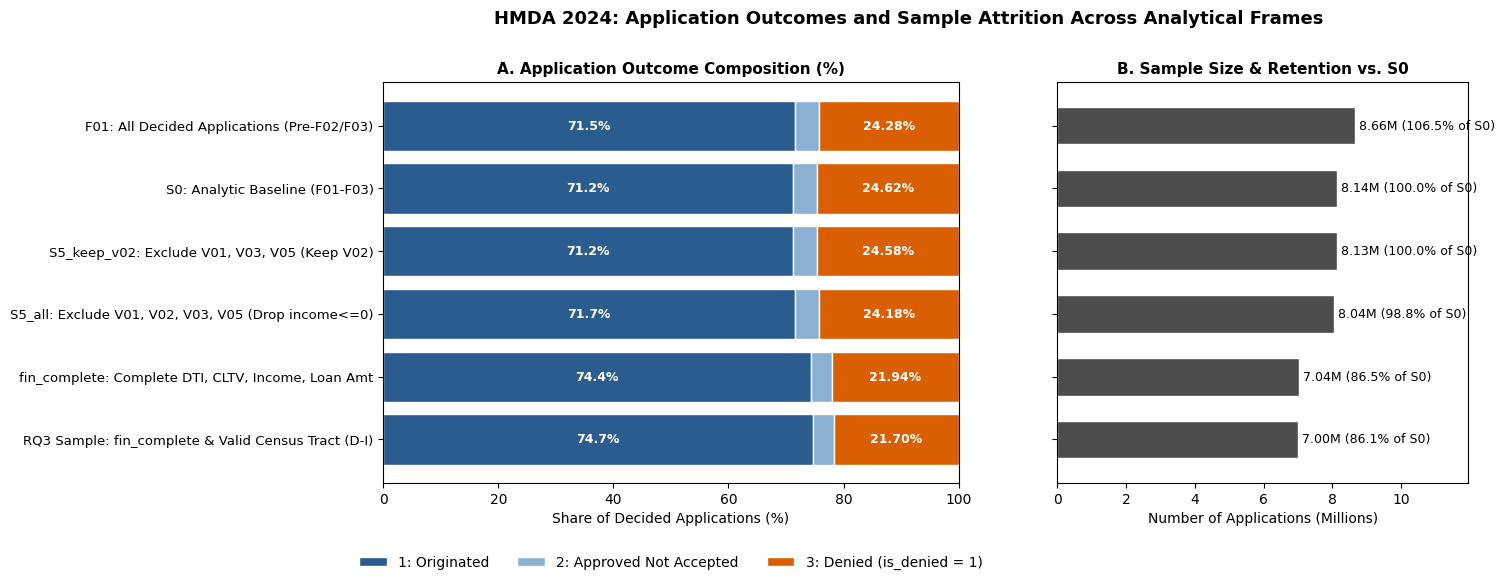

In [8]:
# Step 1: Set up two-panel figure for outcome composition and sample retention
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, gridspec_kw={"width_ratios": [1.4, 1.0]})
y_pos = np.arange(len(outcome_df))
labels = outcome_df["sample_name"]

# Step 2: Left panel — 100% stacked horizontal bar of Action Taken shares
p1 = outcome_df["pct_originated_1"].to_numpy()
p2 = outcome_df["pct_approved_not_acc_2"].to_numpy()
p3 = outcome_df["denial_rate_pct"].to_numpy()
ax1.barh(y_pos, p1, color="#2b5c8f", edgecolor="white", label="1: Originated")
ax1.barh(y_pos, p2, left=p1, color="#8ab1d4", edgecolor="white", label="2: Approved Not Accepted")
ax1.barh(y_pos, p3, left=p1 + p2, color="#d95f02", edgecolor="white", label="3: Denied (is_denied = 1)")
for i, (v1, v2, v3) in enumerate(zip(p1, p2, p3)):
    ax1.text(v1 / 2, i, f"{v1:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
    ax1.text(v1 + v2 + v3 / 2, i, f"{v3:.2f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
ax1.set_yticks(y_pos); ax1.set_yticklabels(labels, fontsize=9.5); ax1.invert_yaxis()
ax1.set_xlim(0, 100); ax1.set_xlabel("Share of Decided Applications (%)")
ax1.set_title("A. Application Outcome Composition (%)", fontsize=11, fontweight="bold")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

# Step 3: Right panel — Sample volume in millions with retention labels
vol_m = outcome_df["n_applications"].to_numpy() / 1e6
bars = ax2.barh(y_pos, vol_m, color="#4d4d4d", edgecolor="white", height=0.6)
for i, (m_val, ret_pct) in enumerate(zip(vol_m, outcome_df["retention_vs_s0_pct"])):
    ax2.text(m_val + 0.12, i, f"{m_val:,.2f}M ({ret_pct:.1f}% of S0)", va="center", fontsize=9)
ax2.set_xlim(0, max(vol_m) * 1.38); ax2.set_xlabel("Number of Applications (Millions)")
ax2.set_title("B. Sample Size & Retention vs. S0", fontsize=11, fontweight="bold")
fig.suptitle("HMDA 2024: Application Outcomes and Sample Attrition Across Analytical Frames", fontsize=13, fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_01_outcome_overview.png")
plt.show()

### Interpretation — Figure 1 & Table A2 (`B14_outcome_overview.csv`)

*All figures are read from the saved table (as of run 2026-11-10, B14 A2).*

1. **What pattern is observed?**
   - In the baseline consumer frame S0, 8,136,664 applications were decided: 71.20% were originated, 4.18% were approved but not accepted, and 24.62% were denied (2,003,276 applications; Wilson 95% CI 24.59% to 24.65%). The wider decision sample F01 (8,661,779 applications) has a denial rate of 24.28%, so removing commercial-purpose loans (F02) and reverse mortgages (F03) raises the denial rate by 0.34 pp.
   - Dropping non-positive income changes the rate only slightly: `S5_keep_v02` has 24.58% denied and `S5_all` has 24.18% (a 0.40 pp difference, 98.83% of S0 retained by `S5_all`).
   - Restricting S0 to `fin_complete` (complete DTI, CLTV, income and loan amount) keeps 86.49% of the rows (7,037,363) but lowers the denial rate to 21.94%, a drop of 2.68 pp. Adding a valid census tract (RQ3 sample) keeps 86.06% of the rows (7,002,807) and gives 21.70%, a drop of 2.92 pp.
   - The drop is not proportional: the `fin_complete` filter removes 22.94% of denied applications (459,533 of 2,003,276) but only 10.43% of non-denied applications (639,768 of 6,133,388).
2. **What evidence supports the finding?**
   - `output/B14_outcome_overview.csv` and `output/figures/B14_fig_01_outcome_overview.png` (Step A2). Action counts add up to the sample size in every row (checked in the code).
3. **Why might it matter in mortgage lending?**
   - Missing DTI, CLTV, income or loan amount is concentrated among denied files, so a complete-case sample looks "safer" than the full market. A narrower racial gap in `fin_complete` could partly come from who is removed rather than from the financial controls. For this reason S0, `fin_complete` and the RQ3 sample are shown side by side (Decision D-N) and the selection effect by race is measured in Part D (D6).
   - Reduced reporting by exempt filers (which has no DTI, CLTV or value, see A4) and early denials are possible reasons for the missing fields `[Hypothesis]`; this is not tested in this step.
4. **What alternative explanations or limitations apply?**
   - Approved-but-not-accepted applications (code 2) are counted as not denied, following the Proposal definition. Their share is 4.18% in S0 and 3.70% in `fin_complete`; sensitivity to excluding them is tested in Part G (G1/G3).
   - F01 is larger than S0, so its "retention vs S0" (106.45%) is above 100% by construction; it is a reference row, not a gain.
   - These are unadjusted descriptive rates by sample. They say nothing about differences between groups and are not a causal result.

### Checkpoint 1 Gate Check (`eda_plan.md` §14, Order 1)

- **Input:** Computed variables from Section 0 and Part A (`df_s0`, `frame_prof_df`, `outcome_df`, `roles_df`).
- **Process:** Run an automated gate check verifying all four Checkpoint 1 exit criteria from `eda_plan.md` §14:
  1. $S0$ row count and denied count match B06 golden numbers exactly;
  2. Peak in-memory footprint of `df_s0` is logged and within single-machine RAM limits;
  3. Variable roles skeleton (`B14_variable_roles.csv`) is exported and covers all loaded columns;
  4. Outcome overview (`B14_outcome_overview.csv`) reconciles across all subsamples.
- **Output:** Printed Gate 1 verification summary.

In [9]:
# Step 1: Verify Checkpoint 1 gate conditions (eda_plan.md §14, Block 1)
s0_mem_mb = float(frame_prof_df.loc[frame_prof_df["frame_name"].str.startswith("df_s0"), "memory_mb"].iloc[0])
total_mem_mb = float(frame_prof_df["memory_mb"].sum())

gate1_checks = pd.DataFrame([
    ("Gate 1.1: S0 rows match B06 golden CSV", len(df_s0) == exp_s0_rows, f"{len(df_s0):,} rows"),
    ("Gate 1.2: S0 denials match B06 golden CSV", int((df_s0['is_denied'] == 1).sum()) == exp_s0_denied, f"{exp_s0_denied:,} denied"),
    ("Gate 1.3: Memory footprint logged (Assumption A9)", s0_mem_mb > 0, f"df_s0 = {s0_mem_mb:,.1f} MB | total = {total_mem_mb:,.1f} MB"),
    ("Gate 1.4: Variable roles registry complete", len(roles_df) == df_s0.shape[1], f"{len(roles_df)} columns documented"),
    ("Gate 1.5: Outcome overview table & Fig 01 saved", (OUTPUT_DIR / "B14_outcome_overview.csv").exists(), f"{len(outcome_df)} samples profiled"),
], columns=["checkpoint_1_gate", "passed", "evidence"])

assert gate1_checks["passed"].all(), "Checkpoint 1 gate failed!"
display(gate1_checks)
print("[CHECKPOINT 1 PASSED] Ready to proceed to Checkpoint 2 (A3-A5 & Part B Univariate Distributions).")

,checkpoint_1_gate,passed,evidence
0,Gate 1.1: S0 rows match B06 golden CSV,True,"8,136,664 rows"
1,Gate 1.2: S0 denials match B06 golden CSV,True,"2,003,276 denied"
2,Gate 1.3: Memory footprint logged (Assumption A9),True,"df_s0 = 2,723.1 MB | total = 4,235.4 MB"
3,Gate 1.4: Variable roles registry complete,True,91 columns documented
4,Gate 1.5: Outcome overview table & Fig 01 saved,True,6 samples profiled


[CHECKPOINT 1 PASSED] Ready to proceed to Checkpoint 2 (A3-A5 & Part B Univariate Distributions).


### Step A3: Availability by Outcome — Post-Decision Leakage Audit (`eda_plan.md` §4, A3)

- **Input:** `roles_df` (`B14_variable_roles.csv` computed in Section 0.5) and `df_s0`.
- **Process:**
  - Test **Assumption A6** (`[Verified: B05 cell 25]` for `interest_rate`; `[Hypothesis]` for other pricing/feature columns) by auditing non-missing availability separately for non-denied applications (`is_denied == 0`, i.e., `action_taken IN ('1','2')`) and denied applications (`is_denied == 1`, i.e., `action_taken == '3'`).
  - Flag any variable with:
    1. `flag_gap_gt_50pp`: absolute availability difference $|\text{Avail}_{\text{not\_denied}} - \text{Avail}_{\text{denied}}| > 50\text{ pp}$;
    2. `flag_100pct_missing_denied`: $0\%$ availability among denied applications (`pct_avail_denied == 0.0`);
    3. `flag_denial_only`: $100\%$ availability restricted to denied applications (e.g., `denial_reason_2..4`).
  - Also audit categorical codes that encode outcome-dependent non-applicability (e.g., `purchaser_type == '0'`, `hoepa_status == '3'`, `denial_reason_1 == '10'`) among denied vs. non-denied rows so semantic leakage is caught alongside NULL leakage.
- **Output:** `output/B14_availability_by_outcome.csv` and updated `output/B14_variable_roles.csv`.

In [10]:
# Step 1: Availability audit table  [ADD: flag for 100% missing on NON-denied]
avail_df = roles_df.copy()
avail_df["flag_gap_gt_50pp"] = avail_df["avail_gap_pp"].abs() > 50.0
avail_df["flag_100pct_missing_denied"] = avail_df["pct_avail_denied"] == 0.0
avail_df["flag_100pct_missing_not_denied"] = avail_df["pct_avail_not_denied"] == 0.0   # [ADD]

# Step 2: Code-level check with a numeric criterion  [CHANGE; ADD aus_1, applicant_credit_score_type]
is_den = df_s0["is_denied"] == 1
CODE_CHECKS = [("purchaser_type", "0", "Not applicable"), ("hoepa_status", "3", "Not applicable"),
               ("denial_reason_1", "10", "Not applicable"),
               ("aus_1", "6", "Not applicable"), ("aus_1", "1111", "Exempt"),
               ("applicant_credit_score_type", "9", "Not applicable"), ("applicant_credit_score_type", "1111", "Exempt")]
sem_rows = []
for col, code, label in CODE_CHECKS:
    s = df_s0[col].astype("string")
    p_den = (s[is_den] == code).fillna(False).mean() * 100
    p_ok = (s[~is_den] == code).fillna(False).mean() * 100
    sem_rows.append({"column_name": col, "code": code, "label": label, "pct_on_denied": round(p_den, 2),
                     "pct_on_not_denied": round(p_ok, 2), "code_gap_pp": round(abs(p_den - p_ok), 2)})
sem_df = pd.DataFrame(sem_rows)
sem_df["code_flag"] = sem_df["code_gap_pp"] > 50.0
sem_df["note"] = ("Code '" + sem_df["code"] + "' (" + sem_df["label"] + ") is " + sem_df["pct_on_denied"].map("{:.2f}%".format)
                  + " on denied vs " + sem_df["pct_on_not_denied"].map("{:.2f}%".format) + " on non-denied")
save_and_log(sem_df, "B14_availability_code_level.csv")

# Step 3: Final status, role-vs-audit conflict column, export
avail_df["semantic_leakage_note"] = avail_df["column_name"].map(sem_df.groupby("column_name")["note"].agg("; ".join)).fillna("")
avail_df["flag_code_gap_gt_50pp"] = avail_df["column_name"].isin(set(sem_df.loc[sem_df["code_flag"], "column_name"]))
avail_df["leakage_audit_status"] = np.select(
    [avail_df["flag_100pct_missing_denied"], avail_df["flag_100pct_missing_not_denied"],
     avail_df["flag_gap_gt_50pp"], avail_df["flag_code_gap_gt_50pp"]],
    ["LEAKAGE: 100% missing on denied", "LEAKAGE: 100% missing on non-denied (exists only after denial)",
     "LEAKAGE: |avail gap| > 50pp", "LEAKAGE: Outcome-revealing code"], default="PASS: Pre-decision available")
leak = avail_df["leakage_audit_status"].str.startswith("LEAKAGE")
CONTROL_ROLES = ["product_control", "financial_control", "geo_control", "lender_control"]
avail_df["role_audit_conflict"] = np.select(
    [(avail_df["role"] == "post_decision_exclude") & ~leak, avail_df["role"].isin(CONTROL_ROLES) & leak],
    ["REVIEW: excluded by role but passes audit", "REVIEW: control flagged as leakage"], default="")
avail_df = avail_df.sort_values("avail_gap_pp", key=lambda s: s.abs(), ascending=False).reset_index(drop=True)
save_and_log(avail_df, "B14_availability_by_outcome.csv")
save_and_log(avail_df, "B14_variable_roles.csv")
display(avail_df.loc[(avail_df["leakage_audit_status"] != "PASS: Pre-decision available") | (avail_df["role_audit_conflict"] != ""),
                     ["column_name", "role", "pct_avail_not_denied", "pct_avail_denied", "avail_gap_pp",
                      "leakage_audit_status", "role_audit_conflict", "semantic_leakage_note"]])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_availability_code_level.csv | Size: 0.92 KB | Shape: (7, 8)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_availability_by_outcome.csv | Size: 21.93 KB | Shape: (91, 17)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_variable_roles.csv | Size: 21.93 KB | Shape: (91, 17)


,column_name,role,pct_avail_not_denied,pct_avail_denied,avail_gap_pp,leakage_audit_status,role_audit_conflict,semantic_leakage_note
0,interest_rate,post_decision_exclude,96.1739,0.0000,96.1739,LEAKAGE: 100% missing on denied,,
1,rate_spread,post_decision_exclude,92.9415,0.0000,92.9415,LEAKAGE: 100% missing on denied,,
2,origination_charges,post_decision_exclude,71.8531,0.0000,71.8531,LEAKAGE: 100% missing on denied,,
3,total_loan_costs,post_decision_exclude,70.9632,0.0000,70.9632,LEAKAGE: 100% missing on denied,,
4,discount_points,post_decision_exclude,38.3941,0.0000,38.3941,LEAKAGE: 100% missing on denied,,
6,lender_credits,post_decision_exclude,23.0584,0.0000,23.0584,LEAKAGE: 100% missing on denied,,
7,denial_reason_2,post_decision_exclude,0.0000,21.9185,-21.9185,LEAKAGE: 100% missing on non-denied (exists on...,,
13,denial_reason_3,post_decision_exclude,0.0000,4.0805,-4.0805,LEAKAGE: 100% missing on non-denied (exists on...,,
27,denial_reason_4,post_decision_exclude,0.0000,0.7642,-0.7642,LEAKAGE: 100% missing on non-denied (exists on...,,
56,purchaser_type,post_decision_exclude,100.0000,100.0000,0.0000,LEAKAGE: Outcome-revealing code,,Code '0' (Not applicable) is 100.00% on denied...


### Step A4: Coverage & Sentinel Status Matrix by Race (`eda_plan.md` §4, A4 — PySpark Target E4)

- **Input:** `df_s0` status columns (`income_status`, `dti_status`, `combined_loan_to_value_ratio_status`, `property_value_status`, `interest_rate_status`, `census_tract_status`, `derived_msa_md_status`) and `is_exempt_filer`.
- **Process:**
  - For each of the 7 key variables audited by `<col>_status` (Rules T02, T05, T07), compute exact counts and percentages of `value` (valid non-null), `na` (HMDA `'NA'`), `exempt` (HMDA `'Exempt'`), `non_msa` (`'99999'`), and `blank` overall on $S0$, by `derived_race` (9 categories), and separately for statutory exempt filers (`is_exempt_filer == True`, Rule X09).
  - Verify that across every variable $\times$ race slice, the status shares sum to $100.0\%$ (`value + na + exempt + non_msa + blank == n_group`, Convention 4.5).
  - Plot a heatmap (`B14_fig_02_coverage_by_race.png`) of non-missing (`value`) coverage across race groups and exempt-filer status.
- **Output:** `output/B14_coverage_by_race.csv` (Target E4 for PySpark equivalence) and `output/figures/B14_fig_02_coverage_by_race.png`.

In [11]:
# Step 1: Define status columns to profile across overall S0, 9 race groups, and exempt filers
COV_SPECS = [
    ("income", "income_status"), ("debt_to_income_ratio", "dti_status"),
    ("combined_loan_to_value_ratio", "combined_loan_to_value_ratio_status"),
    ("property_value", "property_value_status"), ("interest_rate", "interest_rate_status"),
    ("census_tract", "census_tract_status"), ("derived_msa_md", "derived_msa_md_status"),
]
slices = [("Overall S0", pd.Series(True, index=df_s0.index)),
          ("Exempt Filers (n_exempt_28 == 28)", df_s0["is_exempt_filer"]),
          ("Non-Exempt Filers (n_exempt_28 < 28)", ~df_s0["is_exempt_filer"])]
for r_cat in df_s0["derived_race"].cat.categories:
    slices.append((f"Race: {r_cat}", df_s0["derived_race"] == r_cat))

# Step 2: Tabulate status counts and shares for every slice x variable
cov_rows = []
for grp_label, mask in slices:
    n_grp = int(mask.sum())
    for var_name, st_col in COV_SPECS:
        vc = df_s0.loc[mask, st_col].value_counts(dropna=False)
        n_val = int(vc.get("value", 0))
        n_na = int(vc.get("na", 0))
        n_ex = int(vc.get("exempt", 0))
        n_nmsa = int(vc.get("non_msa", 0))
        n_blk = int(vc.get("blank", 0))
        assert n_val + n_na + n_ex + n_nmsa + n_blk == n_grp, f"Coverage sum mismatch on {grp_label} - {var_name}"
        cov_rows.append({
            "group_slice": grp_label, "variable": var_name, "n_total": n_grp,
            "n_value": n_val, "n_na": n_na, "n_exempt": n_ex, "n_non_msa": n_nmsa, "n_blank": n_blk,
            "pct_value": round((n_val + n_nmsa) * 100.0 / n_grp, 2),
            "pct_na": round(n_na * 100.0 / n_grp, 2), "pct_exempt": round(n_ex * 100.0 / n_grp, 2),
        })
cov_df = pd.DataFrame(cov_rows)
save_and_log(cov_df, "B14_coverage_by_race.csv")
display(cov_df[cov_df["group_slice"] == "Overall S0"])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_coverage_by_race.csv | Size: 7.17 KB | Shape: (84, 11)


,group_slice,variable,n_total,n_value,n_na,n_exempt,n_non_msa,n_blank,pct_value,pct_na,pct_exempt
0,Overall S0,income,8136664,7839422,297242,0,0,0,96.3500,3.6500,0.0000
1,Overall S0,debt_to_income_ratio,8136664,7513962,372942,249760,0,0,92.3500,4.5800,3.0700
2,Overall S0,combined_loan_to_value_ratio,8136664,7297403,589291,249970,0,0,89.6900,7.2400,3.0700
3,Overall S0,property_value,8136664,7590865,294934,250865,0,0,93.2900,3.6200,3.0800
4,Overall S0,interest_rate,8136664,5898721,1987894,250049,0,0,72.5000,24.4300,3.0700
5,Overall S0,census_tract,8136664,8040599,96065,0,0,0,98.8200,1.1800,0.0000
6,Overall S0,derived_msa_md,8136664,7031764,0,0,1104900,0,100.0000,0.0000,0.0000


### Step A4 (Continued): Heatmap of Valid Data Coverage Across Race Groups & Exempt Filers

- **Input:** `cov_df` (`B14_coverage_by_race.csv`).
- **Process:**
  - Pivot `pct_value` (valid non-missing share, treating `non_msa` code `99999` as a valid non-missing geographic classification per Rule T05) into a matrix of `group_slice` $\times$ `variable`.
  - Render an annotated heatmap (`B14_fig_02_coverage_by_race.png`) to visually contrast missingness across racial groups and highlight the structural `Exempt` gap among S.2155 exempt filers.
- **Output:** `output/figures/B14_fig_02_coverage_by_race.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_02_coverage_by_race.png | Size: 231.55 KB


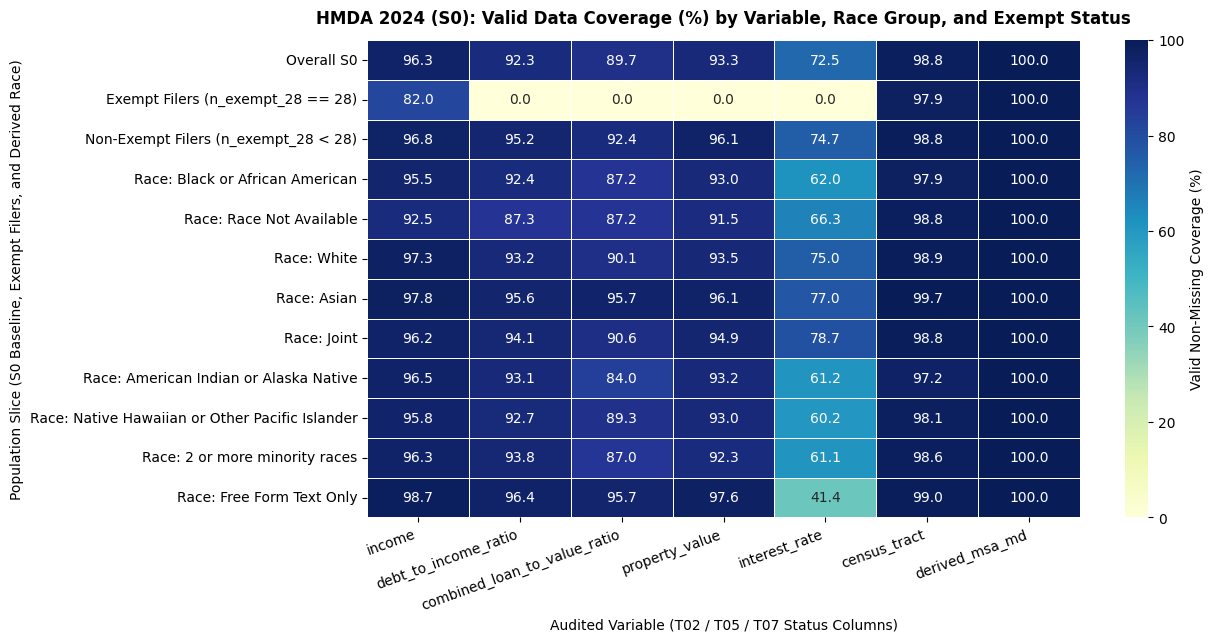

In [12]:
# Step 1: Pivot coverage percentages for heatmap visualization
piv_cov = cov_df.pivot(index="group_slice", columns="variable", values="pct_value")
col_order = [v for v, _ in COV_SPECS]
row_order = [s[0] for s in slices]
piv_cov = piv_cov.loc[row_order, col_order]

# Step 2: Plot annotated coverage heatmap
fig, ax = plt.subplots(figsize=(11.5, 6.2))
sns.heatmap(piv_cov, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100,
            cbar_kws={"label": "Valid Non-Missing Coverage (%)"}, linewidths=0.5, ax=ax)
ax.set_title("HMDA 2024 (S0): Valid Data Coverage (%) by Variable, Race Group, and Exempt Status", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Audited Variable (T02 / T05 / T07 Status Columns)")
ax.set_ylabel("Population Slice (S0 Baseline, Exempt Filers, and Derived Race)")
plt.xticks(rotation=20, ha="right")
save_fig_and_log(fig, "B14_fig_02_coverage_by_race.png")
plt.show()

### Step A5: Population Composition of Analytic Sample $S0$ (`eda_plan.md` §4, A5)

- **Input:** `df_s0` demographic and application channel columns (`derived_race`, `race_ethnicity`, `derived_ethnicity`, `derived_sex`, `applicant_age`, `has_coapplicant`, `submission_of_application`).
- **Process:**
  - For each demographic and channel dimension, compute total application counts, percentage share of $S0$, denied application counts, and denial rate with 95% Wilson confidence intervals (`groupby(..., observed=True, dropna=False)`).
  - Verify that the counts within every dimension sum exactly to `len(df_s0)` ($8,136,664$, Convention 4.5).
  - Flag cells below `N_MIN_APPS = 1,000` or `N_MIN_DENIED = 100` with `low_n = True` (Decision D-M).
  - Visualize the demographic composition and group denial rates across `derived_race` (9 categories), `race_ethnicity` (5 categories, Decision D-K), `applicant_age`, and `has_coapplicant` in `B14_fig_03_composition.png`.
- **Output:** `output/B14_composition.csv` and `output/figures/B14_fig_03_composition.png`.

In [13]:
# Step 1: Tabulate composition and denial rates across demographic and channel dimensions
COMP_DIMS = ["derived_race", "race_ethnicity", "derived_ethnicity", "derived_sex",
             "applicant_age", "has_coapplicant", "submission_of_application"]
comp_rows = []
for dim in COMP_DIMS:
    s_col = df_s0[dim].astype("string").fillna("NULL / Missing")
    g = df_s0.groupby(s_col, observed=True, dropna=False)["is_denied"].agg(n_apps="count", n_denied="sum").reset_index()
    g.rename(columns={dim: "level"}, inplace=True)
    assert int(g["n_apps"].sum()) == len(df_s0), f"Row sum mismatch on {dim}"
    ci_lo, ci_hi = wilson_ci(g["n_denied"], g["n_apps"])
    g["dimension"] = dim
    g["share_s0_pct"] = (g["n_apps"] * 100.0 / len(df_s0)).round(3)
    g["denial_rate_pct"] = (g["n_denied"] * 100.0 / g["n_apps"]).round(2)
    g["wilson_ci_lo"], g["wilson_ci_hi"] = np.round(ci_lo, 2), np.round(ci_hi, 2)
    g["low_n"] = (g["n_apps"] < N_MIN_APPS) | (g["n_denied"] < N_MIN_DENIED)
    comp_rows.append(g[["dimension", "level", "n_apps", "share_s0_pct", "n_denied", "denial_rate_pct", "wilson_ci_lo", "wilson_ci_hi", "low_n"]])

comp_df = pd.concat(comp_rows, ignore_index=True)
save_and_log(comp_df, "B14_composition.csv")
display(comp_df[comp_df["dimension"].isin(["derived_race", "race_ethnicity"])])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_composition.csv | Size: 2.75 KB | Shape: (37, 9)


,dimension,level,n_apps,share_s0_pct,n_denied,denial_rate_pct,wilson_ci_lo,wilson_ci_hi,low_n
0,derived_race,2 or more minority races,20920,0.2570,7988,38.1800,37.5300,38.8400,False
1,derived_race,American Indian or Alaska Native,61397,0.7550,22787,37.1100,36.7300,37.5000,False
2,derived_race,Asian,478497,5.8810,104150,21.7700,21.6500,21.8800,False
3,derived_race,Black or African American,733103,9.0100,269758,36.8000,36.6900,36.9100,False
4,derived_race,Free Form Text Only,2098,0.0260,1224,58.3400,56.2200,60.4300,False
5,derived_race,Joint,184536,2.2680,36138,19.5800,19.4000,19.7600,False
6,derived_race,Native Hawaiian or Other Pacific Islander,20249,0.2490,7874,38.8900,38.2200,39.5600,False
7,derived_race,Race Not Available,1275240,15.6730,378227,29.6600,29.5800,29.7400,False
8,derived_race,White,5360624,65.8820,1175130,21.9200,21.8900,21.9600,False
9,race_ethnicity,Hispanic or Latino (Any Race),1006680,12.3720,309279,30.7200,30.6300,30.8100,False


### Step A5 (Continued): Four-Panel Demographic Composition & Denial Rate Chart

- **Input:** `comp_df` (`B14_composition.csv`).
- **Process:**
  - Plot a $2 \times 2$ grid (`B14_fig_03_composition.png`) displaying application share (% of $S0$, horizontal bars) and denial rate (%, overlaid markers/labels) for:
    1. `derived_race` (9 CFPB categories, Decision D-D & D-L);
    2. `race_ethnicity` (5 combined groups, Decision D-K);
    3. `applicant_age` (ordered age brackets);
    4. `has_coapplicant` (`1 = Co-applicant present`, `0 = Solo applicant`, `NULL = Unresolved NA`).
- **Output:** `output/figures/B14_fig_03_composition.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_03_composition.png | Size: 194.67 KB


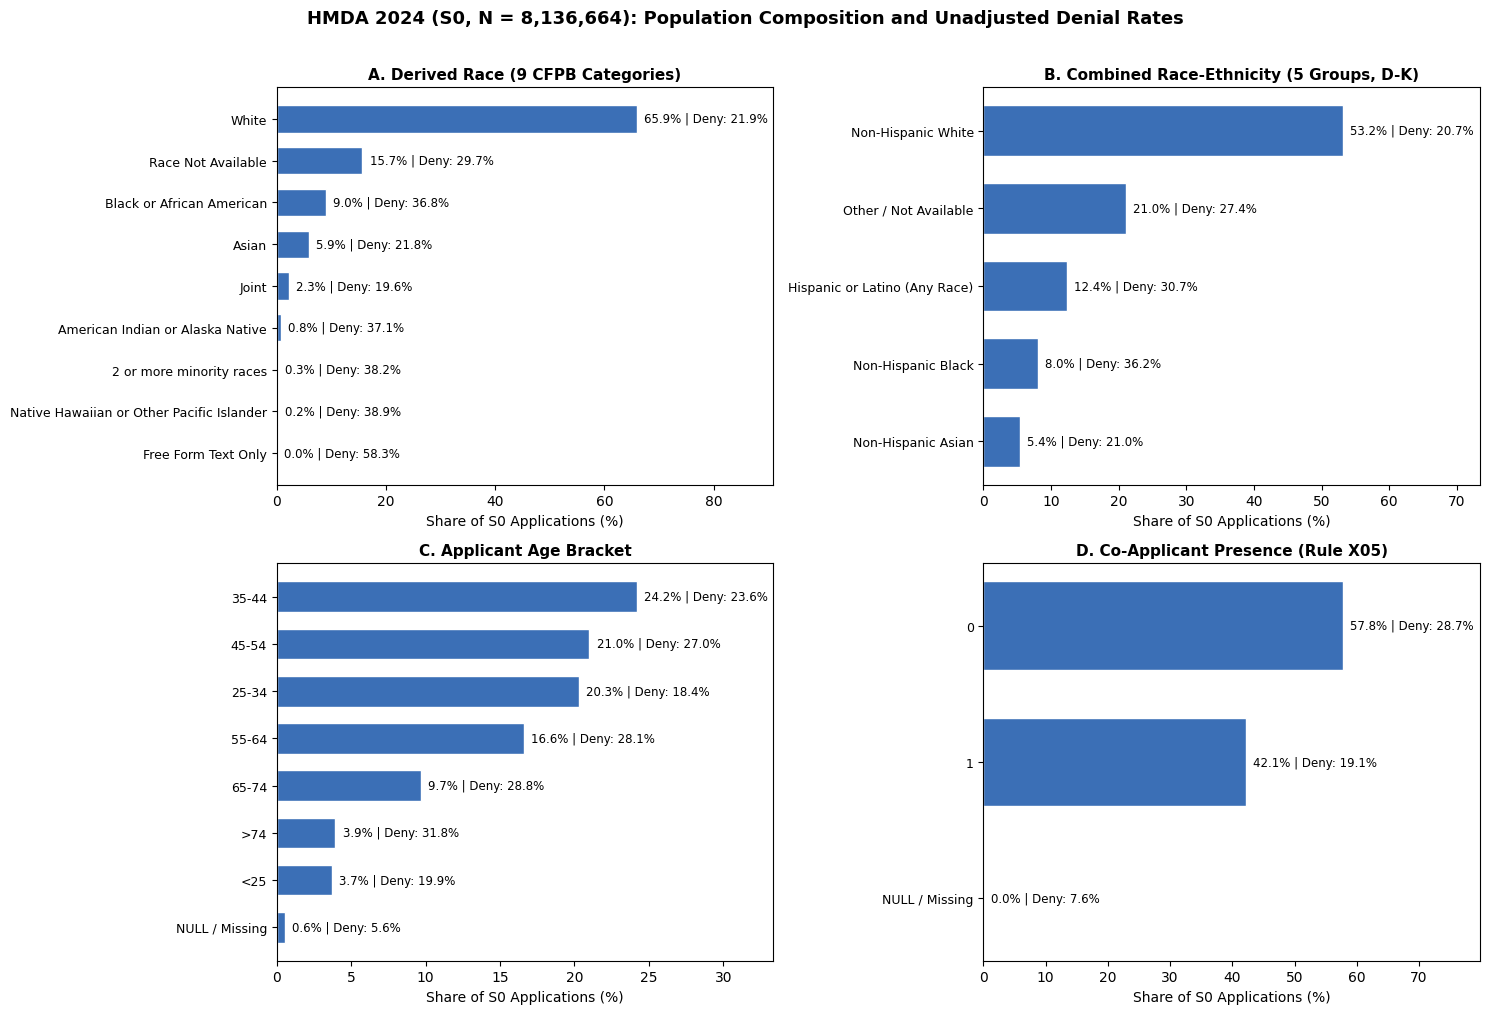

In [14]:
# Step 1: Set up 2x2 grid for demographic composition
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panel_specs = [
    ("derived_race", "A. Derived Race (9 CFPB Categories)", axes[0, 0]),
    ("race_ethnicity", "B. Combined Race-Ethnicity (5 Groups, D-K)", axes[0, 1]),
    ("applicant_age", "C. Applicant Age Bracket", axes[1, 0]),
    ("has_coapplicant", "D. Co-Applicant Presence (Rule X05)", axes[1, 1]),
]

# Step 2: Render horizontal share bars with annotated application share and denial rate
for dim, title, ax in panel_specs:
    sub = comp_df[comp_df["dimension"] == dim].sort_values("n_apps", ascending=True)
    y = np.arange(len(sub))
    bars = ax.barh(y, sub["share_s0_pct"], color="#3b6fb6", edgecolor="white", height=0.65)
    ax.set_yticks(y); ax.set_yticklabels(sub["level"], fontsize=9)
    ax.set_xlabel("Share of S0 Applications (%)")
    ax.set_xlim(0, max(sub["share_s0_pct"]) * 1.38)
    ax.set_title(title, fontsize=11, fontweight="bold")
    for idx, (_, row) in enumerate(sub.iterrows()):
        ax.text(row["share_s0_pct"] + max(sub["share_s0_pct"]) * 0.02, idx,
                f"{row['share_s0_pct']:.1f}% | Deny: {row['denial_rate_pct']:.1f}%", va="center", fontsize=8.5)

fig.suptitle(f"HMDA 2024 (S0, N = {len(df_s0):,}): Population Composition and Unadjusted Denial Rates", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig_and_log(fig, "B14_fig_03_composition.png")
plt.show()

### Interpretation — Steps A3, A4 & A5 (Leakage Audit, Coverage Matrix, and Population Composition)

*All figures are read from the saved tables (as of run 2026-11-10, B14 A3 / A4 / A5).*

1. **What pattern is observed?**
   - **Leakage audit (A3).** Six pricing/cost fields (`interest_rate`, `rate_spread`, `origination_charges`, `total_loan_costs`, `discount_points`, `lender_credits`) are missing on 100% of denied applications; their availability on non-denied applications ranges from 96.17% (`interest_rate`) down to 23.06% (`lender_credits`). `denial_reason_2..4` are the mirror case: 0% availability on non-denied rows and 21.92% / 4.08% / 0.76% on denied rows. Three coded fields reveal the outcome through their value: `purchaser_type = 0` (100.00% of denied vs 43.78% of non-denied), `hoepa_status = 3` (100.00% vs 11.24%) and `denial_reason_1 = 10` (0.00% of denied vs 97.22% of non-denied). `aus_1 = 6` (Not applicable) is 66.16% of denied vs 33.79% of non-denied (gap 32.37 pp, below the 50 pp flag); `applicant_credit_score_type` shows only a small gap (code 9: 11.99% vs 9.22%). `loan_term` passes the audit (93.72% available on denied vs 95.95% on non-denied) and is the only column with a role/audit conflict (see Decision D-AA).
   - **Coverage (A4).** On S0, valid coverage is 96.35% for `income`, 92.35% for DTI, 89.69% for CLTV, 93.29% for `property_value` and 98.82% for `census_tract`. Full exempt filers (241,108 rows) have 0% valid DTI, CLTV, `property_value` and `interest_rate` (all `Exempt`), but `income` is valid on 81.96% (18.04% `NA`, not `Exempt`), versus 96.79% for non-exempt filers. Missing financial fields differ by race: CLTV is missing on 11.44% of Black applications vs 6.60% of White; DTI valid coverage is 87.31% for `Race Not Available` vs 93.17% for White; exempt-filer share is 4.17% for `Race Not Available`, 3.28% for White and 1.36% for Black. The `NA` share of `interest_rate` by race (White 21.70%, `Race Not Available` 29.53%, Black 36.62%) follows the denial rates, because `interest_rate` is not reported for denied loans.
   - **Composition (A5).** White is 65.88% of S0 (5,360,624 rows, denial rate 21.92%); `Race Not Available` 15.67% (29.66%); Black 9.01% (733,103 rows, 36.80%, gap +14.88 pp vs White); Asian 5.88% (21.77%, about 0.15 pp below White); Joint 2.27% (19.58%). In the 5-group `race_ethnicity` (D-K), Non-Hispanic White is 53.20% (20.72%), Hispanic or Latino 12.37% (30.72%, +10.00 pp vs Non-Hispanic White) and Non-Hispanic Black 8.05% (36.22%). Denial rate rises with age from 18.44% (25-34) to 31.78% (>74), with a dip at `<25` (19.91%). Applications without a co-applicant are 57.81% of S0 (denial 28.66%) vs 42.14% with one (19.10%). By sex: Joint 18.42%, Male 26.68%, Female 29.57%. By channel: direct submission (code 1) 81.49% of S0 (26.03%), not direct (code 2) 15.43% (19.49%), Exempt (1111) 3.07% (13.06%).
2. **What evidence supports the finding?**
   - `B14_availability_by_outcome.csv`, `B14_availability_code_level.csv`, `B14_coverage_by_race.csv`, `B14_composition.csv`, Figures 02 and 03.
3. **Why might it matter in mortgage lending?**
   - A field that exists only after approval (pricing, costs) or only after denial (reasons 2-4) lets a model separate the two outcomes mechanically; such fields cannot be controls in a denial analysis. Coded values (`purchaser_type`, `hoepa_status`, `denial_reason_1`) leak the same information without any NULL.
   - Exempt filers hide DTI, CLTV and value entirely, and missing financial fields are more frequent for some groups. Complete-case analysis would therefore change the racial mix of the sample (selection), which is tested in Part D (D6).
   - Unadjusted denial rates differ strongly by co-applicant presence, sex, age and channel. These dimensions are correlated with race, so the raw racial gap mixes several composition effects (addressed in Parts C and D).
4. **What alternative explanations or limitations apply?**
   - The audit tests availability and a few codes, not every possible dependence on the outcome. `aus_1` passes the 50 pp rule, but its `Not applicable` code is twice as common among denied files `[Hypothesis: files denied before an AUS run]`; it stays in the robustness-only role (D-Y).
   - `loan_term` passing the audit means that it is available before the decision; whether the value on approved loans equals the requested term cannot be checked in public HMDA `[Hypothesis]`.
   - `Race Not Available` (15.67% of S0) is a mixture (D-L). The `has_coapplicant = NULL` (0.045%) and `applicant_age = NULL` (0.56%, denial rate 5.63%) groups are small but very different from the rest; their cause is not verified `[Hypothesis]`.
   - All rates are unadjusted descriptive differences, not evidence of discrimination.

## Part B — Univariate Distributions (`eda_plan.md` §5, Assignment §3.3 A)

### Step B1: Continuous Borrower & Collateral Variables (`loan_amount`, `property_value`, `income`, `loan_to_income` — PySpark Target E5)

- **Input:** `df_s0` numeric columns and `B06_WINSOR` (`B06_s4_winsor_thresholds.json`).
- **Process:**
  - Compute comprehensive summary statistics (`n_valid`, `n_missing`, `pct_missing`, `mean`, `sd`, `skewness`, and percentiles `p01`, `p05`, `p25`, `p50`, `p75`, `p95`, `p99`) for all key continuous variables:
    - **B1 core variables (on full $S0$):** `loan_amount` ($), `property_value` ($), `income` ($1,000s), `loan_to_income` (ratio);
    - **B2 LTV variables (on full $S0$):** `combined_loan_to_value_ratio` (%), `ltv_calc` (%), `profile_cltv_discrepancy` (pp);
    - **B4 pricing/term variables (strictly on originated loans `action_taken == '1'`):** `interest_rate` (%), `rate_spread` (pp), `loan_term` (months), `total_loan_costs` ($).
  - Export `B14_numeric_summary.csv` (which serves as **PySpark Equivalence Target E5** for `loan_amount` and `income` quantiles).
  - Plot `B14_fig_04_univariate_continuous.png` showing log-scale distributions (`loan_amount`, `property_value`, `income`, `loan_to_income`) by outcome (`is_denied` 0 vs. 1) with vertical dashed lines marking the S4 p01/p99 winsorization thresholds from `B06_s4_winsor_thresholds.json` (display only, no data modification).
- **Output:** `output/B14_numeric_summary.csv` and `output/figures/B14_fig_04_univariate_continuous.png`.

In [15]:
# Step 1: Compute univariate summary table for B1, B2 (on S0) and B4 (on originated action_taken == '1')
NUM_SUMMARY_SPECS = [
    ("loan_amount", "S0 (All Decided)", df_s0["loan_amount"], "USD ($)"),
    ("property_value", "S0 (All Decided)", df_s0["property_value"], "USD ($)"),
    ("income", "S0 (All Decided)", df_s0["income"], "Thousands USD ($1,000s)"),
    ("loan_to_income", "S0 (All Decided, income > 0)", df_s0["loan_to_income"], "Ratio (Loan / Annual Income)"),
    ("combined_loan_to_value_ratio", "S0 (All Decided)", df_s0["combined_loan_to_value_ratio"], "Percent (%)"),
    ("ltv_calc", "S0 (All Decided, prop_val > 0)", df_s0["ltv_calc"], "Percent (%)"),
    ("profile_cltv_discrepancy", "S0 (CLTV - ltv_calc)", df_s0["profile_cltv_discrepancy"], "Percentage Points (pp)"),
]
orig_mask = df_s0["action_taken"] == "1"
for c, unit in [("interest_rate", "Percent (%)"), ("rate_spread", "Percentage Points (pp)"),
                ("loan_term", "Months"), ("total_loan_costs", "USD ($)")]:
    NUM_SUMMARY_SPECS.append((c, "Originated Only (action_taken == '1')", df_s0.loc[orig_mask, c], unit))

num_rows = []
qs = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
for col, pop_label, s, unit in NUM_SUMMARY_SPECS:
    valid = s.dropna().astype("float64")
    q_vals = np.quantile(valid, qs)
    num_rows.append({
        "variable": col, "population": pop_label, "unit": unit,
        "n_total": len(s), "n_valid": len(valid), "n_missing": int(s.isna().sum()),
        "pct_missing": round(s.isna().mean() * 100.0, 2),
        "mean": round(float(valid.mean()), 3), "sd": round(float(valid.std()), 3),
        "skewness": round(float(valid.skew()), 2),
        **{f"p{int(q*100):02d}": round(float(v), 3) for q, v in zip(qs, q_vals)}
    })
num_sum_df = pd.DataFrame(num_rows)
save_and_log(num_sum_df, "B14_numeric_summary.csv")
display(num_sum_df)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_numeric_summary.csv | Size: 1.79 KB | Shape: (11, 17)


,variable,population,unit,n_total,n_valid,n_missing,pct_missing,mean,sd,skewness,p01,p05,p25,p50,p75,p95,p99
0,loan_amount,S0 (All Decided),USD ($),8136664,8136664,0,0.0000,"269,980.4820","541,268.9580",470.8800,"15,000.0000","25,000.0000","85,000.0000","205,000.0000","355,000.0000","705,000.0000","1,325,000.0000"
1,property_value,S0 (All Decided),USD ($),8136664,7590865,545799,6.7100,"513,357.8080","2,885,939.1330",462.3500,"65,000.0000","125,000.0000","255,000.0000","385,000.0000","595,000.0000","1,215,000.0000","2,405,000.0000"
2,income,S0 (All Decided),"Thousands USD ($1,000s)",8136664,7839422,297242,3.6500,178.2690,"38,459.0760","2,305.6000",0.0000,34.0000,68.0000,104.0000,163.0000,355.0000,780.0000
3,loan_to_income,"S0 (All Decided, income > 0)",Ratio (Loan / Annual Income),8136664,7748161,388503,4.7700,2.3250,7.6230,170.9100,0.1160,0.2790,0.8590,2.0040,3.1720,4.7410,7.0000
4,combined_loan_to_value_ratio,S0 (All Decided),Percent (%),8136664,7297403,839261,10.3100,"1,201.2560","1,728,717.7770","2,011.2400",9.9000,25.3600,60.0000,79.6890,94.0000,100.0000,104.1430
5,ltv_calc,"S0 (All Decided, prop_val > 0)",Percent (%),8136664,7590865,545799,6.7100,60.7510,79.7730,470.0400,3.5460,7.8010,24.2600,70.7320,92.0000,100.0000,104.2110
6,profile_cltv_discrepancy,S0 (CLTV - ltv_calc),Percentage Points (pp),8136664,7227929,908735,11.1700,182.6460,"228,766.7030","2,504.6700",-4.6380,-2.9410,-0.4510,0.4300,30.7690,68.2870,95.7830
7,interest_rate,Originated Only (action_taken == '1'),Percent (%),5793597,5573102,220495,3.8100,7.0510,1.6940,0.2400,0.0000,5.1250,6.2400,6.7500,7.6250,10.0500,12.2500
8,rate_spread,Originated Only (action_taken == '1'),Percentage Points (pp),5793597,5403805,389792,6.7300,0.4880,3.0430,251.5000,-6.0200,-1.2400,-0.1750,0.3200,0.9700,3.3400,5.6000
9,loan_term,Originated Only (action_taken == '1'),Months,5793597,5555673,237924,4.1100,326.3870,75.5770,-1.8600,60.0000,120.0000,360.0000,360.0000,360.0000,360.0000,480.0000


### Step B1 (Continued): Log-Scale Distributions & Boxplots with S4 Winsor Thresholds

- **Input:** `df_s0` (`loan_amount`, `property_value`, `income`, `loan_to_income`, `is_denied`) and `B06_WINSOR`.
- **Process:**
  - Plot a $2 \times 2$ figure (`B14_fig_04_univariate_continuous.png`) for the four core financial size variables (`loan_amount`, `property_value`, `income`, `loan_to_income`).
  - Use $\log_{10}$ transformations on positive values so extreme right-skewness is clearly visible, separating density histograms by outcome (`Approved/Originated` vs. `Denied`) and overlaying the S4 p01 and p99 winsorization boundaries from `B06_s4_winsor_thresholds.json`.
- **Output:** `output/figures/B14_fig_04_univariate_continuous.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_04_univariate_continuous.png | Size: 149.06 KB


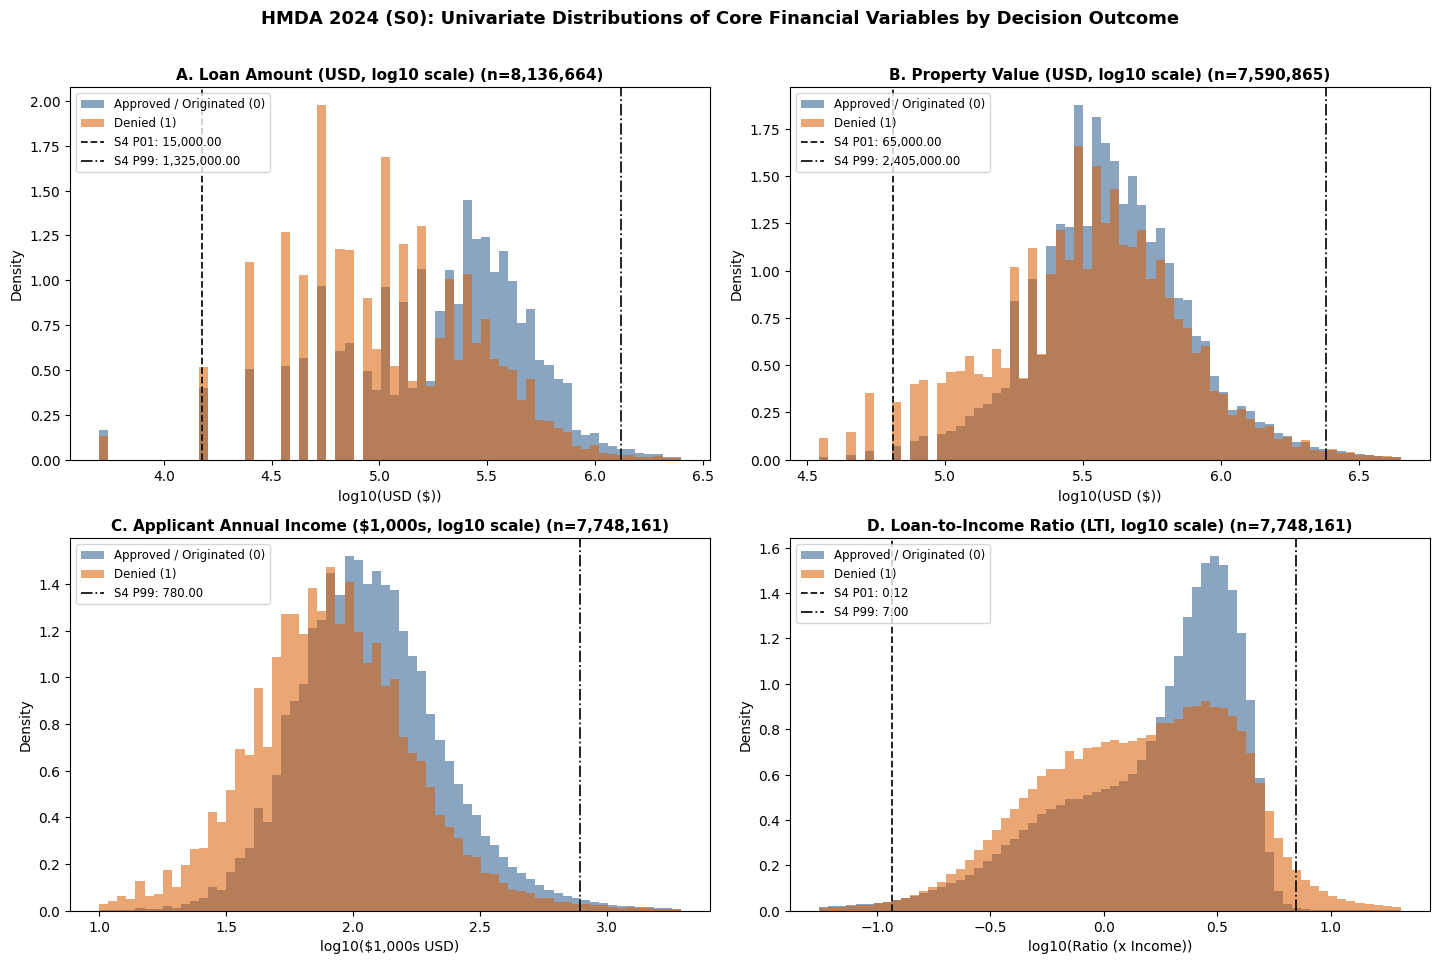

In [16]:
# Step 1: Configure 2x2 log-scale histogram grid with S4 p01/p99 threshold overlays
fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.5))
b1_plot_specs = [
    ("loan_amount", "A. Loan Amount (USD, log10 scale)", "USD ($)", axes[0, 0]),
    ("property_value", "B. Property Value (USD, log10 scale)", "USD ($)", axes[0, 1]),
    ("income", "C. Applicant Annual Income ($1,000s, log10 scale)", "$1,000s USD", axes[1, 0]),
    ("loan_to_income", "D. Loan-to-Income Ratio (LTI, log10 scale)", "Ratio (x Income)", axes[1, 1]),
]

# Step 2: Plot distributions split by credit outcome (is_denied = 0 vs 1)
for col, title, xlabel, ax in b1_plot_specs:
    sub = df_s0[[col, "is_denied"]].dropna()
    sub = sub[sub[col] > 0]
    log_v = np.log10(sub[col].astype("float64"))
    lo_clip, hi_clip = np.quantile(log_v, [0.002, 0.998])
    bins = np.linspace(lo_clip, hi_clip, 65)
    ax.hist(log_v[sub["is_denied"] == 0], bins=bins, density=True, alpha=0.55, color="#2b5c8f", label="Approved / Originated (0)")
    ax.hist(log_v[sub["is_denied"] == 1], bins=bins, density=True, alpha=0.55, color="#d95f02", label="Denied (1)")
    for p_key, ls in [("p01", "--"), ("p99", "-.")]:
        th = B06_WINSOR[col][p_key]
        if th > 0:
            ax.axvline(np.log10(th), color="#111111", linestyle=ls, linewidth=1.3, label=f"S4 {p_key.upper()}: {th:,.2f}")
    ax.set_title(f"{title} (n={len(sub):,})", fontsize=11, fontweight="bold")
    ax.set_xlabel(f"log10({xlabel})"); ax.set_ylabel("Density")
    ax.legend(fontsize=8.5, loc="upper left")

fig.suptitle("HMDA 2024 (S0): Univariate Distributions of Core Financial Variables by Decision Outcome", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig_and_log(fig, "B14_fig_04_univariate_continuous.png")
plt.show()

### Step B2: Combined Loan-to-Value (`CLTV`), Calculated LTV & Lien-Status Discrepancy (`eda_plan.md` §5, B2)

- **Input:** `df_s0` (`combined_loan_to_value_ratio`, `ltv_calc`, `profile_cltv_discrepancy`, `lien_status`).
- **Process:**
  - Examine the distribution of `combined_loan_to_value_ratio` (CLTV) restricted to standard range $(0, 130]\%$, highlighting institutional underwriting **heaping thresholds at 80%, 95%, 97%, and 100%**, separately by `lien_status` (`1 = First lien` vs. `2 = Subordinate lien`).
  - Profile `profile_cltv_discrepancy` ($\text{CLTV} - \text{LTV}_{\text{calc}}$, Rule V09) across `lien_status`: for first liens, CLTV and $\text{LTV}_{\text{calc}}$ closely track one another (median absolute difference $0.755\text{ pp}$, `[Verified: B06 cell 30]`), whereas for subordinate liens (second mortgages / HELOCs), `loan_amount` is only the junior note while `CLTV` includes the senior first mortgage, creating a large positive gap (`CLTV >> ltv_calc`).
- **Output:** `output/figures/B14_fig_05_cltv_and_discrepancy.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_05_cltv_and_discrepancy.png | Size: 104.76 KB


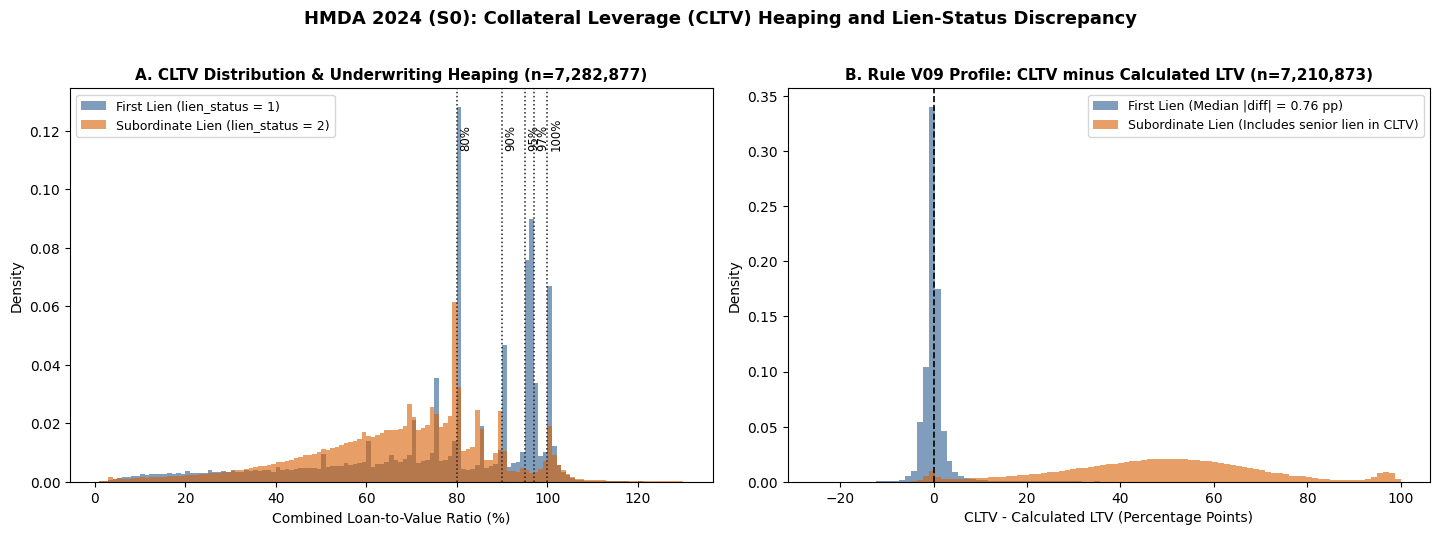

In [17]:
# [ADD] Step 0: median |CLTV - ltv_calc| for first liens, computed from data (Convention 4.3)
FL_MED = float(df_s0.loc[df_s0["lien_status"] == "1", "profile_cltv_discrepancy"].abs().median())
# Step 1: Set up two-panel figure for CLTV distribution by lien status and V09 discrepancy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))
cltv_sub = df_s0.loc[df_s0["combined_loan_to_value_ratio"].between(1, 130), ["combined_loan_to_value_ratio", "lien_status"]]
bins_cltv = np.linspace(1, 130, 130)
ax1.hist(cltv_sub.loc[cltv_sub["lien_status"] == "1", "combined_loan_to_value_ratio"], bins=bins_cltv,
         density=True, alpha=0.6, color="#2b5c8f", label="First Lien (lien_status = 1)")
ax1.hist(cltv_sub.loc[cltv_sub["lien_status"] == "2", "combined_loan_to_value_ratio"], bins=bins_cltv,
         density=True, alpha=0.6, color="#d95f02", label="Subordinate Lien (lien_status = 2)")
for h_val in (80, 90, 95, 97, 100):
    ax1.axvline(h_val, color="#222222", linestyle=":", linewidth=1.1)
    ax1.text(h_val + 0.5, ax1.get_ylim()[1] * 0.85, f"{h_val}%", fontsize=8.5, rotation=90)
ax1.set_title(f"A. CLTV Distribution & Underwriting Heaping (n={len(cltv_sub):,})", fontsize=11, fontweight="bold")
ax1.set_xlabel("Combined Loan-to-Value Ratio (%)"); ax1.set_ylabel("Density"); ax1.legend(fontsize=9)

# Step 2: Right panel — V09 Discrepancy (CLTV - ltv_calc) by lien status
disc_sub = df_s0.loc[df_s0["profile_cltv_discrepancy"].between(-25, 100), ["profile_cltv_discrepancy", "lien_status"]]
bins_disc = np.linspace(-25, 100, 100)
ax2.hist(disc_sub.loc[disc_sub["lien_status"] == "1", "profile_cltv_discrepancy"], bins=bins_disc,
# [CHANGE] label="First Lien (Median |diff| = 0.76 pp)"  ->
         density=True, alpha=0.6, color="#2b5c8f", label=f"First Lien (Median |diff| = {FL_MED:.2f} pp)") 
ax2.hist(disc_sub.loc[disc_sub["lien_status"] == "2", "profile_cltv_discrepancy"], bins=bins_disc,
         density=True, alpha=0.6, color="#d95f02", label="Subordinate Lien (Includes senior lien in CLTV)")
ax2.axvline(0, color="black", linestyle="--", linewidth=1.2)
ax2.set_title(f"B. Rule V09 Profile: CLTV minus Calculated LTV (n={len(disc_sub):,})", fontsize=11, fontweight="bold")
ax2.set_xlabel("CLTV - Calculated LTV (Percentage Points)"); ax2.set_ylabel("Density"); ax2.legend(fontsize=9)

fig.suptitle("HMDA 2024 (S0): Collateral Leverage (CLTV) Heaping and Lien-Status Discrepancy", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig_and_log(fig, "B14_fig_05_cltv_and_discrepancy.png")
plt.show()


### Interpretation — Steps B1 & B2 (`B14_numeric_summary.csv`, Fig 04 & 05)

*Figures are read from the saved table (as of run 2026-11-10, B14 B1).*

1. **What pattern is observed?**
   - All size variables are strongly right-skewed: median vs mean is 205,000 vs 269,980 USD for `loan_amount` and 104 vs 178.27 (thousand USD) for `income`; the p99 is 1,325,000 USD for `loan_amount`, 2,405,000 USD for `property_value` and 780 (thousand USD) for `income`. Mean and SD of `income` (SD 38,459), CLTV (mean 1,201, SD 1,728,718) and `total_loan_costs` (SD 2,928,349) are driven by a few extreme values, so medians and percentiles are used instead.
   - Missingness: `property_value` 6.71%, `income` 3.65%, CLTV 10.31% of S0. `loan_to_income` is missing on 4.77% of S0 (income missing or <= 0). Among originated loans, `interest_rate` is missing on 3.81%, `loan_term` on 4.11%, `rate_spread` on 6.73% and `total_loan_costs` on 24.87%.
   - Typical loan: median loan-to-income is 2.00 (p95 4.74, p99 7.00); median CLTV is 79.69% (p95 100.00%, p99 104.14%), which matches the heaping at 80/95/97/100 in Fig 05. Median `ltv_calc` (70.73%) is lower than median CLTV because for subordinate liens `loan_amount` is only the junior note (`profile_cltv_discrepancy`: median 0.43 pp, p75 30.77 pp).
   - Originated loans: median `interest_rate` 6.75% (p05 5.13%, p95 10.05%); `loan_term` is 360 months from p25 to p95 (p05 120, p99 480). The p01 of `interest_rate` is 0.00 (rule V04 rates, Decision D-C).
2. **What evidence supports the finding?**
   - `B14_numeric_summary.csv`, Figures 04 and 05 (PySpark equivalence target E5 for `loan_amount` and `income` quantiles).
3. **Why might it matter in mortgage lending?**
   - Skewness and extreme values mean that any model on raw levels is dominated by a few rows; log transforms and bins (Decision D-V) are needed. The p01 of `income` equal to 0 reflects the 1.12% of S0 with income <= 0 (rule V02), which have a very different denial profile (see B6).
   - Pricing and cost fields exist only for originated loans (A3), so their distributions describe selected loans, not all applicants.
4. **What alternative explanations or limitations apply?**
   - The 24.87% missing `total_loan_costs` among originated loans is not explained here `[Hypothesis: not reported for some loan types]`.
   - The SD and mean of CLTV, `rate_spread` and `total_loan_costs` should not be used as measures of typical spread; winsorization thresholds (S4) are display-only.

### Step B3: Debt-to-Income Ratio (`DTI`) as Ordinal Bins (`eda_plan.md` §5, B3)

- **Input:** `df_s0` (`dti_bin_coarse`, `dti_bin_fine`, `dti_status`, `is_denied`).
- **Process:**
  - Per **Assumption A7** (`[Verified: B05 cell 31, Rule T07]`), HMDA reports DTI as mixed ordinal bins (`<20%`, `20%-<30%`, `30%-<36%`, integer points `36`..`49`, `50%-60%`, `>60%`, plus `NA` and `Exempt`). Treating DTI as a single continuous float would drop or distort the binned ranges.
  - Tabulate application counts, population shares, and denial rates (with 95% Wilson CIs) across both the **8 coarse bins + missing statuses** (`dti_bin_coarse`) and the **19 fine bins + missing statuses** (`dti_bin_fine`) in strict ordinal order.
  - Plot `B14_fig_06_dti_distribution.png` showing the volume distribution and the monotonic jump in denial rates across DTI thresholds (especially above $43\%$ QM / $50\%$ underwriting thresholds).
- **Output:** `output/B14_dti_distribution.csv` and `output/figures/B14_fig_06_dti_distribution.png`.

In [18]:
# Step 1: Define strict ordinal ordering for coarse and fine DTI bins (Rule T07)
DTI_COARSE_ORDER = ["<20", "20-<30", "30-<36", "36-40", "41-45", "46-49", "50-60", ">60", "MISSING: na", "MISSING: exempt"]
DTI_FINE_ORDER = ["<20", "20-<30", "30-<36"] + [str(i) for i in range(36, 50)] + ["50-60", ">60", "MISSING: na", "MISSING: exempt"]

def tabulate_dti(bin_col: str, order_list: list, gran_label: str) -> pd.DataFrame:
    s = df_s0[bin_col].astype("string").fillna("MISSING: " + df_s0["dti_status"].astype("string"))
    g = df_s0.groupby(s, observed=True, dropna=False)["is_denied"].agg(n_apps="count", n_denied="sum").reindex(order_list, fill_value=0).reset_index()
    g.rename(columns={"index": "dti_bin", bin_col: "dti_bin"}, inplace=True)
    assert int(g["n_apps"].sum()) == len(df_s0), f"DTI sum mismatch on {gran_label}"
    ci_lo, ci_hi = wilson_ci(g["n_denied"], g["n_apps"])
    g["granularity"] = gran_label
    g["share_s0_pct"] = (g["n_apps"] * 100.0 / len(df_s0)).round(2)
    g["denial_rate_pct"] = (g["n_denied"] * 100.0 / g["n_apps"]).round(2)
    g["wilson_ci_lo"], g["wilson_ci_hi"] = np.round(ci_lo, 2), np.round(ci_hi, 2)
    return g[["granularity", "dti_bin", "n_apps", "share_s0_pct", "n_denied", "denial_rate_pct", "wilson_ci_lo", "wilson_ci_hi"]]

dti_df = pd.concat([tabulate_dti("dti_bin_coarse", DTI_COARSE_ORDER, "coarse"),
                    tabulate_dti("dti_bin_fine", DTI_FINE_ORDER, "fine")], ignore_index=True)
save_and_log(dti_df, "B14_dti_distribution.csv")
display(dti_df[dti_df["granularity"] == "coarse"])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_dti_distribution.csv | Size: 1.56 KB | Shape: (31, 8)


,granularity,dti_bin,n_apps,share_s0_pct,n_denied,denial_rate_pct,wilson_ci_lo,wilson_ci_hi
0,coarse,<20,419331,5.1500,122499,29.2100,29.0800,29.3500
1,coarse,20-<30,1019108,12.5200,162366,15.9300,15.8600,16.0000
2,coarse,30-<36,1046288,12.8600,148872,14.2300,14.1600,14.3000
3,coarse,36-40,1151668,14.1500,157675,13.6900,13.6300,13.7500
4,coarse,41-45,1391314,17.1000,195840,14.0800,14.0200,14.1300
5,coarse,46-49,1101152,13.5300,168997,15.3500,15.2800,15.4100
6,coarse,50-60,795042,9.7700,305387,38.4100,38.3000,38.5200
7,coarse,>60,590059,7.2500,542938,92.0100,91.9400,92.0800
8,coarse,MISSING: na,372942,4.5800,166070,44.5300,44.3700,44.6900
9,coarse,MISSING: exempt,249760,3.0700,32632,13.0700,12.9300,13.2000


### Step B3 (Continued): Fine-Grained DTI Volume & Denial Rate Curve

- **Input:** `dti_df` (`B14_dti_distribution.csv`, `granularity == 'fine'`).
- **Process:**
  - Plot a dual-axis chart (`B14_fig_06_dti_distribution.png`) over all 19 fine DTI categories plus `MISSING: na` and `MISSING: exempt`:
    - **Bars (left axis):** Share of $S0$ applications (%) in each DTI bin.
    - **Line with markers (right axis):** Denial rate (%) in each DTI bin, illustrating the sharp cliff at DTI $= 43\%$, $45\%$, and $50\%$ (`>60%` reaches near-universal denial).
- **Output:** `output/figures/B14_fig_06_dti_distribution.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_06_dti_distribution.png | Size: 109.97 KB


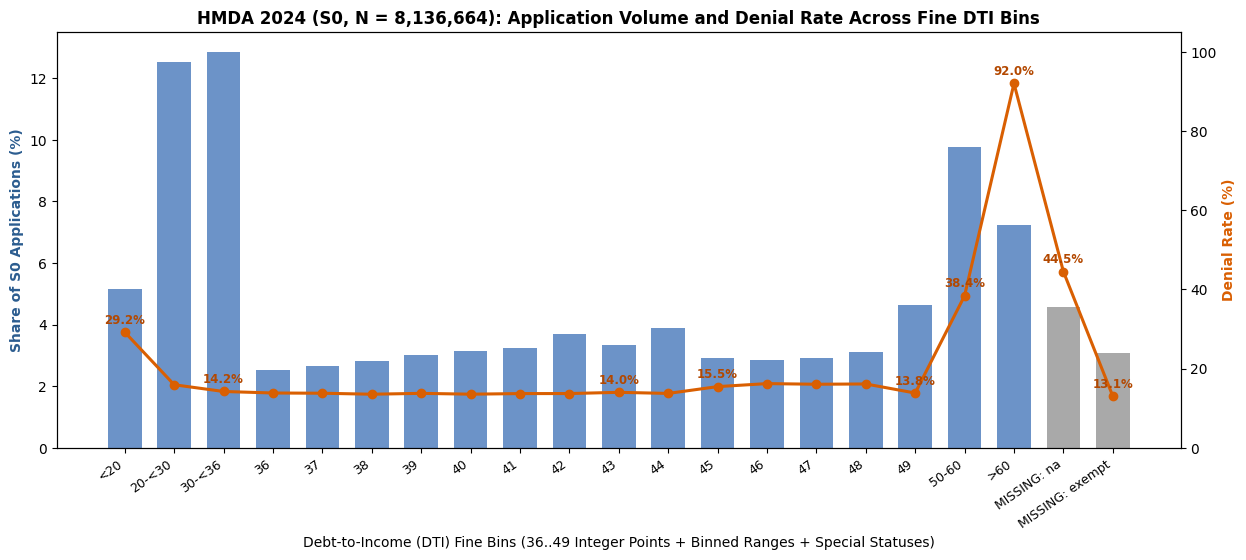

In [19]:
# Step 1: Filter fine DTI table and create dual-axis bar + line chart
fine_dti = dti_df[dti_df["granularity"] == "fine"].reset_index(drop=True)
x = np.arange(len(fine_dti))
fig, ax1 = plt.subplots(figsize=(14.5, 5.4))
ax2 = ax1.twinx()

# Step 2: Plot volume share bars on ax1 and denial rate curve on ax2
bar_colors = ["#8c8c8c" if b.startswith("MISSING") else "#3b6fb6" for b in fine_dti["dti_bin"]]
ax1.bar(x, fine_dti["share_s0_pct"], color=bar_colors, alpha=0.75, width=0.68, label="Application Share (% of S0)")
ax2.plot(x, fine_dti["denial_rate_pct"], color="#d95f02", marker="o", linewidth=2.2, label="Denial Rate (%)")
for idx, row in fine_dti.iterrows():
    if row["dti_bin"] in ("<20", "30-<36", "43", "45", "49", "50-60", ">60", "MISSING: na", "MISSING: exempt"):
        ax2.text(idx, row["denial_rate_pct"] + 2.2, f"{row['denial_rate_pct']:.1f}%", ha="center", fontsize=8.5, color="#b34800", fontweight="bold")

ax1.set_xticks(x); ax1.set_xticklabels(fine_dti["dti_bin"], rotation=35, ha="right", fontsize=9)
ax1.set_ylabel("Share of S0 Applications (%)", color="#2b5c8f", fontweight="bold")
ax2.set_ylabel("Denial Rate (%)", color="#d95f02", fontweight="bold"); ax2.set_ylim(0, 105)
ax1.set_xlabel("Debt-to-Income (DTI) Fine Bins (36..49 Integer Points + Binned Ranges + Special Statuses)")
ax1.set_title(f"HMDA 2024 (S0, N = {len(df_s0):,}): Application Volume and Denial Rate Across Fine DTI Bins", fontsize=12, fontweight="bold")
save_fig_and_log(fig, "B14_fig_06_dti_distribution.png")
plt.show()

### Interpretation — Step B3 (`B14_dti_distribution.csv`, Fig 06)

*Figures are read from the saved table (as of run 2026-11-10, B14 B3).*

1. **What pattern is observed?**
   - The denial rate is **not monotonic** in DTI. It is 29.21% for DTI < 20 (5.15% of S0), falls to 15.93% (20-<30) and 14.23% (30-<36), is flat at 13.5–14.0% for each integer point 36–44, rises slightly at 45 (15.46%) and 46–48 (16.06–16.22%), returns to 13.84% at 49, and then jumps to 38.41% for 50-60 (9.77% of S0) and 92.01% for > 60 (7.25% of S0).
   - DTI above 50 is 17.02% of S0 but contains 42.35% of all denials (848,325 of 2,003,276). DTI > 60 alone contains 27.10% of denials.
   - Missing DTI behaves differently by reason: `NA` (4.58% of S0) has a denial rate of 44.53%, while `Exempt` (3.07%) has 13.07%.
2. **What evidence supports the finding?**
   - `B14_dti_distribution.csv` (coarse and fine granularity; both sum to S0) and `B14_fig_06_dti_distribution.png`.
3. **Why might it matter in mortgage lending?**
   - A single "high DTI" cut at 50 explains a large share of denials, so DTI bins must be explicit controls (Decision D-V); a linear DTI term would misstate the relationship. The U-shape at DTI < 20 means "lower DTI" is not always "less risky" in the observed data.
   - `NA` DTI is a distinct group with high denial and must stay a separate category, not be dropped or imputed.
4. **What alternative explanations or limitations apply?**
   - The high rate at DTI < 20 `[Hypothesis: composition, e.g. low-income or subordinate-lien and HELOC applications; not tested here]`. The dip at 49 vs 46–48 `[Hypothesis: lender or AUS limits near 50%]`.
   - There is no visible step at 43 (14.02% vs 13.71% at 42 and 13.74% at 44), so a rule-based threshold at 43 is not supported by these bins.
   - DTI is binned and self-reported by the lender; it is one underwriting input among unobserved credit score, assets and AUS results.

### Step B4: Post-Decision Pricing & Loan Terms on Originated Loans Only (`eda_plan.md` §5, B4)

- **Input:** `df_s0` restricted strictly to originated loans (`action_taken == '1'`), columns `interest_rate`, `rate_spread`, `loan_term`, `total_loan_costs`, `loan_type`, and `flag_rate_range` (Rule V04).
- **Process:**
  - Per **Decision D-C** and **Step A3**, pricing and cost variables exist only after a loan is approved/originated (`action_taken == '1'`). We profile them conditionally on origination, reporting `interest_rate` statistics both **with and without Rule V04** (`flag_rate_range`: `interest_rate <= 0` or `> 25%`, where $95.34\%$ of zero-rate loans are subordinate-lien Down Payment Assistance loans, `[Verified: Decision D-C]`).
  - Plot `B14_fig_07_originated_pricing.png` showing the distribution of `interest_rate` (overall and by `loan_type`) and `total_loan_costs` among originated loans.
- **Output:** `output/figures/B14_fig_07_originated_pricing.png` and printed V04 comparison table.

,slice,n_loans,mean_rate,sd_rate,p05,p50,p95
0,Originated: All Reported Rates (Keep V04),5573102,7.0505,1.6939,5.1250,6.7500,10.0500
1,Originated: Exclude V04 (0 < rate <= 25%),5514784,7.1251,1.5390,5.2500,6.7900,10.0900


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_07_originated_pricing.png | Size: 94.95 KB


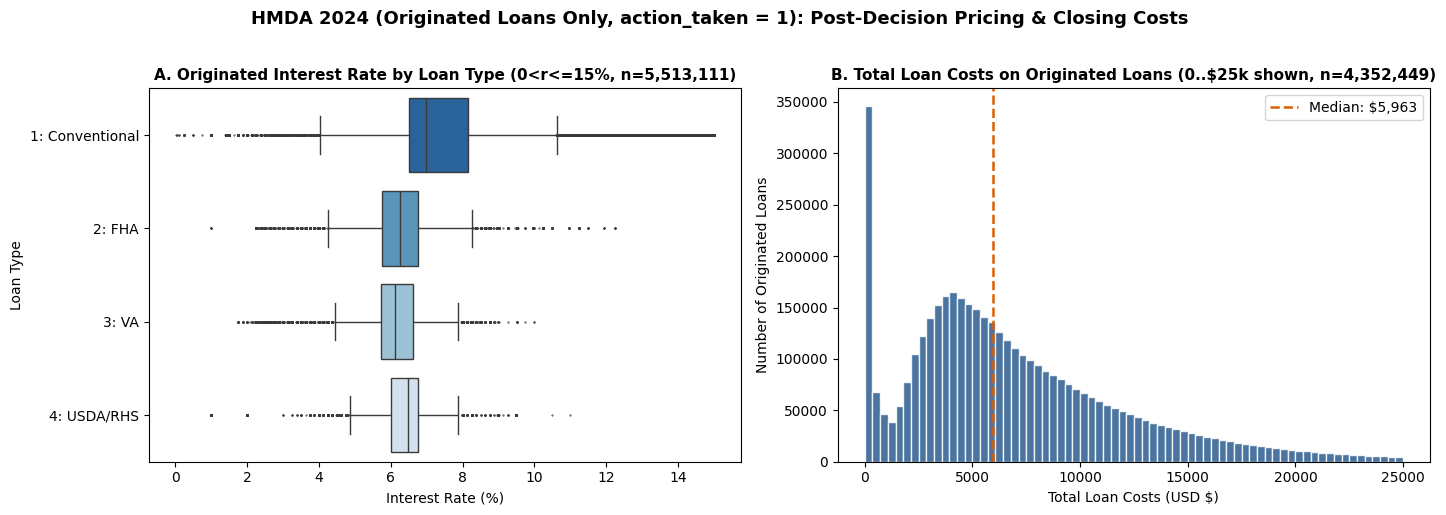

In [20]:
# Step 1: Compare originated interest_rate with and without Rule V04 (Decision D-C)
orig_df = df_s0.loc[df_s0["action_taken"] == "1", ["interest_rate", "rate_spread", "loan_term", "total_loan_costs", "loan_type", "flag_rate_range"]]
r_all = orig_df["interest_rate"].dropna()
r_no_v04 = orig_df.loc[~orig_df["flag_rate_range"], "interest_rate"].dropna()
v04_comp = pd.DataFrame([
    {"slice": "Originated: All Reported Rates (Keep V04)", "n_loans": len(r_all), "mean_rate": r_all.mean(), "sd_rate": r_all.std(), "p05": r_all.quantile(0.05), "p50": r_all.median(), "p95": r_all.quantile(0.95)},
    {"slice": "Originated: Exclude V04 (0 < rate <= 25%)", "n_loans": len(r_no_v04), "mean_rate": r_no_v04.mean(), "sd_rate": r_no_v04.std(), "p05": r_no_v04.quantile(0.05), "p50": r_no_v04.median(), "p95": r_no_v04.quantile(0.95)},
])
display(v04_comp)

# Step 2: Plot originated interest_rate by loan_type and total_loan_costs histogram
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.0))
lt_map = {"1": "1: Conventional", "2": "2: FHA", "3": "3: VA", "4": "4: USDA/RHS"}
orig_plot = orig_df.loc[orig_df["interest_rate"].between(0.01, 15.0)].copy()
orig_plot["loan_type_label"] = orig_plot["loan_type"].astype("string").map(lt_map)
sns.boxplot(data=orig_plot, x="interest_rate", y="loan_type_label", order=list(lt_map.values()),
            palette="Blues_r", fliersize=0.5, ax=ax1)
ax1.set_title(f"A. Originated Interest Rate by Loan Type (0<r<=15%, n={len(orig_plot):,})", fontsize=11, fontweight="bold")
ax1.set_xlabel("Interest Rate (%)"); ax1.set_ylabel("Loan Type")

costs = orig_df["total_loan_costs"].dropna()
costs_clip = costs[costs.between(0, 25000)]
ax2.hist(costs_clip, bins=70, color="#2b5c8f", edgecolor="white", alpha=0.85)
ax2.axvline(costs.median(), color="#d95f02", linestyle="--", linewidth=1.8, label=f"Median: ${costs.median():,.0f}")
ax2.set_title(f"B. Total Loan Costs on Originated Loans (0..$25k shown, n={len(costs):,})", fontsize=11, fontweight="bold")
ax2.set_xlabel("Total Loan Costs (USD $)"); ax2.set_ylabel("Number of Originated Loans"); ax2.legend()

fig.suptitle("HMDA 2024 (Originated Loans Only, action_taken = 1): Post-Decision Pricing & Closing Costs", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig_and_log(fig, "B14_fig_07_originated_pricing.png")
plt.show()

### Interpretation — Step B4 (Fig 07, `B14_pricing_by_loan_type.csv`, `B14_numeric_summary.csv`)

*Figures are read from the saved tables (as of run 2026-11-10, B14 B4).*

1. **What pattern is observed?**
   - **Interest rate by loan type (originated loans, Fig 07A).** Median rates are 6.99% for conventional loans (interquartile range 6.50–8.15%, 4,461,350 originated loans), 6.25% for FHA (5.75–6.75%, 805,845 loans), 6.125% for VA (5.74–6.625%, 490,123 loans) and 6.49% for USDA/RHS (6.00–6.75%, 36,279 loans). Conventional loans are about 0.7–0.9 pp higher at the median and have the widest spread (IQR 1.65 pp vs 0.75–1.00 pp for government-backed loans). Fig 07A shows 5,513,111 loans with a rate in (0, 15]; 5,573,102 loans have a valid rate, so 59,991 lie outside that range.
   - **Rates excluded or missing.** After excluding V04-flagged and missing rates, 6.11% of originated conventional loans and 8.79% of USDA/RHS loans have no usable rate, against 0.28% for FHA and 0.17% for VA.
   - **Overall originated rate:** median 6.75% (p05 5.13%, p95 10.05%, p99 12.25%); `interest_rate` is missing on 3.81% of originated loans.
   - **Total loan costs (Fig 07B).** 4,352,449 originated loans (75.13%) report a value; the median is 5,963 USD (p25 3,427, p75 9,973, p95 18,826, p99 28,276). The histogram has a large spike in the lowest bin (about 345,000 loans; p05 is 0, so at least 5% of valid values are exactly 0), a dip, and a main hump around 4,000–4,500 USD with a long right tail. Values above 25,000 USD are not drawn. Median costs differ strongly by loan type: 4,855 USD (conventional), 6,810 USD (VA), 6,223 USD (USDA/RHS) and 11,394 USD (FHA).
2. **What evidence supports the finding?**
   - `B14_fig_07_originated_pricing.png`, `B14_pricing_by_loan_type.csv` and the originated-loan rows of `B14_numeric_summary.csv`.
3. **Why might it matter in mortgage lending?**
   - Rates and costs differ by loan type by more than the typical differences between groups of borrowers, so a pooled comparison of pricing by race would mix loan types; the pricing analysis (D8) compares within loan type.
   - Pricing exists only for loans that were made, so these distributions describe selected loans, not all applicants (Assumption A6, Step A3). This step does not analyse denials.
4. **What alternative explanations or limitations apply?**
   - A zero interest rate and zero total loan costs are valid reported values `[Verified: FFIEC 2024 Filing Instructions Guide, §4.2.2]`, so the zero-cost spike is not automatically an error. Why many loans report 0 is not known `[Hypothesis: no-cost or lender-credit loans, or lenders recording 0 when the costs are not itemised]`.
   - The higher share of unusable rates among conventional and USDA/RHS loans is not explained here `[Hypothesis: zero-rate subordinate-lien loans (Decision D-C) and exempt or non-applicable reporting]`.
   - `total_loan_costs` is missing on 24.87% of originated loans `[Hypothesis: not required for some products, e.g. open-end lines of credit, which are 22.26% of S0]`. The much higher FHA median cost is not explained here `[Hypothesis: product-specific fees]`.
   - A few isolated rates near 1–2% appear for FHA and USDA/RHS in Fig 07A; they are implausible for those programs and may be reporting errors, but they are few and kept (Principle 2).
   - The conventional group mixes first-lien purchase loans, refinances, subordinate liens and lines of credit `[Hypothesis]`, so its wide spread is not a single market price.

### Step B5: Product, Channel & Institutional Categorical Variables (`eda_plan.md` §5, B5)

- **Input:** `df_s0` categorical product and underwriting columns (`loan_type`, `loan_purpose`, `lien_status`, `occupancy_type`, `construction_method`, `total_units`, `derived_dwelling_category`, `conforming_loan_limit`, `open_end_line_of_credit`, `preapproval`, `submission_of_application`, `aus_1`, `applicant_credit_score_type`, `lender_size_bucket`).
- **Process:**
  - Tabulate application counts, percentage share of $S0$, denied counts, and denial rates (with 95% Wilson CIs and `low_n` flags) for every level of all 14 categorical variables (`B14_categorical_summary.csv`).
  - Assert that the level counts for every variable sum exactly to `len(df_s0)` ($8,136,664$, Convention 4.5).
  - Plot `B14_fig_08_categorical_overview.png` displaying horizontal volume bars with denial-rate overlays for the 6 most influential product/underwriting dimensions (`loan_type`, `loan_purpose`, `lien_status`, `derived_dwelling_category`, `open_end_line_of_credit`, `lender_size_bucket`).
- **Output:** `output/B14_categorical_summary.csv` and `output/figures/B14_fig_08_categorical_overview.png`.

In [21]:
# Step 1: Readable label dictionaries for major HMDA product codes [Verified: Data Dictionary]
CAT_LABELS = {
    "loan_type": {"1": "1: Conventional", "2": "2: FHA", "3": "3: VA", "4": "4: USDA/RHS"},
    "loan_purpose": {"1": "1: Home Purchase", "2": "2: Home Improvement", "31": "31: Refi (Rate/Term)",
                     "32": "32: Cash-Out Refi", "4": "4: Other Purpose", "5": "5: Not Applicable"},
    "lien_status": {"1": "1: First Lien", "2": "2: Subordinate Lien"},
    "occupancy_type": {"1": "1: Principal Residence", "2": "2: Second Residence", "3": "3: Investment Property"},
    "construction_method": {"1": "1: Site-Built", "2": "2: Manufactured Home"},
    "open_end_line_of_credit": {"1": "1: Open-End HELOC", "2": "2: Not Open-End", "1111": "1111: Exempt"},
}
B5_COLS = ["loan_type", "loan_purpose", "lien_status", "occupancy_type", "construction_method",
           "total_units", "derived_dwelling_category", "conforming_loan_limit", "open_end_line_of_credit",
           "preapproval", "submission_of_application", "aus_1", "applicant_credit_score_type", "lender_size_bucket"]

# Step 2: Tabulate counts, shares, and denial rates across all 14 categorical variables
cat_rows = []
for col in B5_COLS:
    s_raw = df_s0[col].astype("string").fillna("NULL / Missing")
    lbl_map = CAT_LABELS.get(col, {})
    s_lbl = s_raw.map(lambda x: lbl_map.get(x, x))
    g = df_s0.groupby(s_lbl, observed=True, dropna=False)["is_denied"].agg(n_apps="count", n_denied="sum").reset_index()
    g.rename(columns={col: "level"}, inplace=True)
    assert int(g["n_apps"].sum()) == len(df_s0), f"Categorical sum mismatch on {col}"
    ci_lo, ci_hi = wilson_ci(g["n_denied"], g["n_apps"])
    g["variable"] = col
    g["share_s0_pct"] = (g["n_apps"] * 100.0 / len(df_s0)).round(2)
    g["denial_rate_pct"] = (g["n_denied"] * 100.0 / g["n_apps"]).round(2)
    g["wilson_ci_lo"], g["wilson_ci_hi"] = np.round(ci_lo, 2), np.round(ci_hi, 2)
    g["low_n"] = (g["n_apps"] < N_MIN_APPS) | (g["n_denied"] < N_MIN_DENIED)
    cat_rows.append(g.sort_values("n_apps", ascending=False)[["variable", "level", "n_apps", "share_s0_pct", "n_denied", "denial_rate_pct", "wilson_ci_lo", "wilson_ci_hi", "low_n"]])

cat_sum_df = pd.concat(cat_rows, ignore_index=True)
save_and_log(cat_sum_df, "B14_categorical_summary.csv")
display(cat_sum_df[cat_sum_df["variable"].isin(["loan_type", "loan_purpose", "lien_status", "lender_size_bucket"])])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_categorical_summary.csv | Size: 4.74 KB | Shape: (69, 9)


,variable,level,n_apps,share_s0_pct,n_denied,denial_rate_pct,wilson_ci_lo,wilson_ci_hi,low_n
0,loan_type,1: Conventional,6398871,78.6400,1668068,26.0700,26.0300,26.1000,False
1,loan_type,2: FHA,1079523,13.2700,235970,21.8600,21.7800,21.9400,False
2,loan_type,3: VA,614728,7.5600,93959,15.2800,15.1900,15.3700,False
3,loan_type,4: USDA/RHS,43542,0.5400,5279,12.1200,11.8200,12.4300,False
4,loan_purpose,1: Home Purchase,4038224,49.6300,584281,14.4700,14.4300,14.5000,False
5,loan_purpose,4: Other Purpose,1115882,13.7100,475513,42.6100,42.5200,42.7000,False
6,loan_purpose,32: Cash-Out Refi,1113814,13.6900,371497,33.3500,33.2700,33.4400,False
7,loan_purpose,2: Home Improvement,984874,12.1000,366083,37.1700,37.0800,37.2700,False
8,loan_purpose,31: Refi (Rate/Term),882884,10.8500,205273,23.2500,23.1600,23.3400,False
9,loan_purpose,5: Not Applicable,986,0.0100,629,63.7900,60.7500,66.7300,True


## Check: `conforming_loan_limit = NA` vs multifamily (5+ units)
- **Input:** `df_s0` (`conforming_loan_limit`, `total_units`).
- **Process:** Cross-tabulate the two columns and count the rows where `NA` and "5 or more units" disagree. If the count is 0, `NA` is exactly the 5+ unit rows and the two fields are redundant at that level.
- **Output:** Printed cross-tab and number of disagreeing rows.

In [22]:
# Step 1: Cross-tab conforming_loan_limit against 5+ unit properties
units5 = df_s0["total_units"].astype("string").isin(["5-24", "25-49", "50-99", "100-149", ">149"])
clim = df_s0["conforming_loan_limit"].astype("string")
display(pd.crosstab(clim, units5.rename("units_5_plus")))

# Step 2: Rows where the two definitions disagree
n_diff = int(((clim == "NA") != units5).sum())
print(f"Rows where (conforming_loan_limit == 'NA') differs from (total_units >= 5): {n_diff:,}")

units_5_plus,False,True
conforming_loan_limit,,
C,7903790,0
NA,0,9440
NC,223141,0
U,293,0


Rows where (conforming_loan_limit == 'NA') differs from (total_units >= 5): 0


### Step B5 (Continued): Six-Panel Product & Institutional Categorical Chart

- **Input:** `cat_sum_df` (`B14_categorical_summary.csv`).
- **Process:**
  - Plot a $3 \times 2$ grid (`B14_fig_08_categorical_overview.png`) showing application share (% of $S0$) and denial rate (%) across `loan_type`, `loan_purpose`, `lien_status`, `derived_dwelling_category`, `open_end_line_of_credit`, and `lender_size_bucket`.
- **Output:** `output/figures/B14_fig_08_categorical_overview.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_08_categorical_overview.png | Size: 208.60 KB


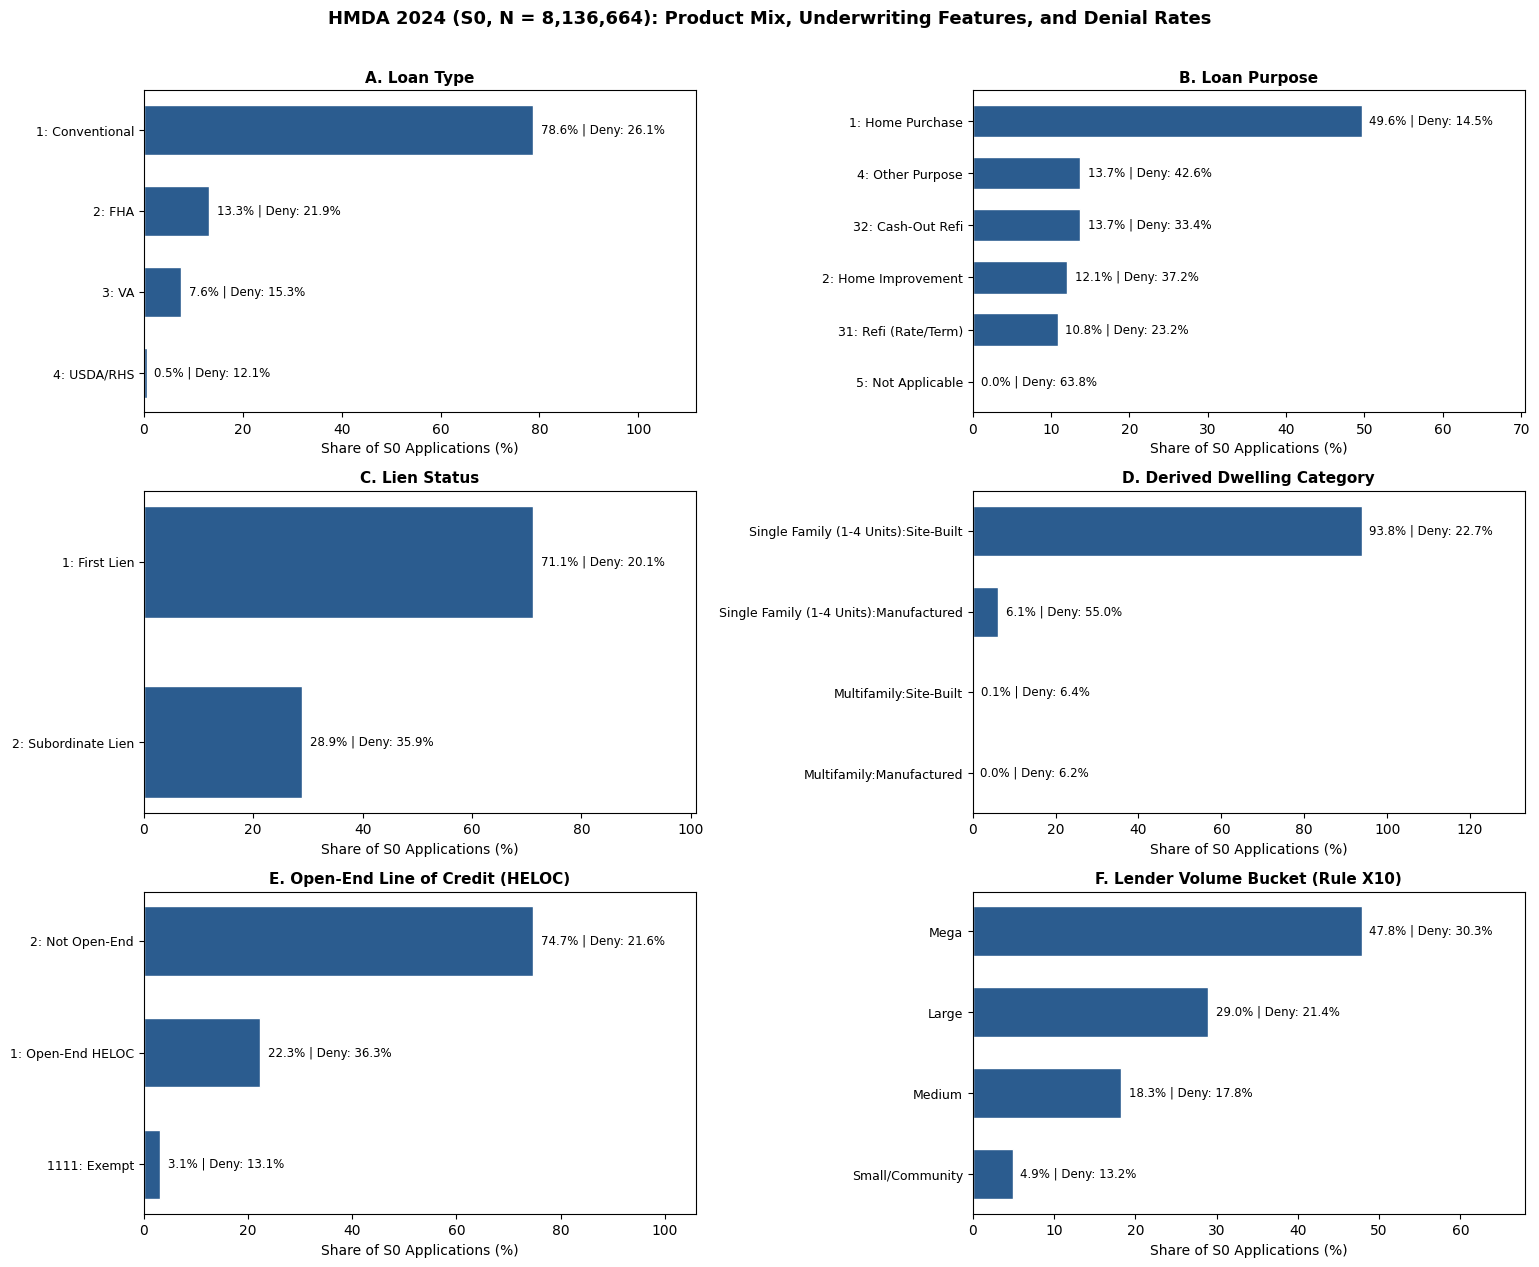

In [23]:
# Step 1: Set up 3x2 grid for key product and institutional categorical variables
fig, axes = plt.subplots(3, 2, figsize=(15.5, 12.5))
b5_plot_specs = [
    ("loan_type", "A. Loan Type", axes[0, 0]),
    ("loan_purpose", "B. Loan Purpose", axes[0, 1]),
    ("lien_status", "C. Lien Status", axes[1, 0]),
    ("derived_dwelling_category", "D. Derived Dwelling Category", axes[1, 1]),
    ("open_end_line_of_credit", "E. Open-End Line of Credit (HELOC)", axes[2, 0]),
    ("lender_size_bucket", "F. Lender Volume Bucket (Rule X10)", axes[2, 1]),
]

# Step 2: Plot horizontal volume bars with denial rate labels
for col, title, ax in b5_plot_specs:
    sub = cat_sum_df[cat_sum_df["variable"] == col].sort_values("n_apps", ascending=True)
    y = np.arange(len(sub))
    ax.barh(y, sub["share_s0_pct"], color="#2b5c8f", edgecolor="white", height=0.62)
    ax.set_yticks(y); ax.set_yticklabels(sub["level"], fontsize=9)
    ax.set_xlim(0, max(sub["share_s0_pct"]) * 1.42)
    ax.set_xlabel("Share of S0 Applications (%)")
    ax.set_title(title, fontsize=11, fontweight="bold")
    for idx, (_, row) in enumerate(sub.iterrows()):
        ax.text(row["share_s0_pct"] + max(sub["share_s0_pct"]) * 0.02, idx,
                f"{row['share_s0_pct']:.1f}% | Deny: {row['denial_rate_pct']:.1f}%", va="center", fontsize=8.5)

fig.suptitle(f"HMDA 2024 (S0, N = {len(df_s0):,}): Product Mix, Underwriting Features, and Denial Rates", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig_and_log(fig, "B14_fig_08_categorical_overview.png")
plt.show()

### Interpretation — Step B5 (`B14_categorical_summary.csv`, Fig 08)

*Figures are read from the saved table (as of run 2026-11-10, B14 B5).*

1. **What pattern is observed?**
   - **Product:** Conventional loans are 78.64% of S0 (denial 26.07%), FHA 13.27% (21.86%), VA 7.56% (15.28%), USDA 0.54% (12.12%). By purpose: home purchase 49.63% (14.47%), other purpose 13.71% (42.61%), cash-out refinance 13.69% (33.35%), home improvement 12.10% (37.17%), rate/term refinance 10.85% (23.25%). Subordinate liens are 28.90% of S0 with a 35.85% denial rate vs 20.06% for first liens; open-end lines of credit (HELOC) are 22.26% (36.34%). Manufactured homes are 6.07% of S0 with a 54.96% denial rate vs 22.66% for site-built.
   - **Institution:** denial rate rises with lender size: Small/Community 13.18% (4.90% of S0), Medium 17.80%, Large 21.45%, Mega 30.32% (47.84% of S0).
   - **Process fields:** `aus_1 = 6` (Not applicable) covers 41.76% of S0 with a 39.00% denial rate; Desktop Underwriter (code 1) 30.06% (11.34%); Loan Prospector (2) 12.42% (8.88%); internal proprietary system (7) 2.54% (41.76%). Credit-score-model codes range from 12.12% to 75.29% denial. Codes 11–15 (FICO Score 9, FICO Score 8, FICO Score 10, FICO Score 10T, VantageScore 4.0) cover 751,485 rows (9.24% of S0) with denial rates of 34.58%, 42.73%, 31.00%, 75.29% and 34.22%. They are valid 2024 values `[Verified: FFIEC 2024 Filing Instructions Guide, Table 2, field 64]` but are missing from the project data dictionary and the public LAR data-fields page. Code 14 (0.54% of S0) has the highest denial rate; the reason is not known `[Hypothesis]`.
   - **Selection artefact:** `preapproval = 1` (191,373 rows) has 0 denials. This follows from rule F01: denied preapproval requests are `action_taken = 7` and are outside S0 (flagged `low_n` because of 0 denied).
2. **What evidence supports the finding?**
   - `B14_categorical_summary.csv` (every variable sums to S0, checked in the code) and `B14_fig_08_categorical_overview.png`.
3. **Why might it matter in mortgage lending?**
   - Denial rates differ by more than 20 pp across product, lien and purpose; if applicant groups differ in product mix, part of a raw racial gap is mix (tested in Part C). Lender size and AUS type reflect sorting of borrowers into channels, which is why `aus_1` is kept out of the main specification (D-Y).
4. **What alternative explanations or limitations apply?**
   - The Mega-lender denial rate may reflect applicant mix and product niches, not policy; no lender is named (D-O).
   - Levels flagged `low_n` (Decision D-M) are not interpreted. Rates here are unadjusted and overlap strongly (subordinate lien and HELOC, manufactured homes and loan purpose).

### B4 (table): Interest Rate and Costs by Loan Type, Originated Loans
- **Input:** `orig_df` from Step B4 (originated loans; `interest_rate`, `total_loan_costs`, `loan_type`, `flag_rate_range`).
- **Process:** Per loan type: number of loans, median and interquartile range of the interest rate (V04-flagged rates excluded, Decision D-C), and median of `total_loan_costs`. A V04 with/without comparison is saved too, so the numbers cited in the interpretation can be traced.
- **Output:** `B14_pricing_by_loan_type.csv`, `B14_pricing_v04_comparison.csv`.

In [24]:
# Step 1: Summary by loan type (V04-flagged rates excluded)
o = orig_df.assign(rate_ok=orig_df["interest_rate"].where(~orig_df["flag_rate_range"]))
g = o.groupby("loan_type", observed=True)
price_lt = pd.DataFrame({"n_originated": g.size(), "n_rate": g["rate_ok"].count(),
                         "rate_p25": g["rate_ok"].quantile(0.25), "rate_median": g["rate_ok"].median(), "rate_p75": g["rate_ok"].quantile(0.75),
                         "costs_median": g["total_loan_costs"].median()}).reset_index()
price_lt["loan_type"] = price_lt["loan_type"].astype("string").map(lambda x: CAT_LABELS["loan_type"].get(x, x))
save_and_log(price_lt, "B14_pricing_by_loan_type.csv"); display(price_lt)

# Step 2: Save the existing V04 comparison table
save_and_log(v04_comp, "B14_pricing_v04_comparison.csv")

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_pricing_by_loan_type.csv | Size: 0.27 KB | Shape: (4, 7)


,loan_type,n_originated,n_rate,rate_p25,rate_median,rate_p75,costs_median
0,3: VA,490123,489289,5.7400,6.1250,6.6250,"6,810.1400"
1,2: FHA,805845,803622,5.7500,6.2500,6.7500,"11,394.0050"
2,1: Conventional,4461350,4188784,6.5000,6.9900,8.1500,"4,854.8500"
3,4: USDA/RHS,36279,33089,6.0000,6.4900,6.7500,"6,222.9200"


Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_pricing_v04_comparison.csv | Size: 0.25 KB | Shape: (2, 7)


WindowsPath('d:/H-NEU/004/44 - Big Data/Final project/B14 - EDA/output/B14_pricing_v04_comparison.csv')

### B4b: Pricing and Costs by Product Segment (tests of the B4 hypotheses H1–H5)
- **Input:** `df_s0` rows with `action_taken == "1"` (originated loans); columns `loan_type`, `lien_status`, `open_end_line_of_credit`, `loan_purpose`, `interest_rate`, `flag_rate_range`, `total_loan_costs`; `CAT_LABELS`.
- **Process:**
  - Keep the four segment columns as `category` dtype (and relabel them with `CAT_LABELS`) so the 5.8M-row frame stays small.
  - Define per-row indicators: rate missing, rate flagged by V04 (reported but <= 0 or > 25, Decision D-C), rate usable (neither), cost missing, and cost exactly 0.
  - `seg_table(keys)` groups by the given columns and returns the number of originated loans, % rate missing, % rate flagged V04, median and interquartile range of usable rates, % cost missing, % of reported costs that are exactly 0, and the median cost. Segments with fewer than `N_MIN_APPS` originated loans are flagged `low_n` (the `N_MIN_DENIED` rule of D-M is not used because originated loans have no denials by construction).
  - Check: the counts of every segmentation sum to the number of originated loans.
- **Output:** helper function `seg_table`, frame `o_seg`.

In [25]:
# Step 1: Originated loans with category-typed segment columns
SEG_COLS = ["loan_type", "lien_status", "open_end_line_of_credit", "loan_purpose"]
o_seg = df_s0.loc[df_s0["action_taken"] == "1", SEG_COLS + ["interest_rate", "flag_rate_range", "total_loan_costs"]].copy()
for c in SEG_COLS:
    o_seg[c] = o_seg[c].cat.rename_categories(lambda x, c=c: CAT_LABELS[c].get(x, x))

# Step 2: Row-level indicators
o_seg["rate_missing"] = o_seg["interest_rate"].isna()
o_seg["rate_v04"] = o_seg["flag_rate_range"] & o_seg["interest_rate"].notna()
o_seg["rate_ok"] = o_seg["interest_rate"].where(~o_seg["flag_rate_range"])
o_seg["cost_valid"] = o_seg["total_loan_costs"].notna()
o_seg["cost_zero"] = o_seg["total_loan_costs"] == 0

# Step 3: Segment summary function [CHANGE: D-AC add exact n_rate_usable and low_n_rate]
def seg_table(keys):
    """Pricing / cost summary of originated loans by `keys`; asserts counts add up to all originated loans."""
    g = o_seg.groupby(keys, observed=True, dropna=False)
    t = pd.DataFrame({
        "n_originated": g.size(),
        "n_rate_usable": g["rate_ok"].count(),                                  # [ADD: D-AC exact count]
        "pct_rate_missing": g["rate_missing"].mean() * 100,
        "pct_rate_v04": g["rate_v04"].mean() * 100,
        "rate_p25": g["rate_ok"].quantile(0.25),
        "rate_median": g["rate_ok"].median(),
        "rate_p75": g["rate_ok"].quantile(0.75),
        "pct_cost_missing": (1 - g["cost_valid"].mean()) * 100,
        "pct_cost_zero_of_valid": g["cost_zero"].sum() * 100.0 / g["cost_valid"].sum(),
        "cost_median": g["total_loan_costs"].median(),
    }).reset_index()
    assert int(t["n_originated"].sum()) == len(o_seg), f"Counts do not add up for {keys}"
    t["rate_iqr"] = t["rate_p75"] - t["rate_p25"]
    t["low_n"] = t["n_originated"] < N_MIN_APPS
    t["low_n_rate"] = t["low_n"] | (t["n_rate_usable"] < N_MIN_APPS)             # [ADD: D-AC rate suppression flag]
    t.insert(0, "segment", " x ".join(keys))
    t.insert(1, "level", t[keys].astype(str).agg(" | ".join, axis=1))
    return t.drop(columns=keys)

## B4b (run): Segment Tables
- **Input:** `seg_table`, `o_seg` (previous cell).
- **Process:** Run `seg_table` for four segmentations: loan type x lien status (H1, H4), loan type x open-end (H1, H2, H3), lien status x open-end (H2, H3) and loan type x loan purpose (H5). Save one long table.
- **Output:** `B14_pricing_by_segment.csv`.

In [26]:
# Step 1: Four segmentations
SEG_SPECS = [["loan_type", "lien_status"], ["loan_type", "open_end_line_of_credit"],
             ["lien_status", "open_end_line_of_credit"], ["loan_type", "loan_purpose"]]
seg_all = pd.concat([seg_table(k) for k in SEG_SPECS], ignore_index=True)

# Step 2: Save and display (D-M low_n rows kept but flagged)
save_and_log(seg_all, "B14_pricing_by_segment.csv")
display(seg_all.round(2))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_pricing_by_segment.csv | Size: 8.43 KB | Shape: (50, 15)


,segment,level,n_originated,n_rate_usable,pct_rate_missing,pct_rate_v04,rate_p25,rate_median,rate_p75,pct_cost_missing,pct_cost_zero_of_valid,cost_median,rate_iqr,low_n,low_n_rate
0,loan_type x lien_status,3: VA | 1: First Lien,490117,489285,0.1600,0.0100,5.7400,6.1200,6.6200,0.6700,1.8400,"6,810.1700",0.8800,False,False
1,loan_type x lien_status,3: VA | 2: Subordinate Lien,6,4,16.6700,16.6700,8.0600,9.7500,10.0000,66.6700,0.0000,75.0000,1.9400,True,True
2,loan_type x lien_status,2: FHA | 1: First Lien,805313,803196,0.2500,0.0100,5.7500,6.2500,6.7500,2.2900,0.1000,"11,398.2800",1.0000,False,False
3,loan_type x lien_status,2: FHA | 2: Subordinate Lien,532,426,5.8300,14.1000,6.9500,7.9500,9.7500,9.5900,10.1900,"1,265.2000",2.8000,True,True
4,loan_type x lien_status,1: Conventional | 1: First Lien,3057125,2891557,5.3300,0.0800,6.3200,6.7500,7.1200,15.4100,2.1300,"5,490.4000",0.8000,False,False
5,loan_type x lien_status,1: Conventional | 2: Subordinate Lien,1404225,1297227,3.6600,3.9600,7.5000,8.5500,9.6200,67.3100,39.4100,248.0000,2.1200,False,False
6,loan_type x lien_status,4: USDA/RHS | 1: First Lien,32415,31998,1.2400,0.0400,6.0000,6.4900,6.7500,3.2200,0.0900,"6,394.1900",0.7500,False,False
7,loan_type x lien_status,4: USDA/RHS | 2: Subordinate Lien,3864,1091,71.7100,0.0500,6.0000,6.8800,8.9900,51.0400,72.2500,0.0000,2.9900,False,False
8,loan_type x open_end_line_of_credit,3: VA | 2: Not Open-End,489327,489282,0.0000,0.0100,5.7400,6.1200,6.6200,0.5100,1.8400,"6,810.1400",0.8800,False,False
9,loan_type x open_end_line_of_credit,3: VA | 1: Open-End HELOC,7,7,0.0000,0.0000,6.1200,7.1200,9.7500,100.0000,NaN,NaN,3.6200,True,True


### B4b (figure): Spread of Interest Rates by Product Segment
- **Input:** `seg_all` (previous cell).
- **Process:** One panel per segmentation, one bar per level showing `rate_iqr` (p75 - p25, pp). The label adds the median and the number of usable rates, computed as `n_originated * (1 - (pct_rate_missing + pct_rate_v04) / 100)`. Levels with fewer than `N_MIN_APPS` originated loans **or** usable rates are omitted, because an IQR from a few hundred values is unstable (Decision D-M applied to the usable subset). The number of omitted levels is shown in each panel title.
- **Output:** `B14_fig_07b_pricing_iqr_by_segment.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_07b_pricing_iqr_by_segment.png | Size: 310.96 KB


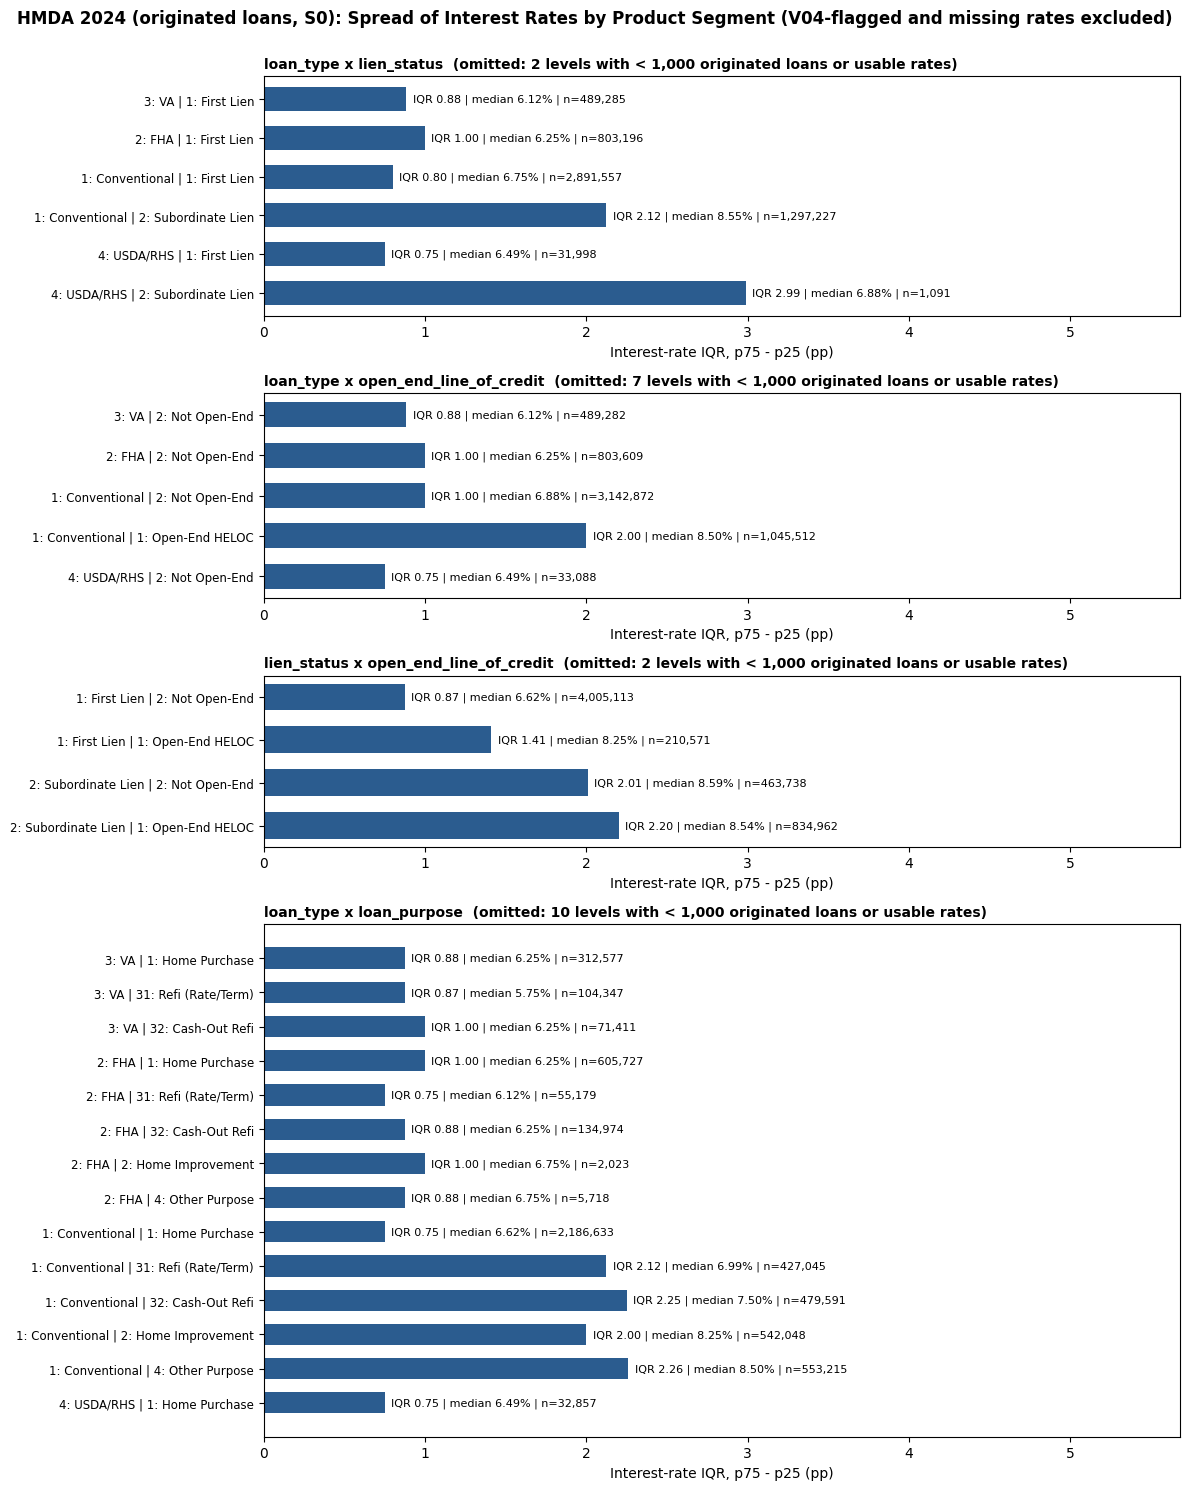

In [27]:
# Step 1: Use exact n_rate_usable and low_n_rate from seg_table (Decision D-AC)
d = seg_all.copy()
d["plot_ok"] = (~d["low_n_rate"]) & d["rate_iqr"].notna()                        # [CHANGE: D-AC]

# Step 2: One panel per segmentation, height proportional to number of plotted levels
segs = list(d["segment"].unique())
ratios = [max(1, int(d.loc[d["segment"] == s, "plot_ok"].sum())) + 1 for s in segs]
fig, axes = plt.subplots(len(segs), 1, figsize=(12, 1.0 + 0.42 * sum(ratios)), gridspec_kw={"height_ratios": ratios})
xmax = d.loc[d["plot_ok"], "rate_iqr"].max() * 1.9
for ax, s in zip(axes, segs):
    t = d[(d["segment"] == s) & d["plot_ok"]].reset_index(drop=True); y = np.arange(len(t))[::-1]
    ax.barh(y, t["rate_iqr"], color="#2b5c8f", height=0.62)
    ax.set_yticks(y); ax.set_yticklabels(t["level"], fontsize=8.5)
    for yi, r in zip(y, t.itertuples()):
        ax.text(r.rate_iqr + 0.04, yi, f"IQR {r.rate_iqr:.2f} | median {r.rate_median:.2f}% | n={r.n_rate_usable:,}", va="center", fontsize=8)
    n_drop = int(((d["segment"] == s) & ~d["plot_ok"]).sum())
    ax.set_xlim(0, xmax); ax.set_xlabel("Interest-rate IQR, p75 - p25 (pp)")
    ax.set_title(f"{s}  (omitted: {n_drop} levels with < {N_MIN_APPS:,} originated loans or usable rates)", fontsize=10, fontweight="bold", loc="left")
fig.suptitle("HMDA 2024 (originated loans, S0): Spread of Interest Rates by Product Segment (V04-flagged and missing rates excluded)", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_07b_pricing_iqr_by_segment.png"); plt.show()

In [28]:
# Step 1: Attribution of missing cost / unusable rate to open-end status (originated loans)
g = o_seg.groupby("open_end_line_of_credit", observed=True).agg(n_originated=("rate_missing", "size"), n_rate_missing=("rate_missing", "sum"),
                                                                n_rate_v04=("rate_v04", "sum"), n_cost_valid=("cost_valid", "sum"))
g["n_cost_missing"] = g["n_originated"] - g["n_cost_valid"]
assert int(g["n_originated"].sum()) == len(o_seg)
g["share_of_all_cost_missing_pct"] = g["n_cost_missing"] * 100.0 / g["n_cost_missing"].sum()
g["share_of_all_rate_unusable_pct"] = (g["n_rate_missing"] + g["n_rate_v04"]) * 100.0 / (g["n_rate_missing"] + g["n_rate_v04"]).sum()
save_and_log(g.reset_index(), "B14_pricing_missing_attribution.csv"); display(g.round(2))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_pricing_missing_attribution.csv | Size: 0.39 KB | Shape: (3, 8)


,n_originated,n_rate_missing,n_rate_v04,n_cost_valid,n_cost_missing,share_of_all_cost_missing_pct,share_of_all_rate_unusable_pct
open_end_line_of_credit,,,,,,,
2: Not Open-End,4530046,10928,50267,4352349,177697,12.3300,21.9500
1: Open-End HELOC,1055749,2165,8051,0,1055749,73.2600,3.6600
1111: Exempt,207802,207402,0,100,207702,14.4100,74.3900


### Interpretation — Step B4b (`B14_pricing_by_segment.csv`, Fig 07b)
*Figures are read from the saved table (as of run 2026-11-10, B14 B4b).*
1. **What pattern is observed?**
   - Rate spread depends on lien and line type: IQR is 0.87 pp for first-lien closed-end loans, 1.41 pp for first-lien open-end, 2.01 pp for subordinate closed-end and 2.20 pp for subordinate open-end. Conventional first liens (IQR 0.80) are as narrow as FHA (1.00), VA (0.88) and USDA (0.75).
   - Unusable rates: rate-zero loans (V04) are concentrated in subordinate closed-end loans (9.42%) and are rare in open-end loans (0.77%). Most unusable conventional rates are `Exempt` (open-end code 1111): 99.80% of that segment has no rate, and it is 75% of all unusable conventional rates. USDA subordinate liens have 71.71% missing rates.
   - `total_loan_costs` is missing on 100% of open-end loans. Missing costs split as: open-end 73.3%, exempt 14.4%, closed-end 12.3% (as of run 2026-11-10, B14 pricing attribution cell).
   - Zero costs are product-specific: 39.51% of valid costs are 0 in subordinate closed-end loans, 47.69% in conventional home improvement, vs 1.66% in first-lien closed-end and 0.10% in FHA.
   - FHA median cost is above conventional for every purpose (home purchase 11,419 vs 5,509 USD); VA cash-out (12,362) equals FHA.
2. **What evidence supports the finding?** `B14_pricing_by_segment.csv`, `B14_pricing_missing_attribution.csv`, Fig 07b.
3. **Why might it matter in mortgage lending?** The wide conventional rate range is a mix of products, not one price distribution. Pricing comparisons by race must be within lien x line x loan type (D8). Missing costs are mostly structural (open-end, exempt), so they are not random missingness.
4. **What alternative explanations or limitations apply?**
   - Why FHA costs are high `[Hypothesis: upfront mortgage-insurance or product-specific fees]`; why USDA subordinate liens lack rates and costs is unexplained `[Hypothesis: distinct program]`.
   - Zero costs could still reflect lender reporting within a segment; no lender cut is run here.
   - Loan type x purpose does not separate lien and open-end, so part of the wider conventional refinance IQR may be mix.
   - Segments with fewer than 1,000 originated loans (`low_n`) or fewer than 1,000 usable rates are not interpreted.

### Step B6 & B7: Outliers vs. Rule Violations (V01–V09) and Duplicate Records Profile (V10) (`eda_plan.md` §5, B6–B7)

- **Input:** `df_s0` validity flags (`flag_loan_amount_invalid`, `flag_income_nonpositive`, `flag_income_zero`, `flag_income_negative`, `flag_cltv_range`, `flag_rate_range`, `flag_term_range`, `profile_cltv_discrepancy`), S4 winsorization thresholds (`B06_WINSOR`), and duplicate columns (`flag_dup_extra`, `dup_group_size`).
- **Process:**
  - **Step B6 (Outliers vs. Errors):** Contrast rule-violation flags (V01–V05) against genuine large-value tail observations (> S4 `p99` in `loan_amount`, `income`, `property_value`, `combined_loan_to_value_ratio`). Compute application count, share of $S0$, denial rate, and minority share (`Black` and `White` shares) for each flag to show why **Decision D-B** and **D-C** keep V02/V04 in $S0$ and test V02 via $S5$: V02 (`income <= 0`) has a $>60\%$ denial rate ($95.51\%$ for negative income, `[Verified: Decision D-B]`), whereas V04 (`interest_rate <= 0`) is $0.00\%$ denied (`[Verified: Decision D-C]`).
  - **Step B7 (Duplicates Profile):** Tabulate `dup_group_size == 1` (unique records), `dup_group_size > 1 & ~flag_dup_extra` (cluster primary rows), and `flag_dup_extra == True` (extra duplicate copies) across $S0$, reporting application counts, denial rates, and race distribution (`B14_duplicate_profile.csv`).
- **Output:** `output/B14_outlier_flag_profile.csv` and `output/B14_duplicate_profile.csv`.

In [29]:
# Step 1: Step B6 — Profile V01-V05 rule flags vs genuine >p99 tail observations on S0
FLAG_SPECS = [
    ("V01: flag_loan_amount_invalid (<=0)", df_s0["flag_loan_amount_invalid"], "Rule Violation Flag"),
    ("V02: flag_income_nonpositive (<=0)", df_s0["flag_income_nonpositive"], "Rule Violation Flag"),
    ("V02a: flag_income_zero (==0)", df_s0["flag_income_zero"], "Rule Violation Sub-flag"),
    ("V02b: flag_income_negative (<0)", df_s0["flag_income_negative"], "Rule Violation Sub-flag"),
    ("V03: flag_cltv_range (<=0 or >200)", df_s0["flag_cltv_range"], "Rule Violation Flag"),
    ("V04: flag_rate_range (<=0 or >25, originated/appr)", df_s0["flag_rate_range"], "Post-Decision Rate Flag"),
    ("V05: flag_term_range (<1 or >480)", df_s0["flag_term_range"], "Rule Violation Flag"),
    ("V09: |CLTV - ltv_calc| > 10pp (First Lien)", (df_s0["lien_status"] == "1") & (df_s0["profile_cltv_discrepancy"].abs() > 10), "Diagnostic Discrepancy"),
    (f"S4 Tail: loan_amount > p99 (${B06_WINSOR['loan_amount']['p99']:,.0f})", df_s0["loan_amount"] > B06_WINSOR["loan_amount"]["p99"], "Genuine High Tail (>p99)"),
    (f"S4 Tail: income > p99 (${B06_WINSOR['income']['p99']:,.0f}k)", df_s0["income"] > B06_WINSOR["income"]["p99"], "Genuine High Tail (>p99)"),
    (f"S4 Tail: property_value > p99 (${B06_WINSOR['property_value']['p99']:,.0f})", df_s0["property_value"] > B06_WINSOR["property_value"]["p99"], "Genuine High Tail (>p99)"),
    (f"S4 Tail: CLTV > p99 ({B06_WINSOR['combined_loan_to_value_ratio']['p99']:.2f}%)", df_s0["combined_loan_to_value_ratio"] > B06_WINSOR["combined_loan_to_value_ratio"]["p99"], "Genuine High Tail (>p99)"),
]
out_flag_rows = []
for label, mask, f_type in FLAG_SPECS:
    m = mask.fillna(False)
    n_f = int(m.sum())
    n_d = int((m & (df_s0["is_denied"] == 1)).sum())
    r_black = (df_s0.loc[m, "derived_race"] == "Black or African American").mean() * 100.0 if n_f > 0 else np.nan
    out_flag_rows.append({
        "flag_or_tail": label, "category": f_type, "n_rows_s0": n_f,
        "pct_of_s0": round(n_f * 100.0 / len(df_s0), 4), "n_denied": n_d,
        "denial_rate_pct": round(n_d * 100.0 / n_f, 2) if n_f > 0 else np.nan,
        "pct_black_in_slice": round(float(r_black), 2) if n_f > 0 else np.nan,
    })
outlier_df = pd.DataFrame(out_flag_rows)
save_and_log(outlier_df, "B14_outlier_flag_profile.csv")
display(outlier_df)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_outlier_flag_profile.csv | Size: 1.12 KB | Shape: (12, 7)


,flag_or_tail,category,n_rows_s0,pct_of_s0,n_denied,denial_rate_pct,pct_black_in_slice
0,V01: flag_loan_amount_invalid (<=0),Rule Violation Flag,0,0.0000,0,NaN,NaN
1,V02: flag_income_nonpositive (<=0),Rule Violation Flag,91261,1.1216,55207,60.4900,10.3400
2,V02a: flag_income_zero (==0),Rule Violation Sub-flag,84356,1.0367,48612,57.6300,10.4800
3,V02b: flag_income_negative (<0),Rule Violation Sub-flag,6905,0.0849,6595,95.5100,8.5900
4,V03: flag_cltv_range (<=0 or >200),Rule Violation Flag,4026,0.0495,3896,96.7700,21.8100
5,"V04: flag_rate_range (<=0 or >25, originated/a...",Post-Decision Rate Flag,60717,0.7462,0,0.0000,14.8700
6,V05: flag_term_range (<1 or >480),Rule Violation Flag,18,0.0002,13,72.2200,16.6700
7,V09: |CLTV - ltv_calc| > 10pp (First Lien),Diagnostic Discrepancy,100268,1.2323,35811,35.7200,14.8900
8,"S4 Tail: loan_amount > p99 ($1,325,000)",Genuine High Tail (>p99),80011,0.9833,11168,13.9600,1.9800
9,S4 Tail: income > p99 ($780k),Genuine High Tail (>p99),78067,0.9594,14727,18.8600,3.2700


## B7: Duplicate Profile (Rule V10)

- **Input:** `df_s0` columns `dup_group_size`, `flag_dup_extra`, `is_denied`, `derived_race`; `B06_GOLD`.
- **Process:**
  - V10 hashes all 99 raw columns, so a *duplicate cluster* is a set of rows identical on every raw field. The extra copy is `flag_dup_extra`, the first copy (smallest `row_id`) is the "original".
  - Duplicates were detected on the full raw data, so a cluster can be only partly inside S0. Rows are split into: non-duplicated, originals in clusters, extra copies.
  - For each group: size, share of S0, denial rate with Wilson CI. Also computed: S0 denial rate with vs without extras, race mix per group, cluster-size distribution.
  - Duplicates are **profiled, not removed** (Principle 2, no change beyond the request). Any exclusion would be a robustness variant in G1.
- **Output:** `B14_duplicate_profile.csv`, `B14_duplicate_race_mix.csv`.

In [30]:
# Step 1: Define mutually exclusive duplicate groups on S0
is_cluster, is_extra = df_s0["dup_group_size"] > 1, df_s0["flag_dup_extra"]
dup_groups = [
    ("Non-duplicated rows", ~is_cluster),
    ("Originals in duplicate clusters", is_cluster & ~is_extra),
    ("Extra copies (flag_dup_extra)", is_extra),
]
assert sum(int(m.sum()) for _, m in dup_groups) == len(df_s0), "Duplicate groups do not partition S0"

# Step 2: Size, share and denial rate (Wilson CI) per group
rows = []
for label, m in dup_groups + [("S0 without extra copies", ~is_extra)]:
    n, d = int(m.sum()), int(df_s0.loc[m, "is_denied"].sum())
    lo, hi = wilson_ci(d, n)
    rows.append({"group": label, "n_rows": n, "share_s0_pct": round(n * 100.0 / len(df_s0), 4),
                 "n_denied": d, "denial_rate_pct": round(d * 100.0 / n, 3) if n else np.nan,
                 "wilson_ci_lo": round(float(lo), 3), "wilson_ci_hi": round(float(hi), 3)})
dup_df = pd.DataFrame(rows)
s0_rate = df_s0["is_denied"].mean() * 100.0
dup_df["rate_shift_vs_s0_pp"] = (dup_df["denial_rate_pct"] - s0_rate).round(3)
save_and_log(dup_df, "B14_duplicate_profile.csv")
display(dup_df)

# Step 3: Race mix (column %) per duplicate group + cluster-size distribution
grp = pd.Categorical(np.select([is_extra, is_cluster], ["Extra copies", "Originals in clusters"], "Non-duplicated"))
mix = (pd.crosstab(df_s0["derived_race"], grp, normalize="columns") * 100).round(3).reset_index()
save_and_log(mix, "B14_duplicate_race_mix.csv")
display(mix)
display(df_s0.loc[is_cluster, "dup_group_size"].value_counts().sort_index().rename("n_rows_in_cluster_size").to_frame())

# Step 4: Quick check against B06 (extras in S0 cannot exceed extras in raw)
assert int(is_extra.sum()) <= int(B06_GOLD["v10_extra_copies"]), "More extras in S0 than in raw data"

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_duplicate_profile.csv | Size: 0.39 KB | Shape: (4, 8)


,group,n_rows,share_s0_pct,n_denied,denial_rate_pct,wilson_ci_lo,wilson_ci_hi,rate_shift_vs_s0_pp
0,Non-duplicated rows,8128330,99.8976,1998618,24.5880,24.5590,24.6180,-0.0320
1,Originals in duplicate clusters,3835,0.0471,2261,58.9570,57.3920,60.5040,34.3370
2,Extra copies (flag_dup_extra),4499,0.0553,2397,53.2790,51.8180,54.7330,28.6590
3,S0 without extra copies,8132165,99.9447,2000879,24.6050,24.5750,24.6340,-0.0150


Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_duplicate_race_mix.csv | Size: 0.41 KB | Shape: (9, 4)


col_0,derived_race,Extra copies,Non-duplicated,Originals in clusters
0,Black or African American,10.0020,9.0090,9.3870
1,Race Not Available,40.3200,15.6490,36.9490
2,White,44.3430,65.9030,47.7180
3,Asian,3.3790,5.8830,3.7290
4,Joint,0.8220,2.2690,0.9650
5,American Indian or Alaska Native,0.8670,0.7540,0.9650
6,Native Hawaiian or Other Pacific Islander,0.1330,0.2490,0.1300
7,2 or more minority races,0.1330,0.2570,0.1560
8,Free Form Text Only,0.0000,0.0260,0.0000


,n_rows_in_cluster_size
dup_group_size,
2,6950
3,732
4,232
5,130
6,66
7,21
8,56
9,18
10,30


## B6 (figure): Denial Rate of Flagged Rows vs Genuine Tails

- **Input:** `outlier_df` (cell 48).
- **Process:** Horizontal bars of denial rate per rule flag / p99 tail, with the S0 baseline as a vertical line and `n` in each label. This shows which extremes behave like errors (very high denial rate) and which like genuine large loans.
- **Output:** `B14_fig_09_outlier_flag_denial.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_09_outlier_flag_denial.png | Size: 109.49 KB


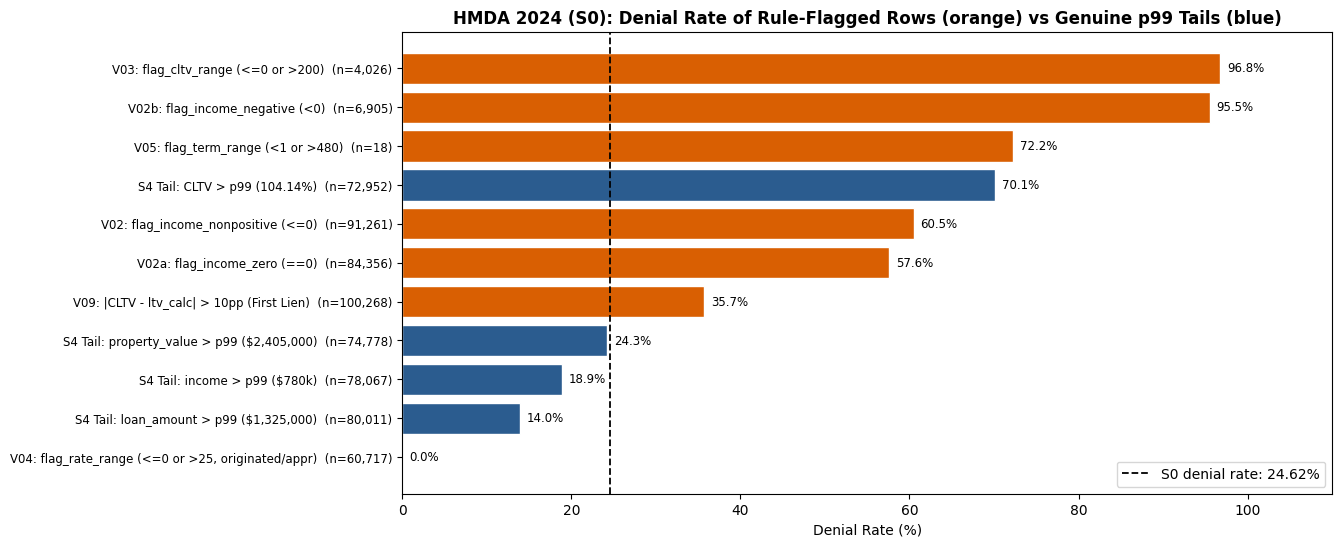

In [31]:
# Step 1: Prepare data (drop empty flags, sort by denial rate)
plot_df = outlier_df.dropna(subset=["denial_rate_pct"]).sort_values("denial_rate_pct")
s0_rate = df_s0["is_denied"].mean() * 100.0
colors = plot_df["category"].map(lambda c: "#d95f02" if "Genuine" not in c else "#2b5c8f")

# Step 2: Plot
fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(plot_df))
ax.barh(y, plot_df["denial_rate_pct"], color=colors, edgecolor="white")
ax.axvline(s0_rate, color="black", linestyle="--", linewidth=1.3, label=f"S0 denial rate: {s0_rate:.2f}%")
ax.set_yticks(y)
ax.set_yticklabels([f"{l}  (n={n:,})" for l, n in zip(plot_df["flag_or_tail"], plot_df["n_rows_s0"])], fontsize=8.5)
for i, v in enumerate(plot_df["denial_rate_pct"]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlim(0, 110); ax.set_xlabel("Denial Rate (%)")
ax.set_title("HMDA 2024 (S0): Denial Rate of Rule-Flagged Rows (orange) vs Genuine p99 Tails (blue)", fontweight="bold")
ax.legend(loc="lower right")
save_fig_and_log(fig, "B14_fig_09_outlier_flag_denial.png")
plt.show()

### Interpretation — Steps B6 & B7 (`B14_outlier_flag_profile.csv`, `B14_duplicate_profile.csv`, `B14_duplicate_race_mix.csv`, Fig 09)

*Figures are read from the saved tables (as of run 2026-11-10, B14 B6 / B7).*

1. **What pattern is observed?**
   - **Rule flags (B6):** V01 flags 0 rows. V02 (income <= 0) flags 91,261 rows (1.12% of S0) with a denial rate of 60.49% (zero income 57.63%, negative income 95.51%). V03 (CLTV <= 0 or > 200) flags 4,026 rows (0.05%) with 96.77% denial. V05 flags 18 rows (72.22% denied). V04 flags 60,717 rows (0.75%) with **0.00%** denial, by construction: a reported interest rate exists only for non-denied loans. V09 (first lien, |CLTV − ltv_calc| > 10 pp) flags 100,268 rows (1.23%) with 35.72% denial.
   - **p99 tails (not rule-flagged):** `loan_amount` > p99 (80,011 rows) has a 13.96% denial rate, `income` > p99 18.86%, `property_value` > p99 24.27%, but CLTV > p99 (72,952 rows) has **70.10%**. Black applicants are 9.01% of S0 but only 1.75–3.27% of the loan, income and value tails, and 16.65% of the CLTV tail (21.81% of V03 rows).
   - **Duplicates (B7):** 8,334 S0 rows (0.10%) belong to a cluster of rows identical on all 99 raw fields: 3,835 originals and 4,499 extra copies. Their denial rate is 58.96% (originals) and 53.28% (extras), against 24.59% for non-duplicated rows. `Race Not Available` is 40.32% of the extras and 36.95% of the originals, against 15.65% of non-duplicated rows; White is 44.34% and 47.72% vs 65.90%. Dropping the extras changes the S0 denial rate from 24.62% to 24.61% (−0.015 pp).
2. **What evidence supports the finding?**
   - `B14_outlier_flag_profile.csv`, `B14_duplicate_profile.csv`, `B14_duplicate_race_mix.csv` (groups partition S0, checked in the code) and `B14_fig_09_outlier_flag_denial.png`.
3. **Why might it matter in mortgage lending?**
   - Rows with income <= 0 or invalid CLTV are almost always denied, so removing them would lower the denial rate and change the sample selectively (Decisions D-B, D-C); they are kept and flagged. Large loans, incomes and values are genuine large applications with lower denial rates, not errors, and are not trimmed.
   - The CLTV tail behaves like a risk signal or a reporting-quality problem rather than a harmless large value `[Hypothesis]`.
4. **What alternative explanations or limitations apply?**
   - Identical rows in public HMDA may be separate applications (no application ID is published) rather than double counting `[Hypothesis]`; their profile (high denial, many `Race Not Available`) suggests sparse, similar files. Their effect on the overall rate is negligible, but they are kept in S0 and tested in G1 (without extras).
   - Flags are profiled here, not removed (Principle 2). Whether a flagged value is an error cannot be verified with public data.

## Checkpoint 2 Gate (eda_plan.md §14, Block 2)

- **Input:** Tables and figures produced in Parts A3–A5 and B1–B7.
- **Process:** Assert that every Part B artifact exists and that key tables reconcile with S0. The leakage audit (A3) is listed for Human review.
- **Output:** `gate2_checks` table; list of columns flagged as leakage.

In [32]:
# Step 1: Gate conditions
need = ["B14_numeric_summary.csv", "B14_categorical_summary.csv", "B14_dti_distribution.csv",
        "B14_outlier_flag_profile.csv", "B14_duplicate_profile.csv", "B14_availability_by_outcome.csv",
        "B14_coverage_by_race.csv", "B14_composition.csv"]
need_figs = [f"B14_fig_0{i}" for i in range(1, 10)]
cat_ok = cat_sum_df.groupby("variable")["n_apps"].sum().eq(len(df_s0)).all()
leak_cols = avail_df.loc[avail_df["leakage_audit_status"] != "PASS: Pre-decision available", "column_name"].tolist()
# [ADD] columns whose role and audit disagree, for Human review
display(avail_df.loc[avail_df["role_audit_conflict"] != "", ["column_name", "role", "role_audit_conflict"]])
fig_names = [p.name for p in FIG_DIR.glob("B14_fig_*.png")]

gate2 = pd.DataFrame([
    ("Gate 2.1: all Part A/B tables saved", all((OUTPUT_DIR / f).exists() for f in need), f"{len(need)} tables"),
    ("Gate 2.2: figures 01-09 saved", all(any(n.startswith(f) for n in fig_names) for f in need_figs), f"{len(fig_names)} figures"),
    ("Gate 2.3: categorical tables sum to S0", bool(cat_ok), f"{cat_sum_df['variable'].nunique()} variables"),
    ("Gate 2.4: duplicate groups partition S0", int(dup_df['n_rows'].iloc[:3].sum()) == len(df_s0), f"{int(dup_df['n_rows'].iloc[2]):,} extra copies in S0"),
    ("Gate 2.5: leakage audit ready for Human review", len(leak_cols) > 0, f"{len(leak_cols)} flagged columns"),
], columns=["checkpoint_2_gate", "passed", "evidence"])
assert gate2["passed"].all(), "Checkpoint 2 gate failed!"
display(gate2)
print("Columns flagged for leakage review:", leak_cols)
print("[CHECKPOINT 2 PASSED] Pending Human review of the roles table. Next: Checkpoint 3 (Part C).")

,column_name,role,role_audit_conflict


,checkpoint_2_gate,passed,evidence
0,Gate 2.1: all Part A/B tables saved,True,8 tables
1,Gate 2.2: figures 01-09 saved,True,10 figures
2,Gate 2.3: categorical tables sum to S0,True,14 variables
3,Gate 2.4: duplicate groups partition S0,True,"4,499 extra copies in S0"
4,Gate 2.5: leakage audit ready for Human review,True,12 flagged columns


Columns flagged for leakage review: ['interest_rate', 'rate_spread', 'origination_charges', 'total_loan_costs', 'discount_points', 'lender_credits', 'denial_reason_2', 'denial_reason_3', 'denial_reason_4', 'purchaser_type', 'denial_reason_1', 'hoepa_status']
[CHECKPOINT 2 PASSED] Pending Human review of the roles table. Next: Checkpoint 3 (Part C).


## B1 (boxplot): Core Financial Variables by Decision Outcome
- **Input:** `df_s0` (`loan_amount`, `property_value`, `income`, `loan_to_income`, `is_denied`).
- **Process:** Box statistics are computed by quantiles on the **full S0** (positive values only), not on a sample. Box = p25–p75, line = median, whiskers = p05–p95. Outliers are not drawn, because the tails were profiled in B6. Log y-axis.
- **Output:** `B14_boxplot_stats.csv`, `B14_fig_10_boxplot_by_outcome.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_boxplot_stats.csv | Size: 0.86 KB | Shape: (12, 8)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_10_boxplot_by_outcome.png | Size: 56.56 KB


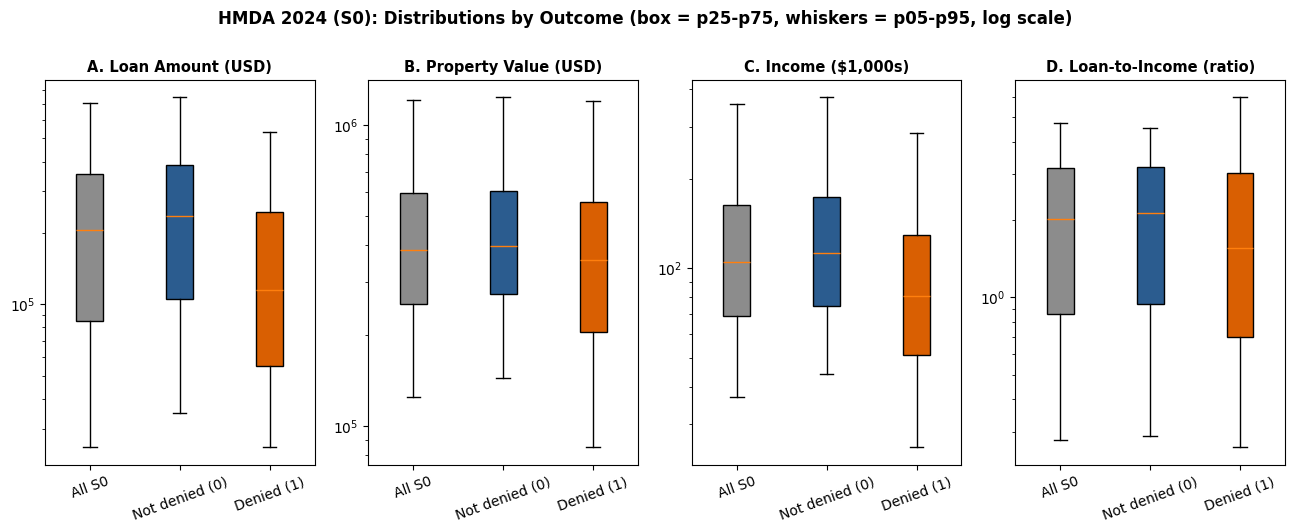

In [33]:
# Step 1: Quantile statistics on full S0 per variable x outcome group
BOX_VARS = [("loan_amount", "A. Loan Amount (USD)"), ("property_value", "B. Property Value (USD)"),
            ("income", "C. Income ($1,000s)"), ("loan_to_income", "D. Loan-to-Income (ratio)")]
BOX_GROUPS = [("All S0", pd.Series(True, index=df_s0.index)), ("Not denied (0)", df_s0["is_denied"] == 0),
              ("Denied (1)", df_s0["is_denied"] == 1)]
rows = []
for col, _ in BOX_VARS:
    for g_label, m in BOX_GROUPS:
        v = df_s0.loc[m, col].dropna().astype("float64"); v = v[v > 0]
        p05, q1, med, q3, p95 = np.quantile(v, [0.05, 0.25, 0.5, 0.75, 0.95])
        rows.append({"variable": col, "group": g_label, "n_valid_positive": len(v),
                     "p05": p05, "q1": q1, "median": med, "q3": q3, "p95": p95})
box_df = pd.DataFrame(rows)
save_and_log(box_df.round(3), "B14_boxplot_stats.csv")

# Step 2: Draw boxes from precomputed statistics (ax.bxp)
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for (col, title), ax in zip(BOX_VARS, axes):
    sub = box_df[box_df["variable"] == col]
    stats = [{"label": r.group, "whislo": r.p05, "q1": r.q1, "med": r.median, "q3": r.q3, "whishi": r.p95, "fliers": []}
             for r in sub.itertuples()]
    bp = ax.bxp(stats, showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], ["#8c8c8c", "#2b5c8f", "#d95f02"]):
        patch.set_facecolor(c)
    ax.set_yscale("log"); ax.set_title(title, fontsize=10.5, fontweight="bold"); ax.tick_params(axis="x", labelrotation=20)
fig.suptitle("HMDA 2024 (S0): Distributions by Outcome (box = p25-p75, whiskers = p05-p95, log scale)", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_10_boxplot_by_outcome.png")
plt.show()

## C0: Part C Helpers and Constants
- **Input:** `df_s0`, `wilson_ci`, constants from the config cell.
- **Process:**
  - `agg_counts(keys)` groups S0 by the given columns and returns `n_apps` and `n_denied`. Levels are converted to strings and NULL becomes "NULL / Missing". It asserts that the counts sum to S0, which also catches the known pandas pitfall of `observed`/`dropna` on categoricals (plan risk 9).
  - `rate_gap_table` adds the denial rate, Wilson CI, gap vs the reference in pp, risk ratio, odds ratio and a log-OR (Woolf) CI. The Woolf CI assumes i.i.d. rows, so it is *naive*. The lender-cluster CI is added in C1b.
  - Odds ratio = odds(denied) of the group divided by odds(denied) of the reference. Woolf CI = exp(log OR ± 1.96·SE), SE = sqrt(1/d₁ + 1/(n₁−d₁) + 1/d₀ + 1/(n₀−d₀)).
  - Binning constants (loan-amount buckets) are declared here once.
- **Output:** helper functions, `HEADLINE_RACES` (set in C1a), bucket constants.

In [34]:
# Step 1: Constants for Part C (config-style, declared once)
AMT_BINS = [-np.inf, 1e5, 2e5, 3e5, 5e5, 7.5e5, 1e6, np.inf]
AMT_LABELS = ["<100k", "100-200k", "200-300k", "300-500k", "500-750k", "750k-1M", ">=1M"]
UNINFO_PATTERN = "not available|free form|missing|not provided"
df_s0["loan_amount_bucket"] = pd.cut(df_s0["loan_amount"], AMT_BINS, labels=AMT_LABELS, right=False)

# Step 2: Aggregation helper with row-sum check
def agg_counts(keys):
    """Group S0 by `keys`; return n_apps / n_denied with string levels. Asserts counts add up to S0."""
    g = df_s0.groupby(keys, observed=True, dropna=False)["is_denied"].agg(n_apps="count", n_denied="sum").reset_index()
    for k in keys:
        g[k] = g[k].astype("string").fillna("NULL / Missing")
    g["n_denied"] = g["n_denied"].astype("int64")
    assert int(g["n_apps"].sum()) == len(df_s0), f"Row-sum mismatch for {keys}"
    return g

# Step 3: Gap table helper
def rate_gap_table(agg, level_col, ref_level):
    """Denial rate, Wilson CI, gap vs reference (pp), risk ratio, odds ratio with Woolf CI, low_n flag (D-M)."""
    t = agg.copy()
    n, d = t["n_apps"].astype("float64"), t["n_denied"].astype("float64")
    ref = t.loc[t[level_col] == ref_level].iloc[0]
    rn, rd = float(ref["n_apps"]), float(ref["n_denied"])
    with np.errstate(all="ignore"):
        t["denial_rate_pct"] = d * 100.0 / n
        t["wilson_ci_lo"], t["wilson_ci_hi"] = wilson_ci(d, n)
        t["gap_pp"] = t["denial_rate_pct"] - rd * 100.0 / rn
        t["risk_ratio"] = (d / n) / (rd / rn)
        t["odds_ratio"] = (d / (n - d)) / (rd / (rn - rd))
        se = np.sqrt(1 / d + 1 / (n - d) + 1 / rd + 1 / (rn - rd))
        t["or_ci_lo"], t["or_ci_hi"] = np.exp(np.log(t["odds_ratio"]) - 1.96 * se), np.exp(np.log(t["odds_ratio"]) + 1.96 * se)
    t["low_n"] = (n < N_MIN_APPS) | (d < N_MIN_DENIED)
    t["is_reference"] = t[level_col] == ref_level
    return t

## C1a: Raw Denial Gap by Race (RQ1)
- **Input:** `df_s0`, reference `White` (D-J).
- **Process:** Denial rate, Wilson CI, gap (pp), risk ratio and odds ratio for all 9 `derived_race` groups. `Race Not Available` and `Free Form Text Only` stay in the table but are flagged `headline = False` (D-L). Check: counts sum to S0.
- **Output:** `C1` table (saved in C1b after the cluster CI is added).

In [35]:
# Step 1: Aggregate and compute gaps
race_agg = agg_counts(["derived_race"]).sort_values("n_apps", ascending=False).reset_index(drop=True)
assert REF_RACE in set(race_agg["derived_race"]), "Reference race not found"
C1 = rate_gap_table(race_agg, "derived_race", REF_RACE)
HEADLINE_RACES = [r for r in C1["derived_race"] if r not in UNINFORMATIVE_RACES]   # includes the reference
C1["headline"] = C1["derived_race"].isin(HEADLINE_RACES)

# Step 2: Quick checks and display
assert int(C1["n_apps"].sum()) == len(df_s0)
assert C1["denial_rate_pct"].between(0, 100).all()
display(C1[["derived_race", "n_apps", "n_denied", "denial_rate_pct", "wilson_ci_lo", "wilson_ci_hi",
            "gap_pp", "risk_ratio", "odds_ratio", "or_ci_lo", "or_ci_hi", "low_n", "headline"]])

,derived_race,n_apps,n_denied,denial_rate_pct,wilson_ci_lo,wilson_ci_hi,gap_pp,risk_ratio,odds_ratio,or_ci_lo,or_ci_hi,low_n,headline
0,White,5360624,1175130,21.9215,21.8865,21.9566,0.0000,1.0000,1.0000,0.9971,1.0029,False,True
1,Race Not Available,1275240,378227,29.6593,29.5801,29.7386,7.7378,1.3530,1.5018,1.4953,1.5083,False,False
2,Black or African American,733103,269758,36.7967,36.6864,36.9072,14.8752,1.6786,2.0736,2.0629,2.0844,False,True
3,Asian,478497,104150,21.7661,21.6494,21.8832,-0.1554,0.9929,0.9909,0.9839,0.9981,False,True
4,Joint,184536,36138,19.5832,19.4027,19.7649,-2.3383,0.8933,0.8674,0.8573,0.8775,False,True
5,American Indian or Alaska Native,61397,22787,37.1142,36.7329,37.4971,15.1927,1.6930,2.1021,2.0677,2.1370,False,True
6,2 or more minority races,20920,7988,38.1836,37.5274,38.8440,16.2620,1.7418,2.2001,2.1394,2.2625,False,True
7,Native Hawaiian or Other Pacific Islander,20249,7874,38.8859,38.2166,39.5594,16.9644,1.7739,2.2663,2.2030,2.3314,False,True
8,Free Form Text Only,2098,1224,58.3413,56.2184,60.4337,36.4198,2.6614,4.9880,4.5732,5.4405,False,False


## C1b: Lender-Cluster Bootstrap for Headline Gaps (Decision D-Q)
- **Input:** `df_s0["lei"]`, `derived_race`, `is_denied`; `C1`.
- **Process:**
  - **Why:** applications of one lender share underwriting policy, so rows are not i.i.d. and the naive CI is too narrow.
  - **Pre-aggregation:** `pd.factorize` turns each LEI into an integer code (a lender ID with no name). Counts are aggregated to a lender × race table `LENDER_RACE` (reused in Part F).
  - **Resampling:** each of B = `BOOT_B` replicates draws lenders with replacement (a multinomial weight vector), re-sums applications and denials per race, and recomputes gap (pp) and odds ratio vs White. The weighted sums are matrix products, so no row-level resampling is needed.
  - **CI:** the 2.5th and 97.5th percentiles of the replicates. Only headline races are bootstrapped (D-L). `cluster_vs_naive_or_ci_width` shows how much wider the cluster CI is than the Woolf CI.
- **Output:** `B14_rq1_raw_gap.csv`; `LENDER_RACE` and `df_s0["lender_code"]` in memory. No LEI is exported (D-O).

In [36]:
# Step 1: Pre-aggregate lender x race counts (integer lender codes only)
codes, _ = pd.factorize(df_s0["lei"])
assert (codes >= 0).all(), "NULL lei found in S0"
df_s0["lender_code"] = codes.astype("int32")
LENDER_RACE = df_s0.groupby(["lender_code", "derived_race"], observed=True)["is_denied"].agg(n="count", d="sum").reset_index()
LENDER_RACE["derived_race"] = LENDER_RACE["derived_race"].astype("string")
LENDER_RACE["d"] = LENDER_RACE["d"].astype("int64")
assert int(LENDER_RACE["n"].sum()) == len(df_s0)

# Step 2: Lender x headline-race matrices
piv = lambda v: (LENDER_RACE.pivot_table(index="lender_code", columns="derived_race", values=v, aggfunc="sum", fill_value=0)
                 .reindex(columns=HEADLINE_RACES, fill_value=0).to_numpy(dtype="float64"))
N_mat, D_mat = piv("n"), piv("d")
L, ref_i = N_mat.shape[0], HEADLINE_RACES.index(REF_RACE)

# Step 3: Bootstrap (seed fixed in config)
rng = np.random.default_rng(SEED)
W = rng.multinomial(L, np.full(L, 1.0 / L), size=BOOT_B).astype("float64")   # (B, L) lender weights
Nb, Db = W @ N_mat, W @ D_mat                                                 # (B, R) totals per race
rate_b = Db / Nb
gap_b = (rate_b - rate_b[:, [ref_i]]) * 100.0
odds_b = Db / (Nb - Db)
or_b = odds_b / odds_b[:, [ref_i]]
gci, oci = np.percentile(gap_b, [2.5, 97.5], axis=0), np.percentile(or_b, [2.5, 97.5], axis=0)

# Step 4: Merge into C1, check and save
boot = pd.DataFrame({"derived_race": HEADLINE_RACES, "boot_gap_ci_lo": gci[0], "boot_gap_ci_hi": gci[1],
                     "boot_or_ci_lo": oci[0], "boot_or_ci_hi": oci[1]})
C1 = C1.drop(columns=[c for c in boot.columns if c != "derived_race" and c in C1.columns]).merge(boot, on="derived_race", how="left")
C1["cluster_vs_naive_or_ci_width"] = (C1["boot_or_ci_hi"] - C1["boot_or_ci_lo"]) / (C1["or_ci_hi"] - C1["or_ci_lo"])
print(f"Lenders: {L:,} | replicates: {BOOT_B:,} | seed: {SEED}")
save_and_log(C1, "B14_rq1_raw_gap.csv")
display(C1.loc[C1["headline"] & ~C1["is_reference"], ["derived_race", "gap_pp", "boot_gap_ci_lo", "boot_gap_ci_hi",
                                                       "odds_ratio", "boot_or_ci_lo", "boot_or_ci_hi", "cluster_vs_naive_or_ci_width"]])

Lenders: 4,808 | replicates: 1,000 | seed: 42
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_raw_gap.csv | Size: 2.52 KB | Shape: (9, 19)


,derived_race,gap_pp,boot_gap_ci_lo,boot_gap_ci_hi,odds_ratio,boot_or_ci_lo,boot_or_ci_hi,cluster_vs_naive_or_ci_width
2,Black or African American,14.8752,12.9446,16.9902,2.0736,1.9374,2.2357,13.9105
3,Asian,-0.1554,-2.5136,1.9001,0.9909,0.8610,1.1114,17.6365
4,Joint,-2.3383,-3.2982,-1.2834,0.8674,0.8135,0.9265,5.5815
5,American Indian or Alaska Native,15.1927,11.9494,18.5109,2.1021,1.8830,2.3338,6.4986
6,2 or more minority races,16.2620,12.4693,19.6955,2.2001,1.9341,2.4744,4.3900
7,Native Hawaiian or Other Pacific Islander,16.9644,14.1647,20.0569,2.2663,2.0571,2.5607,3.9215


## C1c: Figure — Denial Rates and Gaps vs White
- **Input:** `C1`.
- **Process:** Panel A shows denial rate with Wilson 95% CI for all 9 groups (uninformative groups in grey). Panel B shows the gap vs White in pp with the lender-cluster 95% CI, for headline groups only (D-L).
- **Output:** `B14_fig_11_raw_gap_forest.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_11_raw_gap_forest.png | Size: 119.72 KB


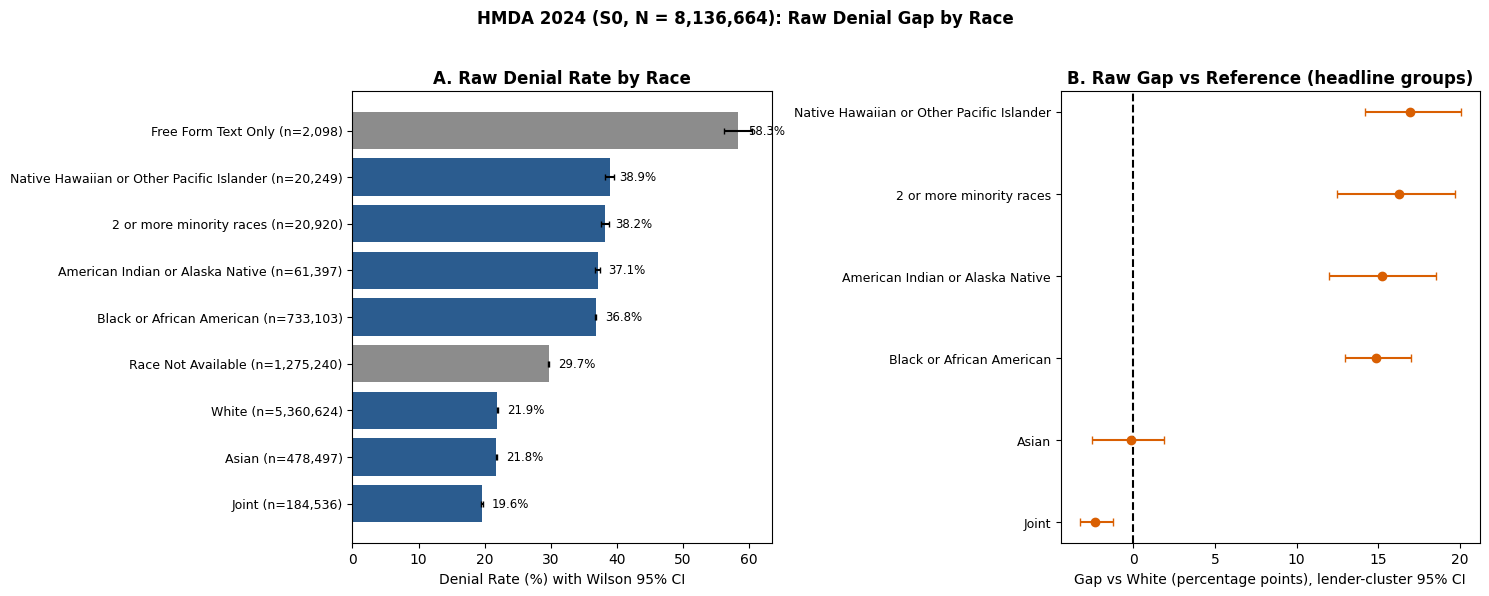

In [37]:
# Step 1: Panel A (all groups) and Panel B (headline gaps)
pa_ = C1.sort_values("denial_rate_pct").reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))
y = np.arange(len(pa_))
ax1.barh(y, pa_["denial_rate_pct"], color=np.where(pa_["derived_race"].isin(UNINFORMATIVE_RACES), "#8c8c8c", "#2b5c8f"),
         xerr=[(pa_["denial_rate_pct"] - pa_["wilson_ci_lo"]).to_numpy(), (pa_["wilson_ci_hi"] - pa_["denial_rate_pct"]).to_numpy()],
         ecolor="black", capsize=2)
ax1.set_yticks(y); ax1.set_yticklabels([f"{r} (n={n:,})" for r, n in zip(pa_["derived_race"], pa_["n_apps"])], fontsize=9)
for i, v in enumerate(pa_["denial_rate_pct"]):
    ax1.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax1.set_xlabel("Denial Rate (%) with Wilson 95% CI"); ax1.set_title("A. Raw Denial Rate by Race", fontweight="bold")

g = C1[C1["headline"] & ~C1["is_reference"]].sort_values("gap_pp").reset_index(drop=True)
y2 = np.arange(len(g))
ax2.errorbar(g["gap_pp"], y2, xerr=[(g["gap_pp"] - g["boot_gap_ci_lo"]).to_numpy(), (g["boot_gap_ci_hi"] - g["gap_pp"]).to_numpy()],
             fmt="o", color="#d95f02", capsize=3)
ax2.axvline(0, color="black", linestyle="--"); ax2.set_yticks(y2); ax2.set_yticklabels(g["derived_race"], fontsize=9)
ax2.set_xlabel(f"Gap vs {REF_RACE} (percentage points), lender-cluster 95% CI"); ax2.set_title("B. Raw Gap vs Reference (headline groups)", fontweight="bold")
fig.suptitle(f"HMDA 2024 (S0, N = {len(df_s0):,}): Raw Denial Gap by Race", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_11_raw_gap_forest.png"); plt.show()

## C2: Gap by Ethnicity, Sex, Age, Co-applicant and Race-Ethnicity
- **Input:** `df_s0`, `agg_counts`, `rate_gap_table`.
- **Process:** Same template as C1a for 5 dimensions. Reference: `Non-Hispanic White` for `race_ethnicity` (D-K). For the other dimensions, the reference is the **largest informative level** (levels matching "not available / free form / missing / not provided" are never the reference). `[Hypothesis]` This rule is proposed as D-T.
- **Output:** `B14_rq1_gap_other_dims.csv`.

In [38]:
# Step 1: Reference rule and loop over dimensions
DIM_REF = {"race_ethnicity": "Non-Hispanic White"}
def pick_ref(t, col):
    ok = t[~t[col].str.lower().str.contains(UNINFO_PATTERN)]
    return ok.sort_values("n_apps").iloc[-1][col]

parts = []
for dim in ["race_ethnicity", "derived_ethnicity", "derived_sex", "applicant_age", "has_coapplicant"]:
    a = agg_counts([dim])
    ref = DIM_REF.get(dim) or pick_ref(a, dim)
    t = rate_gap_table(a, dim, ref).rename(columns={dim: "level"})
    t.insert(0, "dimension", dim); t.insert(1, "reference_level", ref)
    parts.append(t)
    print(f"{dim}: reference = {ref}")

# Step 2: Save
# Step 2: Enforce D-T (applicant_age reported as profile only, no gap columns) and save
C2 = pd.concat(parts, ignore_index=True)
GAP_COLS = ["reference_level", "gap_pp", "risk_ratio", "odds_ratio", "or_ci_lo", "or_ci_hi"]
C2.loc[C2["dimension"] == "applicant_age", GAP_COLS] = np.nan                    # [ADD: D-T compliance]
C2.loc[C2["dimension"] == "applicant_age", "is_reference"] = False               # [ADD: D-T compliance]
save_and_log(C2, "B14_rq1_gap_other_dims.csv")
display(C2[["dimension", "level", "n_apps", "denial_rate_pct", "gap_pp", "odds_ratio", "or_ci_lo", "or_ci_hi", "low_n"]])

race_ethnicity: reference = Non-Hispanic White
derived_ethnicity: reference = Not Hispanic or Latino
derived_sex: reference = Joint
applicant_age: reference = 35-44
has_coapplicant: reference = 0
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_gap_other_dims.csv | Size: 4.50 KB | Shape: (25, 15)


,dimension,level,n_apps,denial_rate_pct,gap_pp,odds_ratio,or_ci_lo,or_ci_hi,low_n
0,race_ethnicity,Hispanic or Latino (Any Race),1006680,30.7227,10.0075,1.6973,1.6892,1.7056,False
1,race_ethnicity,Non-Hispanic Asian,435855,21.0102,0.2951,1.0180,1.0103,1.0258,False
2,race_ethnicity,Non-Hispanic Black,654584,36.2157,15.5005,2.1731,2.1611,2.1852,False
3,race_ethnicity,Non-Hispanic White,4328834,20.7151,0.0000,1.0000,0.9967,1.0033,False
4,race_ethnicity,Other / Not Available,1710711,27.3943,6.6791,1.4441,1.4382,1.4500,False
5,derived_ethnicity,Hispanic or Latino,1006680,30.7227,7.9258,1.5019,1.4949,1.5089,False
6,derived_ethnicity,Ethnicity Not Available,1164905,28.9861,6.1892,1.3823,1.3762,1.3885,False
7,derived_ethnicity,Not Hispanic or Latino,5743431,22.7968,0.0000,1.0000,0.9972,1.0028,False
8,derived_ethnicity,Joint,218234,20.7892,-2.0077,0.8888,0.8795,0.8982,False
9,derived_ethnicity,Free Form Text Only,3414,48.2718,25.4750,3.1603,2.9550,3.3798,False


### Interpretation — Steps C1 & C2 (`B14_rq1_raw_gap.csv`, `B14_rq1_gap_other_dims.csv`, Fig 11)
*Figures are read from the saved tables (as of run 2026-11-10, B14 C1 / C2).*
1. **What pattern is observed?**
   - Against White (21.92% denied), the raw gap is +14.88 pp for Black (36.80%, OR 2.07, lender-cluster 95% CI 12.94 to 16.99 pp), +15.19 pp for American Indian or Alaska Native, +16.26 pp for 2+ minority races and +16.96 pp for Native Hawaiian or Other Pacific Islander (CIs 11.95–18.51, 12.47–19.70, 14.16–20.06). The four intervals overlap, so their ordering is not supported.
   - Asian is -0.16 pp (CI -2.51 to 1.90, includes 0); Joint is -2.34 pp (CI -3.30 to -1.28).
   - The cluster OR interval is 13.9 times wider than the naive one for Black and 17.6 times for Asian.
   - Race Not Available is +7.74 pp and Free Form Text Only 58.34% (n = 2,098); both are shown but not headline (D-L).
   - With ethnicity: Hispanic or Latino (any race) is +10.01 pp vs Non-Hispanic White (20.72%); Non-Hispanic Black +15.50 pp; Non-Hispanic Asian +0.30 pp.
   - Applications with a co-applicant are denied 19.10% vs 28.66% without (-9.56 pp). Against Joint, Male is +8.26 pp and Female +11.15 pp.
2. **What evidence supports the finding?** `B14_rq1_raw_gap.csv`, `B14_rq1_gap_other_dims.csv`, `B14_fig_11_raw_gap_forest.png`.
3. **Why might it matter in mortgage lending?** The raw gap is the starting point of the decomposition; its size (about 15 pp for four groups) leaves a lot to explain. Ethnicity adds a distinct group: the Hispanic gap is 10.01 pp against Non-Hispanic White but 7.93 pp against all Not Hispanic applicants.
4. **What alternative explanations or limitations apply?**
   - Naive intervals are far too narrow; only the cluster intervals are used for headline claims (D-Q).
   - The sex gaps use Joint as reference, which is a co-applicant category, so they mix sex with co-applicant presence. Sex, age and co-applicant presence are correlated with race.
   - An Asian gap near 0 is not evidence of no disparity (see C4, C5).
   - Race Not Available is a mixture (D-L). Credit score, assets and AUS results are unobserved, and a gap is not evidence of discrimination.

## C3: Product Mix by Race
- **Input:** `df_s0`; product variables plus `loan_amount_bucket` (C0).
- **Process:** For each product variable, share of each race group's applications falling in each level (shares sum to 100% within race), plus the denial rate of that cell. Checks: counts add up to S0 and race totals equal C1.
- **Output:** `B14_rq1_mix_by_race.csv`, `B14_fig_12_mix_heatmap.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_mix_by_race.csv | Size: 23.34 KB | Shape: (260, 7)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_12_mix_heatmap.png | Size: 345.65 KB


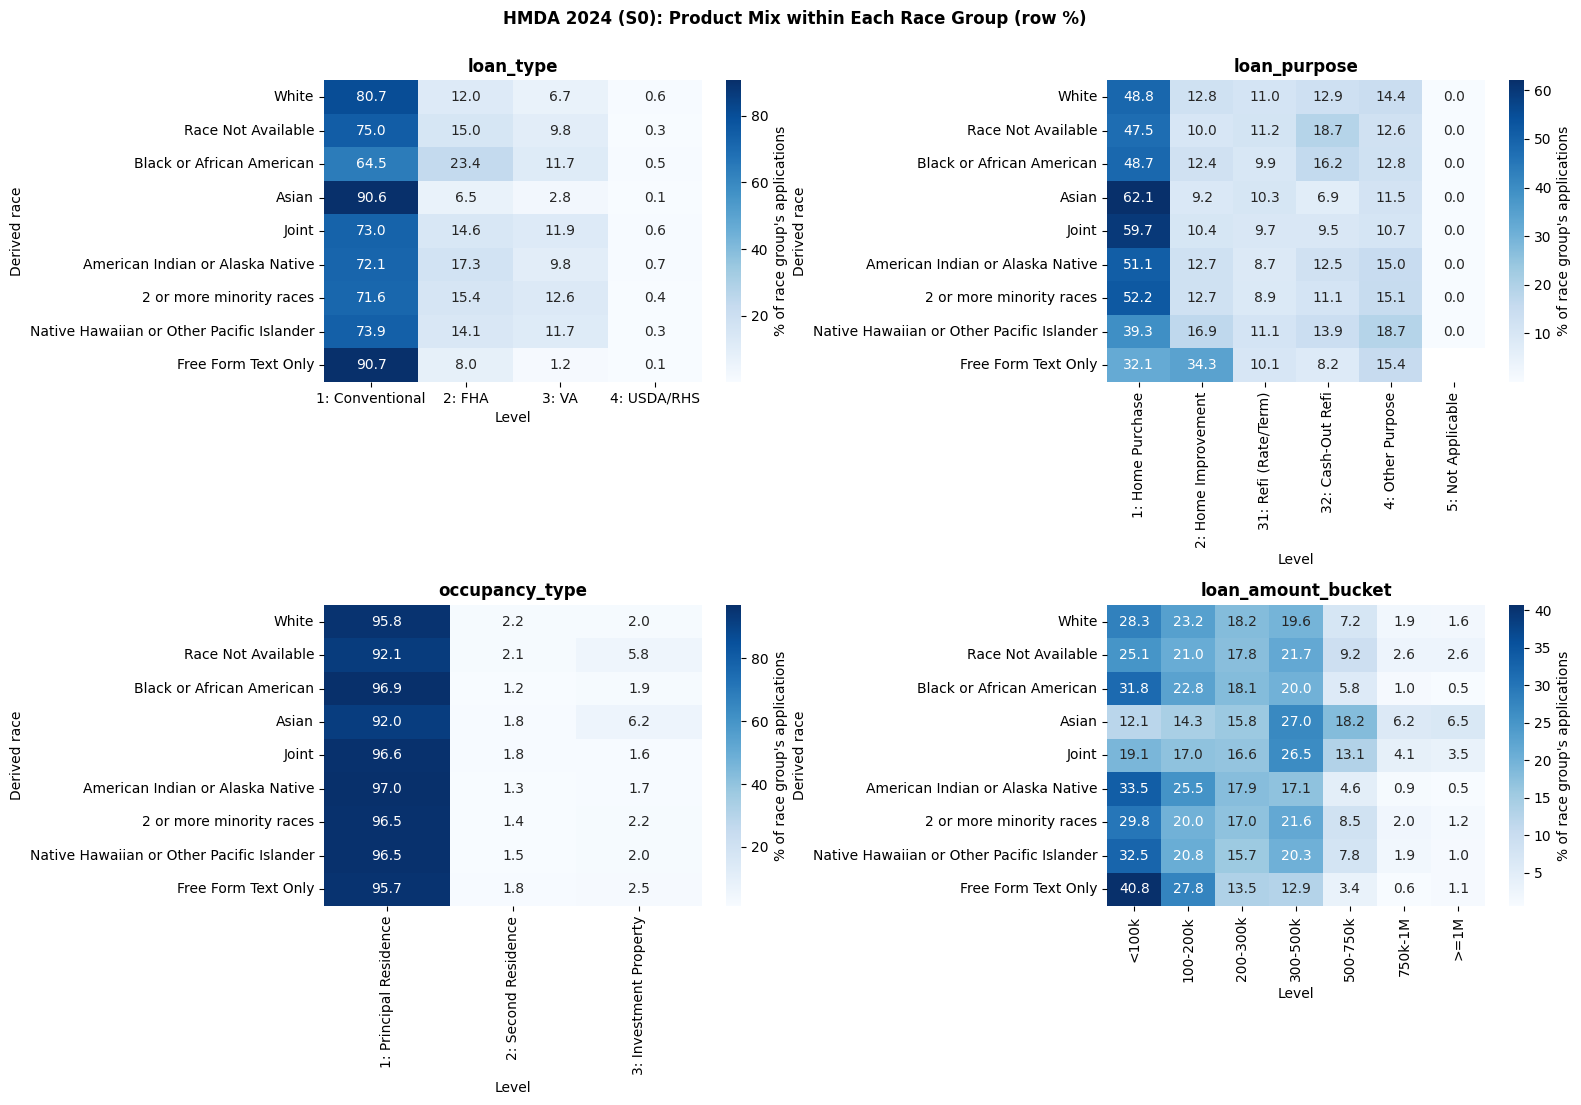

In [39]:
# Step 1: Row-normalised mix tables
MIX_VARS = ["loan_type", "loan_purpose", "lien_status", "occupancy_type", "derived_dwelling_category",
            "conforming_loan_limit", "loan_amount_bucket"]
race_n = C1.set_index("derived_race")["n_apps"].to_dict()
parts = []
for var in MIX_VARS:
    a = agg_counts(["derived_race", var]).rename(columns={var: "level"})
    assert a.groupby("derived_race")["n_apps"].sum().to_dict() == race_n, f"Race totals differ from C1 for {var}"
    a["variable"] = var
    a["share_within_race_pct"] = a["n_apps"] * 100.0 / a["derived_race"].map(race_n).astype("float64")
    a["denial_rate_pct"] = a["n_denied"] * 100.0 / a["n_apps"]
    parts.append(a)
MIX_DF = pd.concat(parts, ignore_index=True)
save_and_log(MIX_DF, "B14_rq1_mix_by_race.csv")

# Step 2: 2x2 heatmap of the key mixes
race_order = C1["derived_race"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for var, ax in zip(["loan_type", "loan_purpose", "occupancy_type", "loan_amount_bucket"], axes.ravel()):
    pv = MIX_DF[MIX_DF["variable"] == var].pivot(index="derived_race", columns="level", values="share_within_race_pct").reindex(race_order)
    cols = [c for c in AMT_LABELS if c in pv.columns] if var == "loan_amount_bucket" else sorted(pv.columns)
    pv = pv[cols].astype("float64"); pv.columns = [CAT_LABELS.get(var, {}).get(c, c) for c in pv.columns]
    sns.heatmap(pv, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "% of race group's applications"})
    ax.set_title(var, fontweight="bold"); ax.set_xlabel("Level"); ax.set_ylabel("Derived race")
fig.suptitle("HMDA 2024 (S0): Product Mix within Each Race Group (row %)", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_12_mix_heatmap.png"); plt.show()

## C4: Stratified Gap within loan_purpose × loan_type (Simpson-type check)
- **Input:** `df_s0`, `C1`, reference White.
- **Process:**
  - For each headline minority group and each stratum, compute the gap vs White in pp. The CI is Newcombe's hybrid, which combines the two Wilson intervals. The odds ratio has a Woolf CI.
  - A stratum is `low_n` if either cell fails D-M.
  - `sign_differs_from_raw` is true where the stratum gap has the opposite sign from the raw gap (C1) and the stratum is not `low_n`.
  - The sign check shows whether the raw gap is consistent across products or is partly a product-mix artefact.
- **Output:** `B14_rq1_stratified_gap.csv`, `B14_fig_13_stratified_gap.png`.

In [40]:
# Step 1: Counts by race x stratum, joined to the reference
STRATA_C4 = ["loan_purpose", "loan_type"]
st4 = agg_counts(["derived_race"] + STRATA_C4)
ref4 = st4[st4["derived_race"] == REF_RACE].set_index(STRATA_C4)
raw_gap = C1.set_index("derived_race")["gap_pp"]

# Step 2: Gap, Newcombe CI and OR CI per group x stratum
parts = []
for grp in [r for r in HEADLINE_RACES if r != REF_RACE]:
    j = st4[st4["derived_race"] == grp].set_index(STRATA_C4).join(ref4, lsuffix="_g", rsuffix="_ref", how="inner")
    n1, d1, n0, d0 = (j[c].astype("float64") for c in ("n_apps_g", "n_denied_g", "n_apps_ref", "n_denied_ref"))
    l1, u1 = wilson_ci(d1, n1); l0, u0 = wilson_ci(d0, n0)
    p1, p0 = d1 * 100 / n1, d0 * 100 / n0
    with np.errstate(all="ignore"):
        lor = np.log((d1 / (n1 - d1)) / (d0 / (n0 - d0))); se = np.sqrt(1 / d1 + 1 / (n1 - d1) + 1 / d0 + 1 / (n0 - d0))
    o = pd.DataFrame({"comparison_group": grp, "n_group": n1, "n_ref": n0, "rate_group_pct": p1, "rate_ref_pct": p0, "gap_pp": p1 - p0,
                      "gap_ci_lo": (p1 - p0) - np.sqrt((p1 - l1) ** 2 + (u0 - p0) ** 2),
                      "gap_ci_hi": (p1 - p0) + np.sqrt((u1 - p1) ** 2 + (p0 - l0) ** 2),
                      "odds_ratio": np.exp(lor), "or_ci_lo": np.exp(lor - 1.96 * se), "or_ci_hi": np.exp(lor + 1.96 * se)}, index=j.index)
    o["low_n"] = (n1 < N_MIN_APPS) | (d1 < N_MIN_DENIED) | (n0 < N_MIN_APPS) | (d0 < N_MIN_DENIED)
    o["raw_gap_pp"] = raw_gap[grp]
    o["sign_differs_from_raw"] = (np.sign(o["gap_pp"]) != np.sign(o["raw_gap_pp"])) & ~o["low_n"]
    parts.append(o.reset_index())
C4 = pd.concat(parts, ignore_index=True)
save_and_log(C4, "B14_rq1_stratified_gap.csv")
display(C4.groupby("comparison_group").agg(n_strata=("gap_pp", "size"), n_valid=("low_n", lambda s: int((~s).sum())),
                                           n_sign_differs=("sign_differs_from_raw", "sum")))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_stratified_gap.csv | Size: 23.59 KB | Shape: (113, 16)


,n_strata,n_valid,n_sign_differs
comparison_group,,,
2 or more minority races,18,7,0
American Indian or Alaska Native,18,10,0
Asian,19,11,10
Black or African American,21,13,0
Joint,20,12,7
Native Hawaiian or Other Pacific Islander,17,7,0


**C4 figure — Input:** `C4`. **Process:** Dot plot of the gap in each non-`low_n` stratum with its Newcombe CI, for Black and Asian applicants vs White. The dashed line is the raw gap. **Output:** `B14_fig_13_stratified_gap.png`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_13_stratified_gap.png | Size: 143.61 KB


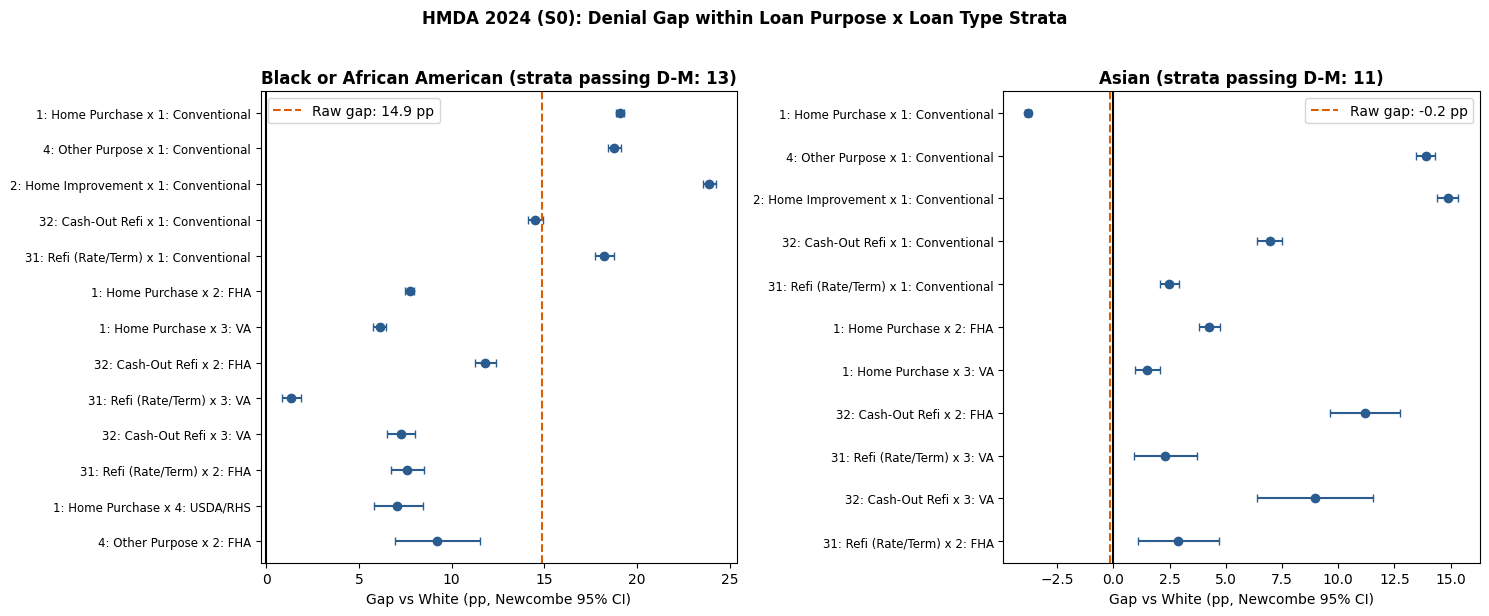

In [41]:
# Step 1: One panel per plotted group
PLOT_GROUPS = ["Black or African American", "Asian"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for grp, ax in zip(PLOT_GROUPS, axes):
    s = C4[(C4["comparison_group"] == grp) & ~C4["low_n"]].sort_values("n_ref").reset_index(drop=True)
    y = np.arange(len(s))
    ax.errorbar(s["gap_pp"], y, xerr=[(s["gap_pp"] - s["gap_ci_lo"]).to_numpy(), (s["gap_ci_hi"] - s["gap_pp"]).to_numpy()], fmt="o", color="#2b5c8f", capsize=3)
    ax.axvline(0, color="black"); ax.axvline(raw_gap[grp], color="#d95f02", linestyle="--", label=f"Raw gap: {raw_gap[grp]:.1f} pp")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{CAT_LABELS['loan_purpose'].get(a, a)} x {CAT_LABELS['loan_type'].get(b, b)}" for a, b in zip(s["loan_purpose"], s["loan_type"])], fontsize=8.5)
    ax.set_xlabel(f"Gap vs {REF_RACE} (pp, Newcombe 95% CI)"); ax.set_title(f"{grp} (strata passing D-M: {len(s)})", fontweight="bold"); ax.legend()
fig.suptitle("HMDA 2024 (S0): Denial Gap within Loan Purpose x Loan Type Strata", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_13_stratified_gap.png"); plt.show()

### Interpretation — Steps C3 & C4 (`B14_rq1_mix_by_race.csv`, `B14_rq1_stratified_gap.csv`, Fig 12–13)
*Figures are read from the saved tables (as of run 2026-11-10, B14 C3 / C4).*
1. **What pattern is observed?**
   - **Mix.** Black applicants use conventional loans less (64.5% vs 80.7% for White) and FHA (23.4% vs 12.0%) and VA (11.7% vs 6.7%) more. Asian applicants are 90.6% conventional, 62.1% home purchase, 6.2% investment property and 30.9% of loans >= 500k (White 10.7%). American Indian or Alaska Native applications are 13.3% manufactured single-family (White 6.1%). Black applicants have more cash-out refinances (16.2% vs 12.9%) and more loans under 100k (31.8% vs 28.3%).
   - **Rates within product.** Conventional denial is 43.5% for Black vs 23.3% for White; FHA 26.8% vs 18.4%; VA 20.2% vs 13.1%.
   - **Stratified gaps (loan purpose x loan type, cells passing D-M).** All 13 valid Black strata are positive (+1.36 to +23.90 pp). The largest are conventional home improvement (+23.90) and conventional purchase (+19.10); government-backed purchase is smaller (VA +6.11, FHA +7.73). Asian: 10 of 11 valid strata have the opposite sign from the raw gap; only conventional purchase (n = 262,883) is negative (-3.80 pp), the rest range up to +14.86 pp. Joint: 7 of 12 valid strata differ in sign, range -2.65 to +1.75. American Indian or Alaska Native, 2+ races and Native Hawaiian or Other Pacific Islander: no sign differences.
2. **What evidence supports the finding?** `B14_rq1_mix_by_race.csv` (race totals equal C1, checked in code), `B14_rq1_stratified_gap.csv`, Fig 12 and 13.
3. **Why might it matter in mortgage lending?** Product mix differs by race, but the Black gap does not reverse in any valid stratum, so it is not a Simpson artefact of product mix at this level. The Asian raw gap near 0 hides positive gaps in almost every stratum: it comes from a favourable product mix.
4. **What alternative explanations or limitations apply?**
   - Strata are coarse (purpose x type). DTI, CLTV and income are not held fixed (Part D); Asian applicants have much larger loans.
   - Why gaps are smaller for government-backed loans `[Hypothesis: standardised underwriting guidelines]`.
   - Many strata are `low_n` (Black 8, Asian 8, 2+ races 11, Native Hawaiian or Other Pacific Islander 10) and are not interpreted.

## C5: Exploratory Kitagawa Decomposition (Decision D-P)
- **What it is:** an exact accounting identity (no model). With strata k, shares w and rates r, the gap Δ = Y_g − Y_ref splits into
  - **Composition** = Σ r̄ₖ (wₖᵍ − wₖʳᵉᶠ): how much of Δ comes from the groups having a different product mix.
  - **Rate** = Σ w̄ₖ (rₖᵍ − rₖʳᵉᶠ): how much remains within the same product stratum.
  - Here r̄ and w̄ are the averages of the two groups, so Composition + Rate = Δ exactly. It is descriptive and **not causal**.
- **Input:** `df_s0`; strata = `loan_type` × `loan_purpose` × `lien_status` × `occupancy_type`.
- **Process:** for each headline group vs White, strata where either group fails D-M are **pooled into one "Other (pooled)" stratum for that pair** (`[Hypothesis]` pooling rule, proposed as D-U). The identity residual must be ~0.
- **Output:** `B14_rq1_kitagawa.csv` (summary), `B14_rq1_kitagawa_strata.csv` (per-stratum contributions), `B14_fig_14_kitagawa.png`.

In [42]:
def kitagawa(st, group, ref, strata_cols):
    """Kitagawa decomposition of rate(group) - rate(ref); D-M-failing strata are pooled per pair. Returns (summary dict, detail df)."""
    a = st[st["derived_race"].isin([group, ref])]
    w = a.pivot_table(index=strata_cols, columns="derived_race", values=["n_apps", "n_denied"], aggfunc="sum", fill_value=0)
    t = pd.DataFrame({"n1": w[("n_apps", group)], "d1": w[("n_denied", group)], "n0": w[("n_apps", ref)], "d0": w[("n_denied", ref)]})
    t.index = [" | ".join(i) for i in t.index]
    low = (t.n1 < N_MIN_APPS) | (t.d1 < N_MIN_DENIED) | (t.n0 < N_MIN_APPS) | (t.d0 < N_MIN_DENIED)
    k = t[~low].copy()
    if low.any():
        k.loc["Other (pooled)"] = t[low].sum()
    assert (k[["n1", "n0"]] > 0).all().all(), f"Empty stratum for {group} vs {ref}"
    assert k.n1.sum() == t.n1.sum() and k.n0.sum() == t.n0.sum(), "Pooling lost rows"
    w1, w0, r1, r0 = k.n1 / k.n1.sum(), k.n0 / k.n0.sum(), k.d1 / k.n1, k.d0 / k.n0
    comp, rate = (r1 + r0) / 2 * (w1 - w0) * 100, (w1 + w0) / 2 * (r1 - r0) * 100
    delta = (k.d1.sum() / k.n1.sum() - k.d0.sum() / k.n0.sum()) * 100
    summ = {"group": group, "reference": ref, "n_group": int(k.n1.sum()), "n_ref": int(k.n0.sum()), "raw_gap_pp": delta,
            "composition_pp": comp.sum(), "rate_pp": rate.sum(), "composition_share_of_gap_pct": comp.sum() * 100 / delta if delta else np.nan,
            "identity_residual_pp": delta - comp.sum() - rate.sum(), "n_strata_kept": int((~low).sum()), "n_strata_pooled": int(low.sum()),
            "pooled_share_group_pct": t[low].n1.sum() * 100 / t.n1.sum(), "pooled_share_ref_pct": t[low].n0.sum() * 100 / t.n0.sum()}
    det = pd.DataFrame({"group": group, "stratum": k.index, "w_group": w1.to_numpy(), "w_ref": w0.to_numpy(), "r_group_pct": r1.to_numpy() * 100,
                        "r_ref_pct": r0.to_numpy() * 100, "composition_contrib_pp": comp.to_numpy(), "rate_contrib_pp": rate.to_numpy()})
    return summ, det

In [43]:
# Step 1: Counts by race x 4 product strata, then decompose each headline group vs White
STRATA_C5 = ["loan_type", "loan_purpose", "lien_status", "occupancy_type"]
st5 = agg_counts(["derived_race"] + STRATA_C5)
res = [kitagawa(st5, g, REF_RACE, STRATA_C5) for g in HEADLINE_RACES if g != REF_RACE]
KIT_SUM, KIT_DET = pd.DataFrame([r[0] for r in res]), pd.concat([r[1] for r in res], ignore_index=True)

# Step 2: Identity check and save
assert KIT_SUM["identity_residual_pp"].abs().max() < 1e-9, "Kitagawa identity violated"
assert np.allclose(KIT_SUM.set_index("group")["raw_gap_pp"], C1.set_index("derived_race").loc[KIT_SUM["group"], "gap_pp"]), "Raw gap differs from C1"
save_and_log(KIT_SUM, "B14_rq1_kitagawa.csv"); save_and_log(KIT_DET, "B14_rq1_kitagawa_strata.csv")
display(KIT_SUM)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_kitagawa.csv | Size: 1.24 KB | Shape: (6, 13)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_kitagawa_strata.csv | Size: 14.72 KB | Shape: (98, 8)


,group,reference,n_group,n_ref,raw_gap_pp,composition_pp,rate_pp,composition_share_of_gap_pct,identity_residual_pp,n_strata_kept,n_strata_pooled,pooled_share_group_pct,pooled_share_ref_pct
0,Black or African American,White,733103,5360624,14.8752,-1.1918,16.0670,-8.0117,0.0000,27,69,0.8171,0.7970
1,Asian,White,478497,5360624,-0.1554,-3.7115,3.5560,"2,387.6787",0.0000,22,71,1.0719,1.9068
2,Joint,White,184536,5360624,-2.3383,-2.4339,0.0955,104.0854,-0.0000,18,75,1.8836,2.6178
3,American Indian or Alaska Native,White,61397,5360624,15.1927,-0.9690,16.1616,-6.3778,0.0000,15,78,5.4970,6.0814
4,2 or more minority races,White,20920,5360624,16.2620,-1.3666,17.6286,-8.4037,0.0000,5,88,31.3289,35.5489
5,Native Hawaiian or Other Pacific Islander,White,20249,5360624,16.9644,1.5399,15.4245,9.0770,0.0000,5,88,37.2018,35.5489


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_14_kitagawa.png | Size: 62.61 KB


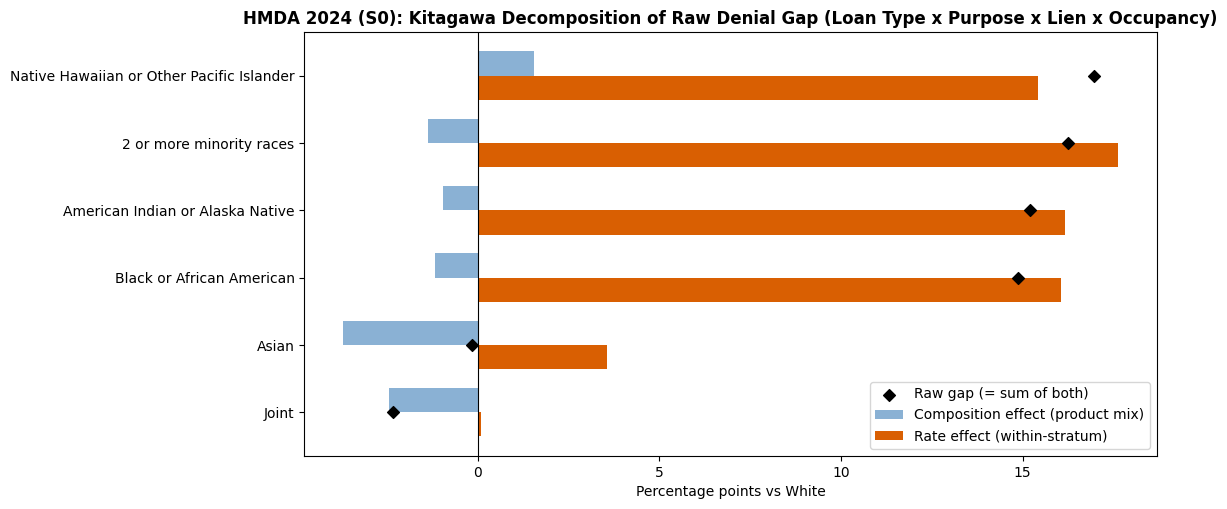

In [44]:
# Step 1: Composition vs rate bars with raw gap marker
ks = KIT_SUM.sort_values("raw_gap_pp").reset_index(drop=True)
y, h = np.arange(len(ks)), 0.36
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(y + h / 2, ks["composition_pp"], h, color="#8ab1d4", label="Composition effect (product mix)")
ax.barh(y - h / 2, ks["rate_pp"], h, color="#d95f02", label="Rate effect (within-stratum)")
ax.scatter(ks["raw_gap_pp"], y, marker="D", color="black", zorder=3, label="Raw gap (= sum of both)")
ax.axvline(0, color="black", linewidth=0.8); ax.set_yticks(y); ax.set_yticklabels(ks["group"])
ax.set_xlabel(f"Percentage points vs {REF_RACE}"); ax.legend()
ax.set_title("HMDA 2024 (S0): Kitagawa Decomposition of Raw Denial Gap (Loan Type x Purpose x Lien x Occupancy)", fontweight="bold")
save_fig_and_log(fig, "B14_fig_14_kitagawa.png"); plt.show()

In [45]:
# Step 1: Mask unstable share-of-gap and flag low-reliability decompositions [Hypothesis: thresholds]
MIN_GAP_PP_FOR_SHARE, POOLED_MAX_PCT = 1.0, 10.0
KIT_SUM.loc[KIT_SUM["raw_gap_pp"].abs() < MIN_GAP_PP_FOR_SHARE, "composition_share_of_gap_pct"] = np.nan
KIT_SUM["pooled_share_max_pct"] = KIT_SUM[["pooled_share_group_pct", "pooled_share_ref_pct"]].max(axis=1)
KIT_SUM["low_reliability"] = KIT_SUM["pooled_share_max_pct"] > POOLED_MAX_PCT

# Step 2: Re-save (overwrites the C5 file with the extra columns)
save_and_log(KIT_SUM, "B14_rq1_kitagawa.csv")
display(KIT_SUM[["group", "raw_gap_pp", "composition_pp", "rate_pp", "composition_share_of_gap_pct", "pooled_share_max_pct", "low_reliability"]])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_kitagawa.csv | Size: 1.40 KB | Shape: (6, 15)


,group,raw_gap_pp,composition_pp,rate_pp,composition_share_of_gap_pct,pooled_share_max_pct,low_reliability
0,Black or African American,14.8752,-1.1918,16.0670,-8.0117,0.8171,False
1,Asian,-0.1554,-3.7115,3.5560,NaN,1.9068,False
2,Joint,-2.3383,-2.4339,0.0955,104.0854,2.6178,False
3,American Indian or Alaska Native,15.1927,-0.9690,16.1616,-6.3778,6.0814,False
4,2 or more minority races,16.2620,-1.3666,17.6286,-8.4037,35.5489,True
5,Native Hawaiian or Other Pacific Islander,16.9644,1.5399,15.4245,9.0770,37.2018,True


### Interpretation — Step C5 (`B14_rq1_kitagawa.csv`, Fig 14)
*Figures are read from the saved table (as of run 2026-11-10, B14 C5).*
1. **What pattern is observed?**
   - Product mix (loan type x purpose x lien x occupancy) does **not** explain the Black gap: composition -1.19 pp, rate +16.07 pp, raw gap +14.88 pp. The same holds for American Indian or Alaska Native (-0.97 / +16.16 pp for a +15.19 pp gap).
   - Asian: composition -3.71 pp and rate +3.56 pp; the raw gap (-0.16 pp) is a sum of a favourable mix and a positive within-stratum gap.
   - Joint: composition -2.43 pp, rate +0.10 pp (composition share 104%); the Joint advantage is almost entirely product mix.
   - The largest stratum drives the Black result: conventional first-lien purchase for principal residence holds 22% of Black and 32% of White applications, with denial 34.94% vs 13.95% (rate contribution +5.65 pp).
   - 2+ minority races (-1.37 / +17.63 pp) and Native Hawaiian or Other Pacific Islander (+1.54 / +15.42 pp) are `low_reliability` (pooled share 35.55% and 37.20%, 5 strata kept) and are not estimates (D-U, D-X).
2. **What evidence supports the finding?** `B14_rq1_kitagawa.csv`, `B14_rq1_kitagawa_strata.csv`, `B14_fig_14_kitagawa.png`; identity residual below 1e-9 (checked in code).
3. **Why might it matter in mortgage lending?** The first stage of the framework (product controls) is expected to narrow the Black gap very little. The product-mix step is where the Asian result changes sign.
4. **What alternative explanations or limitations apply?**
   - It is an accounting identity, not a model; it depends on the strata definition and on symmetric weights.
   - Financial profile is not included (Part D), and pooled strata (0.82% to 6.08% for the four reliable groups) are small but nonzero.
   - Composition share is undefined when the raw gap is under 1 pp (Asian).

## C6: Race Not Available Profile (Decision D-L)
- **Input:** `df_s0`, `LENDER_RACE` (C1b).
- **Process:**
  - By channel (`submission_of_application`), `loan_type` and `loan_purpose`: share of applications with `Race Not Available`, and the denial rate of that group vs all other races.
  - Lender concentration, from integer lender codes only (no LEI, D-O): lender-level `Race Not Available` share, and the share of all such applications held by the 10 and 100 largest lenders in that group.
- **Output:** `B14_rq1_race_na_profile.csv`, `B14_rq1_race_na_lender_concentration.csv`, `B14_fig_15_race_na_profile.png`.

In [46]:
# Step 1: Share and denial rate of Race Not Available by channel / loan_type / loan_purpose
RNA = "Race Not Available"
def rna_by(var):
    a = agg_counts([var, "derived_race"]); a["is_rna"] = a["derived_race"] == RNA
    g = a.groupby([var, "is_rna"])[["n_apps", "n_denied"]].sum().unstack("is_rna", fill_value=0)
    n_r, n_o, d_r, d_o = g[("n_apps", True)], g[("n_apps", False)], g[("n_denied", True)], g[("n_denied", False)]
    return pd.DataFrame({"variable": var, "level": g.index, "n_apps": (n_r + n_o).to_numpy(), "n_rna": n_r.to_numpy(),
                         "rna_share_pct": (n_r * 100 / (n_r + n_o)).to_numpy(), "denial_rate_rna_pct": (d_r * 100 / n_r).to_numpy(),
                         "denial_rate_other_races_pct": (d_o * 100 / n_o).to_numpy()})
C6 = pd.concat([rna_by(v) for v in ["submission_of_application", "loan_type", "loan_purpose"]], ignore_index=True)
save_and_log(C6, "B14_rq1_race_na_profile.csv"); display(C6)

# Step 2: Lender-level concentration (integer codes only)
tot = LENDER_RACE.groupby("lender_code")["n"].sum()
rna_n = LENDER_RACE[LENDER_RACE["derived_race"] == RNA].set_index("lender_code")["n"].reindex(tot.index, fill_value=0)
lend = pd.DataFrame({"n_apps": tot, "n_rna": rna_n}); lend["rna_share"] = lend["n_rna"] / lend["n_apps"]
big = lend[lend["n_apps"] >= N_MIN_APPS]; rna_sorted = lend["n_rna"].sort_values(ascending=False)
conc = pd.DataFrame({"metric": ["n_lenders_all", "n_lenders_ge_N_MIN_APPS", "overall_rna_share_pct", "median_lender_rna_share_pct",
                                "p90_lender_rna_share_pct", "n_lenders_rna_share_gt_50pct", "top10_share_of_all_rna_pct", "top100_share_of_all_rna_pct"],
                     "value": [len(lend), len(big), lend.n_rna.sum() * 100 / lend.n_apps.sum(), big.rna_share.median() * 100,
                               big.rna_share.quantile(0.9) * 100, int((big.rna_share > 0.5).sum()),
                               rna_sorted.head(10).sum() * 100 / lend.n_rna.sum(), rna_sorted.head(100).sum() * 100 / lend.n_rna.sum()]})
save_and_log(conc, "B14_rq1_race_na_lender_concentration.csv"); display(conc)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_race_na_profile.csv | Size: 1.20 KB | Shape: (13, 7)


,variable,level,n_apps,n_rna,rna_share_pct,denial_rate_rna_pct,denial_rate_other_races_pct
0,submission_of_application,1,6630716,973296,14.6786,32.4217,24.9285
1,submission_of_application,1111,250110,53335,21.3246,8.0866,14.4027
2,submission_of_application,2,1255838,248609,19.7963,23.4726,18.5061
3,loan_type,1,6398871,956400,14.9464,31.0581,25.1913
4,loan_type,2,1079523,190693,17.6646,30.1374,20.0826
5,loan_type,3,614728,124666,20.2799,18.6450,14.4298
6,loan_type,4,43542,3481,7.9946,13.5880,11.9967
7,loan_purpose,1,4038224,605280,14.9888,16.7384,14.0686
8,loan_purpose,2,984874,127350,12.9306,41.7401,36.4919
9,loan_purpose,31,882884,143080,16.2060,25.4459,22.8256


Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq1_race_na_lender_concentration.csv | Size: 0.32 KB | Shape: (8, 2)


,metric,value
0,n_lenders_all,"4,808.0000"
1,n_lenders_ge_N_MIN_APPS,862.0000
2,overall_rna_share_pct,15.6728
3,median_lender_rna_share_pct,12.4939
4,p90_lender_rna_share_pct,23.0426
5,n_lenders_rna_share_gt_50pct,3.0000
6,top10_share_of_all_rna_pct,30.0736
7,top100_share_of_all_rna_pct,67.1959


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_15_race_na_profile.png | Size: 80.10 KB


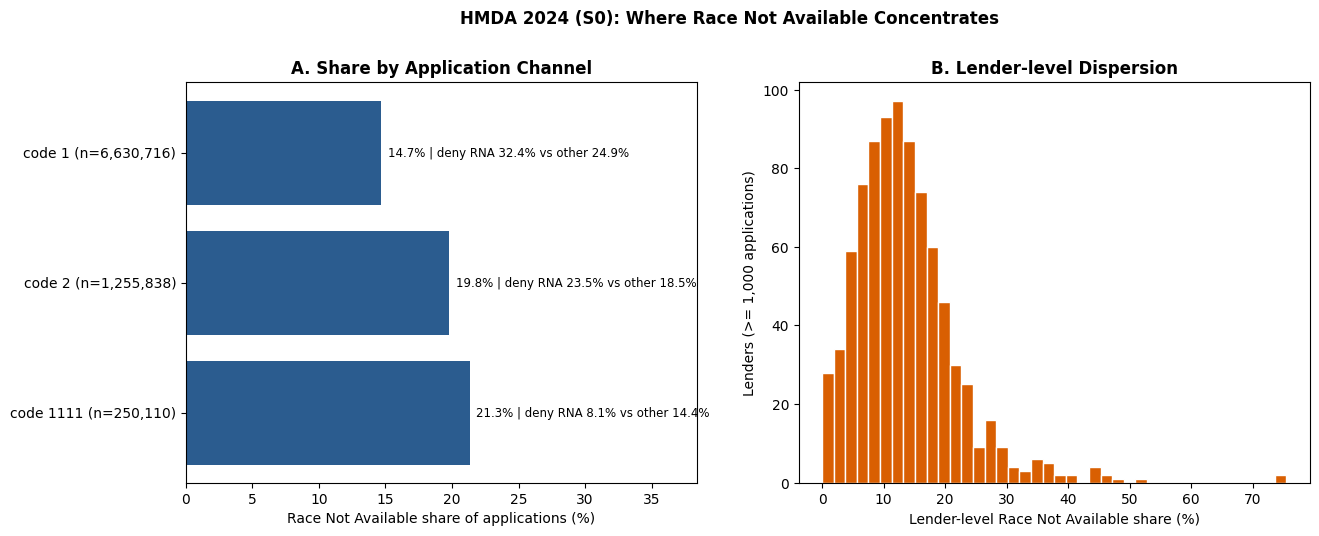

In [47]:
# Step 1: Panel A (share + denial by channel) and Panel B (lender-level share histogram)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))
ch = C6[C6["variable"] == "submission_of_application"].sort_values("n_apps")
y = np.arange(len(ch))
ax1.barh(y, ch["rna_share_pct"], color="#2b5c8f")
ax1.set_yticks(y); ax1.set_yticklabels([f"code {l} (n={n:,})" for l, n in zip(ch["level"], ch["n_apps"])])
for i, (s, dr, do) in enumerate(zip(ch["rna_share_pct"], ch["denial_rate_rna_pct"], ch["denial_rate_other_races_pct"])):
    ax1.text(s + 0.5, i, f"{s:.1f}% | deny RNA {dr:.1f}% vs other {do:.1f}%", va="center", fontsize=8.5)
ax1.set_xlim(0, ch["rna_share_pct"].max() * 1.8); ax1.set_xlabel("Race Not Available share of applications (%)")
ax1.set_title("A. Share by Application Channel", fontweight="bold")
ax2.hist(big["rna_share"] * 100, bins=40, color="#d95f02", edgecolor="white")
ax2.set_xlabel("Lender-level Race Not Available share (%)"); ax2.set_ylabel(f"Lenders (>= {N_MIN_APPS:,} applications)")
ax2.set_title("B. Lender-level Dispersion", fontweight="bold")
fig.suptitle("HMDA 2024 (S0): Where Race Not Available Concentrates", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_15_race_na_profile.png"); plt.show()

### Interpretation — Step C6 (`B14_rq1_race_na_profile.csv`, `B14_rq1_race_na_lender_concentration.csv`, Fig 15)
*Figures are read from the saved tables (as of run 2026-11-10, B14 C6).*
1. **What pattern is observed?**
   - Race Not Available is 15.67% of S0, but 19.80% of non-direct submissions and 21.32% of exempt-channel (code 1111) applications vs 14.68% of direct ones. By loan type it is 20.28% (VA), 17.66% (FHA) and 14.95% (conventional). By purpose it is highest in cash-out refinance (21.44%).
   - Denial is higher than for other races in every cell except the exempt channel (8.09% vs 14.40%): direct 32.42% vs 24.93%, FHA 30.14% vs 20.08%, cash-out refinance 45.87% vs 29.94%.
   - 862 of 4,808 lenders have at least 1,000 applications. The median lender share is 12.49% and p90 23.04%; 3 lenders have more than 50%. The top 10 lenders hold 30.07% of all Race Not Available applications and the top 100 hold 67.20%.
2. **What evidence supports the finding?** The two C6 tables and `B14_fig_15_race_na_profile.png`.
3. **Why might it matter in mortgage lending?** Race Not Available is concentrated in channels where the race is hard to observe and in some products, and its denial profile differs by cell, which supports keeping it separate (D-L) rather than assigning it to any group.
4. **What alternative explanations or limitations apply?**
   - Concentration in the top lenders must be compared with their share of all applications (F6) before reading it as a lender practice.
   - Lower denial among exempt filers may reflect incomplete files `[Hypothesis]`.
   - Descriptive only; the true race of these applicants is unknown.

## Checkpoint 3 Gate (eda_plan.md §14, Block 3)
- **Input:** Outputs of C1–C6.
- **Process:** Assert reconciliation (counts, reference, Kitagawa identity, bootstrap CI contains the point estimate, artifacts saved), then show the headline gap table for Human review.
- **Output:** `gate3` table.

In [48]:
# Step 1: Gate conditions
head = C1[C1["headline"] & ~C1["is_reference"]]
need3 = ["B14_rq1_raw_gap.csv", "B14_rq1_gap_other_dims.csv", "B14_rq1_mix_by_race.csv", "B14_rq1_stratified_gap.csv",
         "B14_rq1_kitagawa.csv", "B14_rq1_kitagawa_strata.csv", "B14_rq1_race_na_profile.csv", "B14_rq1_race_na_lender_concentration.csv"]
figs = [p.name for p in FIG_DIR.glob("B14_fig_*.png")]
gate3 = pd.DataFrame([
    ("Gate 3.1: C1 counts sum to S0", int(C1["n_apps"].sum()) == len(df_s0), f"{len(df_s0):,} rows"),
    ("Gate 3.2: reference = White, gap = 0", float(C1.loc[C1["is_reference"], "gap_pp"].iloc[0]) == 0.0, REF_RACE),
    ("Gate 3.3: Kitagawa identity residual < 1e-9", bool((KIT_SUM["identity_residual_pp"].abs() < 1e-9).all()), f"{len(KIT_SUM)} groups"),
    ("Gate 3.4: cluster CI contains point estimate", bool(((head["gap_pp"] >= head["boot_gap_ci_lo"]) & (head["gap_pp"] <= head["boot_gap_ci_hi"])).all()), f"B = {BOOT_B:,}"),
    ("Gate 3.5: Part C tables saved", all((OUTPUT_DIR / f).exists() for f in need3), f"{len(need3)} tables"),
    ("Gate 3.6: figures 10-15 saved", all(any(n.startswith(f"B14_fig_{i}") for n in figs) for i in range(10, 16)), f"{len(figs)} figures"),
], columns=["checkpoint_3_gate", "passed", "evidence"])
assert gate3["passed"].all(), "Checkpoint 3 gate failed!"
display(gate3)
display(head[["derived_race", "denial_rate_pct", "gap_pp", "boot_gap_ci_lo", "boot_gap_ci_hi", "odds_ratio", "low_n"]])
print("[CHECKPOINT 3 PASSED] Pending Human review of headline gaps. Next: Checkpoint 4 (Part D).")

,checkpoint_3_gate,passed,evidence
0,Gate 3.1: C1 counts sum to S0,True,"8,136,664 rows"
1,"Gate 3.2: reference = White, gap = 0",True,White
2,Gate 3.3: Kitagawa identity residual < 1e-9,True,6 groups
3,Gate 3.4: cluster CI contains point estimate,True,"B = 1,000"
4,Gate 3.5: Part C tables saved,True,8 tables
5,Gate 3.6: figures 10-15 saved,True,16 figures


,derived_race,denial_rate_pct,gap_pp,boot_gap_ci_lo,boot_gap_ci_hi,odds_ratio,low_n
2,Black or African American,36.7967,14.8752,12.9446,16.9902,2.0736,False
3,Asian,21.7661,-0.1554,-2.5136,1.9001,0.9909,False
4,Joint,19.5832,-2.3383,-3.2982,-1.2834,0.8674,False
5,American Indian or Alaska Native,37.1142,15.1927,11.9494,18.5109,2.1021,False
6,2 or more minority races,38.1836,16.2620,12.4693,19.6955,2.2001,False
7,Native Hawaiian or Other Pacific Islander,38.8859,16.9644,14.1647,20.0569,2.2663,False


[CHECKPOINT 3 PASSED] Pending Human review of headline gaps. Next: Checkpoint 4 (Part D).


In [49]:
# Step 1: Print erratum lines from computed C1 (Convention 4.3: no typed numbers)
for r in C1.itertuples():
    print(f"- {r.derived_race}: {r.n_apps:,} applications ({r.n_apps * 100 / len(df_s0):.2f}% of S0), denial rate {r.denial_rate_pct:.2f}% (as of run 2026-11-10, B14 C1)")

- White: 5,360,624 applications (65.88% of S0), denial rate 21.92% (as of run 2026-11-10, B14 C1)
- Race Not Available: 1,275,240 applications (15.67% of S0), denial rate 29.66% (as of run 2026-11-10, B14 C1)
- Black or African American: 733,103 applications (9.01% of S0), denial rate 36.80% (as of run 2026-11-10, B14 C1)
- Asian: 478,497 applications (5.88% of S0), denial rate 21.77% (as of run 2026-11-10, B14 C1)
- Joint: 184,536 applications (2.27% of S0), denial rate 19.58% (as of run 2026-11-10, B14 C1)
- American Indian or Alaska Native: 61,397 applications (0.75% of S0), denial rate 37.11% (as of run 2026-11-10, B14 C1)
- 2 or more minority races: 20,920 applications (0.26% of S0), denial rate 38.18% (as of run 2026-11-10, B14 C1)
- Native Hawaiian or Other Pacific Islander: 20,249 applications (0.25% of S0), denial rate 38.89% (as of run 2026-11-10, B14 C1)
- Free Form Text Only: 2,098 applications (0.03% of S0), denial rate 58.34% (as of run 2026-11-10, B14 C1)


## D0: Financial Bins and Helpers (Part D)
- **Input:** `df_s0`, DTI order lists from the DTI cell (B3), constants from C0.
- **Process:**
  - `dti_cat`/`dti_fine_cat`: ordered DTI bins with `MISSING: na/exempt` as explicit categories (never dropped).
  - `cltv_bin`: CLTV with heaping bins (`=80` is exactly 80); CLTV <= 0 (rule V03) goes to `MISSING / invalid`.
  - `income_decile`: deciles of **positive** income computed on S0 (`[Hypothesis]` proposed as D-V); `Income <= 0` and `Income missing` are separate levels. `lti_bin`: loan-to-income bins.
  - `agg_on(frame, keys)` aggregates a (small) frame with a row-sum check; `with_rates` adds the rate, Wilson CI and `low_n`.
- **Output:** 5 new categorical columns, `ORDERS`, `B14_rq2_income_decile_edges.csv`.

In [50]:
# Step 1: Bin constants (declared once)
CLTV_EDGES = [-np.inf, 60, 70, 79.999, 80, 90, 95, 97, 100, np.inf]
CLTV_LABELS = ["<=60", "60-70", "70-<80", "=80", "80-90", "90-95", "95-97", "97-100", ">100"]
LTI_EDGES, LTI_LABELS = [0, 1, 2, 3, 4, 5, 7, np.inf], ["<1", "1-2", "2-3", "3-4", "4-5", "5-7", ">=7"]

# Step 2: DTI with explicit missing categories
def dti_filled(col, order):
    d = df_s0[col].cat.set_categories(order)
    for st in ("na", "exempt"):
        d = d.mask(d.isna() & (df_s0["dti_status"] == st), f"MISSING: {st}")
    assert d.notna().all(), f"Unclassified DTI rows in {col}"
    return d
df_s0["dti_cat"], df_s0["dti_fine_cat"] = dti_filled("dti_bin_coarse", DTI_COARSE_ORDER), dti_filled("dti_bin_fine", DTI_FINE_ORDER)

# Step 3: CLTV and LTI bins
cltv = df_s0["combined_loan_to_value_ratio"].where(df_s0["combined_loan_to_value_ratio"] > 0)
df_s0["cltv_bin"] = pd.cut(cltv, CLTV_EDGES, labels=CLTV_LABELS).cat.add_categories(["MISSING / invalid"]).fillna("MISSING / invalid")
df_s0["lti_bin"] = (pd.cut(df_s0["loan_to_income"], LTI_EDGES, labels=LTI_LABELS, right=False)
                    .cat.add_categories(["MISSING (income<=0/NA)"]).fillna("MISSING (income<=0/NA)"))

# Step 4: Income deciles on positive income
inc = df_s0["income"]
c = pd.qcut(inc.where(inc > 0), 10, labels=False, duplicates="drop").fillna(-1).astype("int8").to_numpy()
dec = pd.Series(pd.Categorical.from_codes(c, [f"D{i:02d}" for i in range(1, int(c.max()) + 2)]), index=df_s0.index)
dec = dec.cat.add_categories(["Income <= 0", "Income missing"]).mask(inc <= 0, "Income <= 0").mask(inc.isna(), "Income missing")
df_s0["income_decile"] = dec
edges = inc.where(inc > 0).quantile(np.linspace(0, 1, 11)).rename("income_k_usd").reset_index().rename(columns={"index": "quantile"})
save_and_log(edges, "B14_rq2_income_decile_edges.csv")

# Step 5: Orders, helpers and checks
BIN_COLS = ["dti_cat", "dti_fine_cat", "cltv_bin", "income_decile", "lti_bin"]
ORDERS = {k: list(df_s0[k].cat.categories) for k in BIN_COLS}
assert all(df_s0[k].notna().all() for k in BIN_COLS), "Unbinned rows"
def agg_on(frame, keys):
    g = frame.groupby(keys, observed=True, dropna=False)["is_denied"].agg(n_apps="count", n_denied="sum").reset_index()
    for k in keys: g[k] = g[k].astype("string").fillna("NULL / Missing")
    g["n_denied"] = g["n_denied"].astype("int64"); assert int(g["n_apps"].sum()) == len(frame); return g
def with_rates(g):
    g = g.copy(); g["denial_rate_pct"] = g["n_denied"] * 100.0 / g["n_apps"]
    g["wilson_ci_lo"], g["wilson_ci_hi"] = wilson_ci(g["n_denied"], g["n_apps"])
    g["low_n"] = (g["n_apps"] < N_MIN_APPS) | (g["n_denied"] < N_MIN_DENIED); return g
print({k: len(v) for k, v in ORDERS.items()})

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_income_decile_edges.csv | Size: 0.19 KB | Shape: (11, 2)
{'dti_cat': 10, 'dti_fine_cat': 21, 'cltv_bin': 10, 'income_decile': 12, 'lti_bin': 8}


## D1: Financial Profile by Race
- **Input:** `df_s0`, `C1`, bins from D0.
- **Process:** Quantiles (p05–p95) of `income`, `loan_amount`, `loan_to_income`, `property_value` among **positive valid** values per race (`n_valid` shown, since income and property value are missing for some applicants). Share of each race in each DTI and CLTV bin (row %, sums to 100). Box = p25–p75, whiskers = p05–p95.
- **Output:** `B14_rq2_profile_by_race.csv`, `B14_rq2_bin_mix_by_race.csv`, `B14_fig_16_profile_by_race.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_profile_by_race.csv | Size: 3.27 KB | Shape: (36, 8)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_bin_mix_by_race.csv | Size: 11.67 KB | Shape: (180, 6)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_16_profile_by_race.png | Size: 75.45 KB


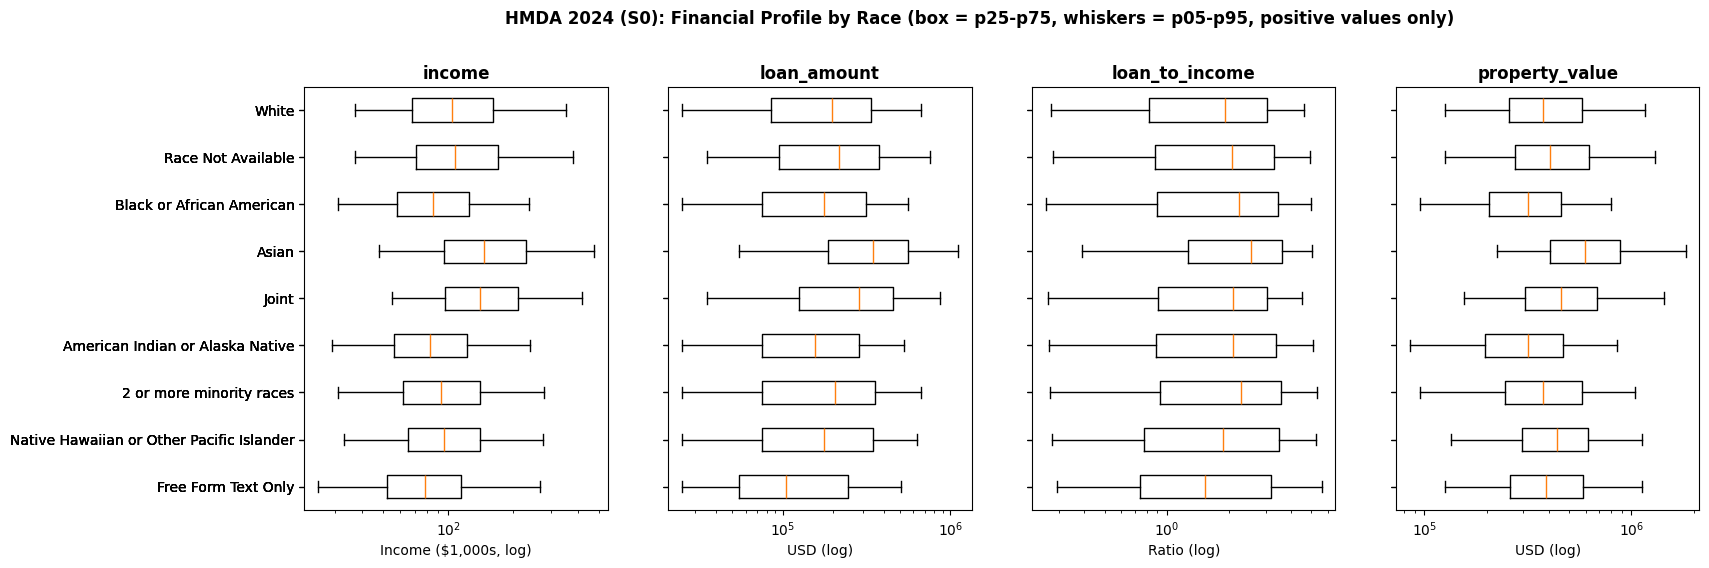

In [51]:
# Step 1: Quantile table by race
Q, rows = [0.05, 0.25, 0.5, 0.75, 0.95], []
for v in ["income", "loan_amount", "loan_to_income", "property_value"]:
    gq = df_s0[v].where(df_s0[v] > 0).groupby(df_s0["derived_race"], observed=True)
    q = gq.quantile(Q).unstack(); q.columns = [f"p{int(x * 100):02d}" for x in q.columns]
    q["n_valid"] = gq.count(); q.insert(0, "variable", v); rows.append(q.reset_index())
D1 = pd.concat(rows, ignore_index=True); D1["derived_race"] = D1["derived_race"].astype("string")
save_and_log(D1, "B14_rq2_profile_by_race.csv")

# Step 2: DTI / CLTV mix within race (row %)
race_n_f = C1.set_index("derived_race")["n_apps"].astype("float64")
parts = []
for v in ["dti_cat", "cltv_bin"]:
    a = agg_counts(["derived_race", v]).rename(columns={v: "level"}); a.insert(0, "variable", v)
    a["share_within_race_pct"] = a["n_apps"] * 100.0 / a["derived_race"].map(race_n_f).astype("float64"); parts.append(a)
D1_MIX = pd.concat(parts, ignore_index=True); save_and_log(D1_MIX, "B14_rq2_bin_mix_by_race.csv")

# Step 3: Box plots from precomputed quantiles
order = C1["derived_race"].tolist()[::-1]
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5), sharey=True)
for v, ax in zip(["income", "loan_amount", "loan_to_income", "property_value"], axes):
    s = D1[D1["variable"] == v].set_index("derived_race").reindex(order)
    st = [{"label": r, "whislo": x.p05, "q1": x.p25, "med": x.p50, "q3": x.p75, "whishi": x.p95, "fliers": []} for r, x in s.iterrows()]
    ax.bxp(st, vert=False, showfliers=False); ax.set_xscale("log"); ax.set_title(v, fontweight="bold")
    ax.set_xlabel("Income ($1,000s, log)" if v == "income" else ("Ratio (log)" if v == "loan_to_income" else "USD (log)"))
fig.suptitle("HMDA 2024 (S0): Financial Profile by Race (box = p25-p75, whiskers = p05-p95, positive values only)", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_16_profile_by_race.png"); plt.show()

## D2: Denial-Rate Curves by Financial Variable
- **Input:** `df_s0`, bins from D0, `HEADLINE_RACES`.
- **Process:** Denial rate with Wilson CI per level of `dti_fine_cat`, `cltv_bin`, `income_decile`, `lti_bin`, for all S0 and for each headline race. Levels failing D-M are flagged `low_n` and drawn as gaps. Missing categories are shown separately because they behave differently (A8).
- **Output:** `B14_rq2_denial_curves.csv`, `B14_fig_17_denial_curves.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_denial_curves.csv | Size: 44.60 KB | Shape: (408, 10)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_17_denial_curves.png | Size: 386.11 KB


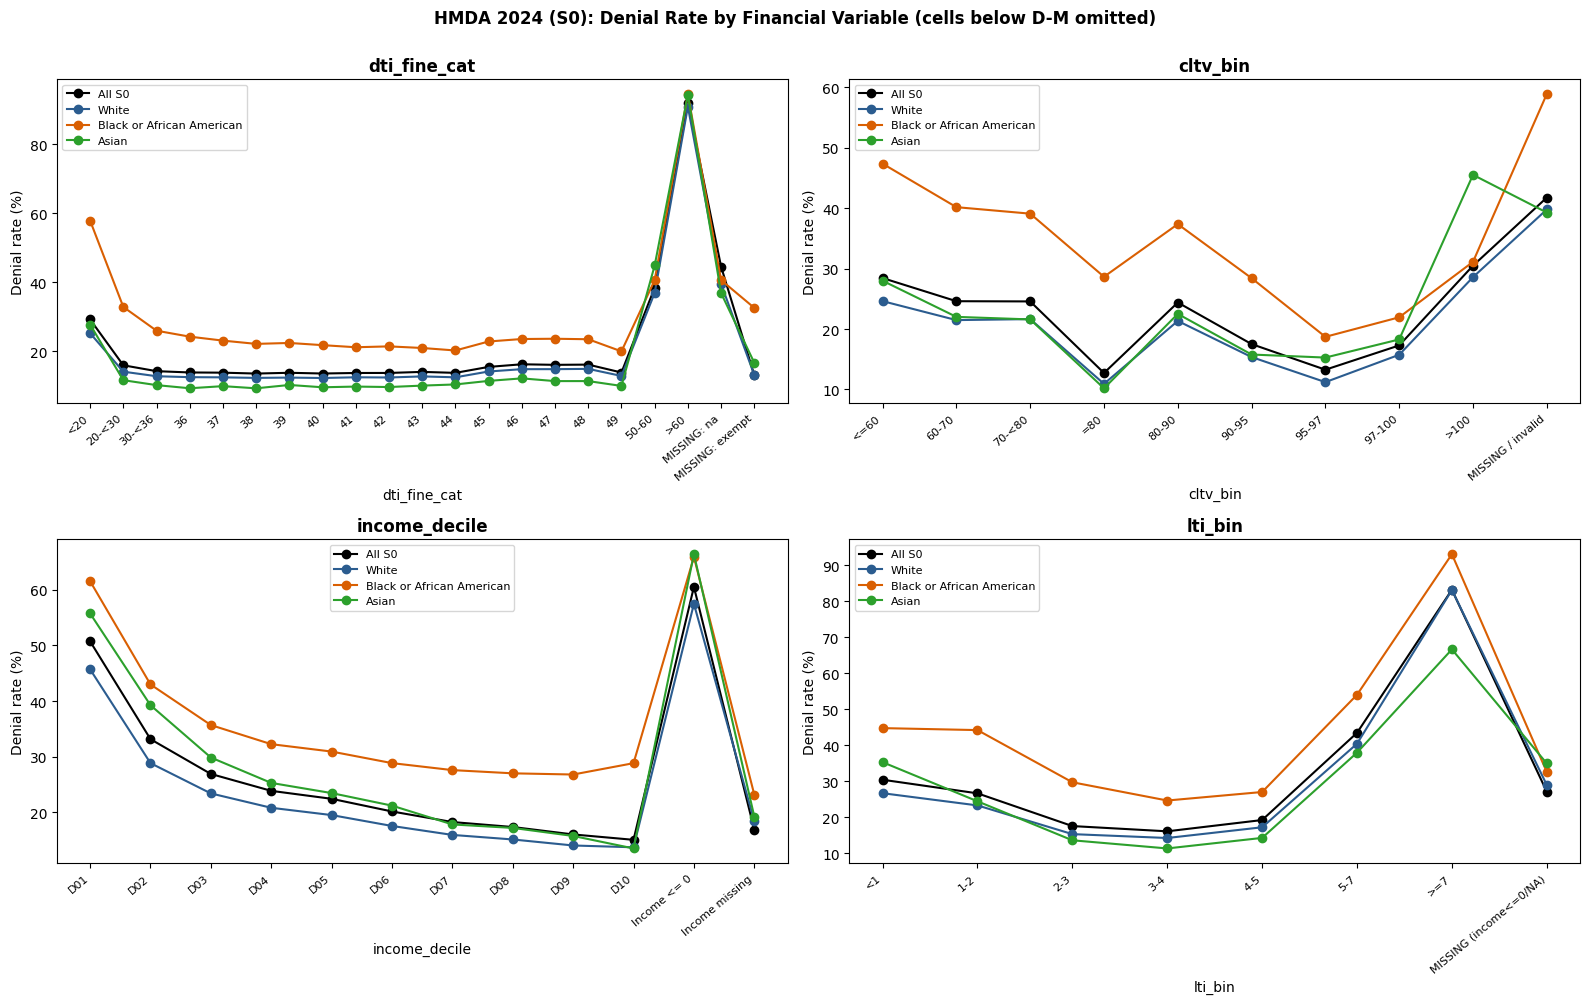

In [52]:
# Step 1: Curves overall and by headline race (aggregate on full frame; no row copies)
parts = []
for var in ["dti_fine_cat", "cltv_bin", "income_decile", "lti_bin"]:
    a_all = agg_counts([var]).assign(group="All S0")
    a_r = agg_counts(["derived_race", var]).rename(columns={"derived_race": "group"})
    a_r = a_r[a_r["group"].isin(HEADLINE_RACES)]
    t = with_rates(pd.concat([a_all, a_r], ignore_index=True)).rename(columns={var: "level"})
    t.insert(0, "variable", var); t["level_order"] = t["level"].map({l: i for i, l in enumerate(ORDERS[var])}); parts.append(t)
D2 = pd.concat(parts, ignore_index=True); assert D2["level_order"].notna().all() and D2["denial_rate_pct"].between(0, 100).all()
save_and_log(D2, "B14_rq2_denial_curves.csv")

# Step 2: 2x2 line plots (All, White, Black, Asian)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
styles = {"All S0": "black", REF_RACE: "#2b5c8f", "Black or African American": "#d95f02", "Asian": "#2ca02c"}
for var, ax in zip(["dti_fine_cat", "cltv_bin", "income_decile", "lti_bin"], axes.ravel()):
    for grp, col in styles.items():
        s = D2[(D2["variable"] == var) & (D2["group"] == grp)].sort_values("level_order")
        ax.plot(s["level_order"], s["denial_rate_pct"].where(~s["low_n"]), marker="o", color=col, label=grp)
    ax.set_xticks(range(len(ORDERS[var]))); ax.set_xticklabels(ORDERS[var], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel("Denial rate (%)"); ax.set_xlabel(var); ax.set_title(var, fontweight="bold"); ax.legend(fontsize=8)
fig.suptitle("HMDA 2024 (S0): Denial Rate by Financial Variable (cells below D-M omitted)", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_17_denial_curves.png"); plt.show()

## D3: Joint Denial Surface, DTI x CLTV
- **Input:** `df_s0`, first-lien (`lien_status == "1"`) purchase (`loan_purpose == "1"`) and refinance (`"31"`, `"32"`).
- **Process:** Denial rate per DTI-bin x CLTV-bin cell. Cells failing D-M are masked in the heatmap (kept in the CSV with `low_n`). Missing categories are excluded from the plot only.
- **Output:** `B14_rq2_dti_cltv_heatmap.csv`, `B14_fig_18_dti_cltv_heatmap.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_dti_cltv_heatmap.csv | Size: 19.92 KB | Shape: (186, 9)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_18_dti_cltv_heatmap.png | Size: 144.44 KB


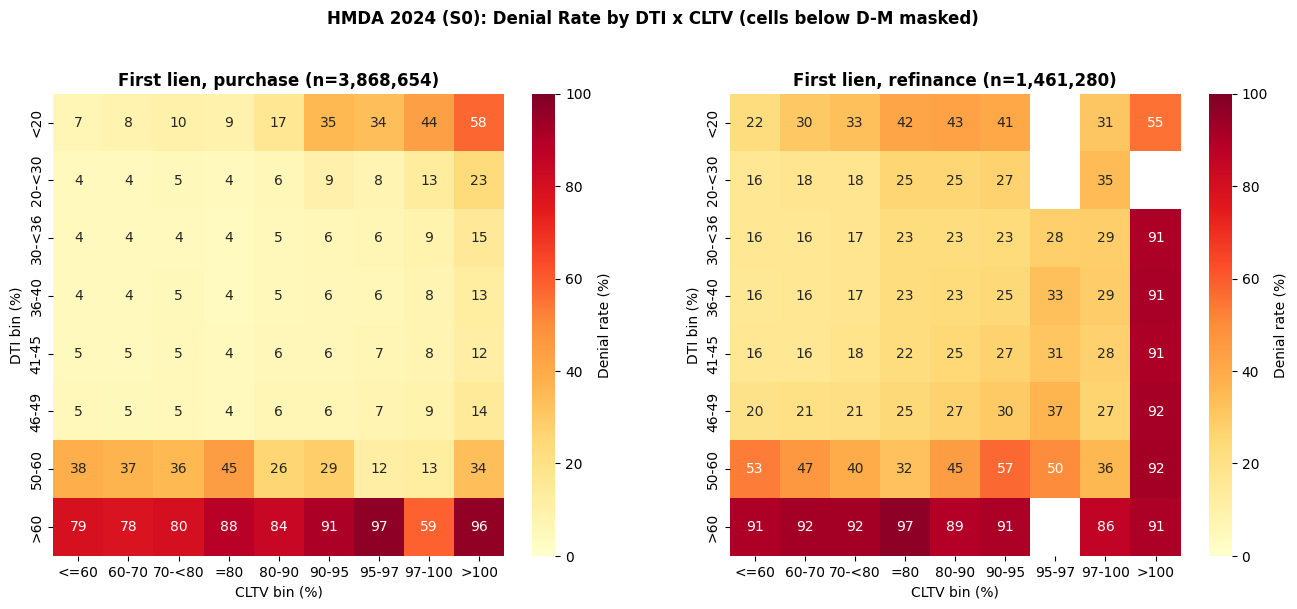

In [53]:
# Step 1: Cell counts for the two segments (select few columns before filtering)
SEGS = {"First lien, purchase": df_s0["loan_purpose"] == "1", "First lien, refinance": df_s0["loan_purpose"].isin(["31", "32"])}
fl, parts = df_s0["lien_status"] == "1", []
for name, m in SEGS.items():
    parts.append(with_rates(agg_on(df_s0.loc[fl & m, ["is_denied", "dti_cat", "cltv_bin"]], ["dti_cat", "cltv_bin"])).assign(segment=name))
D3 = pd.concat(parts, ignore_index=True); save_and_log(D3, "B14_rq2_dti_cltv_heatmap.csv")

# Step 2: Heatmaps (valid bins only, D-M masked)
rows_o = [x for x in ORDERS["dti_cat"] if not x.startswith("MISSING")]; cols_o = [x for x in ORDERS["cltv_bin"] if not x.startswith("MISSING")]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for (name, _), ax in zip(SEGS.items(), axes):
    s = D3[(D3["segment"] == name) & ~D3["low_n"]].pivot(index="dti_cat", columns="cltv_bin", values="denial_rate_pct").reindex(index=rows_o, columns=cols_o).astype("float64")
    sns.heatmap(s, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "Denial rate (%)"})
    ax.set_title(f"{name} (n={int(D3.loc[D3['segment'] == name, 'n_apps'].sum()):,})", fontweight="bold"); ax.set_xlabel("CLTV bin (%)"); ax.set_ylabel("DTI bin (%)")
fig.suptitle("HMDA 2024 (S0): Denial Rate by DTI x CLTV (cells below D-M masked)", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_18_dti_cltv_heatmap.png"); plt.show()

### Interpretation — Steps D0, D1, D2 & D3 (`B14_rq2_profile_by_race.csv`, `B14_rq2_bin_mix_by_race.csv`, `B14_rq2_denial_curves.csv`, `B14_rq2_dti_cltv_heatmap.csv`, Fig 16–18)

*All figures are read from the saved tables (as of run 2026-11-10, B14 D0–D3).*

1. **What pattern is observed?**
   - **Financial profiles (D1).** Median income is 147k USD for Asian and 140k for Joint applicants, against 104k for White, 85k for Black and 82k for American Indian or Alaska Native (AIAN). Median property value is 595k (Asian), 375k (White) and 315k (Black). Loans differ by group in opposite directions: the median Black loan (175k) is smaller than the White one (195k), while the median Asian loan (345k) is much larger. Median loan-to-income (LTI) is higher than White (1.91) for both: Black 2.24 (lower income, smaller loan, but income falls more than the loan) and Asian 2.54 (higher income, much larger loan).
   - **DTI and CLTV mix (D1).** Applications with DTI of 50% or more are 26.25% of Black applications (15.16% + 11.09%), 15.41% of White and 16.06% of Asian. Applications with CLTV above 95% are 29.45% of Black, 16.08% of White and 8.81% of Asian. CLTV is missing or invalid for 12.80% of Black and 9.88% of White applications.
   - **Denial curves, all S0 (D2).** Denial is J-shaped in DTI: 29.21% below 20, 13.5–14.2% for integer points 36–44 and 49, 15.5–16.2% for 45–48, then 38.41% for 50–60 and 92.01% above 60. In CLTV, the exact-80 bin has 12.72% denial against 24.56% in the 70–<80 bin. Across income deciles of positive income the all-S0 rate falls from 50.72% (D01) to 15.08% (D10) without exception.
   - **Black vs White within bins (D2).** The Black rate is above the White rate in all 51 valid levels (21 DTI, 10 CLTV, 12 income, 8 LTI; none is `low_n`). The size of the gap is not constant. In DTI it is +7.1 to +18.8 pp for bins 20–<30 to 49 and +32.6 pp below 20, but only +3.7 pp for 50–60 and +3.6 pp above 60. In CLTV it is largest at CLTV <= 60 (+22.8 pp) and smallest at the top: +6.2 to +7.5 pp for 95–100 and +2.5 pp above 100. Example cells: DTI = 40, 21.77% vs 12.25%; CLTV = 80, 28.65% vs 10.92%. For Black applicants the income curve is not monotonic: D10 (28.84%) is above D09 (26.81%).
   - **DTI × CLTV surface (D3, first lien).** For purchase loans, DTI below 20 with CLTV = 80 has 9.25% denial but with CLTV 97–100 has 44.05%. For refinance the pattern reverses: DTI below 20 with CLTV = 80 has 41.53% against 31.18% at CLTV 97–100, and refinance cells with CLTV above 100 have 88–92% denial for every DTI bin from 20–<30 to above 60. DTI above 60 has 80–97% denial in almost all purchase cells (the exception is CLTV 97–100, 58.92%). Cells below D-M are masked (2 purchase and 7 refinance cells).
2. **What evidence supports the finding?**
   - The four D1–D3 tables above and Figures 16–18; every table sums to S0 (checked in the code).
3. **Why might it matter in mortgage lending?**
   - Black applicants have lower income, more high-DTI and high-CLTV files (D1), **and** a higher denial rate inside each bin (D2). So both a profile difference and a within-bin difference are visible. How much each contributes cannot be estimated at this grid (D-X, see D4/D5).
   - The cliffs at DTI 50 and CLTV 80, and the opposite DTI × CLTV patterns in purchase and refinance, suggest that these variables should enter later models as bins and interact with loan purpose, not as one linear term each.
   - The within-bin gap is smaller where denial is already very high (DTI above 50, CLTV above 100). A possible reading is that fewer files in these cells are decided on discretion `[Hypothesis]`; it is not tested here.
4. **What alternative explanations or limitations apply?**
   - **High denial in "low-risk" bins `[Hypothesis]`.** All-S0 denial is high at CLTV <= 60 (28.43%) and at DTI below 20 (29.21%). For CLTV <= 60 this is partly a product-mix effect: in first-lien purchase (D3) the rate is only 3.9–6.7%, so the high all-S0 figure probably comes from other products (for example subordinate liens and lines of credit; these were not split out in D2 and are not tested here). For DTI below 20 the product-mix reading is **not** enough: even in first-lien purchase the rate reaches 33.8–44.1% at CLTV above 95, and in refinance it is 41.53% at CLTV = 80. This pattern is unexplained.
   - The dips at CLTV = 80 and 95–97 are consistent with lender thresholds (mortgage insurance, pricing) `[Hypothesis]`.
   - Applicants in the same bin are not matched on credit score, assets or AUS result (unobserved). All figures are descriptive.

## D4: Gap within Financial Strata (Stratified Kitagawa) and D5: Common Support
- **Input:** `df_s0`, `kitagawa()` (C5), D0 bins, D-U.
- **Process:**
  - D4 runs the same decomposition as C5 with two strata specs: **FIN** = DTI x CLTV x income decile; **PRODFIN** = loan_type x loan_purpose x DTI x CLTV. Row "PRODUCT (C5)" is added for comparison. A smaller `rate_pp` means a smaller gap **within comparable observed strata**. This is a diagnostic: strata that hold the same observables are not equal on credit score or assets (unobserved).
  - D5 asks, for each group, what share of its applicants sit in strata where White has at least `N_MIN_APPS` applicants (comparable White applicants exist). Where support is weak, within-stratum comparisons are unreliable.
- **Output:** `B14_rq2_stratified_gap.csv`, `B14_rq2_common_support.csv`, `B14_fig_19_gap_by_controls.png`.

In [54]:
# Step 1: Counts by race x strata for both specs
SPECS = {"FIN (DTI x CLTV x income decile)": ["dti_cat", "cltv_bin", "income_decile"],
         "PRODFIN (type x purpose x DTI x CLTV)": ["loan_type", "loan_purpose", "dti_cat", "cltv_bin"]}
ST = {k: agg_counts(["derived_race"] + cols) for k, cols in SPECS.items()}

# Step 2: Decompose each headline group vs White; add D-U flags
parts = [KIT_SUM.assign(spec="PRODUCT (C5)")]
for spec, cols in SPECS.items():
    t = pd.DataFrame([kitagawa(ST[spec], g, REF_RACE, cols)[0] for g in HEADLINE_RACES if g != REF_RACE]).assign(spec=spec)
    t.loc[t["raw_gap_pp"].abs() < MIN_GAP_PP_FOR_SHARE, "composition_share_of_gap_pct"] = np.nan
    t["pooled_share_max_pct"] = t[["pooled_share_group_pct", "pooled_share_ref_pct"]].max(axis=1)
    t["low_reliability"] = t["pooled_share_max_pct"] > POOLED_MAX_PCT; parts.append(t)
D4 = pd.concat(parts, ignore_index=True); assert D4["identity_residual_pp"].abs().max() < 1e-9
save_and_log(D4, "B14_rq2_stratified_gap.csv")
display(D4.pivot(index="group", columns="spec", values="rate_pp").round(2))

# Step 3: D5 common support (share of group applicants in strata where White has >= N_MIN_APPS)
sup = []
for spec, cols in SPECS.items():
    p = ST[spec].pivot_table(index=cols, columns="derived_race", values="n_apps", aggfunc="sum", fill_value=0)
    ok = p[REF_RACE] >= N_MIN_APPS
    sup += [{"spec": spec, "group": g, "n_group": int(p[g].sum()), "pct_in_supported_strata": p.loc[ok, g].sum() * 100.0 / p[g].sum(),
             "n_strata": len(p), "n_strata_supported": int(ok.sum())} for g in HEADLINE_RACES if g != REF_RACE]
D5 = pd.DataFrame(sup); save_and_log(D5, "B14_rq2_common_support.csv"); display(D5)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_stratified_gap.csv | Size: 3.96 KB | Shape: (18, 16)


spec,FIN (DTI x CLTV x income decile),PRODFIN (type x purpose x DTI x CLTV),PRODUCT (C5)
group,,,
2 or more minority races,16.2600,16.2600,17.6300
American Indian or Alaska Native,14.3200,14.1700,16.1600
Asian,2.9200,3.8100,3.5600
Black or African American,12.8800,11.0600,16.0700
Joint,-2.2700,-2.0200,0.1000
Native Hawaiian or Other Pacific Islander,16.9600,16.9600,15.4200


Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_common_support.csv | Size: 1.16 KB | Shape: (12, 6)


,spec,group,n_group,pct_in_supported_strata,n_strata,n_strata_supported
0,FIN (DTI x CLTV x income decile),Black or African American,733103,96.7537,1149,742
1,FIN (DTI x CLTV x income decile),Asian,478497,97.3168,1149,742
2,FIN (DTI x CLTV x income decile),Joint,184536,96.6852,1149,742
3,FIN (DTI x CLTV x income decile),American Indian or Alaska Native,61397,96.8598,1149,742
4,FIN (DTI x CLTV x income decile),2 or more minority races,20920,96.5249,1149,742
5,FIN (DTI x CLTV x income decile),Native Hawaiian or Other Pacific Islander,20249,96.4739,1149,742
6,PRODFIN (type x purpose x DTI x CLTV),Black or African American,733103,94.2602,1629,448
7,PRODFIN (type x purpose x DTI x CLTV),Asian,478497,97.9028,1629,448
8,PRODFIN (type x purpose x DTI x CLTV),Joint,184536,95.8848,1629,448
9,PRODFIN (type x purpose x DTI x CLTV),American Indian or Alaska Native,61397,94.6675,1629,448


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_19_gap_by_controls.png | Size: 71.72 KB


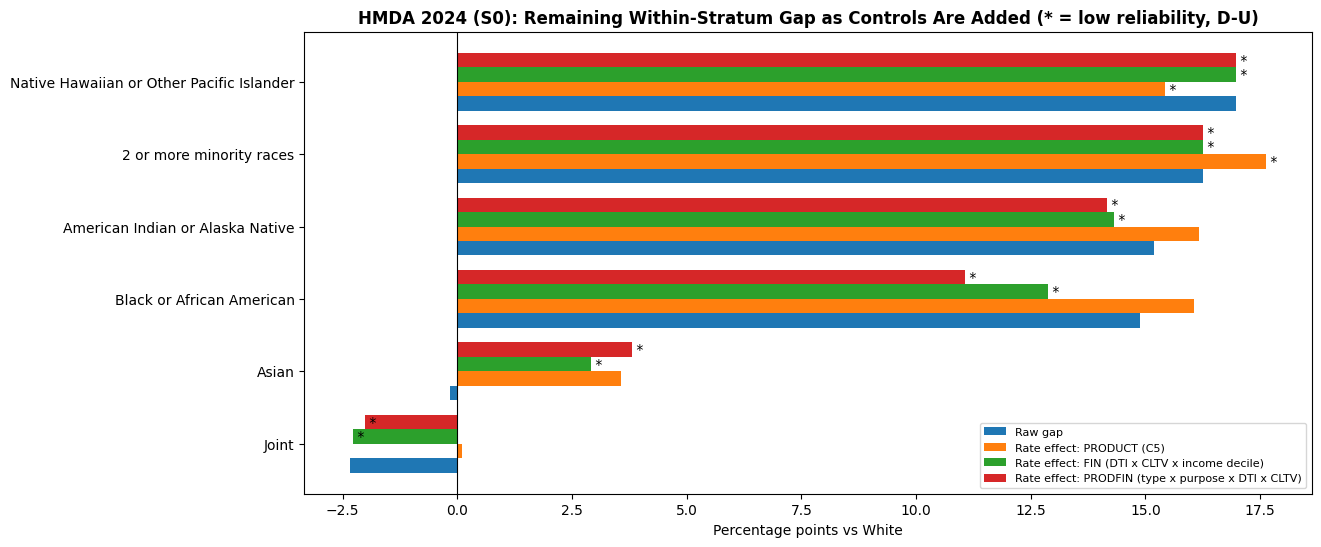

In [55]:
# Step 1: Within-stratum gap as controls are added (raw gap vs rate effect)
pv = D4.pivot(index="group", columns="spec", values="rate_pp"); raw = D4.drop_duplicates("group").set_index("group")["raw_gap_pp"]
lowr = D4.pivot(index="group", columns="spec", values="low_reliability")
pv = pv.assign(raw=raw)[["raw", "PRODUCT (C5)", *SPECS.keys()]].sort_values("raw")
fig, ax = plt.subplots(figsize=(13, 6)); w = 0.2; x = np.arange(len(pv))
for i, col in enumerate(pv.columns):
    ax.barh(x + (i - 1.5) * w, pv[col], w, label="Raw gap" if col == "raw" else f"Rate effect: {col}")
    if col != "raw":
        for xi, g in zip(x, pv.index):
            if bool(lowr.loc[g, col]): ax.text(pv.loc[g, col], xi + (i - 1.5) * w, " *", va="center")
ax.axvline(0, color="black", linewidth=0.8); ax.set_yticks(x); ax.set_yticklabels(pv.index); ax.legend(fontsize=8)
ax.set_xlabel(f"Percentage points vs {REF_RACE}"); ax.set_title("HMDA 2024 (S0): Remaining Within-Stratum Gap as Controls Are Added (* = low reliability, D-U)", fontweight="bold")
save_fig_and_log(fig, "B14_fig_19_gap_by_controls.png"); plt.show()

In [56]:
   display(D4[D4["spec"] != "PRODUCT (C5)"][["spec", "group", "n_strata_kept", "n_strata_pooled", "pooled_share_max_pct", "low_reliability"]])

,spec,group,n_strata_kept,n_strata_pooled,pooled_share_max_pct,low_reliability
6,FIN (DTI x CLTV x income decile),Black or African American,260,876,47.5508,True
7,FIN (DTI x CLTV x income decile),Asian,128,1001,65.6492,True
8,FIN (DTI x CLTV x income decile),Joint,6,1123,96.3787,True
9,FIN (DTI x CLTV x income decile),American Indian or Alaska Native,2,1126,98.4459,True
10,FIN (DTI x CLTV x income decile),2 or more minority races,0,1128,100.0000,True
11,FIN (DTI x CLTV x income decile),Native Hawaiian or Other Pacific Islander,0,1129,100.0000,True
12,PRODFIN (type x purpose x DTI x CLTV),Black or African American,205,1388,20.5134,True
13,PRODFIN (type x purpose x DTI x CLTV),Asian,117,1453,38.9084,True
14,PRODFIN (type x purpose x DTI x CLTV),Joint,14,1558,87.4363,True
15,PRODFIN (type x purpose x DTI x CLTV),American Indian or Alaska Native,2,1564,97.8162,True


### Interpretation — Steps D4 & D5 (`B14_rq2_stratified_gap.csv`, `B14_rq2_common_support.csv`, Fig 19)
 
*All figures are read from the saved tables (as of run 2026-11-10, B14 D4 / D5) and Decision D-X.*
 
1. **What pattern is observed?**
   - **Common support (D5).** In FIN (DTI × CLTV × income decile), 96.75% of Black and 97.32% of Asian applicants are in strata where White has at least 1,000 applications (all six groups: 96.5–97.3%). In PRODFIN (loan type × purpose × DTI × CLTV) the range is 94.26% (Black) to 97.90% (Asian). Only 742 of 1,149 FIN strata and 448 of 1,629 PRODFIN strata pass this White-side test.
   - **Reliability of the decomposition (D4).** After pooling strata that fail D-M (D-U), every headline group is `low_reliability` in both specs. Pooled share (max of group and White) is 47.55% (Black) and 65.65% (Asian) in FIN, and 20.51% and 38.91% in PRODFIN. For 2+ minority races and Native Hawaiian or Other Pacific Islander no stratum is kept in either spec, so the "rate effect" equals the raw gap by construction.
   - **Consequence (D-X).** These decompositions are **not estimable at this granularity**. The values in the table (for example Black rate effect +12.88 pp in FIN and +11.06 pp in PRODFIN, against +14.88 pp raw) are kept in the CSV for traceability only and must not be quoted as the remaining gap.
   - **The only reliable decomposition is the product-level one (C5):** composition −1.19 pp and rate +16.07 pp for Black applicants, with 0.82% pooled share.
2. **What evidence supports the finding?**
   - `B14_rq2_common_support.csv`, `B14_rq2_stratified_gap.csv` (identity residual below 1e-9 in every row) and Figure 19 (low-reliability bars are starred).
3. **Why might it matter in mortgage lending?**
   - Minority and White applicants are not in disjoint parts of the observed financial space: more than 94% of each group sits in cells where many White applicants also apply. The obstacle is cell size of the **minority** group, not a lack of White comparators.
   - Headline conclusions therefore rest on the raw gap with its lender-cluster interval (C1), the product-level decomposition (C5), and the coarse specification in G2. A model that pools information across strata (B15) is the natural next step `[Hypothesis]`.
4. **What alternative explanations or limitations apply?**
   - The direction of the bias from pooling is not guaranteed: composition differences inside the pooled stratum are counted as "rate" with symmetric weights, so the rate effect tends to be too large `[Hypothesis]` (D-X).
   - D5 uses only the White-side threshold; it does not test the minority-side cell size (that is what D-U pooling does).
   - Common support is defined on observed bins. Within a supported cell, credit score and assets may still differ between groups.

## D6: Missing Financial Data as Selection (Assumption A8)
- **Input:** `df_s0` (missing indicators for `income`, DTI, CLTV, `property_value`, and `~fin_complete`).
- **Process:**
  - For each indicator and each slicing dimension (race, outcome, exempt filer, loan purpose, lender size bucket): rows, missing rows, denials, denials among missing rows, hence % missing and denial rate of missing vs present rows.
  - Retention S0 -> `fin_complete` by race and the change in the raw gap when restricted to `fin_complete` (selection effect on the gap).
  - `[Hypothesis]` Missingness is informative and not random (to be judged from the output, not asserted).
- **Output:** `B14_rq2_missingness_selection.csv`, `B14_rq2_fin_complete_gap.csv`, `B14_fig_20_missingness.png`.

In [57]:
# Step 1: Missing indicators and slicing keys (positional arrays, no row copies)
den8 = df_s0["is_denied"].astype("int8").to_numpy()
MISS = {"income": df_s0["income"].isna(), "dti": df_s0["dti_bin_fine"].isna(), "cltv": df_s0["combined_loan_to_value_ratio"].isna(),
        "property_value": df_s0["property_value"].isna(), "any_fin_incomplete": ~df_s0["fin_complete"]}
KEYS = {"race": pd.Categorical(df_s0["derived_race"]), "outcome": pd.Categorical(np.where(den8 == 1, "Denied", "Not denied")),
        "exempt_filer": pd.Categorical(np.where(df_s0["is_exempt_filer"], "Exempt filer", "Non-exempt")),
        "loan_purpose": pd.Categorical(df_s0["loan_purpose"]), "lender_size": pd.Categorical(df_s0["lender_size_bucket"])}

# Step 2: Aggregate every indicator x dimension
parts = []
for var, m in MISS.items():
    m8 = m.to_numpy()
    for by, key in KEYS.items():
        t = pd.DataFrame({"k": key, "m": m8, "d": den8}); t["dm"] = t["m"] & (t["d"] == 1)
        g = t.groupby("k", observed=True, dropna=False).agg(n=("m", "size"), n_missing=("m", "sum"), n_denied=("d", "sum"), den_missing=("dm", "sum")).reset_index()
        assert int(g["n"].sum()) == len(df_s0); g["k"] = g["k"].astype("string").fillna("NULL / Missing")
        g.insert(0, "dimension", by); g.insert(0, "indicator", var); parts.append(g.rename(columns={"k": "level"}))
D6 = pd.concat(parts, ignore_index=True)
D6["pct_missing"] = D6["n_missing"] * 100.0 / D6["n"]
D6["denial_rate_missing_pct"] = D6["den_missing"] * 100.0 / D6["n_missing"].replace(0, np.nan)
D6["denial_rate_present_pct"] = (D6["n_denied"] - D6["den_missing"]) * 100.0 / (D6["n"] - D6["n_missing"]).replace(0, np.nan)
save_and_log(D6, "B14_rq2_missingness_selection.csv")

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_missingness_selection.csv | Size: 12.33 KB | Shape: (115, 10)


WindowsPath('d:/H-NEU/004/44 - Big Data/Final project/B14 - EDA/output/B14_rq2_missingness_selection.csv')

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_fin_complete_gap.csv | Size: 1.34 KB | Shape: (9, 9)


,n_s0,n_fin,rate_s0_pct,rate_fin_pct,gap_s0_pp,gap_fin_pp,retention_pct,gap_shift_pp
derived_race,,,,,,,,
White,5360624,4699459,21.9200,19.6300,0.0000,0.0000,87.6700,0.0000
Race Not Available,1275240,1027404,29.6600,25.8700,7.7400,6.2400,80.5700,-1.5000
Black or African American,733103,615372,36.8000,33.4000,14.8800,13.7700,83.9400,-1.1000
Asian,478497,446231,21.7700,20.6800,-0.1600,1.0500,93.2600,1.2000
Joint,184536,162116,19.5800,17.0700,-2.3400,-2.5600,87.8500,-0.2200
American Indian or Alaska Native,61397,49896,37.1100,32.8200,15.1900,13.1900,81.2700,-2.0000
2 or more minority races,20920,17556,38.1800,34.7700,16.2600,15.1400,83.9200,-1.1200
Native Hawaiian or Other Pacific Islander,20249,17351,38.8900,36.3600,16.9600,16.7200,85.6900,-0.2400
Free Form Text Only,2098,1978,58.3400,57.1300,36.4200,37.5000,94.2800,1.0800


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_20_missingness.png | Size: 143.60 KB


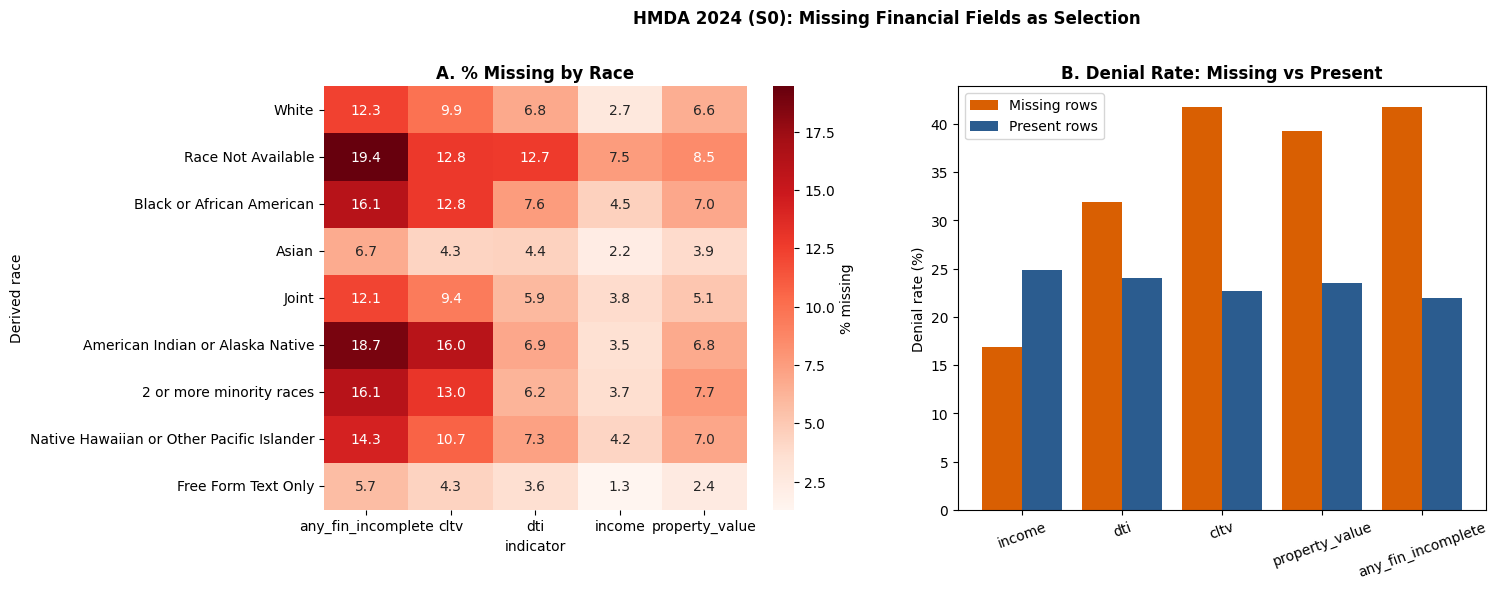

In [58]:
# Step 1: Retention and gap on S0 vs fin_complete
res = {}
for name, m in {"S0": np.ones(len(df_s0), bool), "fin_complete": df_s0["fin_complete"].to_numpy()}.items():
    res[name] = rate_gap_table(agg_on(df_s0.loc[m, ["derived_race", "is_denied"]], ["derived_race"]), "derived_race", REF_RACE).set_index("derived_race")
D6B = pd.DataFrame({"n_s0": res["S0"]["n_apps"], "n_fin": res["fin_complete"]["n_apps"], "rate_s0_pct": res["S0"]["denial_rate_pct"],
                    "rate_fin_pct": res["fin_complete"]["denial_rate_pct"], "gap_s0_pp": res["S0"]["gap_pp"], "gap_fin_pp": res["fin_complete"]["gap_pp"]}).loc[C1["derived_race"]]
D6B["retention_pct"] = D6B["n_fin"] * 100.0 / D6B["n_s0"]; D6B["gap_shift_pp"] = D6B["gap_fin_pp"] - D6B["gap_s0_pp"]
save_and_log(D6B.reset_index(), "B14_rq2_fin_complete_gap.csv"); display(D6B.round(2))

# Step 2: Heatmap of % missing by race + denial rate of missing vs present rows (all S0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
pm = D6[D6["dimension"] == "race"].pivot(index="level", columns="indicator", values="pct_missing").reindex(C1["derived_race"]).astype("float64")
sns.heatmap(pm, annot=True, fmt=".1f", cmap="Reds", ax=ax1, cbar_kws={"label": "% missing"}); ax1.set_title("A. % Missing by Race", fontweight="bold"); ax1.set_ylabel("Derived race")
tot = D6[D6["dimension"] == "race"].groupby("indicator")[["n", "n_missing", "n_denied", "den_missing"]].sum().loc[list(MISS)]
xx = np.arange(len(tot)); ax2.bar(xx - 0.2, tot["den_missing"] * 100 / tot["n_missing"], 0.4, color="#d95f02", label="Missing rows")
ax2.bar(xx + 0.2, (tot["n_denied"] - tot["den_missing"]) * 100 / (tot["n"] - tot["n_missing"]), 0.4, color="#2b5c8f", label="Present rows")
ax2.set_xticks(xx); ax2.set_xticklabels(tot.index, rotation=20); ax2.set_ylabel("Denial rate (%)"); ax2.legend(); ax2.set_title("B. Denial Rate: Missing vs Present", fontweight="bold")
fig.suptitle("HMDA 2024 (S0): Missing Financial Fields as Selection", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_20_missingness.png"); plt.show()

### Interpretation — Step D6 (`B14_rq2_missingness_selection.csv`, `B14_rq2_fin_complete_gap.csv`, Fig 20)
 
*Figures are read from the saved tables (as of run 2026-11-10, B14 D6). Rows with `dimension = outcome` are not used for denial rates (they are 100% or 0% by construction).*
 
1. **What pattern is observed?**
   - **Size and outcome.** 1,099,301 rows (13.51% of S0) are not `fin_complete`; their denial rate is 41.80% against 21.94% for complete rows. By field: DTI missing on 7.65% of S0 (denial 31.91% vs 24.02%), CLTV 10.31% (41.75% vs 22.65%), `property_value` 6.71% (39.27% vs 23.57%). **Income is the exception:** missing on 3.65% of S0 with a lower denial rate (16.89% vs 24.91%).
   - **Exempt filers.** The 241,108 full-exempt rows are all incomplete (21.93% of incomplete rows) and have a denial rate of 12.99%. The other 858,193 incomplete rows (10.87% of non-exempt S0) have 49.90% denial against 21.94% for complete rows.
   - **By race.** The share not `fin_complete` is 12.33% for White, 16.06% for Black, 19.43% for `Race Not Available`, 18.73% for AIAN and 6.74% for Asian. The denial rate of incomplete rows is 54.54% for Black and 38.20% for White.
   - **By lender size and purpose.** Mega lenders hold 660,874 incomplete rows (60.12% of all incomplete rows; 16.98% of their own applications). In Small/Community lenders 58.06% of rows are incomplete (231,511 rows). Because there are 241,108 exempt filers in total, Full exempt filers are only in Small/Community lenders (202,992 rows, 50.91% of that bucket) and Medium lenders (38,116 rows); Large and Mega lenders have none (as of run 2026-11-11, B14 F10). The incomplete rows at Mega lenders are therefore not exempt filers. The direction of the denial difference depends on purpose: home purchase 41.06% (incomplete) vs 10.41% (complete), but rate/term refinance 18.93% vs 25.09%.
   - **Effect on gaps.** Retention in `fin_complete` is 87.67% for White and 83.94% for Black. The Black–White gap moves from 14.88 pp to 13.77 pp (−1.10 pp, 7.4% of the raw gap); AIAN −2.00 pp, `Race Not Available` −1.50 pp. The Asian–White gap changes from −0.16 pp to +1.05 pp (sign change, 1.20 pp).
2. **What evidence supports the finding?**
   - `B14_rq2_missingness_selection.csv` (sums to S0 for every indicator and dimension), `B14_rq2_fin_complete_gap.csv` and `B14_fig_20_missingness.png`.
3. **Why might it matter in mortgage lending?**
   - Missing financial fields are associated with the outcome and with race, so a gap estimated only on complete cases partly reflects **selection**: about 1.1 pp of the Black–White gap disappears by restricting the sample, before any control is added. Any narrowing reported in Step 3 of the sequential framework must be compared with this shift, not with S0.
4. **What alternative explanations or limitations apply?**
   - The reverse sign for income and for refinances `[Hypothesis: income reported as not applicable on streamline-type files that are rarely denied; early denials with unfinished files push the other way]`. This mixture is not tested here.
   - The share of the Small/Community rows that are exempt filers, and what the remaining rows are, can be checked with F10 (exempt status by lender size) `[Hypothesis until checked]`.
   - The exempt filers (low denial, all incomplete) pull the incomplete-group denial rate down, so the 1.1 pp shift mixes an exempt-filer effect and a non-exempt incomplete-file effect; the two are not separated here.
   - The Asian sign change is small (1.20 pp) and may come from the changed White benchmark (21.92% → 19.63%) rather than from Asian applicants.
   - Assumption A8 is supported descriptively, not proven.

## D7: Denial Reasons (Denied Applications Only; Descriptive, Never a Predictor)
- **Input:** `df_s0` rows with `is_denied == 1`; `denial_reason_1..4`.
- **Process:** By race: % of denied applications whose **primary** reason (`denial_reason_1`) is each code, and % citing it in **any of the 4 fields**. Codes: 1 DTI, 2 Employment, 3 Credit history, 4 Collateral, 5 Insufficient cash, 6 Unverifiable, 7 Incomplete, 8 MI denied, 9 Other, 10 N/A `[Verified: Data Dictionary]`; `1111` (Exempt) and NULL are kept as separate rows (T06/T10). Also: % of denials citing DTI by DTI bin, and citing Collateral by CLTV bin.
- **Output:** `B14_rq2_denial_reasons.csv`, `B14_rq2_denial_reasons_by_stratum.csv`, `B14_fig_21_denial_reasons.png`.

In [59]:
# Step 1: Denied-only frame and share helper
REASONS = {"1": "DTI", "2": "Employment history", "3": "Credit history", "4": "Collateral", "5": "Insufficient cash",
           "6": "Unverifiable info", "7": "Incomplete application", "8": "MI denied", "9": "Other", "10": "Not applicable", "1111": "Exempt (1111)"}
sub = df_s0.loc[df_s0["is_denied"] == 1, ["derived_race", "dti_cat", "cltv_bin"] + [f"denial_reason_{k}" for k in range(1, 5)]]
def share_by(mask, key):
    s = mask.groupby(sub[key], observed=True).mean() * 100
    if key == "derived_race": s.loc["All denied"] = mask.mean() * 100
    return s
dn = sub.groupby("derived_race", observed=True).size(); dn.loc["All denied"] = len(sub)

# Step 2: Primary and any-of-4 shares per reason code (+ NULL primary)
rows = []
for code, lab in {**REASONS, "NULL": "Missing"}.items():
    prim = sub["denial_reason_1"].isna() if code == "NULL" else sub["denial_reason_1"] == code
    anyk = prim if code == "NULL" else pd.concat([sub[f"denial_reason_{k}"] == code for k in range(1, 5)], axis=1).any(axis=1)
    for r, p, a in zip(share_by(prim, "derived_race").index, share_by(prim, "derived_race"), share_by(anyk, "derived_race")):
        rows.append({"race": r, "code": code, "label": lab, "n_denied_group": int(dn[r]), "pct_primary": p, "pct_any_of_4": a})
D7 = pd.DataFrame(rows); save_and_log(D7, "B14_rq2_denial_reasons.csv")
chk = D7[D7["race"] == "All denied"]; assert abs(chk["pct_primary"].sum() - 100) < 1e-6, "Primary reasons do not sum to 100%"

# Step 3: Reason vs financial stratum (DTI cited by DTI bin; collateral cited by CLTV bin)
cited = lambda c: pd.concat([sub[f"denial_reason_{k}"] == c for k in range(1, 5)], axis=1).any(axis=1)
D7B = pd.concat([share_by(cited("1"), "dti_cat").rename("pct_citing").reset_index().rename(columns={"dti_cat": "level"}).assign(stratum="dti_cat", reason="DTI (1)"),
                 share_by(cited("4"), "cltv_bin").rename("pct_citing").reset_index().rename(columns={"cltv_bin": "level"}).assign(stratum="cltv_bin", reason="Collateral (4)")])
save_and_log(D7B, "B14_rq2_denial_reasons_by_stratum.csv")

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_denial_reasons.csv | Size: 8.86 KB | Shape: (120, 6)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_denial_reasons_by_stratum.csv | Size: 0.94 KB | Shape: (20, 4)


WindowsPath('d:/H-NEU/004/44 - Big Data/Final project/B14 - EDA/output/B14_rq2_denial_reasons_by_stratum.csv')

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_21_denial_reasons.png | Size: 167.95 KB


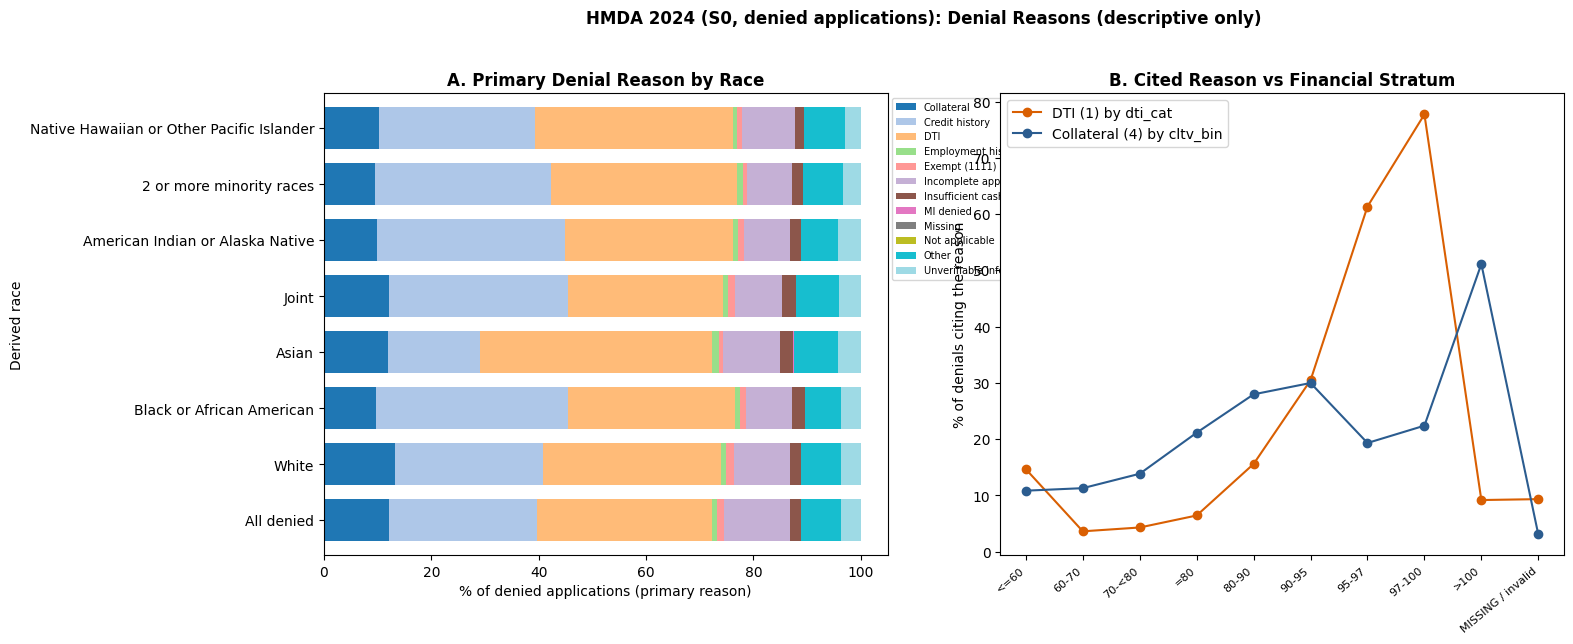

In [60]:
# Step 1: Stacked primary reasons by headline race + reason-vs-stratum lines
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
pv = D7[D7["race"].isin(HEADLINE_RACES + ["All denied"])].pivot(index="race", columns="label", values="pct_primary").astype("float64")
pv = pv.loc[["All denied"] + HEADLINE_RACES]; pv.plot(kind="barh", stacked=True, ax=ax1, colormap="tab20", width=0.75)
ax1.set_xlabel("% of denied applications (primary reason)"); ax1.set_ylabel("Derived race"); ax1.set_title("A. Primary Denial Reason by Race", fontweight="bold"); ax1.legend(fontsize=7, bbox_to_anchor=(1, 1))
for (st, rs), col in zip([("dti_cat", "DTI (1)"), ("cltv_bin", "Collateral (4)")], ["#d95f02", "#2b5c8f"]):
    s = D7B[D7B["stratum"] == st]; ax2.plot(range(len(s)), s["pct_citing"].to_numpy(), marker="o", color=col, label=f"{rs} by {st}")
    ax2.set_xticks(range(len(s))); ax2.set_xticklabels(s["level"], rotation=40, ha="right", fontsize=8)
ax2.set_ylabel("% of denials citing the reason"); ax2.set_title("B. Cited Reason vs Financial Stratum", fontweight="bold"); ax2.legend()
fig.suptitle("HMDA 2024 (S0, denied applications): Denial Reasons (descriptive only)", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_21_denial_reasons.png"); plt.show()

### D7c: Denial Reasons as Denials per 100 Applications
* **Input**: D7 (D7 cell), C1 (applications and denial rate per race), REF_RACE.
* **Process**:
    * The shares in D7 are computed **among denied applications only**. They show what lenders cite, but they cannot be compared across races as contributions to a gap, because the denial rate differs by race (36.80% vs 21.92%).
    * Contribution of reason r for race **g = (share of denied citing r) × (denial rate of g) = denials citing r per 100 applications of g**. Two versions: primary (denial_reason_1 only; the reasons partition the denials, so the differences vs White add up exactly to the raw gap) and any_of_4 (up to four reasons per file, so they overlap and do not add up).
    * Difference vs White = contribution of g minus contribution of White, in percentage points.
    * Check: for every race the primary differences sum to the raw gap in C1.
* **Output**: output/B14_rq2_denial_reasons_contribution.csv

In [61]:
# Step 1: Denials per 100 applications by reason and race (denominator = all S0 applications of the race)
n_apps_race = C1.set_index("derived_race")["n_apps"].astype("float64")
d7c = D7[D7["race"] != "All denied"].copy()
d7c["n_apps"] = d7c["race"].map(n_apps_race)
d7c["denial_rate_pct"] = d7c["n_denied_group"] / d7c["n_apps"] * 100.0
for k in ("primary", "any_of_4"):
    d7c[f"per100_{k}"] = d7c[f"pct_{k}"] / 100.0 * d7c["denial_rate_pct"]

# Step 2: Difference vs reference race for the same reason code
ref_d7 = d7c[d7c["race"] == REF_RACE].set_index("code")[["per100_primary", "per100_any_of_4"]]
d7c = d7c.join(ref_d7, on="code", rsuffix="_ref")
for k in ("primary", "any_of_4"):
    d7c[f"diff_{k}_pp"] = d7c[f"per100_{k}"] - d7c[f"per100_{k}_ref"]
gap_race = C1.set_index("derived_race")["gap_pp"]
d7c["raw_gap_pp"] = d7c["race"].map(gap_race)
d7c["share_of_raw_gap_primary_pct"] = np.where(d7c["raw_gap_pp"].abs() >= MIN_GAP_PP_FOR_SHARE,
                                               d7c["diff_primary_pp"] * 100.0 / d7c["raw_gap_pp"], np.nan)   # D-U rule

# Step 3: Check (primary differences add up to the raw gap), save, show Black vs White
prim_sum = d7c.groupby("race")["diff_primary_pp"].sum()
assert np.allclose(prim_sum, gap_race.loc[prim_sum.index]), "Primary-reason differences do not add up to the raw gap"
save_and_log(d7c, "B14_rq2_denial_reasons_contribution.csv")
BW_ = "Black or African American"
display(d7c[d7c["race"] == BW_].sort_values("diff_primary_pp", ascending=False)
        [["label", "per100_primary", "per100_primary_ref", "diff_primary_pp", "share_of_raw_gap_primary_pct", "diff_any_of_4_pp"]])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_denial_reasons_contribution.csv | Size: 24.49 KB | Shape: (108, 16)


,label,per100_primary,per100_primary_ref,diff_primary_pp,share_of_raw_gap_primary_pct,diff_any_of_4_pp
20,Credit history,13.1775,6.0519,7.1256,47.9025,8.4523
0,DTI,11.4348,7.2543,4.1805,28.1037,5.3860
60,Incomplete application,3.2017,2.2876,0.9141,6.1453,1.0884
80,Other,2.4878,1.6214,0.8664,5.8245,1.7258
30,Collateral,3.5878,2.8953,0.6924,4.6550,1.1117
50,Unverifiable info,1.3270,0.8006,0.5263,3.5384,0.7347
40,Insufficient cash,0.8686,0.4511,0.4176,2.8070,1.2948
10,Employment history,0.3246,0.2159,0.1087,0.7310,0.2527
100,Exempt (1111),0.3802,0.3395,0.0407,0.2734,0.0407
70,MI denied,0.0067,0.0038,0.0028,0.0191,0.0036


## D8: Pricing among Originated Loans (conditional on origination)
- **Input:** `df_s0` rows with `action_taken == "1"`; `interest_rate`, `rate_spread`, `total_loan_costs`, `flag_rate_range`.
- **Process:** Median interest rate (V04-flagged rates excluded, D-C), median `rate_spread` and median `total_loan_costs` by race x loan type; cells need at least `N_MIN_APPS` originated loans. Gap in median rate vs White within the same loan type. **Conditional on origination**: denied applicants have no price, so this is selected and not comparable to the denial analysis.
- **Output:** `B14_rq2_pricing_by_race.csv`, `B14_fig_22_pricing_gap.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq2_pricing_by_race.csv | Size: 3.02 KB | Shape: (36, 11)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_22_pricing_gap.png | Size: 85.62 KB


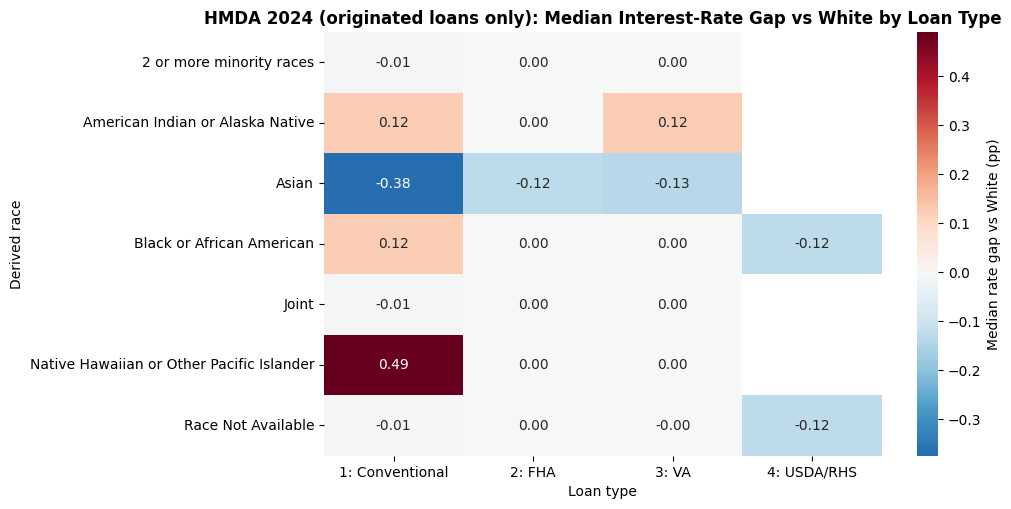

In [62]:
# Step 1: Originated frame (few columns), V04-excluded rate
o = df_s0.loc[df_s0["action_taken"] == "1", ["derived_race", "loan_type", "interest_rate", "rate_spread", "total_loan_costs", "flag_rate_range"]].copy()
o["rate_ok"] = o["interest_rate"].where(~o["flag_rate_range"])
g = o.groupby(["derived_race", "loan_type"], observed=True)
D8 = pd.DataFrame({"n_originated": g.size(), "n_rate": g["rate_ok"].count(), "median_rate_pct": g["rate_ok"].median(),
                   "n_spread": g["rate_spread"].count(), "median_rate_spread": g["rate_spread"].median(),
                   "n_costs": g["total_loan_costs"].count(), "median_total_loan_costs": g["total_loan_costs"].median()}).reset_index()
D8["low_n"] = D8["n_originated"] < N_MIN_APPS
for c in ("derived_race", "loan_type"): D8[c] = D8[c].astype("string")
ref = D8[D8["derived_race"] == REF_RACE].set_index("loan_type")["median_rate_pct"]
D8["rate_gap_vs_ref_pp"] = D8["median_rate_pct"] - D8["loan_type"].map(ref).astype("float64")
save_and_log(D8, "B14_rq2_pricing_by_race.csv")

# Step 2: Heatmap of median-rate gap vs White (valid cells only)
pv = D8[~D8["low_n"] & (D8["derived_race"] != REF_RACE)].pivot(index="derived_race", columns="loan_type", values="rate_gap_vs_ref_pp").astype("float64")
pv.columns = [CAT_LABELS["loan_type"].get(c, c) for c in pv.columns]
fig, ax = plt.subplots(figsize=(9, 5.5)); sns.heatmap(pv, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Median rate gap vs White (pp)"})
ax.set_title("HMDA 2024 (originated loans only): Median Interest-Rate Gap vs White by Loan Type", fontweight="bold"); ax.set_xlabel("Loan type"); ax.set_ylabel("Derived race")
save_fig_and_log(fig, "B14_fig_22_pricing_gap.png"); plt.show()

### Interpretation — Steps D7 & D8 (`B14_rq2_denial_reasons.csv`, `B14_rq2_denial_reasons_contribution.csv`, `B14_rq2_denial_reasons_by_stratum.csv`, `B14_rq2_pricing_by_race.csv`, Fig 21–22)
 
*Figures are read from the saved tables (as of run 2026-11-11, B14 D7 / D7c / D8).*
 
1. **What pattern is observed?**
   - **Reasons among denied applications (D7, N = 2,003,276).** Main primary reasons: debt-to-income (32.65% primary, 37.44% in any of the 4 fields), credit history (27.46%, 33.02%), incomplete application (12.23%, 13.03%), collateral (12.16%, 15.78%), other (7.29%, 12.86%), unverifiable information (3.75%, 5.70%) and insufficient cash (2.18%, 5.50%). Code `1111` (Exempt) is 1.31%; `10` (Not applicable) and Missing are 0.00% on denied rows.
   - **Shares differ by race.** Among denied Black applicants credit history is the first primary reason (35.81%; any-of-4 42.68%); AIAN 34.97% (41.33%); White 27.61% (33.09%); Asian 17.12% (21.50%). For Asian denied applicants the first reason is DTI (43.29%; 47.38%), against 33.09% for White and 31.08% for Black. For `Race Not Available` incomplete application is 21.44% (22.37%), against 10.44% for White and 8.70% for Black.
   - **Contribution to the Black–White gap (D7c, denials per 100 applications).** The shares above are conditional on denial and cannot be compared as contributions. Multiplying by each race's denial rate gives denials per 100 applications; the primary-reason differences vs White add up exactly to the raw gap of 14.88 pp (asserted in the code):
     | Primary reason | Black per 100 | White per 100 | Difference (pp) | Share of raw gap |
     |---|---|---|---|---|
     | Credit history | 13.18 | 6.05 | +7.13 | 47.90% |
     | DTI | 11.43 | 7.25 | +4.18 | 28.10% |
     | Incomplete application | 3.20 | 2.29 | +0.91 | 6.15% |
     | Other | 2.49 | 1.62 | +0.87 | 5.82% |
     | Collateral | 3.59 | 2.90 | +0.69 | 4.66% |
     | Unverifiable information | 1.33 | 0.80 | +0.53 | 3.54% |
     | Insufficient cash | 0.87 | 0.45 | +0.42 | 2.81% |
     | Employment history | 0.32 | 0.22 | +0.11 | 0.73% |
     | Exempt (1111) | 0.38 | 0.34 | +0.04 | 0.27% |
     Credit history and DTI together are 76.0% of the raw gap; the other reasons are 24.0%. With all four reason fields counted (overlapping, so not additive) the differences are credit history +8.45 pp, DTI +5.39 pp, other +1.73, insufficient cash +1.29, collateral +1.11 and incomplete application +1.09.
   - **Why the DTI share is misleading.** The primary DTI share is *lower* for Black (31.08%) than for White (33.09%), yet DTI-cited denials are 11.43 vs 7.25 per 100 applications (+4.18 pp), because Black applicants are denied much more often.
   - **Asian applicants.** Using the same method on the Asian rows of the contribution table (any-of-4), credit history is −2.57 pp vs White and DTI +2.01 pp; the Asian rows should be confirmed in the CSV.
   - **Reason vs financial bin (D7B).** Share of denied applications citing DTI: 14.66% below 20, 3.62% (20–<30), 4.30% (30–<36), 6.43% (36–40), 15.59% (41–45), 30.47% (46–49), 61.34% (50–60), 77.72% (above 60); missing DTI: 9.18% (`NA`), 9.34% (`Exempt`). It is not monotonic over the whole scale (the bin below 20 is high) but rises steadily from DTI 36–40 upward. Share citing collateral: 10.84% (CLTV <= 60), 11.29% (60–70), 13.85% (70–<80), 21.15% (=80), 27.97% (80–90), 29.98% (90–95), then 19.32% (95–97) and 22.40% (97–100), and 51.12% above 100; when CLTV is missing or invalid only 3.07% cite collateral.
   - **Pricing of originated loans (D8, conditional on origination).** FHA (loan type 2): median rate 6.250% for White, Black, Joint, Native Hawaiian or Other Pacific Islander, 2+ minority races, AIAN and `Race Not Available`; Asian 6.125% (−0.125 pp). VA (3): 6.125% for White, Black, Joint, Native Hawaiian or Other Pacific Islander and 2+ minority races; Asian 5.990% (−0.135 pp); AIAN 6.249% (+0.124 pp). Conventional (1): White 7.000% (rate spread 0.375 pp, median costs 4,658 USD); Black 7.125% (+0.125 pp; spread 0.580, +0.205 pp vs White; costs 4,670); AIAN 7.125% (spread 0.580); Native Hawaiian or Other Pacific Islander 7.490% (+0.490 pp; spread 0.594); Asian 6.625% (−0.375 pp; spread 0.096; costs 5,651).
2. **What evidence supports the finding?**
   - `B14_rq2_denial_reasons.csv` (primary reasons sum to 100% in every group), `B14_rq2_denial_reasons_contribution.csv` (primary differences sum to the raw gap, asserted), `B14_rq2_denial_reasons_by_stratum.csv`, `B14_rq2_pricing_by_race.csv`, Figures 21–22.
3. **Why might it matter in mortgage lending?**
   - Reasons are a direct, if partial, view of variables that public HMDA does not contain. On the primary measure, credit history is the largest single reason in the Black–White gap (47.90%) and DTI the second (28.10%). Both are large, so these data support neither "credit score explains the gap" nor "observed DTI explains the gap" alone.
   - The higher "incomplete application" share for `Race Not Available` is consistent with the higher missing-field share of this group in D6 (19.43% not `fin_complete`; DTI missing 12.69%, CLTV 12.78%) and with keeping the group separate (D-L) `[Hypothesis: not tested here]`.
   - In government-backed loans the median rates are almost the same across groups; in conventional loans the Black, AIAN and Native Hawaiian or Other Pacific Islander medians are above White and the Asian median is below.
4. **What alternative explanations or limitations apply?**
   - **Reasons are lender-reported, post-decision and chosen by the lender.** A reason is not a measured credit score. Reasons exist only for denied applications and are never predictors (A6, A3). The table is descriptive arithmetic, not a counterfactual: removing one reason would not remove the denial if another reason applies (D-AD).
   - **The 0.125 pp gaps are one step of the rate grid.** Reported rates are mostly multiples of 0.125 (6.125, 6.250, 7.000, 7.125), so a median that moves by 0.125 pp moved by one grid step. The spread difference (+0.205 pp for Black) carries more information.
   - **Selection and product mix (D8).** Pricing is seen only for originated loans; 36.80% of Black applications are denied against 21.92% of White, so originated Black borrowers are a more selected group. Conventional loans mix first liens, subordinate liens and lines of credit (B4b) `[Hypothesis]`, so part of the difference may be mix. Cells with fewer than 1,000 originated loans (loan type 4 for Asian, Joint, AIAN, Native Hawaiian or Other Pacific Islander and 2+ minority races, and all `Free Form Text Only` cells) are not interpreted (D-M).

## Checkpoint 4 Gate (eda_plan.md §14, Block 4)
- **Input:** Outputs of D0–D8.
- **Process:** Reconcile bins and aggregates with S0, check the Kitagawa identity for all specs, and confirm artifacts. Missingness and selection findings (D6) are shown for Human review.
- **Output:** `gate4` table.

In [63]:
# Step 1: Gate conditions
need4 = ["B14_rq2_profile_by_race.csv", "B14_rq2_bin_mix_by_race.csv", "B14_rq2_denial_curves.csv", "B14_rq2_dti_cltv_heatmap.csv",
         "B14_rq2_stratified_gap.csv", "B14_rq2_common_support.csv", "B14_rq2_missingness_selection.csv", "B14_rq2_fin_complete_gap.csv",
         "B14_rq2_denial_reasons.csv", "B14_rq2_denial_reasons_by_stratum.csv", "B14_rq2_pricing_by_race.csv"]
figs = [p.name for p in FIG_DIR.glob("B14_fig_*.png")]
gate4 = pd.DataFrame([
    ("Gate 4.1: all bins assigned (no NaN)", all(df_s0[k].notna().all() for k in BIN_COLS), f"{len(BIN_COLS)} columns"),
    ("Gate 4.2: Kitagawa identity < 1e-9 (all specs)", bool((D4["identity_residual_pp"].abs() < 1e-9).all()), f"{D4['spec'].nunique()} specs"),
    ("Gate 4.3: missingness table sums to S0", bool((D6.groupby(["indicator", "dimension"])["n"].sum() == len(df_s0)).all()), f"{len(MISS)} indicators"),
    ("Gate 4.4: denied rows in D7 equal S0 denials", int(len(sub)) == int((df_s0["is_denied"] == 1).sum()), f"{len(sub):,} denied"),
    ("Gate 4.5: Part D tables saved", all((OUTPUT_DIR / f).exists() for f in need4), f"{len(need4)} tables"),
    ("Gate 4.6: figures 16-22 saved", all(any(n.startswith(f"B14_fig_{i}") for n in figs) for i in range(16, 23)), f"{len(figs)} figures"),
], columns=["checkpoint_4_gate", "passed", "evidence"])
assert gate4["passed"].all(), "Checkpoint 4 gate failed!"
display(gate4); display(D6B.round(2))
print("[CHECKPOINT 4 PASSED] Pending Human review of missingness/selection findings. Next: Checkpoint 5 (Parts E and F).")

,checkpoint_4_gate,passed,evidence
0,Gate 4.1: all bins assigned (no NaN),True,5 columns
1,Gate 4.2: Kitagawa identity < 1e-9 (all specs),True,3 specs
2,Gate 4.3: missingness table sums to S0,True,5 indicators
3,Gate 4.4: denied rows in D7 equal S0 denials,True,"2,003,276 denied"
4,Gate 4.5: Part D tables saved,True,11 tables
5,Gate 4.6: figures 16-22 saved,True,23 figures


,n_s0,n_fin,rate_s0_pct,rate_fin_pct,gap_s0_pp,gap_fin_pp,retention_pct,gap_shift_pp
derived_race,,,,,,,,
White,5360624,4699459,21.9200,19.6300,0.0000,0.0000,87.6700,0.0000
Race Not Available,1275240,1027404,29.6600,25.8700,7.7400,6.2400,80.5700,-1.5000
Black or African American,733103,615372,36.8000,33.4000,14.8800,13.7700,83.9400,-1.1000
Asian,478497,446231,21.7700,20.6800,-0.1600,1.0500,93.2600,1.2000
Joint,184536,162116,19.5800,17.0700,-2.3400,-2.5600,87.8500,-0.2200
American Indian or Alaska Native,61397,49896,37.1100,32.8200,15.1900,13.1900,81.2700,-2.0000
2 or more minority races,20920,17556,38.1800,34.7700,16.2600,15.1400,83.9200,-1.1200
Native Hawaiian or Other Pacific Islander,20249,17351,38.8900,36.3600,16.9600,16.7200,85.6900,-0.2400
Free Form Text Only,2098,1978,58.3400,57.1300,36.4200,37.5000,94.2800,1.0800


[CHECKPOINT 4 PASSED] Pending Human review of missingness/selection findings. Next: Checkpoint 5 (Parts E and F).


## E0: Part E/F Preparation
- **Input:** `df_s0`, `df_samp` (D0 columns missing in the old sample).
- **Process:** `[CHANGE]` re-slice `df_samp` from `df_s0` (same row ids and seed). `dti_mid` is an ordinal midpoint of the DTI bin (`[Hypothesis]`: proxy for correlation/SMD only; not a measured DTI). Profile of extreme incomes (units: $1,000s).
- **Output:** `df_s0["dti_mid"]`, `B14_income_extreme_profile.csv`.

In [64]:
# Step 1: Re-slice the sample so it carries the Part D columns (same rows)
df_samp = df_s0.loc[df_samp.index].copy()

# Step 2: Ordinal DTI midpoint via a lookup on category codes (vectorised; code -1 -> NaN)
DTI_MID = {"<20": 15, "20-<30": 25, "30-<36": 33, "50-60": 55, ">60": 65, **{str(i): i for i in range(36, 50)}}
lut = np.append([DTI_MID.get(c, np.nan) for c in df_s0["dti_bin_fine"].cat.categories], np.nan)
df_s0["dti_mid"] = lut[df_s0["dti_bin_fine"].cat.codes.to_numpy()]
df_samp["dti_mid"] = df_s0.loc[df_samp.index, "dti_mid"]

# Step 3: Extreme income profile (income is in $1,000s)
inc = df_s0["income"]
ext = pd.DataFrame([{"income_gt_k_usd": t, "n_rows": int((inc > t).sum()),
                     "denial_rate_pct": float(df_s0.loc[inc > t, "is_denied"].mean() * 100) if (inc > t).any() else np.nan}
                    for t in (1_000, 10_000, 100_000)])
save_and_log(ext, "B14_income_extreme_profile.csv"); display(ext); display(inc.nlargest(5).rename("top5_income_k_usd").to_frame())

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_income_extreme_profile.csv | Size: 0.12 KB | Shape: (3, 3)


,income_gt_k_usd,n_rows,denial_rate_pct
0,1000,48829,19.7874
1,10000,1000,31.6000
2,100000,138,49.2754


,top5_income_k_usd
2664393,"100,000,000.0000"
6524738,"25,553,583.0000"
6821584,"17,399,830.0000"
7535387,"12,000,000.0000"
864746,"11,880,258.0000"


## E1: Numeric-Numeric Relationships
- **Input:** `df_samp` (stratified, seed fixed), `df_s0` for one full-data check.
- **Process:** Hexbin density (log colour) for income vs loan amount, property value vs loan amount, calculated LTV vs reported CLTV (y = x line), and CLTV vs interest rate (originated loans, V04 excluded; vertical lines at 80/95/97/100 show heaping). Spearman matrix on the sample (income <= 0 and CLTV <= 0 set to NaN). Plan risk 6: the headline correlation is re-checked on the full S0.
- **Output:** `B14_rel_spearman.csv`, `B14_fig_23_hexbin.png`; `SPEARMAN`.

Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_23_hexbin.png | Size: 689.23 KB


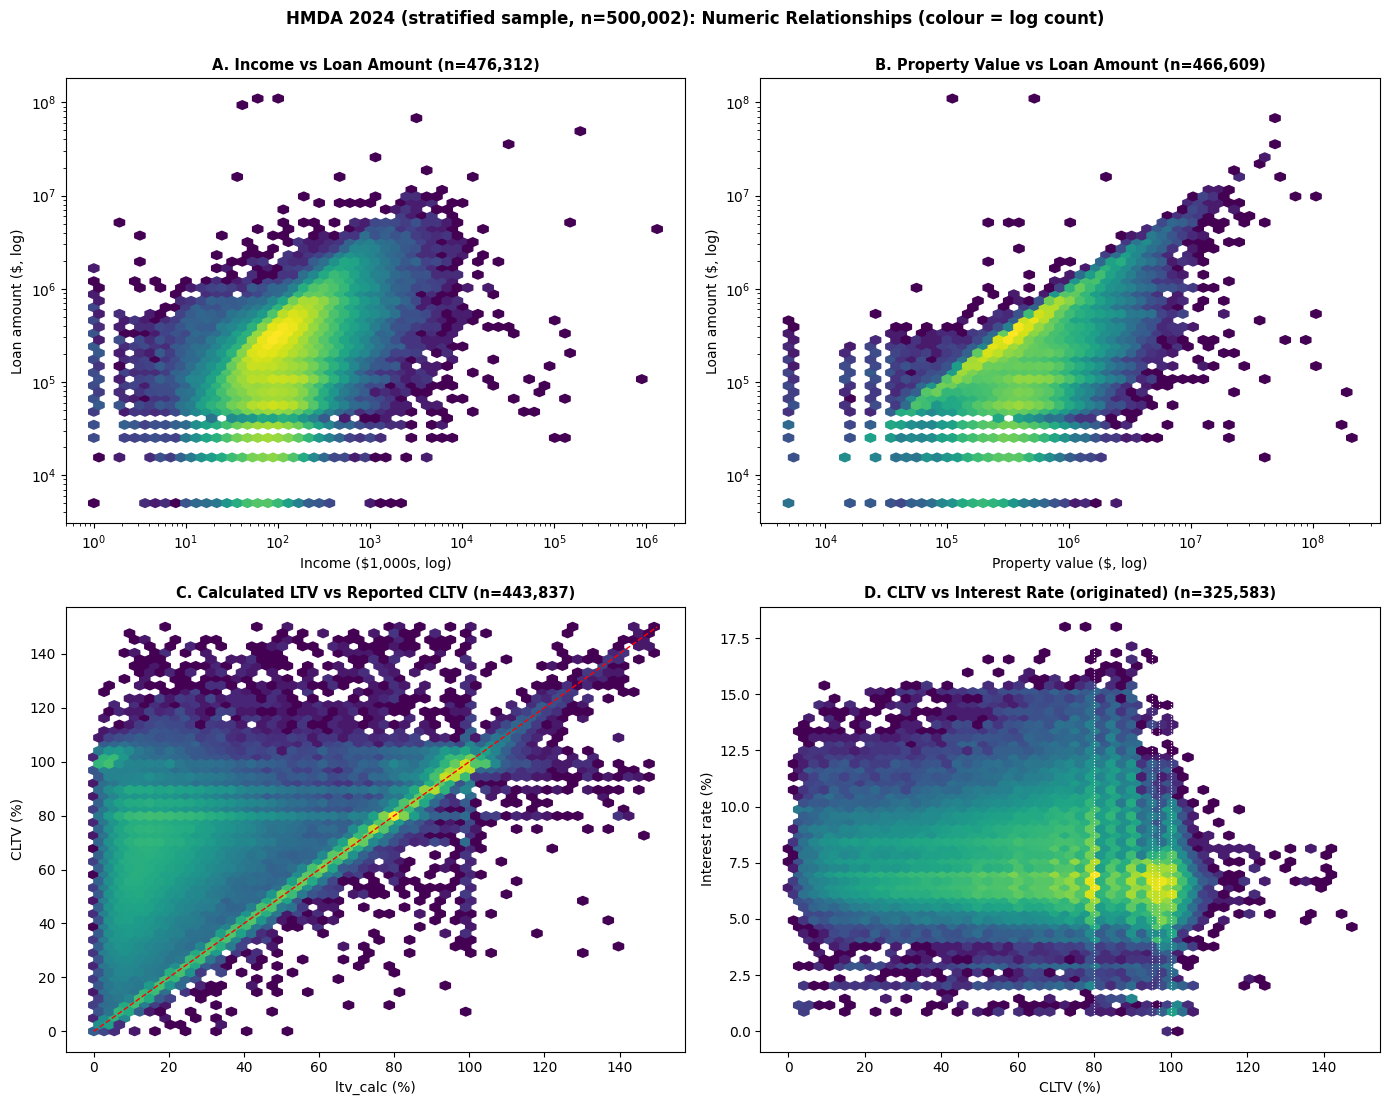

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rel_spearman.csv | Size: 1.77 KB | Shape: (9, 10)
Spearman(loan_amount, income): sample = 0.4638 | full S0 = 0.4642


In [65]:
# Step 1: Hexbin helper and four panels
def hb(ax, x, y, title, xl, yl, log=False):
    ok = x.notna() & y.notna()
    if log: ok &= (x > 0) & (y > 0)
    h = ax.hexbin(x[ok].to_numpy("float64"), y[ok].to_numpy("float64"), gridsize=55, bins="log", mincnt=1, cmap="viridis",
                  xscale="log" if log else "linear", yscale="log" if log else "linear")
    ax.set_title(f"{title} (n={int(ok.sum()):,})", fontsize=10.5, fontweight="bold"); ax.set_xlabel(xl); ax.set_ylabel(yl); return h
cl = df_samp["combined_loan_to_value_ratio"].where(df_samp["combined_loan_to_value_ratio"].between(0.01, 150))
ir = df_samp["interest_rate"].where(~df_samp["flag_rate_range"] & (df_samp["action_taken"] == "1") & (df_samp["interest_rate"] > 0))
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
hb(axes[0, 0], df_samp["income"], df_samp["loan_amount"], "A. Income vs Loan Amount", "Income ($1,000s, log)", "Loan amount ($, log)", True)
hb(axes[0, 1], df_samp["property_value"], df_samp["loan_amount"], "B. Property Value vs Loan Amount", "Property value ($, log)", "Loan amount ($, log)", True)
hb(axes[1, 0], df_samp["ltv_calc"].where(df_samp["ltv_calc"].between(0.01, 150)), cl, "C. Calculated LTV vs Reported CLTV", "ltv_calc (%)", "CLTV (%)")
axes[1, 0].plot([0, 150], [0, 150], "r--", linewidth=1)
hb(axes[1, 1], cl, ir, "D. CLTV vs Interest Rate (originated)", "CLTV (%)", "Interest rate (%)")
for h_val in (80, 95, 97, 100): axes[1, 1].axvline(h_val, color="white", linestyle=":", linewidth=0.8)
fig.suptitle(f"HMDA 2024 (stratified sample, n={len(df_samp):,}): Numeric Relationships (colour = log count)", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_23_hexbin.png"); plt.show()

# Step 2: Spearman on sample + full-data check of the headline pair
SP_VARS = ["loan_amount", "income", "property_value", "combined_loan_to_value_ratio", "ltv_calc", "loan_to_income", "dti_mid",
           "tract_minority_population_percent", "tract_to_msa_income_percentage"]
XS = df_samp[SP_VARS].astype("float64")
XS.loc[XS["income"] <= 0, "income"] = np.nan; XS.loc[XS["combined_loan_to_value_ratio"] <= 0, "combined_loan_to_value_ratio"] = np.nan
SPEARMAN = XS.corr(method="spearman"); save_and_log(SPEARMAN.reset_index().rename(columns={"index": "variable"}), "B14_rel_spearman.csv")
full = df_s0.loc[df_s0["income"] > 0, ["loan_amount", "income"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman(loan_amount, income): sample = {SPEARMAN.loc['loan_amount', 'income']:.4f} | full S0 = {full:.4f}")
assert abs(SPEARMAN.loc["loan_amount", "income"] - full) < 0.01, "Sample correlation differs from full S0"

### Interpretation — Steps E0 & E1 (`B14_income_extreme_profile.csv`, `B14_rel_spearman.csv`)
 
*Figures are read from the saved tables (as of run 2026-11-11, B14 E0–E1). The hexbin figure (Fig 23) is not used in this text.*
 
1. **What pattern is observed?**
   - **Extreme income (E0).** 48,829 S0 rows (0.60%) have income above 1,000 (thousand USD, i.e. above 1M USD) and a denial rate of 19.79%; 1,000 rows (0.0123%) are above 10M USD with 31.60% denial; 138 rows are above 100M USD with 49.28%. The denial rate rises with the threshold and crosses the S0 rate (24.62%) between the first and second threshold.
   - **Spearman correlations (sample, E1).** The highest off-diagonal values are `ltv_calc`–CLTV 0.707, `loan_to_income`–`loan_amount` 0.684, `loan_to_income`–`ltv_calc` 0.680 and `income`–`property_value` 0.649. `loan_amount` is only moderately related to `income` (0.464) and to `property_value` (0.497). DTI midpoint is negatively related to income (−0.318). Tract minority share and tract income level are negatively related (−0.261). No off-diagonal value exceeds 0.71 in absolute value.
2. **What evidence supports the finding?**
   - `B14_income_extreme_profile.csv` and `B14_rel_spearman.csv` (sample n ≈ 500,000, seed fixed). The E1 cell compares one correlation (`loan_amount`, `income`) with the full S0 and asserts a difference below 0.01; the printed full-S0 value should be copied into this cell after the run.
3. **Why might it matter in mortgage lending?**
   - The rows above 100M USD have a denial rate twice the S0 rate and look like reporting errors `[Hypothesis]` (D-W), but the 48,829 rows above 1M USD have a *lower* denial rate than S0 and look like genuine high-income applications. A single cut at 1M USD would remove them wrongly; the flag at 10M USD is kept as a diagnostic only. Means, variances and SMDs are the quantities that the extreme rows distort; Spearman and quantiles are robust to them.
   - CLTV and `ltv_calc` agree only moderately (0.707). This is the subordinate-lien effect found in B2 (V09): for a second lien `loan_amount` omits the senior lien. `loan_to_income` carries `loan_amount` and `income` at once, which is why it is correlated with `loan_amount` and negatively with income (−0.262).
4. **What alternative explanations or limitations apply?**
   - Spearman captures monotone association only; the U-shaped and J-shaped curves of D2 are not visible in it.
   - The sample is stratified by race × outcome, which is not the population; the full-S0 check on one pair is the only link back to S0.
   - Missing values are set to NaN pairwise, and missingness is informative (D6), so each coefficient uses a different subset of rows.

## E2: Association of Categorical Variables with the Outcome
- **Input:** `agg_counts` (full S0) for 20+ categorical variables.
- **Process:** From each 2 x k contingency table (denied / not denied by level): bias-corrected **Cramér's V** (Bergsma: chi-square minus its expected value under independence, so many-level variables are not inflated), **mutual information** (MI, nats) and MI / H(is_denied), and the denial-rate spread across levels with >= `N_MIN_APPS`. High-cardinality variables (state, MSA) still carry finite-sample MI bias. Association only; not a causal or importance ranking.
- **Output:** `B14_rel_cramers_v.csv`, `B14_fig_25_association.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rel_cramers_v.csv | Size: 2.48 KB | Shape: (25, 6)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_25_association.png | Size: 116.32 KB


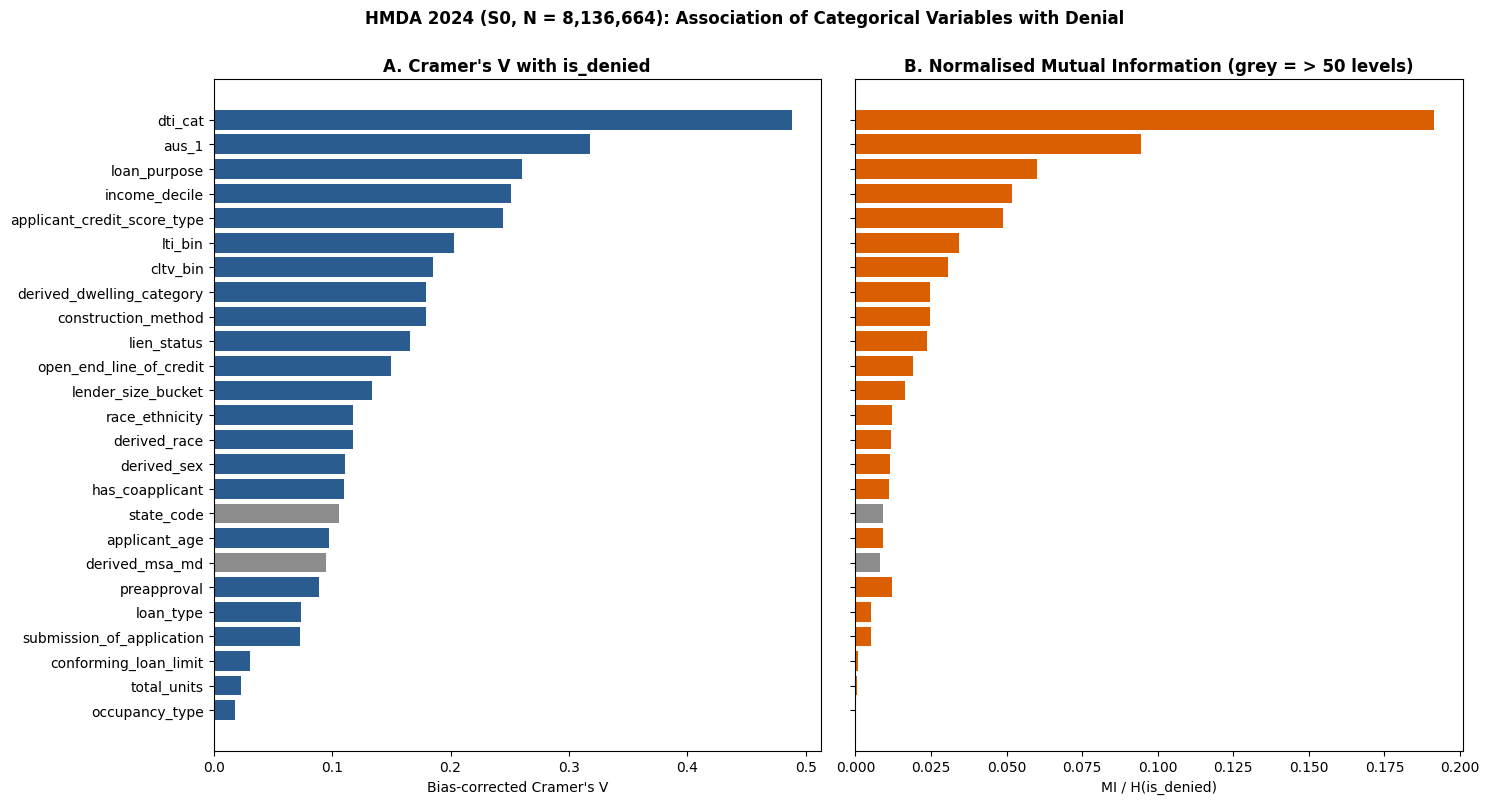

In [66]:
# Step 1: Statistics from a counts table (exact, no sampling)
def assoc_from_counts(g):
    n, d = g["n_apps"].to_numpy(float), g["n_denied"].to_numpy(float); N, D = n.sum(), d.sum()
    O = np.vstack([d, n - d]); E = np.outer([D, N - D], n) / N; k = len(n)
    chi2 = ((O - E) ** 2 / E).sum(); phi2 = max(0.0, chi2 / N - (k - 1) / (N - 1))
    kc, rc = k - (k - 1) ** 2 / (N - 1), 2 - 1 / (N - 1)
    P = O / N; px, py = P.sum(0), P.sum(1)[:, None]
    with np.errstate(divide="ignore", invalid="ignore"): mi = np.nansum(P * np.log(P / (py * px)))
    ok = g["n_apps"] >= N_MIN_APPS; rt = g.loc[ok, "n_denied"] / g.loc[ok, "n_apps"] * 100
    return np.sqrt(phi2 / min(kc - 1, rc - 1)), mi, mi / -(py * np.log(py)).sum(), (rt.max() - rt.min()) if ok.any() else np.nan, k

# Step 2: Loop over variables
CAT_REL = B5_COLS + ["derived_race", "race_ethnicity", "derived_sex", "applicant_age", "has_coapplicant", "state_code",
                     "derived_msa_md", "dti_cat", "cltv_bin", "income_decile", "lti_bin"]
rows = []
for var in CAT_REL:
    v, mi, mi_n, sp, k = assoc_from_counts(agg_counts([var]))
    rows.append({"variable": var, "n_levels": k, "cramers_v_bc": v, "mi_nats": mi, "mi_norm_by_entropy_y": mi_n, "rate_spread_pp": sp})
REL_V = pd.DataFrame(rows).sort_values("cramers_v_bc", ascending=False).reset_index(drop=True)
assert REL_V["cramers_v_bc"].between(0, 1).all() and (REL_V["mi_nats"] >= -1e-12).all()
save_and_log(REL_V, "B14_rel_cramers_v.csv")

# Step 3: Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8), sharey=True); y = np.arange(len(REL_V))[::-1]
hi = REL_V["n_levels"] > 50
ax1.barh(y, REL_V["cramers_v_bc"], color=np.where(hi, "#8c8c8c", "#2b5c8f")); ax2.barh(y, REL_V["mi_norm_by_entropy_y"], color=np.where(hi, "#8c8c8c", "#d95f02"))
ax1.set_yticks(y); ax1.set_yticklabels(REL_V["variable"]); ax1.set_xlabel("Bias-corrected Cramer's V"); ax2.set_xlabel("MI / H(is_denied)")
ax1.set_title("A. Cramer's V with is_denied", fontweight="bold"); ax2.set_title("B. Normalised Mutual Information (grey = > 50 levels)", fontweight="bold")
fig.suptitle(f"HMDA 2024 (S0, N = {len(df_s0):,}): Association of Categorical Variables with Denial", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_25_association.png"); plt.show()

### Interpretation — Step E2 (`B14_rel_cramers_v.csv`)
 
*Figures are read from the saved table (as of run 2026-11-11, B14 E2). Fig 25 is not used.*
 
1. **What pattern is observed?**
   - The bias-corrected Cramér's V with `is_denied` (25 variables, computed from exact counts on full S0) is largest for `dti_cat` (0.488; normalised mutual information 0.191), then `aus_1` (0.318), `loan_purpose` (0.260), `income_decile` (0.251), `applicant_credit_score_type` (0.244), `lti_bin` (0.203) and `cltv_bin` (0.185).
   - `derived_race` has V = 0.118 (rank 14 of 25) and `race_ethnicity` 0.118; `derived_sex` 0.111, `has_coapplicant` 0.110, `state_code` 0.106, `derived_msa_md` 0.095, `applicant_age` 0.098. The lowest are `conforming_loan_limit` 0.031, `total_units` 0.023 and `occupancy_type` 0.018.
   - The spread of the denial rate across levels with at least 1,000 applications is 78.9 pp for `dti_cat`, 67.1 pp for `lti_bin`, 62.2 pp for `applicant_credit_score_type`, 55.0 pp for `state_code`, 45.4 pp for `income_decile` and 38.8 pp for `derived_race`.
2. **What evidence supports the finding?**
   - `B14_rel_cramers_v.csv` (V in [0, 1] and MI >= 0 asserted in the code).
3. **Why might it matter in mortgage lending?**
   - DTI is the variable most associated with denial (V about four times that of race), which fits the J-shaped curve and the DTI cliff in D2. `loan_purpose` and the income and leverage bins come next. Race is associated with denial at about a quarter of the strength of DTI. This ordering supports putting DTI, income and CLTV in the financial-controls stage as bins (D-V, D-AF).
   - `aus_1` and `applicant_credit_score_type` rank second and fifth, but they stay out of the main specification (D-Y): `aus_1 = 6` (Not applicable) is 66.16% of denied vs 33.79% of non-denied applications (A3), so part of this association comes from which code is reported, not from underwriting quality `[Hypothesis]`.
4. **What alternative explanations or limitations apply?**
   - The 38.8 pp race spread is the difference between `Free Form Text Only` (58.34%, 2,098 applications) and Joint (19.58%); it is not a spread between the large groups.
   - `preapproval` has V = 0.089 only because preapproval = 1 has no denials in S0 (denied preapprovals are `action_taken = 7` and removed by F01, B5). It is a selection artefact, not an association.
   - `dti_cat` includes the `MISSING: na` (44.53% denial) and `MISSING: exempt` levels, so part of its V comes from missingness. The V without the missing levels is printed by the check cell after Checkpoint 5; its value should be added here.
   - Finite-sample bias of mutual information is about (k − 1)/(2N) nats for a 2 × k table `[standard asymptotic result]`; for `derived_msa_md` (418 levels, N = 8,136,664) this is about 0.00003 against an observed 0.0046, so it is negligible here.
   - Association only; V is not an importance ranking and variables overlap strongly (product, lien, line of credit).

## E3: Collinearity Preview (VIF and Redundant Pairs)
- **Input:** `df_samp` numeric controls, `SPEARMAN` (E1).
- **Process:** Complete cases only (`pct_complete` reported, because missingness is informative, A8). Variables winsorised at sample p01/p99 **for this diagnostic only** (no data change). VIF_i = i-th diagonal of the inverse correlation matrix (pseudo-inverse), so no extra library. VIF > 5 / 10 flags redundancy. `log_lti` = log(loan) - log(income) by construction, so a high VIF there is expected. Pairs with |r| > 0.8 are listed.
- **Output:** `B14_rel_vif.csv`, `B14_rel_redundant_pairs.csv`, `B14_fig_24_corr_vif.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rel_vif.csv | Size: 0.60 KB | Shape: (9, 5)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rel_redundant_pairs.csv | Size: 0.02 KB | Shape: (0, 3)


,variable,vif,n_complete,pct_complete,flag_vif_gt10
0,log_loan_amount,84.1605,423726,84.7449,True
1,log_income,36.2391,423726,84.7449,True
2,log_property_value,7.9202,423726,84.7449,False
3,cltv,2.3183,423726,84.7449,False
4,ltv_calc,13.6957,423726,84.7449,True
5,log_lti,63.8058,423726,84.7449,True
6,dti_mid,1.5300,423726,84.7449,False
7,tract_minority_pct,1.1295,423726,84.7449,False
8,tract_income_pct,1.3599,423726,84.7449,False


,var_a,var_b,pearson_r


Largest |r| among controls: ltv_calc vs log_lti = 0.749
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_24_corr_vif.png | Size: 205.20 KB


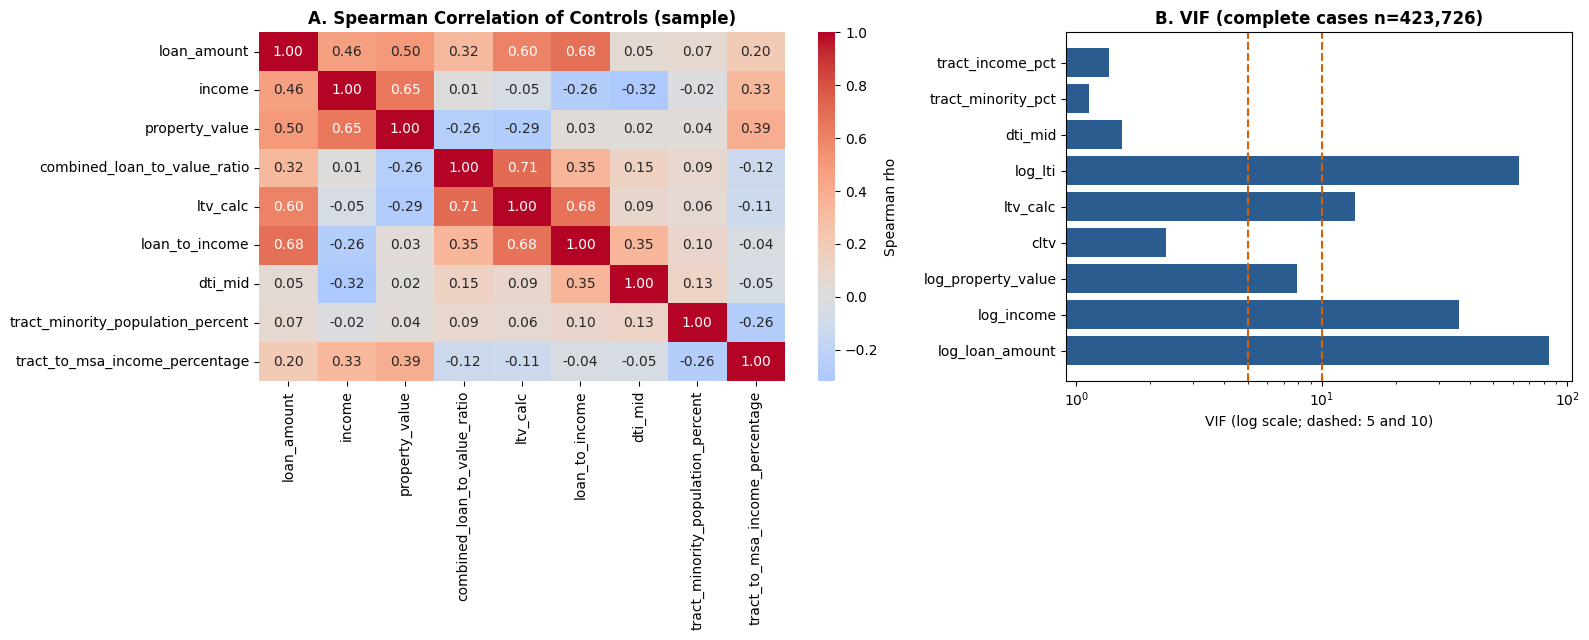

In [67]:
# Step 1: Numeric control block (logs where skewed), complete cases, winsorise
pos = lambda s: s.where(s > 0)
X3 = pd.DataFrame({
    "log_loan_amount": df_samp["log_loan_amount"],
    "log_income": df_samp["log_income"],
    "log_property_value": np.log(pos(df_samp["property_value"])),
    "cltv": pos(df_samp["combined_loan_to_value_ratio"]),
    "ltv_calc": df_samp["ltv_calc"],
    "log_lti": np.log(pos(df_samp["loan_to_income"])),
    "dti_mid": df_samp["dti_mid"],
    "tract_minority_pct": df_samp["tract_minority_population_percent"],
    "tract_income_pct": df_samp["tract_to_msa_income_percentage"],
})
n_samp = len(X3)
X3 = X3.replace([np.inf, -np.inf], np.nan).dropna()
X3 = X3.clip(X3.quantile(0.01), X3.quantile(0.99), axis=1)

# Step 2: VIF and redundant pairs
R = np.corrcoef(X3.to_numpy().T)
VIF_DF = pd.DataFrame({
    "variable": X3.columns,
    "vif": np.diag(np.linalg.pinv(R)),
    "n_complete": len(X3),
    "pct_complete": len(X3) * 100.0 / n_samp,
})
VIF_DF["flag_vif_gt10"] = VIF_DF["vif"] > 10
save_and_log(VIF_DF, "B14_rel_vif.csv")

# [CHANGE] Step 2 of E3: give the pairs table fixed columns so an empty result is still readable
pairs = pd.DataFrame(
    [
        {"var_a": X3.columns[i], "var_b": X3.columns[j], "pearson_r": R[i, j]}
        for i in range(len(R))
        for j in range(i + 1, len(R))
        if abs(R[i, j]) > 0.8
    ],
    columns=["var_a", "var_b", "pearson_r"],
)
save_and_log(pairs, "B14_rel_redundant_pairs.csv")
display(VIF_DF)
display(pairs)

iu = np.triu_indices(len(R), 1)
k = np.argmax(np.abs(R[iu]))
print(f"Largest |r| among controls: {X3.columns[iu[0][k]]} vs {X3.columns[iu[1][k]]} = {R[iu][k]:.3f}")

# Step 3: Spearman heatmap + VIF bars
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(SPEARMAN, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax1, cbar_kws={"label": "Spearman rho"})
ax1.set_title("A. Spearman Correlation of Controls (sample)", fontweight="bold")
ax2.barh(VIF_DF["variable"], VIF_DF["vif"], color="#2b5c8f")
ax2.set_xscale("log")
for t in (5, 10):
    ax2.axvline(t, color="#d95f02", linestyle="--")
ax2.set_xlabel("VIF (log scale; dashed: 5 and 10)")
ax2.set_title(f"B. VIF (complete cases n={len(X3):,})", fontweight="bold")
plt.tight_layout()
save_fig_and_log(fig, "B14_fig_24_corr_vif.png")
plt.show()

### Interpretation — Step E3 (`B14_rel_vif.csv`, `B14_rel_redundant_pairs.csv`)
 
*Figures are read from the saved tables (as of run 2026-11-11, B14 E3).*
 
1. **What pattern is observed?**
   - Complete cases: 423,726 rows (84.74% of the sample). VIF is 84.16 for `log_loan_amount`, 63.81 for `log_lti`, 36.24 for `log_income` and 13.70 for `ltv_calc` (all above 10); 7.92 for `log_property_value`; 2.32 for `cltv`, 1.53 for `dti_mid`, 1.36 for tract income level and 1.13 for tract minority share.
   - **No pair of controls has |r| > 0.8**, so the redundant-pairs table is empty.
2. **What evidence supports the finding?**
   - `B14_rel_vif.csv` and `B14_rel_redundant_pairs.csv`. The redundant-pairs file is written without a header when it is empty (2 bytes) and cannot be read back; see the code fix in section 4.
3. **Why might it matter in mortgage lending?**
   - The high VIFs are structural: `log_lti` = `log_loan_amount` − `log_income` exactly, and `ltv_calc` is built from the loan amount and the property value. Loan amount, income and LTI cannot all be in one model; the same holds for loan amount, property value and calculated LTV. Pairwise correlations did not show this, so the VIF check was needed. Decision D-AF sets the specification.
4. **What alternative explanations or limitations apply?**
   - 15.26% of the sample is dropped by the complete-case rule, and missingness is informative (D6), so the VIFs describe the complete-case structure only.
   - Variables are winsorised at the sample p01/p99 for this diagnostic only; `dti_mid` is a bin midpoint, not a measured DTI.
   - A low VIF for CLTV, DTI, and tract variables says they are not duplicates of the others; it does not say they are useful or valid as controls.

## E4: Race Association with Controls (Standardised Mean Differences)
- **Input:** `df_s0`, headline races vs White.
- **Process:** SMD = (mean_group - mean_White) / sqrt((sd_group² + sd_White²) / 2), on **valid** values of each numeric control (log scale where skewed), with the share of valid values per group (`pct_valid`). |SMD| > 0.1 is a conventional "meaningful imbalance" flag (`[Hypothesis: convention]`). It shows which controls could plausibly narrow the gap; it does not say they explain it. Categorical product mix is in C3.
- **Output:** `B14_rel_smd_by_race.csv`, `B14_fig_26_smd.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rel_smd_by_race.csv | Size: 5.46 KB | Shape: (48, 7)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_26_smd.png | Size: 80.86 KB


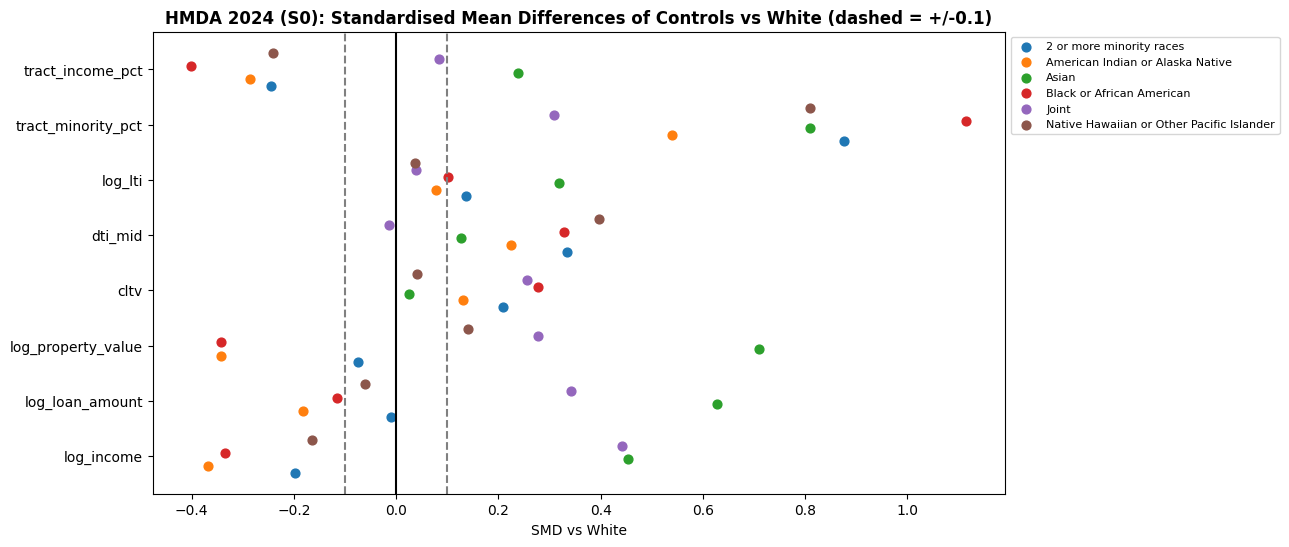

In [68]:
# Step 1: Control variables on full S0
SMD_VARS = {"log_income": df_s0["log_income"], "log_loan_amount": df_s0["log_loan_amount"],
# [CHANGE] E4: exclude CLTV values flagged by rule V03 (<= 0 or > 200); no new threshold
            "log_property_value": np.log(pos(df_s0["property_value"])), "cltv": pos(df_s0["combined_loan_to_value_ratio"]).where(~df_s0["flag_cltv_range"]),
            "dti_mid": df_s0["dti_mid"], "log_lti": np.log(pos(df_s0["loan_to_income"])),
            "tract_minority_pct": df_s0["tract_minority_population_percent"], "tract_income_pct": df_s0["tract_to_msa_income_percentage"]}
rows = []
for name, s in SMD_VARS.items():
    gq = s.groupby(df_s0["derived_race"], observed=True).agg(["mean", "std", "count"]); ref = gq.loc[REF_RACE]
    for g in [r for r in HEADLINE_RACES if r != REF_RACE]:
        sd = np.sqrt((gq.loc[g, "std"] ** 2 + ref["std"] ** 2) / 2)
        rows.append({"race": g, "variable": name, "mean_group": gq.loc[g, "mean"], "mean_ref": ref["mean"], "smd": (gq.loc[g, "mean"] - ref["mean"]) / sd,
                     "pct_valid_group": gq.loc[g, "count"] * 100.0 / race_n[g]})
SMD_DF = pd.DataFrame(rows); SMD_DF["flag_abs_gt_0_1"] = SMD_DF["smd"].abs() > 0.1
save_and_log(SMD_DF, "B14_rel_smd_by_race.csv")

# Step 2: Love plot
fig, ax = plt.subplots(figsize=(11, 6)); vars_ = list(SMD_VARS); ypos = {v: i for i, v in enumerate(vars_)}
for k, (g, t) in enumerate(SMD_DF.groupby("race")):
    ax.scatter(t["smd"], [ypos[v] + (k - 2.5) * 0.12 for v in t["variable"]], label=g, s=40)
for x in (-0.1, 0.1): ax.axvline(x, color="grey", linestyle="--")
ax.axvline(0, color="black"); ax.set_yticks(range(len(vars_))); ax.set_yticklabels(vars_); ax.set_xlabel(f"SMD vs {REF_RACE}"); ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
ax.set_title("HMDA 2024 (S0): Standardised Mean Differences of Controls vs White (dashed = +/-0.1)", fontweight="bold")
save_fig_and_log(fig, "B14_fig_26_smd.png"); plt.show()

## E5 (optional): Univariate AUC of Numeric Controls
- **Input:** `XS` (E1), `df_samp["is_denied"]`.
- **Process:** AUC of each control alone (rank-based Mann-Whitney) on non-missing rows; reported as max(AUC, 1 - AUC) with the direction, and `n_valid`. No model fitting. Missingness is informative, so AUC reflects only rows with the value present.
- **Output:** `B14_rel_univariate_auc.csv`.

In [69]:
# Step 1: Rank-based AUC per numeric control
y = df_samp["is_denied"].astype("int8"); rows = []
for c in XS.columns:
    ok = XS[c].notna(); r = XS.loc[ok, c].rank(); y1 = y[ok] == 1; n1, n0 = int(y1.sum()), int((~y1).sum())
    auc = (r[y1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    rows.append({"variable": c, "n_valid": int(ok.sum()), "auc": auc, "auc_oriented": max(auc, 1 - auc), "direction": "higher -> more denial" if auc > 0.5 else "higher -> less denial"})
AUC_DF = pd.DataFrame(rows).sort_values("auc_oriented", ascending=False); save_and_log(AUC_DF, "B14_rel_univariate_auc.csv"); display(AUC_DF)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rel_univariate_auc.csv | Size: 0.80 KB | Shape: (9, 5)


,variable,n_valid,auc,auc_oriented,direction
6,dti_mid,461808,0.6825,0.6825,higher -> more denial
0,loan_amount,500002,0.3456,0.6544,higher -> less denial
1,income,476312,0.3580,0.6420,higher -> less denial
4,ltv_calc,466609,0.4148,0.5852,higher -> less denial
2,property_value,466609,0.4320,0.5680,higher -> less denial
3,combined_loan_to_value_ratio,448655,0.4332,0.5668,higher -> less denial
5,loan_to_income,476312,0.4515,0.5485,higher -> less denial
7,tract_minority_population_percent,494161,0.5479,0.5479,higher -> more denial
8,tract_to_msa_income_percentage,494161,0.4562,0.5438,higher -> less denial


### Interpretation — Steps E4 & E5 (`B14_rel_smd_by_race.csv`, `B14_rel_univariate_auc.csv`)
 
*Figures are read from the saved tables (as of run 2026-11-11, B14 E4–E5). Fig 26 is not used. The CLTV row of the SMD table is excluded from the findings because of the data problem described under limitations.*
 
1. **What pattern is observed?**
   - **Balance (E4).** SMD vs White (absolute value above 0.1 is flagged). Black: tract minority share +1.116 (mean 57.99 vs 30.45), tract income level −0.401 (96.5 vs 111.9), property value −0.344, income −0.334, DTI midpoint +0.328, loan amount −0.116, LTI +0.101. Asian: property value +0.710, loan amount +0.627, income +0.454, LTI +0.319, DTI midpoint +0.126, tract income +0.238, tract minority share +0.810. AIAN: income −0.368, property value −0.343, tract income −0.285, tract minority share +0.540, DTI +0.225, loan amount −0.182. Joint: income +0.442, loan amount +0.342, property value +0.278, tract minority share +0.309, DTI −0.014. 2+ minority races and Native Hawaiian or Other Pacific Islander: tract minority share +0.876 and +0.811, DTI +0.335 and +0.397.
   - **The largest imbalance is neighbourhood minority share** (0.31 to 1.12 for every group), larger than any financial control (largest absolute value 0.71, Asian property value).
   - **Univariate AUC (E5, sample).** Highest: DTI midpoint 0.683 (higher DTI → more denial), `loan_amount` 0.654 and `income` 0.642 (higher → less denial), `ltv_calc` 0.585, `property_value` 0.568, CLTV 0.567, LTI 0.549, tract minority share 0.548 and tract income level 0.544. `n_valid` is 448,655 to 500,002.
2. **What evidence supports the finding?**
   - `B14_rel_smd_by_race.csv` (valid share per group is in `pct_valid_group`: 84.0% to 99.7%) and `B14_rel_univariate_auc.csv`.
3. **Why might it matter in mortgage lending?**
   - Black, AIAN, 2+ minority races and Native Hawaiian or Other Pacific Islander applicants differ from White applicants in the direction of lower income and property value, higher DTI and neighbourhoods with a higher minority share; Asian and Joint applicants differ in the opposite direction on income and property value but still live in tracts with a higher minority share (Asian +0.810). This matches the mix found in D1 and the Asian sign pattern in C4/C5.
   - Controls for the neighbourhood can therefore absorb a large part of the race difference mechanically. Whether that is a legitimate control or a "bad control" that carries the same channel as race (location) cannot be decided from these tables `[Hypothesis]`; it is a question for the Stage 4 design.
   - DTI is the strongest single score (AUC 0.683), which supports DTI bins in Stage 3 (D-V, D-AF).
4. **What alternative explanations or limitations apply?**
   - **CLTV SMD is not usable.** It is −0.001 for every group, and the White mean is 1,584.8 against 153.1 for Black. This pattern comes from a few extreme CLTV values (S0 CLTV has a very large standard deviation, B1), not from the balance of the groups, and it contradicts D1 (29.45% of Black vs 16.08% of White applications have CLTV above 95). The code fix is in section 4; the row must be recomputed.
   - SMD is computed on valid values only, and the valid share differs by group (CLTV 84.0% for AIAN, 95.7% for Asian); missingness is informative (D6).
   - `dti_mid` is an ordinal midpoint (D-V). The |SMD| > 0.1 flag is a convention `[Hypothesis]`. SMD shows imbalance, not explanation.
   - AUC is rank-based and measures monotone association only: LTI has AUC 0.549 although denial is 83.25% at LTI of 7 or more and 30.46% below 1 (D2). CLTV and `loan_amount` also mix products (small subordinate liens have high denial). A low AUC does not mean a weak control.

## F0: Helper `gap_vs_ref` (Part F)
- **Input:** a counts table (`derived_race`, level columns, `n_apps`, `n_denied`).
- **Process:** For each level, gap (pp) of one group vs the reference with a **Newcombe hybrid CI** (built from the two Wilson CIs, same method as C4); `low_n` if either cell fails D-M. Used for state, MSA, tract class and lender.
- **Output:** function `gap_vs_ref`.

In [70]:
def gap_vs_ref(agg, by, group, ref=REF_RACE):
    """Gap (pp) of `group` vs `ref` per level of `by` (list of columns), Newcombe CI; low_n if either cell fails D-M."""
    cols = ["n_apps", "n_denied"]
    j = (agg[agg["derived_race"] == group].set_index(by)[cols]).join(agg[agg["derived_race"] == ref].set_index(by)[cols], lsuffix="_g", rsuffix="_ref", how="inner")
    n1, d1, n0, d0 = (j[c].astype("float64") for c in ("n_apps_g", "n_denied_g", "n_apps_ref", "n_denied_ref"))
    l1, u1 = wilson_ci(d1, n1); l0, u0 = wilson_ci(d0, n0); p1, p0 = d1 * 100 / n1, d0 * 100 / n0
    o = pd.DataFrame({"group": group, "n_group": n1, "n_ref": n0, "rate_group_pct": p1, "rate_ref_pct": p0, "gap_pp": p1 - p0,
                      "gap_ci_lo": (p1 - p0) - np.sqrt((p1 - l1) ** 2 + (u0 - p0) ** 2),
                      "gap_ci_hi": (p1 - p0) + np.sqrt((u1 - p1) ** 2 + (p0 - l0) ** 2)}, index=j.index)
    o["low_n"] = (n1 < N_MIN_APPS) | (d1 < N_MIN_DENIED) | (n0 < N_MIN_APPS) | (d0 < N_MIN_DENIED)
    return o.reset_index()
NON_REF = [g for g in HEADLINE_RACES if g != REF_RACE]

## F1/F5: State-Level Gaps and Heterogeneity
- **Input:** `df_s0` (`state_code`, race), `gap_vs_ref`.
- **Process:** Gap vs White in each state for every headline group, with Newcombe CI; states failing D-M are `low_n` and excluded from plots and F5. **F5:** across valid states: SD of the gap, share of states with a negative gap, and correlation of the gap with the state's overall denial rate (to see whether gaps are larger where denial is high). The state map is optional (plotly; skipped if unavailable).
- **Output:** `B14_rq3_state_gap.csv`, `B14_rq3_state_gap_heterogeneity.csv`, `B14_fig_27_state_gap.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_state_gap.csv | Size: 50.41 KB | Shape: (325, 11)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_state_gap_heterogeneity.csv | Size: 0.73 KB | Shape: (4, 9)


,group,n_states_valid,mean_gap_pp,sd_gap_pp,min_gap_pp,max_gap_pp,share_states_gap_lt0_pct,pearson_gap_vs_state_rate,spearman_gap_vs_state_rate
0,American Indian or Alaska Native,18,15.5382,5.4256,8.1587,25.7648,0.0000,0.2769,0.2487
1,Asian,39,0.7460,2.6666,-6.2464,6.3501,38.4615,-0.4747,-0.4905
2,Black or African American,41,13.5240,5.6567,-6.2427,23.5694,2.4390,0.1038,0.2132
3,Joint,37,-1.6896,2.9327,-6.1392,7.9714,75.6757,0.0371,-0.0835


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_27_state_gap.png | Size: 176.84 KB


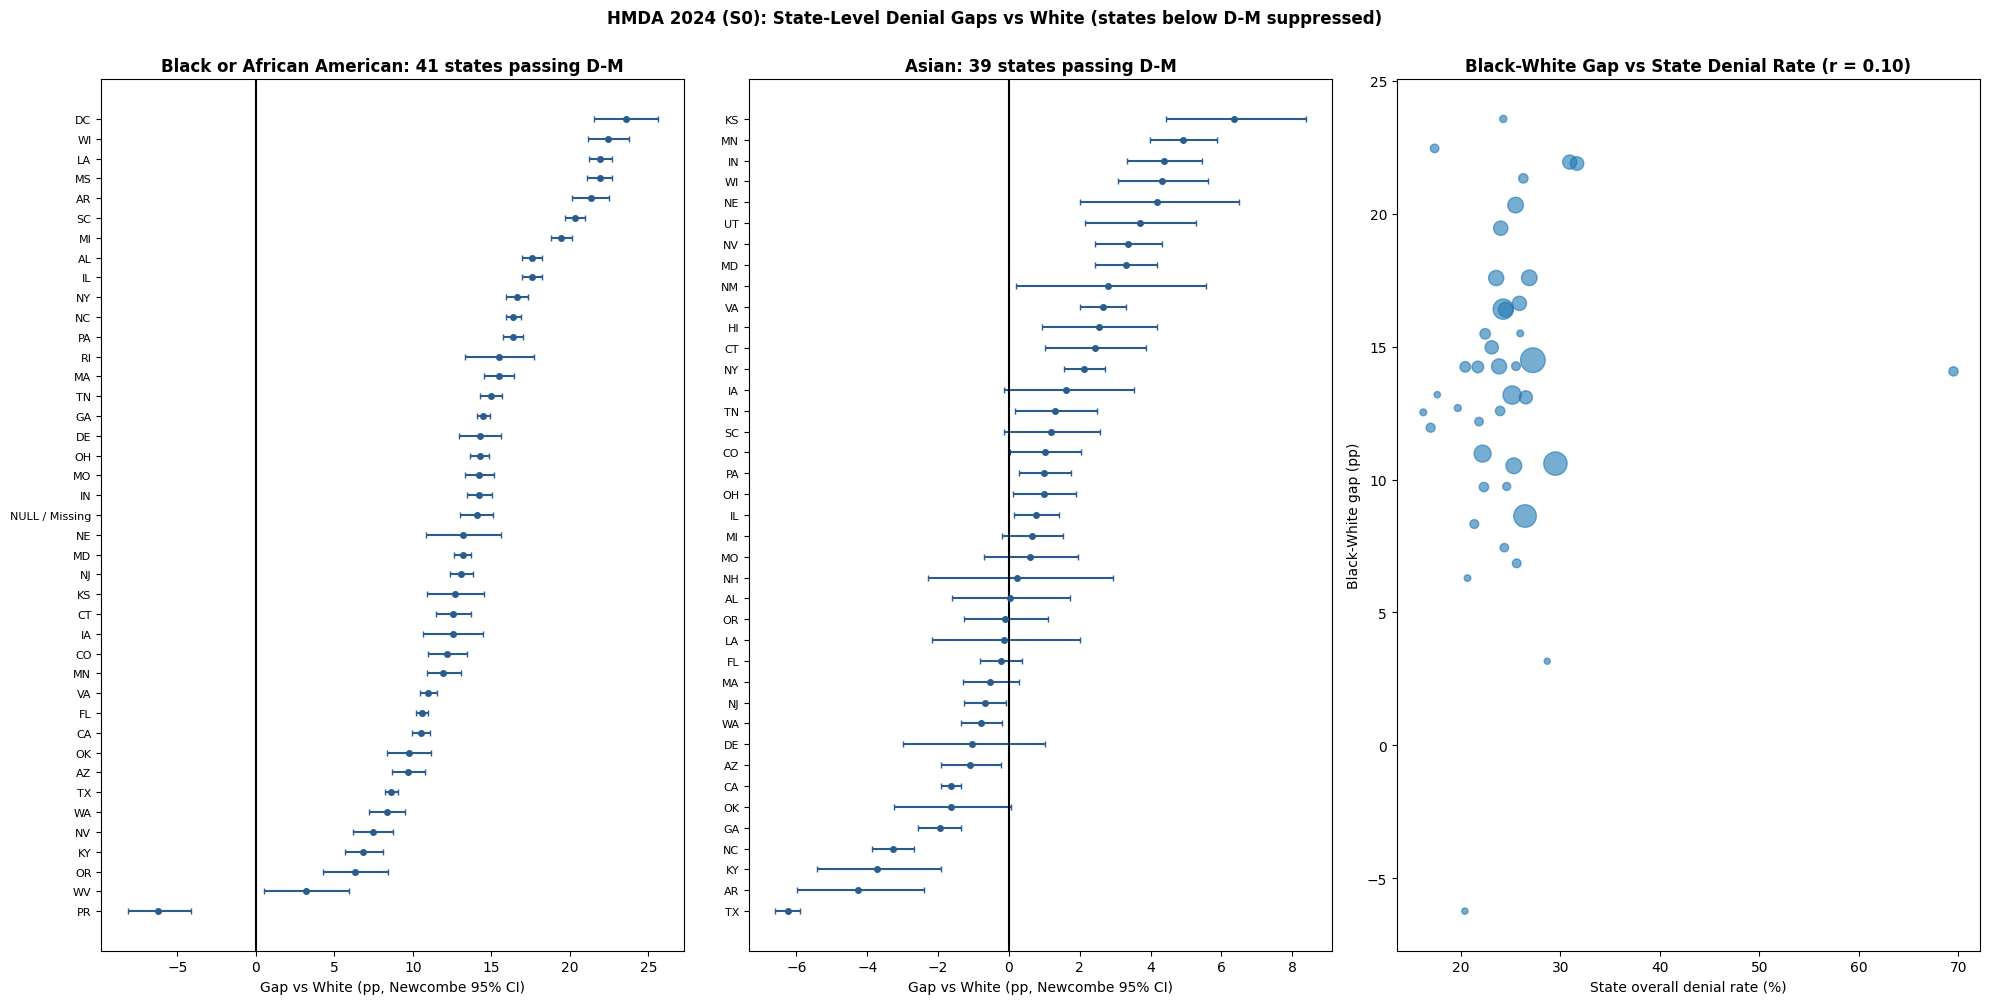

Saved: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_27b_state_gap_map.html


In [71]:
# Step 1: State gaps and overall state rates
st_agg = agg_counts(["state_code", "derived_race"]); st_tot = with_rates(agg_counts(["state_code"]))
F1 = pd.concat([gap_vs_ref(st_agg, ["state_code"], g) for g in NON_REF], ignore_index=True)
F1 = F1.merge(st_tot[["state_code", "denial_rate_pct"]].rename(columns={"denial_rate_pct": "state_rate_pct"}), on="state_code")
save_and_log(F1, "B14_rq3_state_gap.csv")

# Step 2: F5 heterogeneity per group (needs >= 10 valid states)
rows = []
for g, t in F1.groupby("group"):
    v = t[~t["low_n"]]
    if len(v) >= 10:
        rows.append({"group": g, "n_states_valid": len(v), "mean_gap_pp": v["gap_pp"].mean(), "sd_gap_pp": v["gap_pp"].std(), "min_gap_pp": v["gap_pp"].min(),
                     "max_gap_pp": v["gap_pp"].max(), "share_states_gap_lt0_pct": (v["gap_pp"] < 0).mean() * 100,
                     "pearson_gap_vs_state_rate": v["gap_pp"].corr(v["state_rate_pct"]), "spearman_gap_vs_state_rate": v["gap_pp"].corr(v["state_rate_pct"], method="spearman")})
F5 = pd.DataFrame(rows); save_and_log(F5, "B14_rq3_state_gap_heterogeneity.csv"); display(F5)

# Step 3: Forest (Black, Asian) + scatter (Black gap vs state rate)
fig, axes = plt.subplots(1, 3, figsize=(20, 10)); BW = "Black or African American"
for g, ax in zip([BW, "Asian"], axes[:2]):
    v = F1[(F1["group"] == g) & ~F1["low_n"]].sort_values("gap_pp").reset_index(drop=True); yy = np.arange(len(v))
    ax.errorbar(v["gap_pp"], yy, xerr=[(v["gap_pp"] - v["gap_ci_lo"]).to_numpy(), (v["gap_ci_hi"] - v["gap_pp"]).to_numpy()], fmt="o", color="#2b5c8f", capsize=2, markersize=4)
    ax.axvline(0, color="black"); ax.set_yticks(yy); ax.set_yticklabels(v["state_code"], fontsize=8); ax.set_xlabel(f"Gap vs {REF_RACE} (pp, Newcombe 95% CI)"); ax.set_title(f"{g}: {len(v)} states passing D-M", fontweight="bold")
v = F1[(F1["group"] == BW) & ~F1["low_n"]]; axes[2].scatter(v["state_rate_pct"], v["gap_pp"], s=v["n_group"] / v["n_group"].max() * 300 + 15, alpha=0.6)
axes[2].set_xlabel("State overall denial rate (%)"); axes[2].set_ylabel("Black-White gap (pp)"); axes[2].set_title(f"Black-White Gap vs State Denial Rate (r = {v['gap_pp'].corr(v['state_rate_pct']):.2f})", fontweight="bold")
fig.suptitle("HMDA 2024 (S0): State-Level Denial Gaps vs White (states below D-M suppressed)", fontweight="bold", y=1.0)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_27_state_gap.png"); plt.show()

# Step 4: Optional choropleth (plotly); failure is non-fatal
try:
    import plotly.express as px
    mp = px.choropleth(F1[(F1["group"] == BW) & ~F1["low_n"]], locations="state_code", locationmode="USA-states", color="gap_pp", scope="usa",
                       color_continuous_scale="RdBu_r", color_continuous_midpoint=0, title="Black-White denial gap (pp), states passing D-M")
    mp.write_html(FIG_DIR / "B14_fig_27b_state_gap_map.html"); print("Saved:", FIG_DIR / "B14_fig_27b_state_gap_map.html")
except Exception as e: print(f"[SKIP] choropleth not produced: {type(e).__name__}")

## F2: MSA-Level Gaps and Non-MSA vs MSA
- **Input:** `df_s0` (`derived_msa_md`, `derived_msa_md_status`), `gap_vs_ref`.
- **Process:** Gap vs White for the `TOP_MSA` largest MSAs (code `99999` and NULL excluded from the ranking; MSA names are not in the data, so codes are shown). `msa_class` = MSA / Non-MSA (99999, `[Hypothesis]`: non-metropolitan) / NULL, with gaps per class.
- **Output:** `B14_rq3_msa_gap.csv`, `B14_fig_28_msa_gap.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_msa_gap.csv | Size: 24.10 KB | Shape: (162, 11)


,level,group,n_group,gap_pp,gap_ci_lo,gap_ci_hi
0,MSA,Black or African American,"668,563.0000",14.0084,13.8879,14.1290
1,Non-MSA (99999),Black or African American,"64,540.0000",27.5389,27.1428,27.9346
0,MSA,Asian,"467,255.0000",0.3790,0.2554,0.5031
1,Non-MSA (99999),Asian,"11,242.0000",3.9096,3.0673,4.7657
0,MSA,Joint,"164,636.0000",-2.8363,-3.0264,-2.6448
1,Non-MSA (99999),Joint,"19,900.0000",3.9553,3.3177,4.6007
0,MSA,American Indian or Alaska Native,"48,938.0000",13.9961,13.5724,14.4220
1,Non-MSA (99999),American Indian or Alaska Native,"12,459.0000",18.9204,18.0443,19.7997
0,MSA,2 or more minority races,"19,128.0000",15.8321,15.1494,16.5199
1,Non-MSA (99999),2 or more minority races,"1,792.0000",24.7641,22.4488,27.0773


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_28_msa_gap.png | Size: 176.76 KB


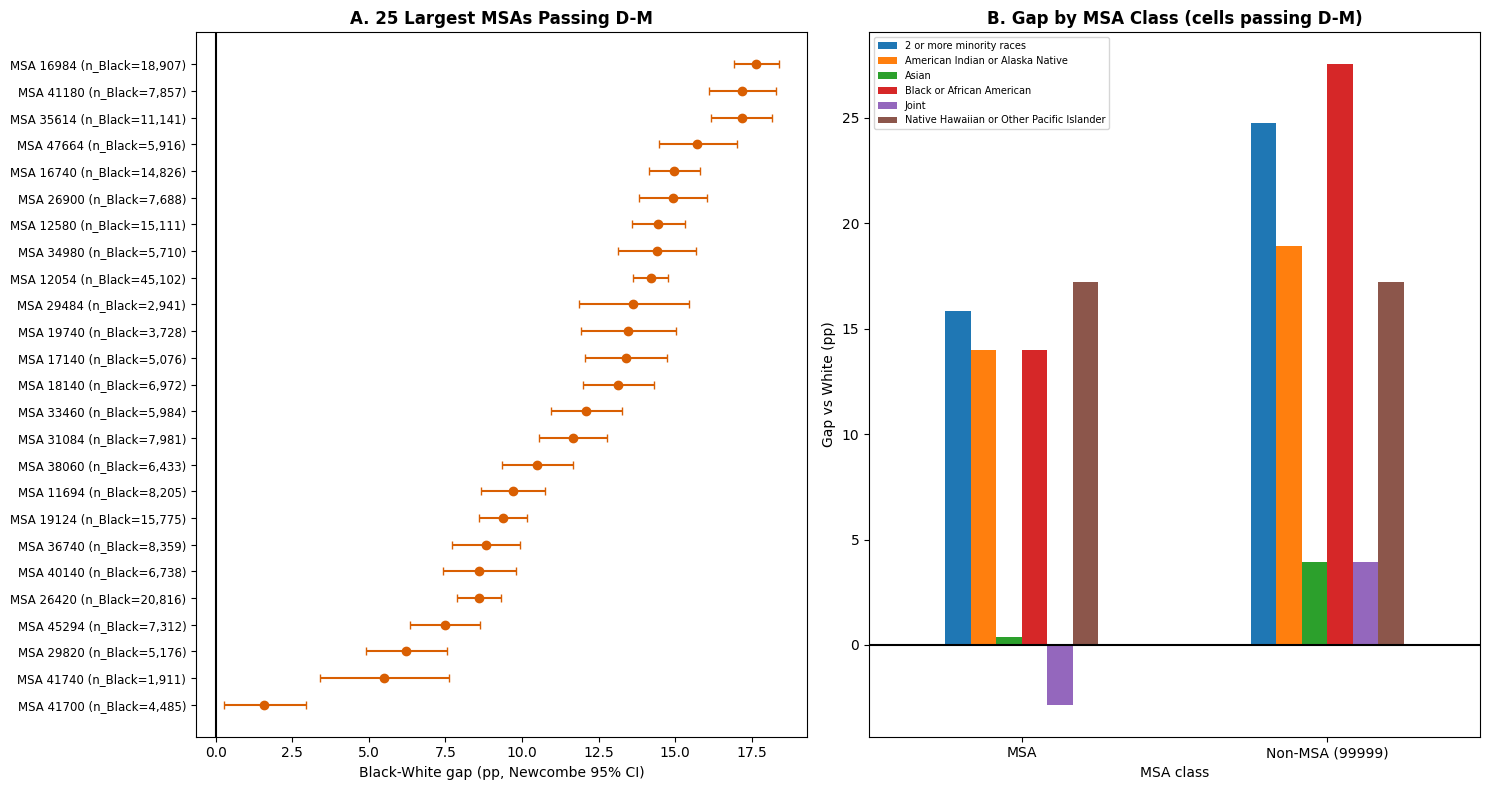

In [72]:
# Step 1: MSA class and counts
TOP_MSA = 25
stt = df_s0["derived_msa_md_status"]
df_s0["msa_class"] = pd.Categorical(np.where(stt == "non_msa", "Non-MSA (99999)", np.where(df_s0["derived_msa_md"].notna(), "MSA", "NULL")))
msa_tot = agg_counts(["derived_msa_md"]); msa_tot = msa_tot[~msa_tot["derived_msa_md"].isin(["99999", "NULL / Missing"])].sort_values("n_apps", ascending=False)
top = msa_tot["derived_msa_md"].head(TOP_MSA).tolist()

# Step 2: Gaps for top MSAs and for MSA classes
msa_agg, cls_agg = agg_counts(["derived_msa_md", "derived_race"]), agg_counts(["msa_class", "derived_race"])
F2a = pd.concat([gap_vs_ref(msa_agg, ["derived_msa_md"], g) for g in NON_REF]).rename(columns={"derived_msa_md": "level"}).query("level in @top").assign(kind="top MSA")
F2b = pd.concat([gap_vs_ref(cls_agg, ["msa_class"], g) for g in NON_REF]).rename(columns={"msa_class": "level"}).assign(kind="MSA class")
F2 = pd.concat([F2a, F2b], ignore_index=True); save_and_log(F2, "B14_rq3_msa_gap.csv"); display(F2b[~F2b["low_n"]][["level", "group", "n_group", "gap_pp", "gap_ci_lo", "gap_ci_hi"]])

# Step 3: Dot plot (top MSAs, Black-White) + gap by class
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8)); v = F2a[(F2a["group"] == BW) & ~F2a["low_n"]].sort_values("gap_pp").reset_index(drop=True); yy = np.arange(len(v))
ax1.errorbar(v["gap_pp"], yy, xerr=[(v["gap_pp"] - v["gap_ci_lo"]).to_numpy(), (v["gap_ci_hi"] - v["gap_pp"]).to_numpy()], fmt="o", color="#d95f02", capsize=3)
ax1.axvline(0, color="black"); ax1.set_yticks(yy); ax1.set_yticklabels([f"MSA {c} (n_Black={int(n):,})" for c, n in zip(v["level"], v["n_group"])], fontsize=8.5)
ax1.set_xlabel("Black-White gap (pp, Newcombe 95% CI)"); ax1.set_title(f"A. {len(v)} Largest MSAs Passing D-M", fontweight="bold")
w = F2b[~F2b["low_n"]].pivot(index="level", columns="group", values="gap_pp").astype("float64"); w.plot(kind="bar", ax=ax2, rot=0)
ax2.axhline(0, color="black"); ax2.set_ylabel(f"Gap vs {REF_RACE} (pp)"); ax2.set_xlabel("MSA class"); ax2.set_title("B. Gap by MSA Class (cells passing D-M)", fontweight="bold"); ax2.legend(fontsize=7)
plt.tight_layout(); save_fig_and_log(fig, "B14_fig_28_msa_gap.png"); plt.show()

## F3: Tract Context (Neighbourhood vs Applicant Race)
- **Input:** `df_s0` (`tract_minority_population_percent`, `tract_to_msa_income_percentage`).
- **Process:** Tract minority-share bins and FFIEC income level (low < 50, moderate 50-<80, middle 80-<120, upper >= 120 % of MSA median; `[Hypothesis: A10]` confirm against FFIEC documentation; zero income-percentages flagged by T12 fall in "Low"). Denial rate by applicant race within each tract class and the gap vs White **in the same class**: compares applicant race with neighbourhood composition. Rows without a tract are the "No tract" class.
- **Output:** `B14_rq3_tract_context.csv`, `B14_fig_29_tract_context.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_tract_context.csv | Size: 13.49 KB | Shape: (99, 10)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_29_tract_context.png | Size: 147.37 KB


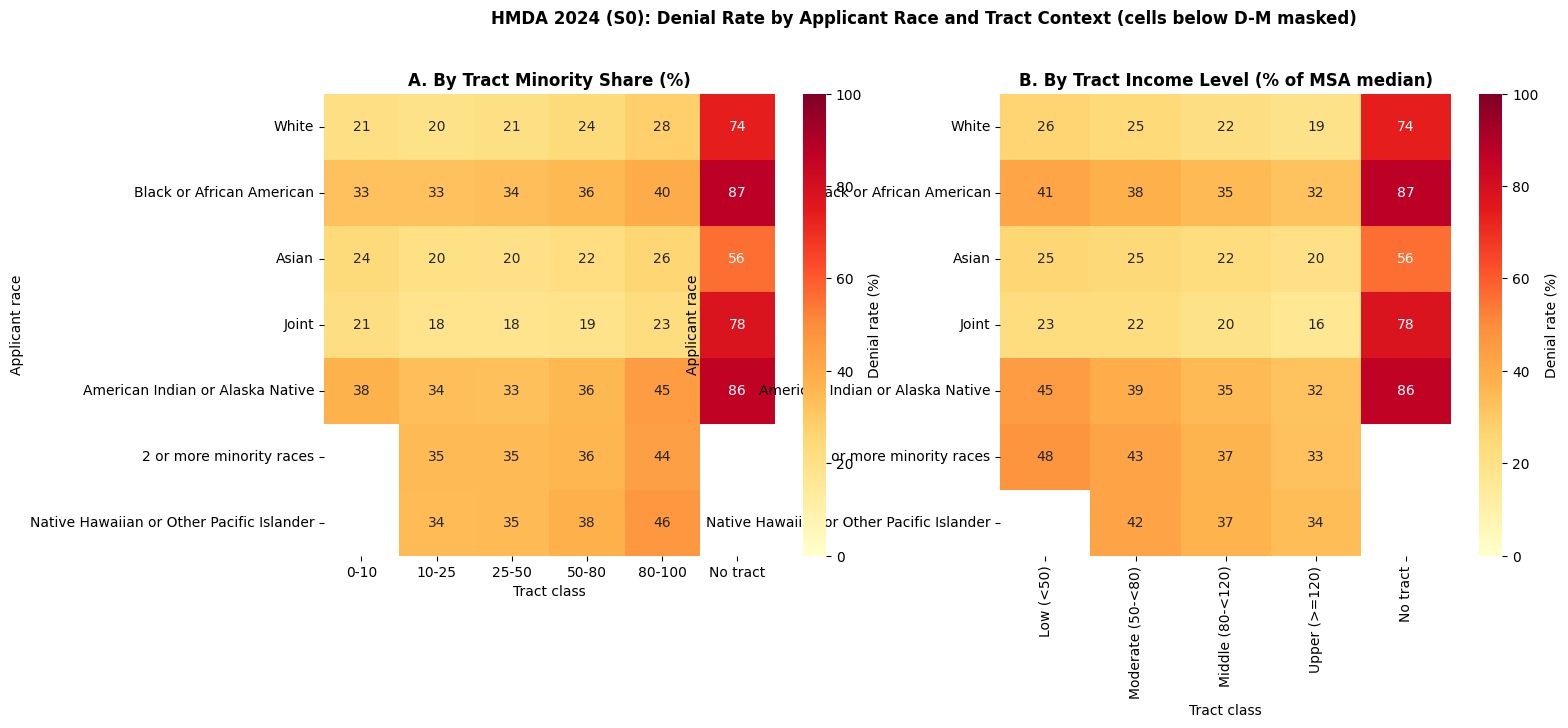

In [73]:
# Step 1: Tract classes
tm, ti = df_s0["tract_minority_population_percent"], df_s0["tract_to_msa_income_percentage"]
df_s0["tract_minority_bin"] = pd.cut(tm, [-0.001, 10, 25, 50, 80, 100.001], labels=["0-10", "10-25", "25-50", "50-80", "80-100"]).cat.add_categories(["No tract"]).fillna("No tract")
df_s0["tract_income_level"] = (pd.cut(ti, [0, 50, 80, 120, np.inf], labels=["Low (<50)", "Moderate (50-<80)", "Middle (80-<120)", "Upper (>=120)"], right=False)
                               .cat.add_categories(["No tract"]).fillna("No tract"))

# Step 2: Rates and within-class gap vs White
parts = []
for dim in ["tract_minority_bin", "tract_income_level"]:
    a = with_rates(agg_counts(["derived_race", dim])).rename(columns={dim: "level"}).assign(dimension=dim)
    a["gap_vs_white_pp"] = a["denial_rate_pct"] - a["level"].map(a[a["derived_race"] == REF_RACE].set_index("level")["denial_rate_pct"]).astype("float64"); parts.append(a)
F3 = pd.concat(parts, ignore_index=True); save_and_log(F3, "B14_rq3_tract_context.csv")

# Step 3: Heatmaps of denial rate (D-M masked)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for dim, ax in zip(["tract_minority_bin", "tract_income_level"], axes):
    pvt = F3[(F3["dimension"] == dim) & ~F3["low_n"]].pivot(index="derived_race", columns="level", values="denial_rate_pct").reindex(index=HEADLINE_RACES, columns=list(df_s0[dim].cat.categories)).astype("float64")
    sns.heatmap(pvt, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "Denial rate (%)"})
    ax.set_title("A. By Tract Minority Share (%)" if dim == "tract_minority_bin" else "B. By Tract Income Level (% of MSA median)", fontweight="bold"); ax.set_xlabel("Tract class"); ax.set_ylabel("Applicant race")
fig.suptitle("HMDA 2024 (S0): Denial Rate by Applicant Race and Tract Context (cells below D-M masked)", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_29_tract_context.png"); plt.show()

## F4: Missing Census Tract as Selection (Decision D-I)
- **Input:** `df_s0` (`census_tract_status`), `B06_GOLD`.
- **Process:** By race: tract-NA count and share, denial rate of tract-NA vs valid-tract rows, and the raw gap on all S0 vs on valid-tract rows only (what dropping them does to each gap). Check: tract-NA total equals the B06 golden count.
- **Output:** `B14_rq3_tract_na_selection.csv`.

In [74]:
# Step 1: Counts for all / tract-NA / valid-tract
tr_ok = (df_s0["census_tract_status"] == "value").to_numpy(); base = ["derived_race", "is_denied"]
a_all, a_na, a_ok = agg_on(df_s0[base], ["derived_race"]), agg_on(df_s0.loc[~tr_ok, base], ["derived_race"]), agg_on(df_s0.loc[tr_ok, base], ["derived_race"])
assert int(a_na["n_apps"].sum()) == int(B06_GOLD["tract_null_s0"]), "Tract-NA count differs from B06"

# Step 2: Combine and compute the gap shift
g_all, g_ok = (rate_gap_table(a, "derived_race", REF_RACE).set_index("derived_race") for a in (a_all, a_ok)); na = a_na.set_index("derived_race")
F4 = pd.DataFrame({"n_s0": a_all.set_index("derived_race")["n_apps"], "n_tract_na": na["n_apps"], "denial_rate_tract_na_pct": na["n_denied"] * 100.0 / na["n_apps"],
                   "denial_rate_valid_tract_pct": g_ok["denial_rate_pct"], "gap_all_pp": g_all["gap_pp"], "gap_valid_tract_pp": g_ok["gap_pp"]}).loc[C1["derived_race"]]
F4["pct_tract_na"] = F4["n_tract_na"] * 100.0 / F4["n_s0"]; F4["gap_shift_pp"] = F4["gap_valid_tract_pp"] - F4["gap_all_pp"]
save_and_log(F4.reset_index(), "B14_rq3_tract_na_selection.csv"); display(F4.round(2))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_tract_na_selection.csv | Size: 1.36 KB | Shape: (9, 9)


,n_s0,n_tract_na,denial_rate_tract_na_pct,denial_rate_valid_tract_pct,gap_all_pp,gap_valid_tract_pp,pct_tract_na,gap_shift_pp
derived_race,,,,,,,,
White,5360624,58831,73.9100,21.3400,0.0000,0.0000,1.1000,0.0000
Race Not Available,1275240,15441,75.8600,29.0900,7.7400,7.7500,1.2100,0.0100
Black or African American,733103,15704,87.1400,35.6900,14.8800,14.3500,2.1400,-0.5300
Asian,478497,1532,56.0100,21.6600,-0.1600,0.3100,0.3200,0.4700
Joint,184536,2132,77.9100,18.9000,-2.3400,-2.4400,1.1600,-0.1000
American Indian or Alaska Native,61397,1737,86.4700,35.6800,15.1900,14.3300,2.8300,-0.8600
2 or more minority races,20920,289,91.7000,37.4300,16.2600,16.0900,1.3800,-0.1700
Native Hawaiian or Other Pacific Islander,20249,379,90.5000,37.9000,16.9600,16.5600,1.8700,-0.4100
Free Form Text Only,2098,20,75.0000,58.1800,36.4200,36.8400,0.9500,0.4200


## F6: Lender Size and Concentration (Decision D-O)
- **Input:** `LENDER_RACE` (C1b), `df_s0`.
- **Process:** Lenders get anonymous IDs `L0001...` ranked by volume (`LENDER_ID` mapping stays in memory; no LEI is exported). Metrics: applications per lender (quantiles), share held by the top 10 / 100 / 1% of lenders, a Lorenz-type curve with approximate Gini, **HHI** (sum of squared shares x 10,000) nationally and per state, and `lender_size_bucket` mix by race.
- **Output:** `B14_rq3_lender_concentration.csv`, `B14_rq3_hhi_by_state.csv`, `B14_rq3_lender_size_mix.csv`, `B14_fig_30_lender_concentration.png`.

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_lender_concentration.csv | Size: 0.28 KB | Shape: (9, 2)


,metric,value
0,n_lenders,"4,808.0000"
1,median_apps_per_lender,165.5000
2,p90_apps,"2,171.3000"
3,p99_apps,"24,584.0500"
4,top10_share_pct,22.3659
5,top100_share_pct,61.3119
6,top1pct_lenders_share_pct,50.6017
7,hhi_national,100.4311
8,gini_approx,0.8783


Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_hhi_by_state.csv | Size: 2.75 KB | Shape: (54, 5)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_lender_size_mix.csv | Size: 2.16 KB | Shape: (36, 5)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_30_lender_concentration.png | Size: 78.43 KB


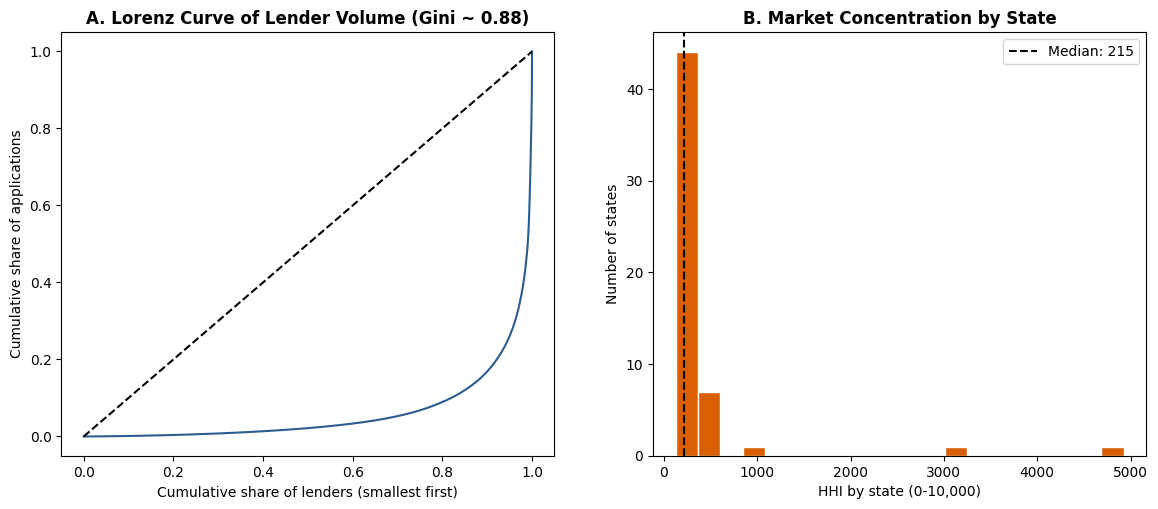

In [75]:
# Step 1: Lender totals and anonymous IDs
LC = LENDER_RACE.groupby("lender_code")[["n", "d"]].sum().sort_values("n", ascending=False); assert int(LC["n"].sum()) == len(df_s0)
LENDER_ID = pd.Series([f"L{i:04d}" for i in range(1, len(LC) + 1)], index=LC.index)
share = LC["n"] / LC["n"].sum(); K = len(LC)
srt = LC["n"].sort_values().to_numpy(float); cum = np.cumsum(srt) / srt.sum(); gini = 1 - 2 * cum.mean()
CONC = pd.DataFrame({"metric": ["n_lenders", "median_apps_per_lender", "p90_apps", "p99_apps", "top10_share_pct", "top100_share_pct", "top1pct_lenders_share_pct", "hhi_national", "gini_approx"],
                     "value": [K, LC["n"].median(), LC["n"].quantile(0.9), LC["n"].quantile(0.99), share.head(10).sum() * 100, share.head(100).sum() * 100,
                               share.head(max(1, K // 100)).sum() * 100, (share ** 2).sum() * 10000, gini]})
save_and_log(CONC, "B14_rq3_lender_concentration.csv"); display(CONC)

# Step 2: HHI per state (market = state)
ls = df_s0.groupby(["state_code", "lender_code"], observed=True).size().rename("n").reset_index()
ls["share"] = ls["n"] / ls.groupby("state_code", observed=True)["n"].transform("sum")
HHI = ls.groupby("state_code", observed=True).agg(n_apps=("n", "sum"), n_lenders=("n", "size"), hhi=("share", lambda s: (s ** 2).sum() * 10000), top1_share_pct=("share", lambda s: s.max() * 100)).reset_index()
HHI["state_code"] = HHI["state_code"].astype("string"); assert HHI["hhi"].between(0, 10000).all(); save_and_log(HHI, "B14_rq3_hhi_by_state.csv")

# Step 3: Size-bucket mix by race and figure
MIXL = agg_counts(["derived_race", "lender_size_bucket"]); MIXL["share_within_race_pct"] = MIXL["n_apps"] * 100.0 / MIXL["derived_race"].map(race_n_f).astype("float64")
save_and_log(MIXL, "B14_rq3_lender_size_mix.csv")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5)); xl = np.arange(1, K + 1) / K
ax1.plot(xl, cum, color="#2b5c8f"); ax1.plot([0, 1], [0, 1], "k--"); ax1.set_xlabel("Cumulative share of lenders (smallest first)"); ax1.set_ylabel("Cumulative share of applications")
ax1.set_title(f"A. Lorenz Curve of Lender Volume (Gini ~ {gini:.2f})", fontweight="bold")
ax2.hist(HHI["hhi"], bins=20, color="#d95f02", edgecolor="white"); ax2.axvline(HHI["hhi"].median(), color="black", linestyle="--", label=f"Median: {HHI['hhi'].median():,.0f}")
ax2.set_xlabel("HHI by state (0-10,000)"); ax2.set_ylabel("Number of states"); ax2.set_title("B. Market Concentration by State", fontweight="bold"); ax2.legend()
save_fig_and_log(fig, "B14_fig_30_lender_concentration.png"); plt.show()

## F7: Dispersion of Lender Denial Rates (Funnel Plot)
- **Input:** `LC`, `LENDER_ID`.
- **Process:** Lender denial rate vs volume with binomial control limits (95% and 99.8%) around the overall rate `p0`: with `p0` fixed, a rate outside the limits is more different than pure sampling noise allows. `z = (rate - p0) / sqrt(p0(1-p0)/n)`. **Overdispersion** phi = sum(z²) / (K - 1) over lenders passing D-M (phi near 1 means only noise; phi > 1 means real between-lender differences, including **applicant sorting and product niches**, not proof of policy). Lenders below D-M are grey.
- **Output:** `B14_rq3_lender_funnel.csv` (anonymous IDs only), `B14_fig_31_funnel.png`.

Lenders: 4,808 | passing D-M: 731 | overall rate p0: 24.62% | overdispersion phi: 2014.6 | outside 99.8% limits: 86.5%
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_lender_funnel.csv | Size: 306.70 KB | Shape: (4808, 8)
Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_31_funnel.png | Size: 194.12 KB


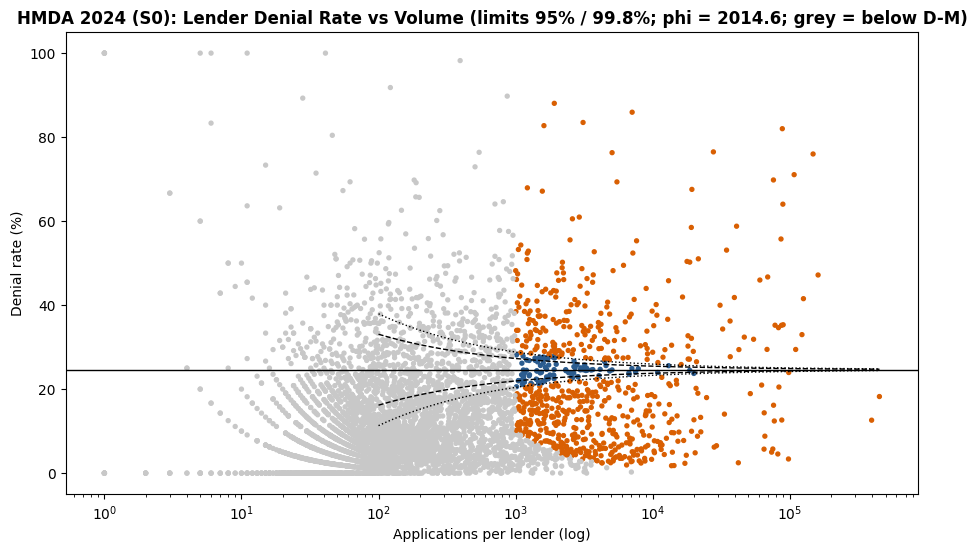

In [76]:
# Step 1: Lender table with z-scores (no LEI / lender_code exported)
LD = LC.rename(columns={"n": "n_apps", "d": "n_denied"}).assign(lender_id=LENDER_ID).reset_index(drop=True)[["lender_id", "n_apps", "n_denied"]]
p0 = LD["n_denied"].sum() / LD["n_apps"].sum(); LD["rate_pct"] = LD["n_denied"] * 100.0 / LD["n_apps"]
LD["z"] = (LD["n_denied"] / LD["n_apps"] - p0) / np.sqrt(p0 * (1 - p0) / LD["n_apps"])
LD["low_n"] = (LD["n_apps"] < N_MIN_APPS) | (LD["n_denied"] < N_MIN_DENIED); LD["outside_95"], LD["outside_998"] = LD["z"].abs() > 1.96, LD["z"].abs() > 3.09
v = LD[~LD["low_n"]]; phi = (v["z"] ** 2).sum() / (len(v) - 1)
print(f"Lenders: {len(LD):,} | passing D-M: {len(v):,} | overall rate p0: {p0 * 100:.2f}% | overdispersion phi: {phi:.1f} | outside 99.8% limits: {v['outside_998'].mean() * 100:.1f}%")
save_and_log(LD, "B14_rq3_lender_funnel.csv")

# Step 2: Funnel
ng = np.logspace(np.log10(N_MIN_APPS / 10), np.log10(LD["n_apps"].max()), 200); fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(LD["n_apps"], LD["rate_pct"], s=8, c=np.where(LD["low_n"], "#c8c8c8", np.where(LD["outside_998"], "#d95f02", "#2b5c8f")))
for z, ls_ in ((1.96, "--"), (3.09, ":")):
    se = np.sqrt(p0 * (1 - p0) / ng) * 100
    ax.plot(ng, np.clip(p0 * 100 + z * se, 0, 100), "k" + ls_, linewidth=1); ax.plot(ng, np.clip(p0 * 100 - z * se, 0, 100), "k" + ls_, linewidth=1)
ax.axhline(p0 * 100, color="black", linewidth=1); ax.set_xscale("log"); ax.set_xlabel("Applications per lender (log)"); ax.set_ylabel("Denial rate (%)")
ax.set_title(f"HMDA 2024 (S0): Lender Denial Rate vs Volume (limits 95% / 99.8%; phi = {phi:.1f}; grey = below D-M)", fontweight="bold")
save_fig_and_log(fig, "B14_fig_31_funnel.png"); plt.show()

## F8/F9: Between- vs Within-Lender Gap and Lender-Level Gap Distribution
- **Input:** `LENDER_RACE`, `LENDER_ID`, `kitagawa()` (C5), `gap_vs_ref`, D-M, D-U.
- **Process:**
  - **F8:** Kitagawa decomposition with **lender as the stratum**. *Composition* = the part of the gap due to groups applying to different lenders (sorting); *rate* = the gap **within the same lender**. Lender x race cells failing D-M are pooled per pair (D-U) and `low_reliability` flagged.
  - **F9:** For lenders where both the group and White pass D-M: distribution of the lender-level gap, share positive, and share whose Newcombe CI excludes 0. `coverage_pct` = share of the group's applications in those lenders (the result describes **only** these lenders).
- **Output:** `B14_rq3_lender_standardised_gap.csv`, `B14_rq3_lender_gap_summary.csv`, `B14_rq3_lender_gap_dist.csv`, `B14_fig_32_lender_gap.png`.

In [77]:
# Step 1: Anonymous lender x race counts (string IDs only)
LST = LENDER_RACE.assign(lender_id=LENDER_RACE["lender_code"].map(LENDER_ID)).rename(columns={"n": "n_apps", "d": "n_denied"})[["derived_race", "lender_id", "n_apps", "n_denied"]]

# Step 2: F8 Kitagawa with lender strata + D-U flags
LKIT = pd.DataFrame([kitagawa(LST, g, REF_RACE, ["lender_id"])[0] for g in NON_REF])
LKIT.loc[LKIT["raw_gap_pp"].abs() < MIN_GAP_PP_FOR_SHARE, "composition_share_of_gap_pct"] = np.nan
LKIT["pooled_share_max_pct"] = LKIT[["pooled_share_group_pct", "pooled_share_ref_pct"]].max(axis=1); LKIT["low_reliability"] = LKIT["pooled_share_max_pct"] > POOLED_MAX_PCT
assert LKIT["identity_residual_pp"].abs().max() < 1e-9; save_and_log(LKIT, "B14_rq3_lender_standardised_gap.csv")
display(LKIT[["group", "raw_gap_pp", "composition_pp", "rate_pp", "n_strata_kept", "pooled_share_max_pct", "low_reliability"]])

# Step 3: F9 lender-level gap distribution
sums, dists = [], []
for g in NON_REF:
    t = gap_vs_ref(LST, ["lender_id"], g); vv = t[~t["low_n"]]
    sums.append({"group": g, "n_lenders_valid": len(vv), "coverage_pct": vv["n_group"].sum() * 100.0 / race_n[g], "median_gap_pp": vv["gap_pp"].median(),
                 "p10_gap_pp": vv["gap_pp"].quantile(0.1), "p90_gap_pp": vv["gap_pp"].quantile(0.9), "share_gap_gt0_pct": (vv["gap_pp"] > 0).mean() * 100,
                 "share_gap_ci_gt0_pct": (vv["gap_ci_lo"] > 0).mean() * 100, "share_gap_ci_lt0_pct": (vv["gap_ci_hi"] < 0).mean() * 100})
    dists.append(vv)
LGAP_SUM, LGAP = pd.DataFrame(sums), pd.concat(dists, ignore_index=True)
save_and_log(LGAP_SUM, "B14_rq3_lender_gap_summary.csv"); save_and_log(LGAP, "B14_rq3_lender_gap_dist.csv"); display(LGAP_SUM)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_lender_standardised_gap.csv | Size: 1.32 KB | Shape: (6, 15)


,group,raw_gap_pp,composition_pp,rate_pp,n_strata_kept,pooled_share_max_pct,low_reliability
0,Black or African American,14.8752,2.6945,12.1807,97,44.1037,True
1,Asian,-0.1554,-0.1170,-0.0384,60,52.8195,True
2,Joint,-2.3383,0.2492,-2.5875,27,65.4830,True
3,American Indian or Alaska Native,15.1927,3.3693,11.8234,11,79.1854,True
4,2 or more minority races,16.2620,-0.4420,16.7040,1,95.5616,True
5,Native Hawaiian or Other Pacific Islander,16.9644,0.0000,16.9644,0,100.0000,True


Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_lender_gap_summary.csv | Size: 0.79 KB | Shape: (6, 9)
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_lender_gap_dist.csv | Size: 26.47 KB | Shape: (196, 10)


,group,n_lenders_valid,coverage_pct,median_gap_pp,p10_gap_pp,p90_gap_pp,share_gap_gt0_pct,share_gap_ci_gt0_pct,share_gap_ci_lt0_pct
0,Black or African American,97,69.8172,10.6177,4.1400,23.0532,100.0000,100.0000,0.0000
1,Asian,60,61.4934,1.2157,-3.3311,9.2455,73.3333,60.0000,20.0000
2,Joint,27,38.5367,-3.0358,-6.9948,1.3822,18.5185,7.4074,66.6667
3,American Indian or Alaska Native,11,30.6155,11.3591,5.3581,20.2094,100.0000,100.0000,0.0000
4,2 or more minority races,1,6.7878,3.1290,3.1290,3.1290,100.0000,100.0000,0.0000
5,Native Hawaiian or Other Pacific Islander,0,0.0000,NaN,NaN,NaN,NaN,NaN,NaN


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_32_lender_gap.png | Size: 102.87 KB


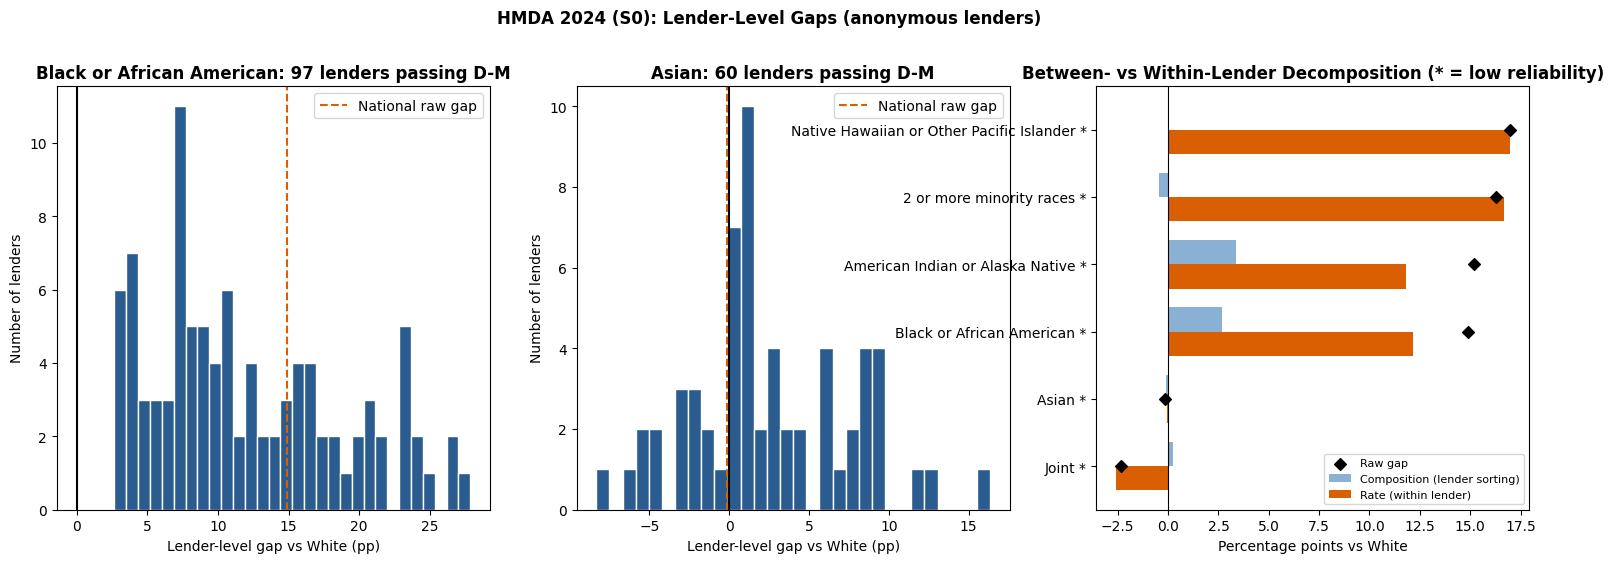

In [78]:
# Step 1: Histograms (Black, Asian) + composition vs rate bars (F8)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for g, ax in zip([BW, "Asian"], axes[:2]):
    v = LGAP[LGAP["group"] == g]; ax.hist(v["gap_pp"], bins=30, color="#2b5c8f", edgecolor="white")
    ax.axvline(0, color="black"); ax.axvline(C1.set_index("derived_race").loc[g, "gap_pp"], color="#d95f02", linestyle="--", label="National raw gap")
    ax.set_xlabel(f"Lender-level gap vs {REF_RACE} (pp)"); ax.set_ylabel("Number of lenders"); ax.set_title(f"{g}: {len(v)} lenders passing D-M", fontweight="bold"); ax.legend()
ks = LKIT.sort_values("raw_gap_pp").reset_index(drop=True); yy = np.arange(len(ks)); h = 0.36
axes[2].barh(yy + h / 2, ks["composition_pp"], h, color="#8ab1d4", label="Composition (lender sorting)"); axes[2].barh(yy - h / 2, ks["rate_pp"], h, color="#d95f02", label="Rate (within lender)")
axes[2].scatter(ks["raw_gap_pp"], yy, marker="D", color="black", zorder=3, label="Raw gap"); axes[2].axvline(0, color="black", linewidth=0.8)
axes[2].set_yticks(yy); axes[2].set_yticklabels(ks["group"] + np.where(ks["low_reliability"], " *", "")); axes[2].set_xlabel("Percentage points vs White"); axes[2].legend(fontsize=8)
axes[2].set_title("Between- vs Within-Lender Decomposition (* = low reliability)", fontweight="bold")
fig.suptitle("HMDA 2024 (S0): Lender-Level Gaps (anonymous lenders)", fontweight="bold", y=1.02)
save_fig_and_log(fig, "B14_fig_32_lender_gap.png"); plt.show()

## F10: Exempt Filers and Lender Size
- **Input:** `df_s0` (`is_exempt_filer`, `is_partial_exempt`, `lender_size_bucket`, `fin_complete`).
- **Process:** `exempt_status` = full exempt (28 fields) / partial / none (rule X09). By lender-size bucket: share of each status, denial rate, and % `fin_complete` (links to RQ4: reduced reporting means missing predictors).
- **Output:** `B14_rq3_exempt_by_lender_size.csv`.

In [79]:
# Step 1: Exempt status by lender size bucket
df_s0["exempt_status"] = pd.Categorical(np.select([df_s0["is_exempt_filer"], df_s0["is_partial_exempt"]], ["Full exempt (28)", "Partial exempt"], "Not exempt"))
F10 = with_rates(agg_counts(["lender_size_bucket", "exempt_status"]))
F10["share_in_bucket_pct"] = F10["n_apps"] * 100.0 / F10.groupby("lender_size_bucket")["n_apps"].transform("sum")
fc = df_s0.groupby(["lender_size_bucket", "exempt_status"], observed=True)["fin_complete"].mean().mul(100).rename("pct_fin_complete").reset_index()
for c in ("lender_size_bucket", "exempt_status"): fc[c] = fc[c].astype("string")
F10 = F10.merge(fc, on=["lender_size_bucket", "exempt_status"]); save_and_log(F10, "B14_rq3_exempt_by_lender_size.csv"); display(F10.round(2))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_exempt_by_lender_size.csv | Size: 1.14 KB | Shape: (8, 10)


,lender_size_bucket,exempt_status,n_apps,n_denied,denial_rate_pct,wilson_ci_lo,wilson_ci_hi,low_n,share_in_bucket_pct,pct_fin_complete
0,Mega,Not exempt,3892710,1180148,30.3200,30.2700,30.3600,False,100.0000,83.0200
1,Large,Not exempt,2359123,505961,21.4500,21.3900,21.5000,False,100.0000,96.1400
2,Medium,Full exempt (28),38116,8906,23.3700,22.9400,23.7900,False,2.5600,0.0000
3,Medium,Not exempt,1443702,255337,17.6900,17.6200,17.7500,False,97.1500,94.8700
4,Medium,Partial exempt,4283,355,8.2900,7.5000,9.1500,False,0.2900,11.7200
5,Small/Community,Full exempt (28),202992,22415,11.0400,10.9100,11.1800,False,50.9100,0.0000
6,Small/Community,Not exempt,184729,28453,15.4000,15.2400,15.5700,False,46.3300,90.0800
7,Small/Community,Partial exempt,11009,1701,15.4500,14.7900,16.1400,False,2.7600,7.4200


## F11: Derived Figures Quoted in the Part F Interpretation
- **Input:** `F1`, `F2a`, `F3`, `F10`, `MIXL` (Part F tables in memory), `gap_vs_ref`.
- **Process:** Recompute, from the saved Part F tables, every count or percentage that the Part F interpretation quotes but no earlier cell prints: states and top MSAs with positive gap or CI excluding 0 (Black, Asian), gap inside each lender-size bucket, share of applications in minority-majority and low/moderate-income tracts, and the share of full exempt filers in Small/Community lenders. Check: full exempt rows equal `is_exempt_filer` in S0.
- **Output:** `B14_rq3_derived_checks.csv`.

In [80]:
# Step 1: State-level and top-MSA counts (Black, Asian)
rows = []
def add(metric, value, src): rows.append({"metric": metric, "value": float(value), "source": src})
for g, tag in ((BW, "Black"), ("Asian", "Asian")):
    s = F1[(F1["group"] == g) & ~F1["low_n"]]
    add(f"{tag}: valid states", len(s), "F1")
    add(f"{tag}: states with gap > 0", (s["gap_pp"] > 0).sum(), "F1")
    add(f"{tag}: states with gap > 10 pp", (s["gap_pp"] > 10).sum(), "F1")
    add(f"{tag}: states with CI including 0", ((s["gap_ci_lo"] <= 0) & (s["gap_ci_hi"] >= 0)).sum(), "F1")
    m = F2a[(F2a["group"] == g) & ~F2a["low_n"]]
    add(f"{tag}: top MSAs valid", len(m), "F2")
    add(f"{tag}: top MSAs with gap > 0", (m["gap_pp"] > 0).sum(), "F2")
    add(f"{tag}: top MSAs with CI below 0", (m["gap_ci_hi"] < 0).sum(), "F2")
    add(f"{tag}: top MSAs with CI above 0", (m["gap_ci_lo"] > 0).sum(), "F2")
    add(f"{tag}: top MSA median gap (pp)", m["gap_pp"].median(), "F2")

# Step 2: Gap inside each lender-size bucket
for g, tag in ((BW, "Black"), ("Asian", "Asian")):
    for r in gap_vs_ref(MIXL, ["lender_size_bucket"], g).itertuples():
        add(f"{tag}: gap in {r.lender_size_bucket} lenders (pp)", r.gap_pp, "F6")

# Step 3: Tract exposure by race (share of the race's S0 applications)
for race in (BW, REF_RACE):
    for dim, lv, lab in (("tract_minority_bin", ["50-80", "80-100"], "tract minority share >= 50%"),
                         ("tract_income_level", ["Low (<50)", "Moderate (50-<80)"], "low/moderate-income tract")):
        t = F3[(F3["dimension"] == dim) & (F3["derived_race"] == race)]
        add(f"{race}: % of applications in {lab}", t.loc[t["level"].isin(lv), "n_apps"].sum() * 100.0 / t["n_apps"].sum(), "F3")

# Step 4: Exempt filers by lender size, check, save
fe = F10[F10["exempt_status"] == "Full exempt (28)"]
assert int(fe["n_apps"].sum()) == int(df_s0["is_exempt_filer"].sum()), "Full exempt rows differ from S0 flag"
add("Full exempt filers in S0 (rows)", fe["n_apps"].sum(), "F10")
add("Full exempt filers in Small/Community (% of all full exempt)", fe.loc[fe["lender_size_bucket"] == "Small/Community", "n_apps"].sum() * 100.0 / fe["n_apps"].sum(), "F10")
chk = pd.DataFrame(rows); chk["value"] = chk["value"].round(2)
save_and_log(chk, "B14_rq3_derived_checks.csv"); display(chk)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq3_derived_checks.csv | Size: 1.44 KB | Shape: (32, 3)


,metric,value,source
0,Black: valid states,41.0000,F1
1,Black: states with gap > 0,40.0000,F1
2,Black: states with gap > 10 pp,32.0000,F1
3,Black: states with CI including 0,0.0000,F1
4,Black: top MSAs valid,25.0000,F2
5,Black: top MSAs with gap > 0,25.0000,F2
6,Black: top MSAs with CI below 0,0.0000,F2
7,Black: top MSAs with CI above 0,25.0000,F2
8,Black: top MSA median gap (pp),13.1400,F2
9,Asian: valid states,39.0000,F1


## Checkpoint 5 Gate (eda_plan.md §14, Blocks 5-6)
- **Input:** Outputs of E0-E5 and F0-F10.
- **Process:** Assert artifacts, valid statistic ranges, tract-NA reconciliation with B06, the Kitagawa identity for lenders, and **lender anonymity** (D-O): no LEI or raw lender code in any exported lender table.
- **Output:** `gate5` table.

In [81]:
# Step 1: Gate conditions
need5 = ["B14_rel_spearman.csv", "B14_rel_cramers_v.csv", "B14_rel_vif.csv", "B14_rel_smd_by_race.csv", "B14_rq3_state_gap.csv", "B14_rq3_msa_gap.csv",
         "B14_rq3_tract_context.csv", "B14_rq3_tract_na_selection.csv", "B14_rq3_lender_concentration.csv", "B14_rq3_lender_funnel.csv",
         "B14_rq3_lender_standardised_gap.csv", "B14_rq3_lender_gap_summary.csv", "B14_rq3_exempt_by_lender_size.csv"]
figs = [p.name for p in FIG_DIR.glob("B14_fig_*.png")]; BAD = {"lei", "lender_code"}
gate5 = pd.DataFrame([
    ("Gate 5.1: Part E/F tables saved", all((OUTPUT_DIR / f).exists() for f in need5), f"{len(need5)} tables"),
    ("Gate 5.2: figures 23-32 saved", all(any(n.startswith(f"B14_fig_{i}") for n in figs) for i in range(23, 33)), f"{len(figs)} figures"),
    ("Gate 5.3: V in [0,1]; HHI in (0,10000]", bool(REL_V["cramers_v_bc"].between(0, 1).all() and HHI["hhi"].between(0, 10000).all()), f"{len(REL_V)} variables, {len(HHI)} states"),
    ("Gate 5.4: tract-NA count equals B06", int(F4["n_tract_na"].sum()) == int(B06_GOLD["tract_null_s0"]), f"{int(F4['n_tract_na'].sum()):,} rows"),
    ("Gate 5.5: lender Kitagawa identity < 1e-9", bool((LKIT["identity_residual_pp"].abs() < 1e-9).all()), f"{len(LKIT)} groups"),
    ("Gate 5.6: lender anonymity (no LEI / lender_code)", all(not (BAD & set(t.columns)) and t["lender_id"].str.startswith("L").all() for t in (LD, LGAP)), "L0001... only"),
], columns=["checkpoint_5_gate", "passed", "evidence"])
assert gate5["passed"].all(), "Checkpoint 5 gate failed!"
display(gate5); display(REL_V.head(8)[["variable", "n_levels", "cramers_v_bc", "mi_norm_by_entropy_y", "rate_spread_pp"]])
print("[CHECKPOINT 5 PASSED] Next: Checkpoint 6 (Part G: robustness preview, PySpark equivalents, hand-off).")

,checkpoint_5_gate,passed,evidence
0,Gate 5.1: Part E/F tables saved,True,13 tables
1,Gate 5.2: figures 23-32 saved,True,33 figures
2,"Gate 5.3: V in [0,1]; HHI in (0,10000]",True,"25 variables, 54 states"
3,Gate 5.4: tract-NA count equals B06,True,"96,065 rows"
4,Gate 5.5: lender Kitagawa identity < 1e-9,True,6 groups
5,Gate 5.6: lender anonymity (no LEI / lender_code),True,L0001... only


,variable,n_levels,cramers_v_bc,mi_norm_by_entropy_y,rate_spread_pp
0,dti_cat,10,0.4881,0.1913,78.9488
1,aus_1,8,0.3178,0.0943,32.8800
2,loan_purpose,6,0.2600,0.0600,28.1444
3,income_decile,12,0.2514,0.0519,45.4127
4,applicant_credit_score_type,15,0.2444,0.0487,62.1673
5,lti_bin,8,0.2032,0.0344,67.1201
6,cltv_bin,10,0.1848,0.0307,29.0365
7,derived_dwelling_category,4,0.1797,0.0248,48.6122


[CHECKPOINT 5 PASSED] Next: Checkpoint 6 (Part G: robustness preview, PySpark equivalents, hand-off).


In [82]:
    a = agg_counts(["dti_cat"]); print(assoc_from_counts(a[~a["dti_cat"].str.startswith("MISSING")])[0])

0.4989936846327094


### Interpretation — Steps F1 & F5 (`B14_rq3_state_gap.csv`, `B14_rq3_state_gap_heterogeneity.csv`, Fig 27)

*Figures are read from the saved tables (as of run 2026-11-11, B14 F1/F5). Only states passing D-M are used.*

1. **What pattern is observed?**
   - **Black vs White.** 41 states pass D-M, covering almost all Black applications in S0 (728,442 of 733,103). The gap is positive in 40 of 41 states. Mean +13.52 pp, SD 5.66 pp, range −6.24 pp (PR) to +23.57 pp (DC). The Newcombe 95% CI excludes 0 in every one of the 41 states. Upper end: DC, WI (+22.46), LA (+21.95), MS (+21.89), AR (+21.33). Lower end: PR, WV (+3.16), OR (+6.29), KY (+6.85), NV (+7.43).
   - **Gap vs state denial rate.** For Black applicants the gap is only weakly related to the state's overall denial rate (Pearson 0.10, Spearman 0.21). WI has a low state rate (17.34%) and one of the largest gaps.
   - **American Indian or Alaska Native (AIAN).** 18 valid states, mean +15.54 pp, range +8.16 to +25.77 pp, no negative state.
   - **Asian.** 39 valid states, mean +0.75 pp, SD 2.67 pp, range −6.25 pp (TX) to +6.35 pp (KS). 15 states (38.46%) are negative. The CI is below 0 in 9 states, above 0 in 18 and covers 0 in 12. The gap is more negative where the state denial rate is higher (Pearson −0.48, Spearman −0.49).
   - **Joint.** 37 valid states, mean −1.69 pp, 75.68% of states negative, range −6.14 to +7.97 pp.
   - 2+ minority races and Native Hawaiian or Other Pacific Islander have only 5 valid states each and are not summarised in F5 (D-M).
2. **What evidence supports the finding?** `B14_rq3_state_gap.csv`, `B14_rq3_state_gap_heterogeneity.csv` and `B14_fig_27_state_gap.png`.
3. **Why might it matter in mortgage lending?**
   - The Black–White gap is not a feature of a few markets: it is present almost everywhere, but its size varies by about 20 pp between markets. A single national gap hides this spread, so Stage 4 should allow the gap to differ by state.
   - Asian and Joint gaps change sign across states, so a national figure near zero (C1) does not describe local markets.
4. **What alternative explanations or limitations apply?**
   - These are raw gaps within a state. State differences in product mix (FHA/VA share, loan purpose) and in financial profile are not controlled; part of the variation may be mix `[Hypothesis]`.
   - The CIs are Newcombe intervals that treat applications as independent. They do not include lender clustering (D-Q), so they are too narrow, most of all in states with few lenders. With 41 states tested, a few extreme values are expected by chance.
   - The SD across states includes sampling noise and overstates the true spread.
   - PR (the only negative Black gap; 1,297 Black applications) is a very different market; the cause is not tested here `[Hypothesis]`.
   - The state list includes DC and territories (PR, GU, VI).

---

### Interpretation — Step F2 (`B14_rq3_msa_gap.csv`, Fig 28)

*Figures are read from the saved table (as of run 2026-11-11, B14 F2). MSAs are shown by code only (names are not in the data).*

1. **What pattern is observed?**
   - **MSA vs Non-MSA (code 99999).** The Black–White gap is +14.01 pp in MSAs (35.21% vs 21.20%) and +27.54 pp in Non-MSA areas (53.28% vs 25.74%; 64,540 Black applications). Other groups, MSA vs Non-MSA: AIAN +14.00 / +18.92, 2+ minority races +15.83 / +24.76, Asian +0.38 / +3.91. Joint changes sign (−2.84 / +3.96). Native Hawaiian or Other Pacific Islander is equal in both (+17.23 / +17.22).
   - White denial is higher outside MSAs (25.74% vs 21.20%), and a smaller share of Black applications is outside MSAs than of White ones (8.8% vs 15.9%, computed from the cell counts).
   - **25 largest MSAs.** The Black gap is positive in all 25 with CI excluding 0. Range +1.58 pp (MSA 41700) to +17.66 pp (MSA 16984), median about +13.1 pp. For Asian applicants 13 of 25 are negative (−5.24 to +6.78 pp); the CI is below 0 in 10, above 0 in 9, and covers 0 in 6.
   - 2+ minority races and Native Hawaiian or Other Pacific Islander have 0 valid MSAs; AIAN has 4 of 25.
2. **What evidence supports the finding?** `B14_rq3_msa_gap.csv` (two parts: `kind = top MSA` and `kind = MSA class`) and `B14_fig_28_msa_gap.png`.
3. **Why might it matter in mortgage lending?** Applicants in non-metropolitan areas face a much larger Black–White raw gap, but fewer Black applicants live there. The national gap is mostly a metropolitan result; rural markets need their own look in Stage 4.
4. **What alternative explanations or limitations apply?**
   - Code 99999 as "non-metropolitan" is `[Hypothesis]` (not in the Data Dictionary; rule T05).
   - Non-MSA lending has a different product mix and lender set; raw gaps only. Nothing here tests why the gap is larger.
   - The top-25 list is selected by volume, not at random.

---

### Interpretation — Steps F3 & F4 (`B14_rq3_tract_context.csv`, `B14_rq3_tract_na_selection.csv`, Fig 29)

*Figures are read from the saved tables (as of run 2026-11-11, B14 F3/F4).*

1. **What pattern is observed?**
   - **Sorting by neighbourhood.** 57.0% of Black applications are in tracts with minority share of 50% or more (26.5% in 80–100%), against 17.9% of White applications (5.2% in 80–100%). In low- or moderate-income tracts the shares are 34.0% (Black) and 17.1% (White).
   - **Gap within the same neighbourhood class.** The Black–White gap is nearly constant across minority-share bins: +11.5, +12.9, +12.6, +11.6 and +11.2 pp (0–10% to 80–100%). By tract income level it is +15.2 (Low), +13.5 (Moderate), +13.3 (Middle) and +13.1 pp (Upper). In tracts with minority share below 10%, Black denial is 32.6% vs 21.1% for White. Black denial in these tracts is above White denial in tracts with 80–100% minority share (28.3%).
   - **Other groups.** AIAN gap +11.7 to +16.7 pp across minority bins. The Asian gap falls from +2.8 pp (0–10%) to −2.5 pp (80–100%). Joint is negative in four of five bins. Asian applicants are 47.7% in upper-income tracts vs 34.8% for White.
   - **Missing tract (F4).** 96,065 applications have no tract (matches B06). Their denial rate is 73.91% for White and 87.14% for Black, against 21.35% and 35.70% on valid tracts. Restricting to valid tracts moves the Black gap from +14.88 to +14.35 pp (−0.53), AIAN by −0.86, Native Hawaiian or Other Pacific Islander by −0.41, and Asian from −0.16 to +0.31 (+0.47, sign change).
2. **What evidence supports the finding?** `B14_rq3_tract_context.csv` (all plotted cells pass D-M), `B14_rq3_tract_na_selection.csv` and `B14_fig_29_tract_context.png`.
3. **Why might it matter in mortgage lending?**
   - Black and White applicants live in different neighbourhoods, but neighbourhood composition does not account for the gap: it is similar in whitest and most minority tracts. Controls for tract would not be expected to narrow it much on this evidence.
   - Dropping tract-NA rows (D-I) changes gaps by less than 1 pp (Asian sign aside), smaller than the `fin_complete` selection (D6).
4. **What alternative explanations or limitations apply?**
   - Tract income levels use the standard FFIEC cut-offs `[Hypothesis: A10, not yet checked against FFIEC documentation]`. Zero values of `tract_to_msa_income_percentage` (flagged by T12; 57,954 rows per D-H) fall in the Low class and may be a sizeable part of it; not separated here.
   - Tract and race are both outside product and financial controls; applicants in the same tract may differ in income and DTI.
   - The very high denial in tract-NA rows suggests incomplete or early-denied files `[Hypothesis]`. The Asian sign change is small.

---

### Interpretation — Steps F6 & F7 (`B14_rq3_lender_concentration.csv`, `B14_rq3_hhi_by_state.csv`, `B14_rq3_lender_size_mix.csv`, `B14_rq3_lender_funnel.csv`, Fig 30–31)

*Figures are read from the saved tables (as of run 2026-11-11, B14 F6/F7). Lenders appear by anonymous rank only (D-O).*

1. **What pattern is observed?**
   - **Concentration (F6).** 4,808 lenders in S0. Median lender has 165.5 applications, p90 2,171, p99 24,584. The top 10 lenders hold 22.37% of applications, the top 100 hold 61.31%, and the largest 1% (48 lenders) hold 50.60%. Gini about 0.878. National HHI is 100.4, but state HHI (median 214.9) is below 1,000 in 52 of 54 states; the exceptions are GU (4,928; 5 lenders, 124 applications) and VI (3,116; 10 lenders, 45 applications).
   - **Size sorting by race.** Share of applications at Mega lenders: White 45.0%, Joint 48.2%, Asian 51.1%, Black 54.4%, AIAN 53.9%, 2+ minority races 58.2%. Small/Community lenders hold 5.3% of White and 2.7% of Black applications.
   - **Gap inside each size bucket (computed from counts).** Black–White: Mega +13.6 pp (40.8% vs 27.2%), Large +14.2, Medium +13.2, Small/Community +15.5. Asian: −1.3, −0.8, 0.0, +0.2.
   - **Dispersion (F7).** Only 731 of 4,808 lenders pass D-M (they hold 87.18% of applications). Their denial rates range from p05 4.26% to p95 48.45% (median 19.23%). 91.5% lie outside the 95% funnel limits and 86.5% outside the 99.8% limits; overdispersion phi = 2,014.6. 221 lenders are above and 411 below the 99.8% limits. Among the 10 largest lenders the rate runs from 3.37% (L0010) to 75.99% (L0004); L0008 (71.06%) and L0003 (47.17%) are also far above the national rate (24.62%), while L0002 (12.60%) and L0001 (18.23%) are below it. IDs are ranks by volume (D-O).
2. **What evidence supports the finding?** The four tables above and Figures 30–31 (Lorenz curve, funnel).
3. **Why might it matter in mortgage lending?**
   - The market is very unequal in lender size, with a small group of lenders handling most applications. Black applicants are somewhat more concentrated at Mega lenders, which have higher denial rates (30.32% vs 13.18% at Small/Community, B5), so lender sorting is a possible channel for the raw gap. It is not the whole story: the gap is 13–15 pp in every size bucket.
   - Lender denial rates differ far more than sampling noise allows, so lender identity (or size) is needed in Stage 4.
4. **What alternative explanations or limitations apply?**
   - With millions of applications the funnel limits are very narrow, so phi near 2,000 mainly says that lenders are not alike. It does not separate product niches, applicant sorting, incomplete-file handling or lender policy (D-O). It says nothing about any single lender.
   - 4,077 lenders (about 85%) are below D-M and not interpreted.
   - HHI by state counts applications of lenders inside that state only; the market definition is `[Hypothesis]`. Territories have very few applications.

---

### Interpretation — Steps F8 & F9 (`B14_rq3_lender_standardised_gap.csv`, `B14_rq3_lender_gap_summary.csv`, `B14_rq3_lender_gap_dist.csv`, Fig 32)

*Figures are read from the saved tables (as of run 2026-11-11, B14 F8/F9).*

1. **What pattern is observed?**
   - **Lender as stratum (F8).** Black: raw +14.88 pp = composition +2.70 + rate +12.18 pp (composition 18.1% of the gap). AIAN: +15.19 = +3.37 + +11.82. Joint: −2.34 = +0.25 + −2.59. Asian: −0.16 = −0.12 + −0.04 (share not computed, gap under 1 pp). **Every group is `low_reliability`**: pooled share is 44.10% (Black), 52.82% (Asian), 79.19% (AIAN), 95.56% (2+ minority races) and 100% (Native Hawaiian or Other Pacific Islander, 0 lenders kept). By D-X these are not reported as estimates.
   - **Gap within lenders (F9, lenders where both groups pass D-M).**
     - Black: 97 lenders covering 69.82% of Black applications. Median +10.62 pp (p10 +4.14, p90 +23.05). The gap is positive in 100% of lenders and its CI is above 0 in 100%.
     - AIAN: 11 lenders (30.62% coverage), median +11.36 pp, 100% positive.
     - Asian: 60 lenders (61.49%), median +1.22 pp (p10 −3.33, p90 +9.25); 73.3% positive, 60.0% with CI above 0, 20.0% with CI below 0.
     - Joint: 27 lenders (38.54%), median −3.04 pp; 18.5% positive and 66.7% with CI below 0.
     - 2+ minority races: 1 lender; Native Hawaiian or Other Pacific Islander: none.
2. **What evidence supports the finding?** The three tables and `B14_fig_32_lender_gap.png`. The decomposition identity holds in every row (residual < 1e-9, asserted).
3. **Why might it matter in mortgage lending?** The Black–White gap is not a feature of a few lenders: it is positive and significant in all 97 lenders with enough Black and White applicants, which together handle about 70% of Black applications. The median within-lender gap (+10.6 pp) is below the national raw gap (+14.9 pp), consistent with some sorting into higher-denial lenders, but the size of that part is not estimable (D-X). The Asian and Joint results are mixed.
4. **What alternative explanations or limitations apply?**
   - Lenders in F9 are large; the result does not describe small lenders or the 30% of Black applications outside them.
   - Gaps within a lender still mix product and financial profile (no controls), and lenders sort applicants by channel and branch location.
   - The median within-lender gap and the national gap are different quantities and are not directly comparable.
   - Public HMDA has no lender type or name; lenders stay anonymous (D-O). A gap is not evidence of discrimination.

---

### Interpretation — Step F10 (`B14_rq3_exempt_by_lender_size.csv`)

*Figures are read from the saved table (as of run 2026-11-11, B14 F10).*

1. **What pattern is observed?**
   - Full exempt filers (28 fields) exist only in Small/Community and Medium lenders: 202,992 rows (50.91% of Small/Community) and 38,116 rows (2.57% of Medium). Large and Mega lenders have none. Computed from these counts, 84.2% of the 241,108 full exempt filers in S0 are in Small/Community lenders. Partial exempt filers: 11,009 (2.76%) and 4,283 (0.29%).
   - Denial rate of full exempt filers: 11.04% in Small/Community (non-exempt 15.40%) but 23.37% in Medium (non-exempt 17.69%), the opposite direction.
   - `fin_complete` is 0% for full exempt filers by construction. Among non-exempt rows it is 90.08% (Small/Community), 94.87% (Medium), 96.14% (Large) and 83.02% (Mega).
2. **What evidence supports the finding?** `B14_rq3_exempt_by_lender_size.csv` (all cells pass D-M).
3. **Why might it matter in mortgage lending?**
   - Exemption removes DTI, CLTV and value for about half of all Small/Community applications, so models using those fields cannot be run on these lenders without a missing category (D-V).
   - Mega lenders have no exempt filers, yet 17% of their rows are not `fin_complete`; the high share of incomplete rows at Mega lenders (D6) comes from missing DTI, CLTV or income, not from exemption. This is a separate reporting issue.
4. **What alternative explanations or limitations apply?**
   - Why exempt filers at Medium lenders have a high denial rate is not explained `[Hypothesis]`.
   - It answers the open point in D6: the remaining Small/Community rows are mostly not exempt (46.33%), and exempt status is not confined to the smallest lenders (Medium has 38,116).
   - Missing fields at Mega lenders are not decomposed here.

---

### Part F summary for RQ3 (`B14_rq3_*`)

*All statements refer to raw gaps vs White in S0 (as of run 2026-11-11, B14 F1–F10).*

- The Black–White raw gap is positive in 40 of 41 states, 25 of 25 large MSAs and 97 of 97 lenders with enough data (CI above 0 in each of the latter two). Its size varies widely (state range −6.2 to +23.6 pp; Non-MSA +27.5 vs MSA +14.0 pp).
- It is not narrowed by neighbourhood class (+11 to +13 pp across tract minority bins) or by lender size (+13 to +16 pp across size buckets). Black applicants are more often in minority tracts and at Mega lenders, so sorting exists but does not explain the gap on this evidence.
- Asian and Joint gaps are small nationally but change sign across states, MSAs, tract classes and lenders; they should not be summarised by one number.
- Lender-level decompositions are not estimable (`low_reliability`, D-X); selection from missing tracts is small (< 1 pp, Asian sign change aside).
- No product or financial controls are used in Part F, intervals are not lender-clustered, and nothing here is evidence of discrimination.

## G0: Extreme Income Investigation (Decision D-W)
- **Input:** `df_s0`, `LENDER_ID` (F6).
- **Process:** `flag_income_extreme` = income > `INCOME_EXTREME_K` ($1,000s). Threshold sensitivity; profile of flagged rows: denial rate, loan amount, loan-to-income, share at the most common value, number of lenders and top-lender share (anonymous IDs only), exempt share, action codes. Many rows sharing one round value, or one lender, would point to a reporting artifact `[Hypothesis]`; this cannot be verified with public data.
- **Output:** `B14_income_extreme_detail.csv`; `flag_income_extreme`, `EXT_N`, `EXT_RATE`.

In [83]:
# Step 1: Flag (B14 diagnostic only; threshold is a [Hypothesis], D-W)
INCOME_EXTREME_K = 10_000          # $1,000s => $10M
df_s0["flag_income_extreme"] = df_s0["income"] > INCOME_EXTREME_K

# Step 2: Threshold sensitivity and profile of flagged rows
th = pd.DataFrame([{"income_gt_k_usd": t, "n_rows": int((df_s0["income"] > t).sum()),
                    "denial_rate_pct": float(df_s0.loc[df_s0["income"] > t, "is_denied"].mean() * 100)} for t in (1_000, 5_000, 10_000, 99_999)])
ex = df_s0.loc[df_s0["flag_income_extreme"], ["income", "loan_amount", "loan_to_income", "action_taken", "derived_race", "lender_code", "is_exempt_filer", "is_denied"]].copy()
ex["lender_id"] = ex["lender_code"].map(LENDER_ID).astype("string")
EXT_N, EXT_RATE = len(ex), float(ex["is_denied"].mean() * 100)
lc = ex["lender_id"].value_counts()
EXT_DETAIL = pd.DataFrame({"metric": ["n_rows", "pct_of_s0", "denial_rate_pct", "n_distinct_income_values", "share_at_most_common_value_pct", "n_lenders",
                                      "top_lender_share_pct", "pct_exempt_filers", "median_loan_amount", "median_loan_to_income"],
                           "value": [EXT_N, EXT_N * 100.0 / len(df_s0), EXT_RATE, ex["income"].nunique(), ex["income"].value_counts().iloc[0] * 100.0 / EXT_N if EXT_N else np.nan,
                                     lc.size, lc.iloc[0] * 100.0 / EXT_N if EXT_N else np.nan, ex["is_exempt_filer"].mean() * 100, ex["loan_amount"].median(), ex["loan_to_income"].median()]})
save_and_log(EXT_DETAIL, "B14_income_extreme_detail.csv")
display(th); display(EXT_DETAIL); display(ex["income"].value_counts().head(8).rename("n_rows").to_frame()); display(ex["action_taken"].value_counts().to_frame())

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_income_extreme_detail.csv | Size: 0.28 KB | Shape: (10, 2)


,income_gt_k_usd,n_rows,denial_rate_pct
0,1000,48829,19.7874
1,5000,3302,26.5597
2,10000,1000,31.6000
3,99999,142,50.7042


,metric,value
0,n_rows,"1,000.0000"
1,pct_of_s0,0.0123
2,denial_rate_pct,31.6000
3,n_distinct_income_values,880.0000
4,share_at_most_common_value_pct,1.6000
5,n_lenders,237.0000
6,top_lender_share_pct,9.5000
7,pct_exempt_filers,5.2000
8,median_loan_amount,"720,000.0000"
9,median_loan_to_income,0.0419


,n_rows
income,
"12,000.0000",16
"11,500.0000",5
"100,000.0000",4
"15,363.0000",4
"10,279.0000",3
"120,000.0000",3
"150,000.0000",3
"15,000.0000",3


,count
action_taken,
1,647
3,316
2,37


In [84]:
print((df_s0["income"] > 10_000).sum())

1000


## G1/G3: Sample and Outcome-Definition Sensitivity (RQ4)
- **Input:** `df_s0` flags (`in_s5_all`, `in_s5_keep_v02`, `fin_complete`, `flag_dup_extra`, exempt flags, `flag_income_extreme`), `rate_gap_table`.
- **Process:** The raw gap (pp) and odds ratio vs White for each headline group under 11 sample definitions, including **outcome definition** (drop action 2: denial among originated and denied only, G3). Counterfactual (D-L): `Race Not Available` merged into White, to quantify how much that would compress gaps. `gap_shift_vs_s0_pp` is the change from baseline. Check: the S0 row equals C1.
- **Output:** `B14_rq4_sample_sensitivity.csv`, `B14_fig_33_sample_sensitivity.png`.

In [85]:
# Step 1: Sample masks (boolean arrays aligned with df_s0)
ex_f = df_s0["is_exempt_filer"].to_numpy(); ex_p = df_s0["is_partial_exempt"].to_numpy()
SAMPLES = {"S0 (baseline)": np.ones(len(df_s0), bool), "S5_all (drop V01/V02/V03/V05)": df_s0["in_s5_all"].to_numpy(),
           "S5_keep_v02": df_s0["in_s5_keep_v02"].to_numpy(), "fin_complete": df_s0["fin_complete"].to_numpy(),
           "RQ3 (fin_complete & valid tract)": (df_s0["fin_complete"] & (df_s0["census_tract_status"] == "value")).to_numpy(),
           "S0 w/o duplicate extras": ~df_s0["flag_dup_extra"].to_numpy(), "S0 w/o full-exempt filers": ~ex_f,
           "S0 w/o partial-exempt": ~ex_p, "S0 w/o full or partial exempt": ~(ex_f | ex_p),
           "Originated vs denied only (drop action 2)": df_s0["action_taken"].isin(["1", "3"]).to_numpy(),
           "S0 w/o extreme income (G0 flag)": ~df_s0["flag_income_extreme"].to_numpy()}
RNA_LABEL = "RNA merged into White (counterfactual, D-L)"

# Step 2: Gap table per sample (+ counterfactual from counts)
def sens_rows(name, agg):
    t = rate_gap_table(agg, "derived_race", REF_RACE).set_index("derived_race")
    return [{"sample": name, "group": g, "n_group": int(t.loc[g, "n_apps"]), "n_sample": int(t["n_apps"].sum()), "ref_rate_pct": t.loc[REF_RACE, "denial_rate_pct"],
             "gap_pp": t.loc[g, "gap_pp"], "odds_ratio": t.loc[g, "odds_ratio"]} for g in NON_REF]
rows = []
for name, m in SAMPLES.items():
    rows += sens_rows(name, agg_on(df_s0.loc[m, ["derived_race", "is_denied"]], ["derived_race"]))
cf = agg_counts(["derived_race"]); cf["derived_race"] = cf["derived_race"].replace({"Race Not Available": REF_RACE})
rows += sens_rows(RNA_LABEL, cf.groupby("derived_race", as_index=False)[["n_apps", "n_denied"]].sum())
SENS = pd.DataFrame(rows)
base = SENS[SENS["sample"] == "S0 (baseline)"].set_index("group")["gap_pp"]; SENS["gap_shift_vs_s0_pp"] = SENS["gap_pp"] - SENS["group"].map(base)
assert np.allclose(base.loc[NON_REF], C1.set_index("derived_race").loc[NON_REF, "gap_pp"]), "S0 row differs from C1"
save_and_log(SENS, "B14_rq4_sample_sensitivity.csv"); display(SENS.pivot(index="sample", columns="group", values="gap_pp").round(2))

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq4_sample_sensitivity.csv | Size: 10.00 KB | Shape: (72, 8)


group,2 or more minority races,American Indian or Alaska Native,Asian,Black or African American,Joint,Native Hawaiian or Other Pacific Islander
sample,,,,,,
Originated vs denied only (drop action 2),16.9600,16.0700,-0.1300,15.5700,-2.5500,17.7800
"RNA merged into White (counterfactual, D-L)",14.7800,13.7100,-1.6400,13.3900,-3.8300,15.4800
RQ3 (fin_complete & valid tract),15.0400,12.8100,1.2200,13.5600,-2.5900,16.2700
S0 (baseline),16.2600,15.1900,-0.1600,14.8800,-2.3400,16.9600
S0 w/o duplicate extras,16.2700,15.1800,-0.1500,14.8700,-2.3300,16.9800
S0 w/o extreme income (G0 flag),16.2400,15.1900,-0.1600,14.8700,-2.3400,16.9600
S0 w/o full or partial exempt,15.9300,15.1200,-0.4000,14.6200,-2.5900,16.7100
S0 w/o full-exempt filers,15.9500,15.1300,-0.3800,14.6400,-2.5700,16.7300
S0 w/o partial-exempt,16.2400,15.1800,-0.1800,14.8600,-2.3500,16.9500


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_33_sample_sensitivity.png | Size: 120.75 KB


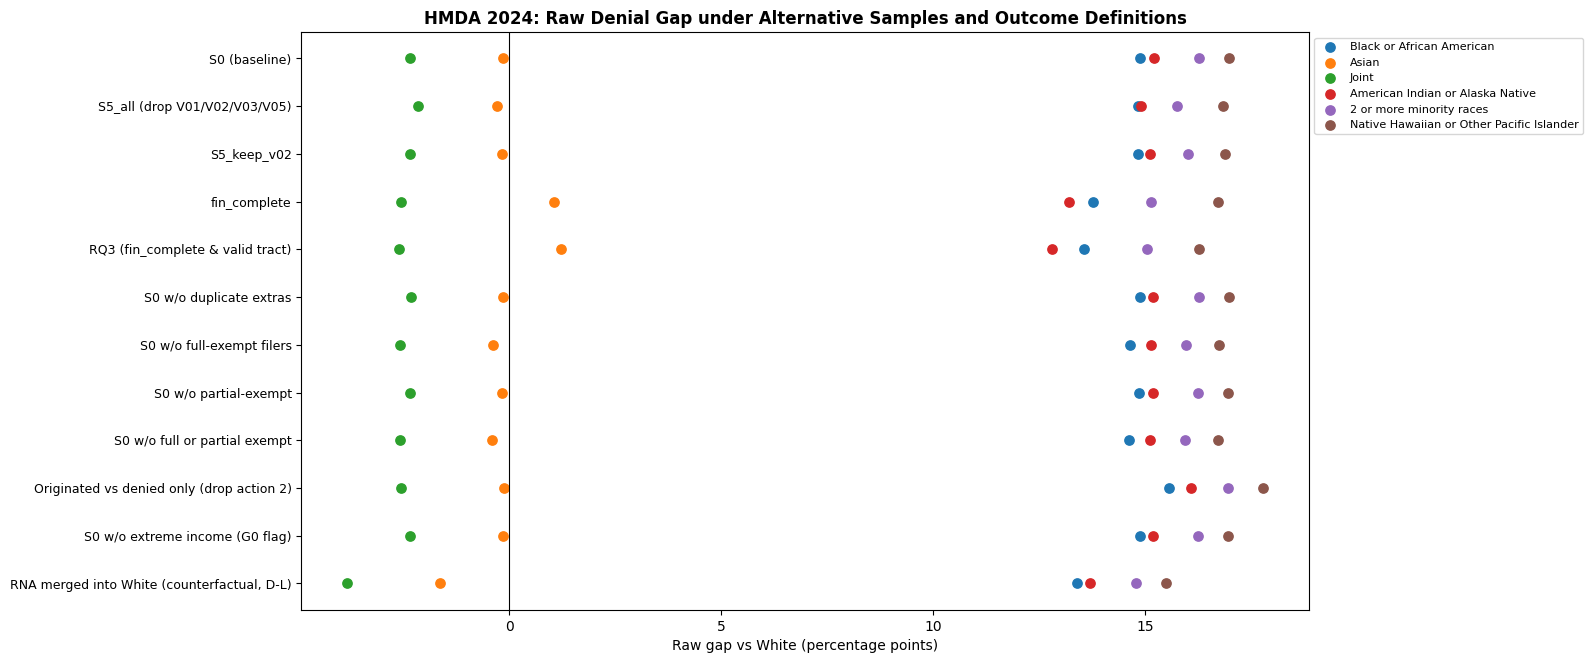

In [86]:
# Step 1: Dot plot of the gap per sample
pv = SENS.pivot(index="sample", columns="group", values="gap_pp").reindex(list(SAMPLES) + [RNA_LABEL]); yy = np.arange(len(pv))[::-1]
fig, ax = plt.subplots(figsize=(13, 7.5))
for g in NON_REF: ax.scatter(pv[g], yy, label=g, s=45)
ax.axvline(0, color="black", linewidth=0.8); ax.set_yticks(yy); ax.set_yticklabels(pv.index, fontsize=9); ax.set_xlabel(f"Raw gap vs {REF_RACE} (percentage points)")
ax.set_title("HMDA 2024: Raw Denial Gap under Alternative Samples and Outcome Definitions", fontweight="bold"); ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
save_fig_and_log(fig, "B14_fig_33_sample_sensitivity.png"); plt.show()

## G2: Missing-Value Handling Sensitivity with a Coarse Specification (RQ4, D-X)
- **Input:** `df_s0` bins (D0), `kitagawa()` (C5), D-U flags.
- **Process:** Coarse strata = DTI group (5) × CLTV group (5) × income group (5), at most 125 strata. Two handlings: **(a)** drop rows with missing/invalid DTI, CLTV or income; **(b)** keep them as explicit `MISSING` categories (D-V). Option (c) (missing indicator + median fill) gives the same strata as (b) in a stratified analysis, because the filled value falls in one bin and the indicator isolates it; it only matters in regression (later step), so it is not run here `[Hypothesis]`. Compare `rate_pp` with `raw_gap_pp` **inside the same sample**. Groups with too few kept strata stay flagged `low_reliability`.
- **Output:** `B14_rq4_missing_handling.csv`.

In [87]:
# Step 1: regroup with explicit missing level  [CHANGE: added na_label]
def regroup(s, mapping, order, default=0, na_label=None):   # [CHANGE: added na_label]
    lut = np.array([order.index(mapping[c]) if c in mapping else default for c in s.cat.categories])
    codes = s.cat.codes.to_numpy()
    if na_label is not None:                                  # [ADD]
        lut = np.append(lut, order.index(na_label))
        codes = np.where(codes < 0, len(lut) - 1, codes)
    assert (codes >= 0).all(), "NaN in regrouped column"
    return pd.Series(pd.Categorical.from_codes(lut[codes], order), index=s.index)
DTI_G = {"<20": "<36", "20-<30": "<36", "30-<36": "<36", "36-40": "36-45", "41-45": "36-45", "46-49": "46-60", "50-60": "46-60", ">60": ">60", "MISSING: na": "MISSING", "MISSING: exempt": "MISSING"}
CLTV_G = {"<=60": "<=80", "60-70": "<=80", "70-<80": "<=80", "=80": "<=80", "80-90": "80-95", "90-95": "80-95", "95-97": "95-100", "97-100": "95-100", ">100": ">100", "MISSING / invalid": "MISSING"}
INC_G = {**{f"D{i:02d}": ("D01-D03" if i <= 3 else "D04-D07" if i <= 7 else "D08-D10") for i in range(1, 11)}, "Income <= 0": "Income <= 0", "Income missing": "Income missing"}
assert set(ORDERS["dti_cat"]) <= set(DTI_G) and set(ORDERS["cltv_bin"]) <= set(CLTV_G) and set(ORDERS["income_decile"]) <= set(INC_G), "Unmapped bin level"
df_s0["dti_g"] = regroup(df_s0["dti_cat"], DTI_G, ["<36", "36-45", "46-60", ">60", "MISSING"])
df_s0["cltv_g"] = regroup(df_s0["cltv_bin"], CLTV_G, ["<=80", "80-95", "95-100", ">100", "MISSING"])
df_s0["inc_g"] = regroup(df_s0["income_decile"], INC_G, ["D01-D03", "D04-D07", "D08-D10", "Income <= 0", "Income missing"])

# Step 2: Decompose under (a) and (b)
COARSE = ["dti_g", "cltv_g", "inc_g"]
valid = ((df_s0["dti_g"] != "MISSING") & (df_s0["cltv_g"] != "MISSING") & ~df_s0["inc_g"].isin(["Income <= 0", "Income missing"])).to_numpy()
ST_A = agg_on(df_s0.loc[valid, ["derived_race", "is_denied"] + COARSE], ["derived_race"] + COARSE); ST_B = agg_counts(["derived_race"] + COARSE)
parts = []
for label, st in (("(a) drop missing/invalid DTI, CLTV, income", ST_A), ("(b) explicit MISSING categories (all S0)", ST_B)):
    t = pd.DataFrame([kitagawa(st, g, REF_RACE, COARSE)[0] for g in NON_REF]); t.insert(0, "handling", label); t.insert(1, "n_sample", int(st["n_apps"].sum())); parts.append(t)
G2 = pd.concat(parts, ignore_index=True)
G2["pooled_share_max_pct"] = G2[["pooled_share_group_pct", "pooled_share_ref_pct"]].max(axis=1); G2["low_reliability"] = G2["pooled_share_max_pct"] > POOLED_MAX_PCT
G2["rate_pct_of_raw_gap"] = np.where(G2["raw_gap_pp"].abs() >= MIN_GAP_PP_FOR_SHARE, G2["rate_pp"] * 100.0 / G2["raw_gap_pp"], np.nan)
assert (G2["identity_residual_pp"].abs() < 1e-9).all(); save_and_log(G2, "B14_rq4_missing_handling.csv")
display(G2[["handling", "group", "raw_gap_pp", "composition_pp", "rate_pp", "n_strata_kept", "pooled_share_max_pct", "low_reliability"]])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq4_missing_handling.csv | Size: 3.43 KB | Shape: (12, 18)


,handling,group,raw_gap_pp,composition_pp,rate_pp,n_strata_kept,pooled_share_max_pct,low_reliability
0,"(a) drop missing/invalid DTI, CLTV, income",Black or African American,13.7325,3.1545,10.5780,42,0.6809,False
1,"(a) drop missing/invalid DTI, CLTV, income",Asian,0.9353,0.3405,0.5948,32,5.0930,False
2,"(a) drop missing/invalid DTI, CLTV, income",Joint,-2.4239,-3.4055,0.9816,26,9.4748,False
3,"(a) drop missing/invalid DTI, CLTV, income",American Indian or Alaska Native,13.0121,2.1167,10.8955,17,25.6804,True
4,"(a) drop missing/invalid DTI, CLTV, income",2 or more minority races,14.9170,0.3487,14.5683,4,75.9938,True
5,"(a) drop missing/invalid DTI, CLTV, income",Native Hawaiian or Other Pacific Islander,16.6555,3.5876,13.0680,6,59.6423,True
6,(b) explicit MISSING categories (all S0),Black or African American,14.8752,3.9198,10.9554,62,2.5406,False
7,(b) explicit MISSING categories (all S0),Asian,-0.1554,-1.1093,0.9538,40,11.1252,True
8,(b) explicit MISSING categories (all S0),Joint,-2.3383,-3.1646,0.8263,34,15.0633,True
9,(b) explicit MISSING categories (all S0),American Indian or Alaska Native,15.1927,3.9140,11.2786,21,32.3713,True


## G4: Inventory of Missing Underwriting Variables (RQ4)
- **Input:** `B06_SCHEMA` (column names of `B06_analytic.parquet`, i.e. the 99 HMDA fields plus derived).
- **Process:** A name search checks that no field named like a credit score value, assets/reserves, AUS result, application date, employment, loan officer/broker or lender name exists (type-only fields such as `*_credit_score_type` are excluded from the search). `[Verified: B06 schema]` if the search finds nothing. The table lists, for each missing variable, the proxy that does exist and why a remaining gap cannot be read as unexplained by observable credit risk.
- **Output:** `B14_rq4_missing_variables.csv`.

In [88]:
import re
# Step 1: Verify absence by name search on the schema (type-only fields excluded)
PAT = r"credit_score|score_value|asset|reserve|aus_result|application_date|action_taken_date|employ|loan_officer|broker|lender_name|respondent"
HITS = [c for c in B06_SCHEMA.names if re.search(PAT, c) and not c.endswith("_type")]
VERIFIED = "[Verified: B06 schema, no matching field]" if not HITS else f"[Check: fields found {HITS}]"

# Step 2: Inventory table
rows = [("Credit score value", "applicant_credit_score_type, co_applicant_credit_score_type (scoring model type only)", "Main underwriting variable unobserved; correlated with income and race, so a remaining gap may reflect it"),
        ("Assets and reserves", "income, property_value, loan_amount (weak proxies)", "Cash to close and reserves cannot be assessed (denial reason 5 exists only after denial)"),
        ("AUS recommendation/result", "aus_1..aus_5 (system used, not result)", "Automated underwriting outcome is a major decision input, not available"),
        ("Application and decision dates", "activity_year only", "No time ordering: no chronological split, rate-lock timing or seasonality"),
        ("Employment history / income documentation", "income (as reported)", "Income verification quality unobserved"),
        ("Lender identity details (type, name)", "lei (20-char ID), lender_size_bucket, lender_n_apps", "Bank / credit union / independent mortgage company not identifiable; LEI mapping is out of scope (D-O)"),
        ("Loan officer / broker detail", "submission_of_application (channel flag)", "Origination channel and officer effects unobserved")]
MISSV = pd.DataFrame(rows, columns=["missing_variable", "closest_public_proxy", "limitation_for_interpretation"]); MISSV["evidence"] = VERIFIED
save_and_log(MISSV, "B14_rq4_missing_variables.csv"); print(VERIFIED); display(MISSV)

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq4_missing_variables.csv | Size: 1.42 KB | Shape: (7, 4)
[Verified: B06 schema, no matching field]


,missing_variable,closest_public_proxy,limitation_for_interpretation,evidence
0,Credit score value,"applicant_credit_score_type, co_applicant_cred...",Main underwriting variable unobserved; correla...,"[Verified: B06 schema, no matching field]"
1,Assets and reserves,"income, property_value, loan_amount (weak prox...",Cash to close and reserves cannot be assessed ...,"[Verified: B06 schema, no matching field]"
2,AUS recommendation/result,"aus_1..aus_5 (system used, not result)",Automated underwriting outcome is a major deci...,"[Verified: B06 schema, no matching field]"
3,Application and decision dates,activity_year only,"No time ordering: no chronological split, rate...","[Verified: B06 schema, no matching field]"
4,Employment history / income documentation,income (as reported),Income verification quality unobserved,"[Verified: B06 schema, no matching field]"
5,"Lender identity details (type, name)","lei (20-char ID), lender_size_bucket, lender_n...",Bank / credit union / independent mortgage com...,"[Verified: B06 schema, no matching field]"
6,Loan officer / broker detail,submission_of_application (channel flag),Origination channel and officer effects unobse...,"[Verified: B06 schema, no matching field]"


## G5: Stability of the Black-White Gap across Subgroups (RQ4)
- **Input:** `df_s0`, `gap_vs_ref` (F0), `C1`.
- **Process:** The gap of `GAP_GROUP` vs White within each level of `loan_purpose`, `loan_type`, `lien_status`, `occupancy_type`, `dti_cat`, `income_decile` and `state_size` (terciles of state application volume, `[Hypothesis]`: three groups). Cells failing D-M are `low_n` (never counted). `sign_flip` = gap < 0 in a valid cell; `ci_includes_0` flags cells where the Newcombe CI covers 0.
- **Output:** `B14_rq4_gap_stability.csv`, `B14_fig_34_gap_stability.png`.

S0 rows with missing state_code: 44725
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_rq4_gap_stability.csv | Size: 7.79 KB | Shape: (41, 14)


,n_valid,min_gap,max_gap,n_sign_flip,n_ci_includes_0
variable,,,,,
dti_cat,10,1.1042,32.6416,0,0
income_decile,12,4.7711,15.8237,0,0
lien_status,2,14.6654,16.7157,0,0
loan_purpose,5,10.1154,23.8425,0,0
loan_type,4,7.0831,20.2732,0,0
occupancy_type,3,14.6190,30.9706,0,0
state_size,4,12.4545,16.8630,0,0


Saved figure: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\figures\B14_fig_34_gap_stability.png | Size: 158.14 KB


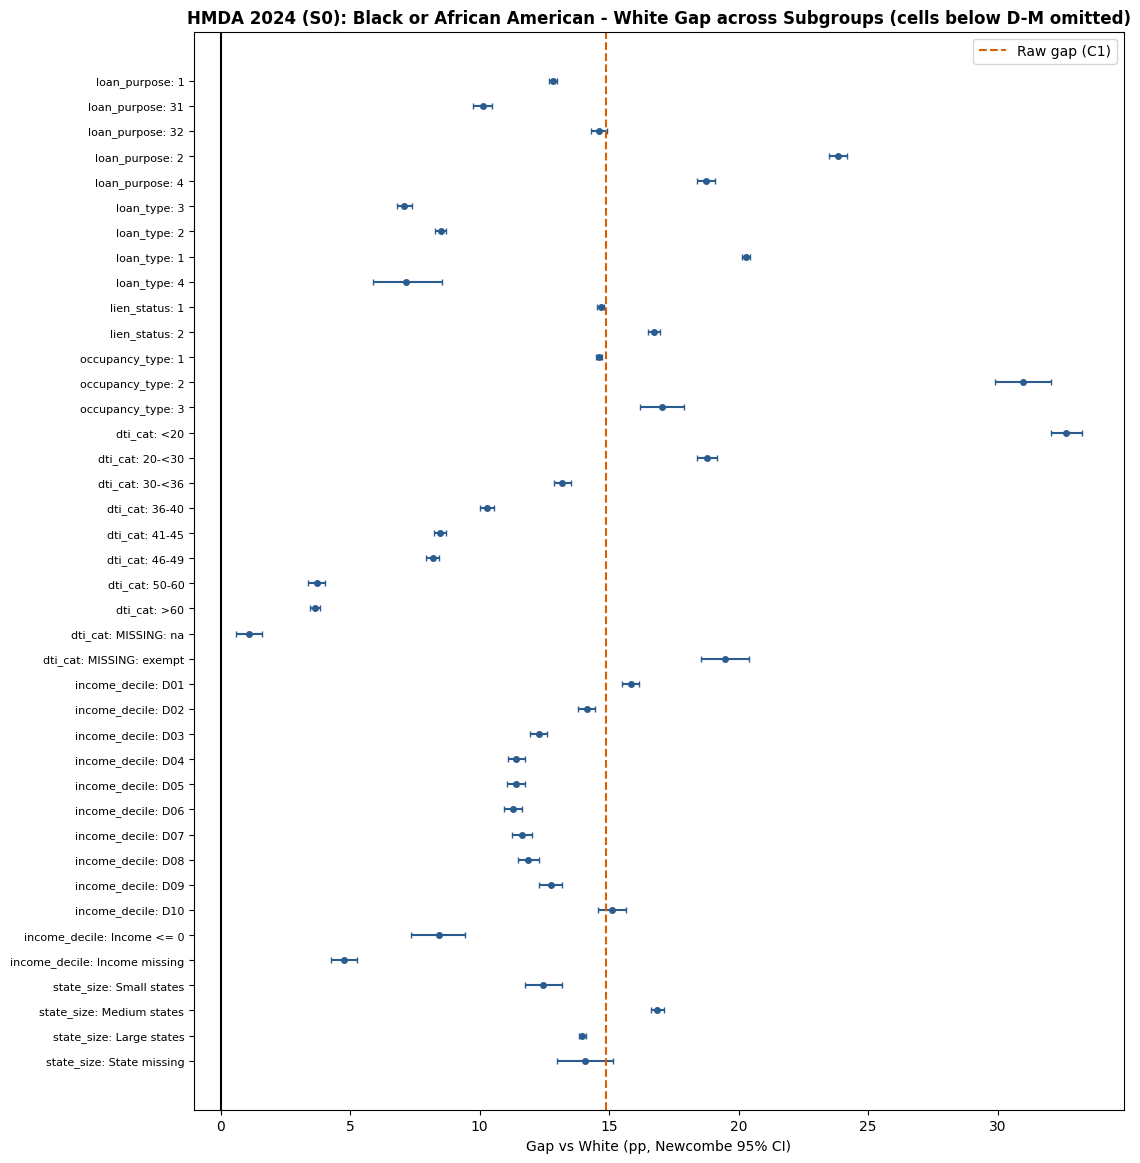

In [89]:
# Step 1: State-size terciles (by application volume), then gaps per subgroup level
GAP_GROUP = "Black or African American"; SS = ["Small states", "Medium states", "Large states"]
SS_ALL = SS + ["State missing"]                                                          # [ADD]
sv = st_tot.set_index("state_code")["n_apps"]
sv = sv[sv.index.notna()]                                                                # [ADD] a NULL state must not be ranked as a state
STATE_MAP = pd.qcut(sv.rank(method="first"), 3, labels=SS).astype(str).to_dict()
print("S0 rows with missing state_code:", df_s0["state_code"].isna().sum())              # [ADD] expect 44,725
df_s0["state_size"] = regroup(df_s0["state_code"], STATE_MAP, SS_ALL, na_label="State missing")   # [CHANGE]
parts = []
for v in ["loan_purpose", "loan_type", "lien_status", "occupancy_type", "dti_cat", "income_decile", "state_size"]:
    t = gap_vs_ref(agg_counts([v, "derived_race"]), [v], GAP_GROUP).rename(columns={v: "level"}); t.insert(0, "variable", v); parts.append(t)
STAB = pd.concat(parts, ignore_index=True); STAB["raw_gap_pp"] = float(C1.set_index("derived_race").loc[GAP_GROUP, "gap_pp"])
STAB["sign_flip"] = (STAB["gap_pp"] < 0) & ~STAB["low_n"]; STAB["ci_includes_0"] = (STAB["gap_ci_lo"] <= 0) & (STAB["gap_ci_hi"] >= 0) & ~STAB["low_n"]
save_and_log(STAB, "B14_rq4_gap_stability.csv")
display(STAB[~STAB["low_n"]].groupby("variable").agg(n_valid=("gap_pp", "size"), min_gap=("gap_pp", "min"), max_gap=("gap_pp", "max"), n_sign_flip=("sign_flip", "sum"), n_ci_includes_0=("ci_includes_0", "sum")))

# Step 2: Dot plot of valid cells
v = STAB[~STAB["low_n"]].reset_index(drop=True); yy = np.arange(len(v))[::-1]
fig, ax = plt.subplots(figsize=(12, 0.3 * len(v) + 2))
ax.errorbar(v["gap_pp"], yy, xerr=[(v["gap_pp"] - v["gap_ci_lo"]).to_numpy(), (v["gap_ci_hi"] - v["gap_pp"]).to_numpy()], fmt="o", color="#2b5c8f", capsize=2, markersize=4)
ax.axvline(0, color="black"); ax.axvline(float(STAB["raw_gap_pp"].iloc[0]), color="#d95f02", linestyle="--", label="Raw gap (C1)")
ax.set_yticks(yy); ax.set_yticklabels(v["variable"] + ": " + v["level"], fontsize=8); ax.set_xlabel(f"Gap vs {REF_RACE} (pp, Newcombe 95% CI)"); ax.legend()
ax.set_title(f"HMDA 2024 (S0): {GAP_GROUP} - {REF_RACE} Gap across Subgroups (cells below D-M omitted)", fontweight="bold")
save_fig_and_log(fig, "B14_fig_34_gap_stability.png"); plt.show()

## G6: Pandas-to-PySpark Equivalents Ledger
- **Input:** The B14 table functions used as equivalence targets (eda_plan.md §12).
- **Process:** One row per target table or technique: the Pandas implementation, the intended PySpark equivalent and the known semantic differences (NULL handling, quantile method, bin edge convention, dtype). Tolerances: exact for counts; 1e-9 for rates; quantile methods documented. No numbers are typed in.
- **Output:** `B14_pyspark_equivalents.csv`.

In [90]:
rows = [
 ("E1", "S0 row count and overall denial rate", "len(df_s0); df_s0['is_denied'].mean()", "df.count(); df.agg(F.avg('is_denied'))", "Int8 nullable vs integer; S0 has no NULL is_denied", "exact / 1e-9"),
 ("E2", "Denial rate by derived_race (C1)", "groupby('derived_race', observed=True, dropna=False)['is_denied'].agg(count, sum)", "groupBy('derived_race').agg(F.count('*'), F.sum('is_denied'))", "Pandas NULL group needs dropna=False; Spark keeps NULL group by default", "exact counts; 1e-9"),
 ("E3", "Race x loan_type counts / denied / rate (Proposal benchmark workload)", "agg_counts(['derived_race','loan_type'])", "groupBy('derived_race','loan_type').agg(...)", "category dtype vs string; empty groups appear in Pandas if observed=False", "exact"),
 ("E4", "Missing share per key variable (A4)", "value_counts() on *_status columns", "groupBy(status).count()", "'blank' vs NULL vs 'NA' string tokens must match B06 definitions", "exact"),
 ("E5", "Quantiles of loan_amount, income (B1)", "numpy.quantile (linear interpolation)", "approxQuantile(col, probs, 0.0) or percentile_approx", "Interpolation differs from nearest-rank; relativeError 0 on a check run only", "document difference"),
 ("E6", "Lender x race counts (F6-F9 input)", "groupby(['lender_code','derived_race']) after pd.factorize", "groupBy('lei','derived_race') (IDs: dense_rank by volume)", "Anonymous IDs differ; compare counts, not IDs", "exact"),
 ("T1", "Wilson CI", "vectorised numpy wilson_ci()", "F.when/F.sqrt column expressions", "n = 0 gives NaN vs NULL", "1e-9"),
 ("T2", "Bins (CLTV, LTI, income decile)", "pd.cut(right=True for CLTV, right=False for LTI) / qcut", "F.when chain (Bucketizer is left-closed); approxQuantile for decile edges", "Edge convention and quantile ties differ", "exact if edges identical"),
 ("T3", "Kitagawa decomposition", "pivot_table + vector arithmetic (kitagawa())", "groupBy + pivot or join of group and reference aggregates", "Pooling of D-M-failing strata done after aggregation in both", "1e-9"),
 ("T4", "Lender-cluster bootstrap (C1b)", "numpy multinomial weights x lender-race matrix", "run on the aggregated table in Pandas (aggregation in Spark)", "RNG differs; compare CIs, not replicates", "interval overlap")]
PYSPARK_EQ = pd.DataFrame(rows, columns=["table_id", "what", "pandas_impl", "pyspark_equiv", "known_semantic_differences", "tolerance"])
save_and_log(PYSPARK_EQ, "B14_pyspark_equivalents.csv"); display(PYSPARK_EQ[["table_id", "what", "tolerance"]])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_pyspark_equivalents.csv | Size: 2.09 KB | Shape: (10, 6)


,table_id,what,tolerance
0,E1,S0 row count and overall denial rate,exact / 1e-9
1,E2,Denial rate by derived_race (C1),exact counts; 1e-9
2,E3,Race x loan_type counts / denied / rate (Propo...,exact
3,E4,Missing share per key variable (A4),exact
4,E5,"Quantiles of loan_amount, income (B1)",document difference
5,E6,Lender x race counts (F6-F9 input),exact
6,T1,Wilson CI,1e-9
7,T2,"Bins (CLTV, LTI, income decile)",exact if edges identical
8,T3,Kitagawa decomposition,1e-9
9,T4,Lender-cluster bootstrap (C1b),interval overlap


## G7: EDA Findings Log
- **Input:** `C1`, `KIT_SUM`, `D4`, `D6B`, `F5`, `LGAP_SUM`, `LKIT`, `F4`, `LD`, `SENS`, `STAB`, `REL_V`, `G2`, `EXT_DETAIL`.
- **Process:** Each finding's text is an f-string over computed variables (Convention 4.3). The label is `[Verified: B14 run <date>]` for direct tabulations and `[Hypothesis]` where the result is low reliability or an interpretation (D-U/D-X). Wording is descriptive: "gap", "association"; never "discrimination".
- **Output:** `B14_eda_findings.csv`.

In [91]:
import datetime
RUN_DATE = str(datetime.date.today()); VER = f"[Verified: B14 run {RUN_DATE}]"; HYP = "[Hypothesis]"
c1, ks, d4, f5, lg, lk = C1.set_index("derived_race"), KIT_SUM.set_index("group"), D4.set_index(["spec", "group"]), F5.set_index("group"), LGAP_SUM.set_index("group"), LKIT.set_index("group")
SP_F, SP_P = list(SPECS); vv = LD[~LD["low_n"]]; phi_ = (vv["z"] ** 2).sum() / (len(vv) - 1)
sb = SENS[SENS["group"] == GAP_GROUP]; lo, hi = sb.loc[sb["gap_pp"].idxmin()], sb.loc[sb["gap_pp"].idxmax()]
g2b = G2[(G2["group"] == GAP_GROUP)].set_index("handling"); stv = STAB[~STAB["low_n"]]; top = REL_V.iloc[0]
FIND = [
 ("F01", "RQ1", f"Raw denial gap {GAP_GROUP} vs {REF_RACE}: {c1.loc[GAP_GROUP,'gap_pp']:+.2f} pp (OR {c1.loc[GAP_GROUP,'odds_ratio']:.2f}; lender-cluster 95% CI {c1.loc[GAP_GROUP,'boot_gap_ci_lo']:.2f} to {c1.loc[GAP_GROUP,'boot_gap_ci_hi']:.2f})", "B14_rq1_raw_gap.csv", "Descriptive; credit score, assets, AUS unobserved", VER),
 ("F02", "RQ1", f"Product mix (loan type x purpose x lien x occupancy): composition {ks.loc[GAP_GROUP,'composition_pp']:+.2f} pp, rate {ks.loc[GAP_GROUP,'rate_pp']:+.2f} pp for {GAP_GROUP}", "B14_rq1_kitagawa.csv", f"low_reliability = {bool(ks.loc[GAP_GROUP,'low_reliability'])}; depends on strata definition", VER if not ks.loc[GAP_GROUP, "low_reliability"] else HYP),
 ("F03", "RQ2", f"Within financial strata, rate effect for {GAP_GROUP}: FIN {d4.loc[(SP_F, GAP_GROUP),'rate_pp']:+.2f} pp, PRODFIN {d4.loc[(SP_P, GAP_GROUP),'rate_pp']:+.2f} pp; pooled share {d4.loc[(SP_F, GAP_GROUP),'pooled_share_max_pct']:.1f}% / {d4.loc[(SP_P, GAP_GROUP),'pooled_share_max_pct']:.1f}%", "B14_rq2_stratified_gap.csv", "Pooled strata inflate the rate effect (D-X); not a headline estimate", HYP),
 ("F04", "RQ2", f"Restricting to fin_complete retains {D6B.loc[GAP_GROUP,'retention_pct']:.1f}% of {GAP_GROUP} vs {D6B.loc[REF_RACE,'retention_pct']:.1f}% of {REF_RACE}; gap shifts {D6B.loc[GAP_GROUP,'gap_shift_pp']:+.2f} pp", "B14_rq2_fin_complete_gap.csv", "Informative missingness: any narrowing must be compared with S0", VER),
 ("F05", "RQ3", f"State gaps for {GAP_GROUP}: mean {f5.loc[GAP_GROUP,'mean_gap_pp']:.1f} pp, SD {f5.loc[GAP_GROUP,'sd_gap_pp']:.1f}, range {f5.loc[GAP_GROUP,'min_gap_pp']:.1f} to {f5.loc[GAP_GROUP,'max_gap_pp']:.1f} across {int(f5.loc[GAP_GROUP,'n_states_valid'])} valid states", "B14_rq3_state_gap_heterogeneity.csv", "States below D-M suppressed", VER),
 ("F06", "RQ3", f"Within {int(lg.loc[GAP_GROUP,'n_lenders_valid'])} lenders (covering {lg.loc[GAP_GROUP,'coverage_pct']:.1f}% of {GAP_GROUP} applications) median raw gap {lg.loc[GAP_GROUP,'median_gap_pp']:+.1f} pp; {lg.loc[GAP_GROUP,'share_gap_ci_gt0_pct']:.0f}% have CI above 0", "B14_rq3_lender_gap_summary.csv", "Large lenders only; no product/financial controls", VER),
 ("F07", "RQ3", f"Lender sorting (lender as stratum): composition {lk.loc[GAP_GROUP,'composition_pp']:+.2f} pp, rate {lk.loc[GAP_GROUP,'rate_pp']:+.2f} pp", "B14_rq3_lender_standardised_gap.csv", f"pooled share {lk.loc[GAP_GROUP,'pooled_share_max_pct']:.1f}%; low reliability", HYP),
 ("F08", "RQ3", f"Lender denial rates are overdispersed: phi = {phi_:.0f}; {vv['outside_998'].mean() * 100:.1f}% of lenders passing D-M lie outside 99.8% funnel limits", "B14_rq3_lender_funnel.csv", "Sorting and product niches, not evidence about lender policy (D-O)", VER),
 ("F09", "RQ3", f"{F4.loc[GAP_GROUP,'pct_tract_na']:.2f}% of {GAP_GROUP} applications lack a tract; their denial rate is {F4.loc[GAP_GROUP,'denial_rate_tract_na_pct']:.1f}% vs {F4.loc[GAP_GROUP,'denial_rate_valid_tract_pct']:.1f}% on valid tracts", "B14_rq3_tract_na_selection.csv", "Dropping tract-NA rows is a selection step (D-I)", VER),
 ("F10", "RQ4", f"{GAP_GROUP} gap ranges {lo['gap_pp']:.2f} pp ({lo['sample']}) to {hi['gap_pp']:.2f} pp ({hi['sample']}) across {SENS['sample'].nunique()} sample definitions", "B14_rq4_sample_sensitivity.csv", "Raw gap only; no controls", VER),
 ("F11", "RQ4", f"{GAP_GROUP} gap is negative in {int(stv['sign_flip'].sum())} of {len(stv)} valid subgroup cells; CI covers 0 in {int(stv['ci_includes_0'].sum())}", "B14_rq4_gap_stability.csv", "Subgroups defined on observables only", VER),
 ("F12", "RQ4", f"Coarse spec, rate effect for {GAP_GROUP}: {g2b.loc[g2b.index[0],'rate_pp']:+.2f} pp (drop missing) vs {g2b.loc[g2b.index[1],'rate_pp']:+.2f} pp (explicit missing)", "B14_rq4_missing_handling.csv", f"low_reliability: {bool(g2b['low_reliability'].any())}", HYP if g2b["low_reliability"].any() else VER),
 ("F13", "Data", f"{EXT_N} S0 rows have income above ${INCOME_EXTREME_K / 1000:,.0f}M (denial rate {EXT_RATE:.1f}%)", "B14_income_extreme_detail.csv", "Likely reporting error; unverifiable with public data (D-W)", HYP),
 ("F14", "RQ2", f"Strongest categorical association with denial: {top['variable']} (bias-corrected Cramer's V {top['cramers_v_bc']:.2f})", "B14_rel_cramers_v.csv", "Includes MISSING categories; association only", VER)]
# [ADD] Step: findings F15-F18 (D7c, F3, F10, G5); no existing finding is changed
bwr = d7c[d7c["race"] == GAP_GROUP].set_index("label")
tmc = F3[(F3["dimension"] == "tract_minority_bin") & (F3["derived_race"] == GAP_GROUP) & (F3["level"] != "No tract") & ~F3["low_n"]]
fx = F10[F10["exempt_status"] == "Full exempt (28)"]
fx_small = fx.loc[fx["lender_size_bucket"] == "Small/Community", "n_apps"].sum() * 100.0 / fx["n_apps"].sum()
lo_s, hi_s = stv.loc[stv["gap_pp"].idxmin()], stv.loc[stv["gap_pp"].idxmax()]
FIND += [
 ("F15", "RQ2", f"Primary denial reasons, denials per 100 applications, {GAP_GROUP} vs {REF_RACE}: credit history {bwr.loc['Credit history', 'diff_primary_pp']:+.2f} pp ({bwr.loc['Credit history', 'share_of_raw_gap_primary_pct']:.1f}% of the raw gap), DTI {bwr.loc['DTI', 'diff_primary_pp']:+.2f} pp ({bwr.loc['DTI', 'share_of_raw_gap_primary_pct']:.1f}%)", "B14_rq2_denial_reasons_contribution.csv", "Lender-reported, post-decision; accounting, not a counterfactual (D-AD)", VER),
 ("F16", "RQ3", f"Within tract minority-share classes the {GAP_GROUP} gap is {tmc['gap_vs_white_pp'].min():+.1f} to {tmc['gap_vs_white_pp'].max():+.1f} pp across {len(tmc)} classes", "B14_rq3_tract_context.csv", "Raw gap; tract income cut-offs unverified (A10)", VER),
 ("F17", "RQ3", f"Full exempt filers appear only in {', '.join(sorted(fx['lender_size_bucket'].unique()))} lenders; Small/Community holds {fx_small:.1f}% of them", "B14_rq3_exempt_by_lender_size.csv", "Why denial is high for exempt filers at Medium lenders is not explained", VER),
 ("F18", "RQ4", f"{GAP_GROUP} gap across {len(stv)} valid subgroup cells: {lo_s['gap_pp']:.2f} pp ({lo_s['variable']}: {lo_s['level']}) to {hi_s['gap_pp']:.2f} pp ({hi_s['variable']}: {hi_s['level']})", "B14_rq4_gap_stability.csv", "One variable at a time, not a joint control", VER),
]

FINDINGS = pd.DataFrame(FIND, columns=["finding_id", "rq", "pattern", "evidence_artifact", "caveat", "label"]); assert FINDINGS["pattern"].notna().all()
save_and_log(FINDINGS, "B14_eda_findings.csv"); display(FINDINGS[["finding_id", "rq", "pattern", "label"]])

Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_eda_findings.csv | Size: 4.08 KB | Shape: (18, 6)


,finding_id,rq,pattern,label
0,F01,RQ1,Raw denial gap Black or African American vs Wh...,[Verified: B14 run 2026-11-11]
1,F02,RQ1,Product mix (loan type x purpose x lien x occu...,[Verified: B14 run 2026-11-11]
2,F03,RQ2,"Within financial strata, rate effect for Black...",[Hypothesis]
3,F04,RQ2,Restricting to fin_complete retains 83.9% of B...,[Verified: B14 run 2026-11-11]
4,F05,RQ3,State gaps for Black or African American: mean...,[Verified: B14 run 2026-11-11]
5,F06,RQ3,Within 97 lenders (covering 69.8% of Black or ...,[Verified: B14 run 2026-11-11]
6,F07,RQ3,Lender sorting (lender as stratum): compositio...,[Hypothesis]
7,F08,RQ3,Lender denial rates are overdispersed: phi = 2...,[Verified: B14 run 2026-11-11]
8,F09,RQ3,2.14% of Black or African American application...,[Verified: B14 run 2026-11-11]
9,F10,RQ4,Black or African American gap ranges 13.39 pp ...,[Verified: B14 run 2026-11-11]


## G8: Hand-off Design Recommendation and Summary
- **Input:** All B14 results in memory (`roles_df`, `leak_cols`, `SAMPLES`, `C1`, `ARTIFACTS`...).
- **Process:** Write `B14_hand_off.md` (reference groups, samples, controls per stage, excluded variables, missing-value policy, inference, open points) with every number taken from variables. Then build `B14_summary.csv` (dynamic, like B05/B06). Both are logged with path and size.
- **Output:** `B14_hand_off.md`, `B14_summary.csv`.

In [92]:
# Step 1: Hand-off text (all numbers are f-strings)
excl = sorted(set(roles_df.loc[roles_df["role"] == "post_decision_exclude", "column_name"]) | set(leak_cols))
nS = {k: int(v.sum()) for k, v in SAMPLES.items()}
txt = f"""# B14 Hand-off: Design for the Sequential Decomposition (run {RUN_DATE})

## Reference groups and metrics
- Reference: {REF_RACE} (D-J). Headline groups: {", ".join(NON_REF)}. `Race Not Available` / `Free Form Text Only` kept in accounting, excluded from headline gaps (D-L).
- Report gap (pp), risk ratio, odds ratio; inference = lender-cluster bootstrap (B = {BOOT_B:,}, seed {SEED}), Wilson CIs, no p-value tables (D-Q).

## Samples (rows)
- S0: {nS['S0 (baseline)']:,} | S5_all: {nS['S5_all (drop V01/V02/V03/V05)']:,} | fin_complete: {nS['fin_complete']:,} | RQ3 (fin_complete & valid tract): {nS['RQ3 (fin_complete & valid tract)']:,}.
- Always show S0 next to `fin_complete` (selection, D6B) and run the G1 variants as robustness.

## Controls by stage (observed, pre-decision only)
1. Raw gap: none.
2. Product: loan_type, loan_purpose, lien_status, occupancy_type, construction_method, derived_dwelling_category, conforming_loan_limit, open_end_line_of_credit.
3. Financial: dti_cat, cltv_bin, income_decile (or log_income), log_loan_amount, lti_bin; missing values as explicit categories (D-V). 
4. Geography and lender: state_code, msa_class, tract_minority_bin, tract_income_level (tract-NA excluded for RQ3, D-I); lender size bucket or lender fixed effects (lenders anonymous, D-O).

## Excluded variables (leakage or diagnostic)
- Post-decision / outcome-revealing ({len(excl)}): {", ".join(excl)}.
- Process proxies `aus_1`, `applicant_credit_score_type`: not in the main specification; used only in the "with proxies" robustness spec (D-Y).
- loan_term: product control (D-AA)
- Denial reasons are descriptive only (D7). `flag_*`, `in_*`, `*_status` columns are diagnostics.

## Cautions
- Stratified decompositions are not estimates when `low_reliability` (D-U/D-X); use the coarse spec (G2) and the raw gap with cluster CI.
- Income > ${INCOME_EXTREME_K / 1000:,.0f}M flagged ({EXT_N} rows; D-W): run with and without.
- Unobserved: {", ".join(MISSV["missing_variable"])} (G4). No remaining gap is interpreted as discrimination.
"""
HAND_OFF_PATH = OUTPUT_DIR / "B14_hand_off.md"; HAND_OFF_PATH.write_text(txt, encoding="utf-8")
print(f"Saved: {HAND_OFF_PATH} | Size: {HAND_OFF_PATH.stat().st_size / 1024:.2f} KB | Lines: {txt.count(chr(10))}")

# Step 2: Dynamic summary
# [CHANGE] count unique files, not save calls (some files are saved twice)
ART = pd.DataFrame(ARTIFACTS).drop_duplicates("artifact", keep="last")
n_tab, n_fig = (int((ART["type"] == t).sum()) for t in ("table", "figure"))
SUMMARY = pd.DataFrame([("Frame", f"S0 {len(df_s0):,} rows; denial rate {df_s0['is_denied'].mean() * 100:.2f}%", "B14_frame_profile.csv"),
    ("Headline raw gap", f"{GAP_GROUP}: {c1.loc[GAP_GROUP, 'gap_pp']:+.2f} pp (cluster CI {c1.loc[GAP_GROUP, 'boot_gap_ci_lo']:.2f} to {c1.loc[GAP_GROUP, 'boot_gap_ci_hi']:.2f})", "B14_rq1_raw_gap.csv"),
    ("Sample sensitivity", f"{GAP_GROUP} gap {lo['gap_pp']:.2f} to {hi['gap_pp']:.2f} pp over {SENS['sample'].nunique()} samples", "B14_rq4_sample_sensitivity.csv"),
    ("Lender dispersion", f"phi = {phi_:.0f} over {len(vv):,} lenders passing D-M", "B14_rq3_lender_funnel.csv"),
    ("Artifacts", f"{n_tab} tables, {n_fig} figures logged this run", "B14_summary.csv"), ("Findings", f"{len(FINDINGS)} findings", "B14_eda_findings.csv")], columns=["Item", "Finding", "Artifact"])
save_and_log(SUMMARY, "B14_summary.csv"); display(SUMMARY)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_hand_off.md | Size: 2.34 KB | Lines: 26
Saved table: d:\H-NEU\004\44 - Big Data\Final project\B14 - EDA\output\B14_summary.csv | Size: 0.49 KB | Shape: (6, 3)


,Item,Finding,Artifact
0,Frame,"S0 8,136,664 rows; denial rate 24.62%",B14_frame_profile.csv
1,Headline raw gap,Black or African American: +14.88 pp (cluster ...,B14_rq1_raw_gap.csv
2,Sample sensitivity,Black or African American gap 13.39 to 15.57 p...,B14_rq4_sample_sensitivity.csv
3,Lender dispersion,phi = 2015 over 731 lenders passing D-M,B14_rq3_lender_funnel.csv
4,Artifacts,"67 tables, 35 figures logged this run",B14_summary.csv
5,Findings,18 findings,B14_eda_findings.csv


## Checkpoint 6 Gate (eda_plan.md §14, Block 7)
- **Input:** All Part G artifacts and the `ARTIFACTS` log.
- **Process:** Assert that Part G tables, figures 33–34, ledger (>= 6 targets), findings log, hand-off and summary exist; that the S0 sensitivity row equals C1; and that every logged table/figure file is on disk. Then remind the final run check (Restart & Run All, Convention 3.9).
- **Output:** `gate6` table.

In [93]:
need6 = ["B14_rq4_sample_sensitivity.csv", "B14_rq4_missing_handling.csv", "B14_rq4_missing_variables.csv", "B14_rq4_gap_stability.csv",
         "B14_income_extreme_detail.csv", "B14_pyspark_equivalents.csv", "B14_eda_findings.csv", "B14_hand_off.md", "B14_summary.csv"]
missing_logged = [a["artifact"] for a in ARTIFACTS if not ((FIG_DIR / a["artifact"].split("/")[-1]) if a["type"] == "figure" else (OUTPUT_DIR / a["artifact"])).exists()]
gate6 = pd.DataFrame([
    ("Gate 6.1: Part G files saved", all((OUTPUT_DIR / f).exists() for f in need6), f"{len(need6)} files"),
    ("Gate 6.2: figures 33-34 saved", all(any(p.name.startswith(f"B14_fig_{i}") for p in FIG_DIR.glob("B14_fig_*.png")) for i in (33, 34)), f"{len(list(FIG_DIR.glob('B14_fig_*.png')))} figures"),
    ("Gate 6.3: PySpark ledger has >= 6 targets", len(PYSPARK_EQ) >= 6, f"{len(PYSPARK_EQ)} rows"),
    ("Gate 6.4: S0 sensitivity row equals C1", bool(np.allclose(base.loc[NON_REF], C1.set_index('derived_race').loc[NON_REF, 'gap_pp'])), f"{len(NON_REF)} groups"),
    ("Gate 6.5: findings complete", bool(FINDINGS["pattern"].notna().all() and FINDINGS["label"].isin([VER, HYP]).all()), f"{len(FINDINGS)} findings"),
    ("Gate 6.6: every logged artifact exists on disk", len(missing_logged) == 0, f"{len(ARTIFACTS)} artifacts, {len(missing_logged)} missing"),
], columns=["checkpoint_6_gate", "passed", "evidence"])
assert gate6["passed"].all(), "Checkpoint 6 gate failed!"; display(gate6)
print("[CHECKPOINT 6 PASSED] Final step: Restart & Run All (Convention 3.9), log total runtime, update decisions.md (D-V, D-W, D-X), then Human review of B14_hand_off.md.")

,checkpoint_6_gate,passed,evidence
0,Gate 6.1: Part G files saved,True,9 files
1,Gate 6.2: figures 33-34 saved,True,35 figures
2,Gate 6.3: PySpark ledger has >= 6 targets,True,10 rows
3,Gate 6.4: S0 sensitivity row equals C1,True,6 groups
4,Gate 6.5: findings complete,True,18 findings
5,Gate 6.6: every logged artifact exists on disk,True,"105 artifacts, 0 missing"


[CHECKPOINT 6 PASSED] Final step: Restart & Run All (Convention 3.9), log total runtime, update decisions.md (D-V, D-W, D-X), then Human review of B14_hand_off.md.


### Interpretation — Step G0 (`B14_income_extreme_detail.csv`, Decision D-W)

*Figures are read from the saved table (as of run 2026-11-11, B14 G0).*

1. **What pattern is observed?**
   - 1,000 S0 rows (0.012%) have income above 10,000 (thousand USD, i.e. above 10M USD). Their denial rate is 31.60%, against 24.62% for S0. Median loan amount is 720,000 USD and median loan-to-income is 0.042, so the loan is about 4% of the reported income.
   - The rows are not concentrated: 880 distinct income values among 1,000 rows (the most common value is 1.6%), 237 lenders (the largest holds 9.5%), 5.2% exempt filers.
   - Excluding them changes the Black gap by −0.01 pp and does not change the Asian, AIAN or Joint gaps at two decimals (G1).
2. **What evidence supports the finding?** `B14_income_extreme_detail.csv` and the "S0 w/o extreme income" row of `B14_rq4_sample_sensitivity.csv`.
3. **Why might it matter in mortgage lending?** The rows do not affect the gaps. They matter for means, correlations, VIF and SMD (E1, E3, E4), which a single value of 100,000,000 distorts.
4. **What alternative explanations or limitations apply?**
   - The evidence for a keying or unit error is weaker than written in D-W: values do not repeat much, and no lender dominates. Dividing the reported income by 1,000 would give a loan-to-income of about 42 (derived arithmetic), still implausible, so a simple unit error is not an obvious explanation. The cause stays unexplained `[Hypothesis]`.
   - The threshold of 10M USD is `[Hypothesis]` (D-W). The 31.60% denial rate is based on 1,000 rows and is imprecise.

---

### Interpretation — Steps G1 & G3 (`B14_rq4_sample_sensitivity.csv`, Fig 33)

*Figures are read from the saved table (as of run 2026-11-11, B14 G1/G3). Twelve sample definitions; the last one (Race Not Available merged into White) is a counterfactual (D-L), not a sample.*

1. **What pattern is observed?**
   - **Black vs White.** Baseline +14.88 pp (OR 2.07). Across the 12 definitions the gap runs from +13.39 pp (RNA merged into White) to +15.57 pp (originated vs denied only), OR 1.90 to 2.11. Excluding duplicate extras, extreme income, partial-exempt rows, S5_all or S5_keep_v02 moves it by 0.06 pp or less. Dropping full exempt filers gives +14.64 (−0.24). The three larger shifts are `fin_complete` +13.77 (−1.11), RQ3 sample +13.56 (−1.32) and RNA merged −1.49. Dropping action 2 (approved but not accepted) raises it by +0.69 pp.
   - **Other groups.** AIAN +12.81 to +16.07 pp; 2+ minority races +14.78 to +16.96; Native Hawaiian or Other Pacific Islander +15.48 to +17.78; Joint negative in all 12 (−3.83 to −2.16).
   - **Asian.** The gap is −1.64 to +1.22 pp. It is negative in 10 of 12 definitions and positive only in `fin_complete` (+1.05) and the RQ3 sample (+1.22). White's rate falls by 2.29 pp (21.92% to 19.63%) in `fin_complete`, while Asian's falls by about 1.1 pp (derived from the table).
2. **What evidence supports the finding?** `B14_rq4_sample_sensitivity.csv` (the S0 row equals C1, asserted) and `B14_fig_33_sample_sensitivity.png`.
3. **Why might it matter in mortgage lending?** The Black gap is stable: no sample or outcome definition moves it by more than 1.5 pp, and none brings it near 0. The Asian sign depends on which applications are kept, so no sign claim should be made for Asian applicants at this stage.
4. **What alternative explanations or limitations apply?**
   - Raw gaps only; no controls. Complete-case samples remove rows for informative reasons (D6).
   - Why action 2 shifts the gap is not tested `[Hypothesis: approved-but-not-accepted files are distributed differently by race]`.
   - The RNA counterfactual shows the size of the effect of merging (about 1.5 pp, as expected in D-L); it is not an analysis choice.

---

### Interpretation — Step G2 (`B14_rq4_missing_handling.csv`)

*Figures are read from the saved table (as of run 2026-11-11, B14 G2). Coarse strata = DTI group × CLTV group × income group, no product variables. Only rows with `low_reliability = False` are quoted as estimates (D-X).*

1. **What pattern is observed?**
   - **Black.** Reliable under both handlings. (a) Dropping missing/invalid DTI, CLTV and income (6,976,083 rows; 42 strata kept; pooled 0.68%): raw 13.73 = composition +3.15 + rate +10.58 pp (77.03% of the gap). (b) Explicit MISSING categories (all S0; 62 strata; pooled 2.54%): raw 14.88 = composition +3.92 + rate +10.96 pp (73.65%). The handling changes the rate effect by 0.38 pp.
   - **Asian.** Reliable only in (a): raw +0.94 = +0.34 + +0.59 pp. In (b) it is `low_reliability` (pooled 11.13%).
   - **Joint.** Reliable only in (a) (pooled 9.47%, close to the 10% limit): raw −2.42 = composition −3.41 + rate +0.98 pp.
   - AIAN, 2+ minority races and Native Hawaiian or Other Pacific Islander are `low_reliability` under both handlings and are not reported (pooled 25.68% to 80.08%).
2. **What evidence supports the finding?** `B14_rq4_missing_handling.csv` (identity residual < 1e-9 in all rows, asserted).
3. **Why might it matter in mortgage lending?**
   - This is the only decomposition on financial strata that is reliable for Black applicants. About 3 to 4 pp of the gap (21–26%) is composition: Black applicants have riskier observed financial profiles (more DTI of 50% or more, more CLTV above 95%, lower income; D1). About 10.6 to 11.0 pp (74–77%) remains between applicants in the same coarse strata. The composition has the opposite sign to the product-mix result (C5: −1.19 pp).
   - Result is robust to dropping vs keeping missing values; option (c) (indicator + median fill) is not run (it only matters in regression).
   - The fine-grained rate effects (FIN +12.88 pp, pooled 47.55%; PRODFIN +11.06 pp, pooled 20.51%; D4) are higher than the reliable coarse value, in line with the expectation in D-X that pooling inflates the rate effect `[Hypothesis]`.
4. **What alternative explanations or limitations apply?**
   - Strata are broad (for example three income groups, with D08–D10 including very high incomes), so residual heterogeneity inside a stratum counts as rate. Credit score, assets and AUS results are unobserved.
   - No product variables are in the strata, so these numbers are not additive with the C5 result.
   - Joint's rate effect changes sign across specifications (+0.98 here, +0.10 in C5, −2.59 at lender level but low reliability), so it is not a stable result.

---

### Interpretation — Step G4 (`B14_rq4_missing_variables.csv`)

*Table written from the schema and dictionary (as of run 2026-11-11, B14 G4).*

1. **What pattern is observed?** None of seven groups of underwriting information exists in the 99 HMDA fields: credit score value, assets and reserves, AUS result, application and decision dates, employment and income documentation, lender type or name, and loan officer or broker detail. Name search of the schema found no matching field `[Verified: B06 schema]`. Closest proxies: `*_credit_score_type` and `aus_1..5` (type of model or system only), `submission_of_application` (channel), `lei` and lender size.
2. **What evidence supports the finding?** `B14_rq4_missing_variables.csv`.
3. **Why might it matter in mortgage lending?** The unobserved variable that most plausibly differs by race is credit history. D7c shows credit history as the largest primary reason in the Black–White gap (47.90%). A remaining gap after observed controls therefore cannot be read as unexplained by credit risk.
4. **What alternative explanations or limitations apply?** Absence is checked by field name in B06 and the Data Dictionary; a differently named field would be missed. Missing dates also rule out a chronological split in the optional predictive extension.

---

### Interpretation — Step G5 (`B14_rq4_gap_stability.csv`, Fig 34)

*Figures are read from the saved table (as of run 2026-11-11, B14 G5). Black–White gap within each level of one variable at a time; one cell is `low_n` (loan purpose 5: 124 Black applications).*

1. **What pattern is observed?**
   - The gap is positive in all 40 valid cells and its Newcombe CI never includes 0. It runs from +1.10 pp (DTI `MISSING: na`) to +32.64 pp (DTI below 20).
   - **DTI.** +32.64 (below 20), +18.76 (20–<30), +13.19, +10.28, +8.48, +8.18 (46–49), then +3.70 (50–60) and +3.64 (above 60). Where White denial is already very high the gap is small (40.60% vs 36.89% at 50–60; 94.56% vs 90.91% above 60). `MISSING: exempt` has +19.46 pp (32.58% vs 13.11%).
   - **Loan type.** Conventional +20.27 pp (43.54% vs 23.27%); FHA +8.49; USDA +7.17; VA +7.08.
   - **Loan purpose.** +10.12 (rate/term refinance) to +23.84 (home improvement); home purchase +12.83.
   - **Other.** Lien status +14.67 (first) and +16.72 (subordinate); occupancy +14.62 (principal), +17.04 (investment), +30.97 (second residence; 8,472 Black applications); income deciles are U-shaped (+15.82 in D01, +11.28 in D06, +15.10 in D10); state size +12.45 (small), +16.86 (medium), +13.95 (large). Rows with missing state: 80.48% vs 66.41% (+14.07).
2. **What evidence supports the finding?** `B14_rq4_gap_stability.csv` and `B14_fig_34_gap_stability.png`.
3. **Why might it matter in mortgage lending?** The Black–White gap does not reverse in any observed subgroup, so it is not a Simpson artefact of any one variable. Its size depends strongly on the segment: it is largest for conventional loans and at DTI below 20 (a pattern left unexplained in D2/D3), and smallest in government-backed loans and at DTI of 50% or more.
4. **What alternative explanations or limitations apply?**
   - Each variable is stratified alone, so this is not a joint control. A positive gap in every cell does not mean the gap is "unexplained".
   - The small gap at high DTI may be a ceiling effect `[Hypothesis]`. The DTI-below-20 gap may come from product segments (subordinate liens and credit lines), which are not separated here (D-AE open).
   - CIs are naive (no lender clustering, D-Q).

---

### Interpretation — Steps G6 & G7 (`B14_pyspark_equivalents.csv`, `B14_eda_findings.csv`, `B14_summary.csv`)

*Read from the saved tables (as of run 2026-11-11, B14 G6/G7).*

- The ledger has 10 rows: the 6 planned equivalence targets (E1–E6: S0 count and rate, rate by race, race × loan type counts, missing share, quantiles, lender × race counts) and 4 technique rows (Wilson CI, bins, Kitagawa, cluster bootstrap). It exceeds the minimum of 3 targets. Exact tolerance is set for counts, 1e-9 for rates, and a documented difference for quantiles (interpolation) and the bootstrap (random generator).
- The findings log has 14 rows, each built from computed variables and labelled `[Verified]` or `[Hypothesis]` (F03, F07 and F13 are `[Hypothesis]`).
- Limits: the log does not yet include the later results (D7c denial-reason contribution, E3/E4, F3 and F10), and its run date label (2026-11-10) is older than those cells. `B14_summary.csv` reports 67 tables and 35 figures, but `ARTIFACTS` counts every save call, and at least two files were saved twice (`B14_variable_roles.csv`, `B14_rq1_kitagawa.csv`), so the number of unique files is lower.

---

### Part G summary for RQ4

- **Robustness.** The Black–White raw gap stays between +13.4 and +15.6 pp across 12 sample and outcome definitions (S0 +14.88). It is positive and its CI excludes 0 in all 40 valid subgroup cells.
- **Controls.** On coarse financial strata the reliable decomposition for Black applicants gives composition +3.2 to +3.9 pp and a remaining +10.6 to +11.0 pp (74–77% of the raw gap), under both missing-value handlings.
- **Unstable results.** The sign of the Asian gap depends on the sample (negative in 10 of 12); Joint's rate effect changes sign across specifications.
- **Unobserved variables.** Credit score, assets and AUS results are not in public HMDA, so no remaining gap is read as discrimination.